# TP2 : Classification hiérarchique de logs de sécurité en monde ouvert (jeu SIEVE)

> **Projet 2** du document `Propositions_papiers_SIEVE_pipelines.pdf` : *Open-World Hierarchical Cybersecurity Log Classification with Uncertainty-Aware Deep Learning*.
> Cours : NLP, ESP/UCAD, M. Keita. Ce notebook est la **zone de vérité unique** du TP2 : toutes les explications, analyses, courbes et décisions y sont écrites. Les scripts exécutés sur Kaggle ou Colab ne font que calculer ; leurs résultats sont analysés **ici**.

**Comment lire ce notebook.** Chaque étape suit le même schéma que le TP1 : *pourquoi* l'étape existe, *concepts* (termes techniques), *en simple*, *décisions justifiées*, puis le code, puis la *lecture* du résultat. Rien n'est admis sans source ou sans mesure : le **registre de vérification** (section 0.9) dit pour chaque affirmation sur quelle base elle repose.

| Étape | Contenu | État |
|---|---|---|
| 0 | Cadrage, sources, taxonomie, rotations de classes masquées | terminée |
| 1 | Acquisition et audit des données SIEVE | terminée |
| 2 | Exploration (EDA) avec analyses, courbes, risques et parades | terminée |
| 3 | Découpage sans fuite par gabarit (*template*) et partitions open-set | terminée |
| 4 | Prétraitement des logs | terminée |
| 5 | Représentations (TF-IDF, caractères, vecteurs de mots, encodeur Transformer) | terminée |
| 6 | Modèles : plat, hiérarchique, scores d'inconnu, rejet | terminée (modèles linéaires et encodeur Transformer, validation) |
| 7 | Évaluation (E1 à E3) sur le jeu de test | terminée (modèles linéaires et encodeur Transformer) |
| 8 | Robustesse (E4 selon p, attaques textuelles ; E5 en suspens) | terminée pour les modèles linéaires (encodeur sous attaque : étape 9.11) |
| 9 | Amélioration : parades, entraînement adversarial, calibration | terminée (encodeur : normalisation des homoglyphes seulement) |
| **10** | **Conclusion détaillée** | **terminée (version finale, encodeur intégré)** |

---
# Étape 0 : Cadrage du projet

## 0.1 Contexte et question de recherche

**Pourquoi cette étape existe.** On ne code pas avant d'avoir dit *quelle question on pose*, *comment on saura qu'on y a répondu* et *ce qui pourrait fausser la réponse*. Tout est écrit **avant** de voir un résultat, pour éviter de « raconter une histoire » après coup.

**Contexte.** Un **SIEM** (*Security Information and Event Management*) reçoit des journaux (*logs*) de très nombreuses machines et doit les ranger par **type d'événement** (connexion échouée, fichier supprimé, processus démarré...). Le jeu **SIEVE** (Artioli et al., 2025) fournit des logs étiquetés en **30 classes** pour entraîner de tels classifieurs.

**Question de recherche (consigne du projet 2).**

> *Comment classer un événement dans une taxonomie de sécurité tout en reconnaissant qu'il ne correspond à aucune des classes apprises ?*

**Concepts.**
- **Classification fermée (*closed-set*)** : le modèle suppose que **toute** entrée appartient à l'une des classes connues. C'est ce que fait un classifieur ordinaire : il répond *toujours* une classe, même pour un événement qu'il n'a jamais vu (« erreur forcée »).
- **Classification en monde ouvert (*open-set*)** : le modèle peut aussi répondre **« inconnu »**. Il faut alors un **score d'incertitude** et un **seuil de rejet**.
- **Taxonomie hiérarchique** : un arbre à deux niveaux, **famille** (par exemple *authentification*) puis **classe fine** (par exemple *authentification échouée*). Se tromper de classe fine dans la bonne famille est moins grave que se tromper de famille.
- **Incertitude** : à quel point le modèle « doute » de sa réponse ; sa mesure fiable est justement l'un des sujets de l'étude.

**En simple.** On construit un trieur de journaux qui, face à une ligne qu'il ne reconnaît pas, a le droit de dire « je ne sais pas, c'est peut-être une nouvelle sorte d'événement », au lieu de la ranger de force dans la mauvaise case, **et** qui, quand il sait, donne une réponse à deux niveaux (famille, puis classe précise).

<!-- REV-0.1 -->
**Question affinée (après la revue de la littérature, section 0.1b).**

> *Comment classer fiablement les événements connus d'une taxonomie à deux niveaux et **reconnaître** ceux qui n'appartiennent à aucune classe apprise (en proposant, si possible, leur famille), avec une évaluation **sans fuite** et des **garde-fous** (rejet calibré, défenses contre les modifications du texte) dont on **mesure honnêtement les limites** ?*

On ne « garantit » rien : on **mesure**, avec des intervalles de confiance, et l'on dit les limites. Un événement inconnu n'est pas « bien classé » : il est **reconnu comme inconnu**.

**Cinq sous-questions**, reliées aux hypothèses de la section 0.2 (H1 à H5, H6 écrite à l'étape 8) et de la section 0.1b.6 (H7 à H11). L'étudiant a désigné **Q3, Q4 et Q5** comme les plus importantes : ce sont les questions de **fiabilité** (peut-on se fier à l'évaluation, aux défenses, à la confiance du modèle ?).

| N° | Sous-question | Hypothèses | Priorité |
|---|---|---|---|
| **Q1** hiérarchie | la tête hiérarchique, avec repli sur la famille, apporte-t-elle quelque chose par rapport au classifieur plat ? | H1 | |
| **Q2** inconnus | quel score détecte le mieux les classes masquées, parmi huit (dont OpenMax, Mahalanobis, kNN) ? | H2, H4, H7 à H10 | **cœur** de la question de recherche |
| **Q3** évaluation | nos conclusions changent-elles selon le découpage (quatre protocoles) ? | H5 | **fiabilité** |
| **Q4** robustesse | les défenses tiennent-elles au **pire cas** ? | H3, H6 | **fiabilité** |
| **Q5** calibration | la confiance est-elle fiable, et la température aide-t-elle ? | H11 | **fiabilité** |

In [1]:
# --- 0.1b Préparation des figures de l'état de l'art ---
import sys
from pathlib import Path
import matplotlib.pyplot as plt
ROOT = Path.cwd(); sys.path.insert(0, str(ROOT / "src")); FIG_DIR = ROOT / "artifacts" / "figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)
import tp2_sota_figs as SF
print("Figures de l'état de l'art :", [n[4:] for n in dir(SF) if n.startswith("fig_")])

Figures de l'état de l'art : ['adversarial', 'decoupage', 'fiabilite', 'monde_ferme_ouvert', 'msp_seuil', 'ngrammes', 'ou_lire', 'produit_probas', 'taxonomie_erreurs', 'trois_cas', 'trois_methodes']


<!-- SOTA-AUTO -->
## 0.1b État de l'art et positionnement

**Pourquoi cette section existe.** Un travail de laboratoire ne se contente pas de choisir des méthodes : il montre **ce qui existe déjà**, **ce que chaque méthode apporte**, si les méthodes existantes **répondent déjà à notre besoin**, et il **compare** la méthode retenue à **au moins deux autres** pour que le choix soit une conclusion et non un réflexe. La liste de contrôle du document du projet l'exige (revue bibliographique des 3 à 5 dernières années, définition de la nouveauté par rapport à l'existant, baselines fortes). Cette section a été ajoutée **après** les premières étapes, et **construite avec l'étudiant** : chaque notion a été discutée, illustrée et vérifiée avant d'être écrite ici. Elle **ne supprime rien** : les étapes 1 à 10 qui suivent restent le corps du projet ; les ajouts qu'elle impose (méthodes à comparer, hypothèses, corrections) sont listés en **0.1b.6**.

**Comment elle est organisée.** Cinq blocs, des données vers les détails : **A** les logs, SIEVE et la façon de découper ; **B** la classification hiérarchique ; **C** la détection d'inconnus (le cœur du projet) ; **D** la robustesse du texte ; **E** la calibration. Puis **0.1b.6** : synthèse, positionnement, décisions, hypothèses issues de la littérature, bibliographie vérifiée. Chaque bloc suit le schéma du notebook : *concept*, *en simple*, exemple chiffré, schéma, ce que dit la littérature, ce que nous en retenons.

**Protocole de recherche (reproductible).** Date : 2026-11-05. Sources interrogées : arXiv (page de résumé ouverte pour chaque travail cité), ACL Anthology, pages d'éditeurs (JMLR, Springer), DBLP, **API Semantic Scholar** (liste des travaux qui citent SIEVE) et un moteur de recherche web en modes standard et étendu. Chaque référence porte un **niveau de vérification** : *texte intégral lu*, *résumé lu* (la page a été ouverte et le résumé lu), ou *référence confirmée seulement* (la fiche existe, le résumé n'a pas pu être lu). Les requêtes qui fondent la lacune revendiquée sont données en 0.1b.6, pour qu'on puisse les rejouer. **Limite dite d'avance :** aucune base ne garantit l'exhaustivité (couverture variable de Semantic Scholar, moteur de recherche à couverture américaine) ; la lacune est donc affirmée **dans ce protocole**, pas dans l'absolu.

<!-- SOTA-AUTO -->
### 0.1b.1 Bloc A : les logs, SIEVE et la façon de découper

**Concept : un log, un gabarit.** Un journal de sécurité (SIEM) est une suite de lignes de texte produites par des programmes. Beaucoup de lignes ne diffèrent que par des **valeurs** (utilisateur, adresse, port) : elles sortent d'un même **gabarit** (*template*). Exemple :

| Log | Texte | Gabarit |
|---|---|---|
| 1 | `Failed password for alice from 10.0.0.5 port 22` | `Failed password for {user} from {ip} port {port}` |
| 2 | `Failed password for bob from 172.16.3.9 port 2200` | le même |
| 3 | `Accepted password for alice from 10.0.0.5 port 22` | un autre (`Accepted`), donc une autre classe |

**SIEVE** (Artioli et al., *Computer Networks* 266, 2025 ; texte lu en partie, PDF local) est une collection de jeux de logs **générés** à partir d'environ 440 gabarits validés par des spécialistes SIEM, puis enrichis par une technique d'augmentation appelée SPICE ; elle fournit six versions de 100 000 logs, de plus en plus perturbées. Les auteurs évaluent plusieurs classifieurs, entraînés sur SIEVE et testés sur SIEVE puis sur de vrais logs : d'après leur résumé, le SVM atteint un macro-F1 de 0,9323 à 0,9737 sur SIEVE et de 0,9477 à 0,9636 sur logs réels, et BERT 0,9528 à 0,9730 sur SIEVE mais seulement 0,8864 à 0,9182 sur logs réels.

**Le risque : la fuite par gabarit.** Si l'on sépare entraînement et test **au hasard**, les logs d'un même gabarit se retrouvent des deux côtés : le modèle reconnaît des gabarits déjà vus au lieu de généraliser.

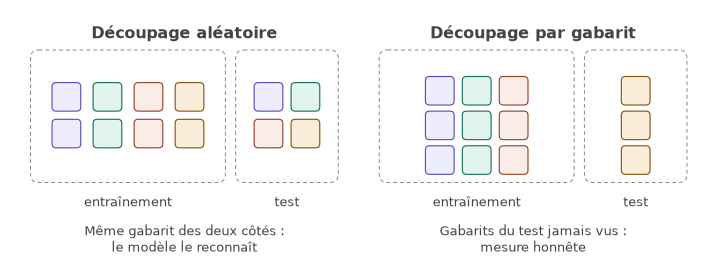

In [2]:
# --- 0.1b Figure : decoupage ---
fig = SF.fig_decoupage(); fig.savefig(FIG_DIR / "00_sota_decoupage.png", dpi=140, bbox_inches="tight"); plt.show()

<!-- SOTA-AUTO -->
**En simple.** C'est comme un élève qui retrouve à l'examen **exactement** les exercices de son cahier, avec d'autres nombres : une bonne note ne prouve pas qu'il a compris le cours.

**Nos chiffres (aperçu, détaillés aux étapes 2 à 5).** Un SVM linéaire atteint **0,9735** de macro-F1 avec un découpage aléatoire (l'article annonce 0,9737 : nous reproduisons son résultat) et **0,458** avec un découpage **par gabarit**, sur les mêmes données. Avec le tirage au sort, 24 % des logs de test ont un quasi-jumeau (similarité cosinus de 0,90 ou plus) dans l'entraînement ; avec le découpage par gabarit, 1 %. Les gabarits ne sont pas fournis : nous les avons **reconstruits** (311 retrouvés sur 440, par regroupement des logs qui partagent leurs mots fixes) et classé les classes en **paliers** selon leur nombre de gabarits : A (5 ou plus, 18 classes), B (3 à 4, 8 classes), C (1 à 2, 4 classes). Une classe à **un seul gabarit** ne peut pas être évaluée honnêtement : tous ses logs vont d'un seul côté, ou bien il faut couper le gabarit et la fuite revient (c'est le cas de `user-session-open`, dont le score de 0,998 ne mesure rien).

**Ce que disent les travaux existants sur les logs.** (a) *Anomalies dans des séquences de logs* : DeepLog (Du et al., CCS 2017 ; référence confirmée), LogBERT (Guo et al., 2021 ; résumé lu), revue de Landauer et al. (2022-2023 ; résumé lu) : ils détectent des **séquences anormales**, et ne classent pas des **types d'événements** dans une taxonomie. (b) *Jeux de logs* : Loghub (Zhu et al., 2020 ; résumé lu), 19 jeux, sans taxonomie d'événements de sécurité. (c) *Classification de logs de sécurité par modèles de langue* : Karlsen et al. (2023 ; résumé lu) affinent 60 modèles et annoncent un F1 moyen de 0,998 sur six jeux ; **le résumé ne décrit pas le découpage** : on ne peut donc **ni affirmer ni exclure** une fuite, il faudrait lire leur méthode. (d) *Revue* : Akhtar et al. (2025 ; résumé lu) sur les modèles de langue pour les logs de sécurité. (e) *Gabarits* : Vaarandi et al. (2024 ; résumé lu) détectent des gabarits d'événements par modèles de langue.

**Autres façons de découper (question de l'étudiant).** Le découpage simple entraînement / validation / test n'est pas le seul :

| Découpage | Principe | Pour nous |
|---|---|---|
| Simple par gabarit | une seule séparation | notre protocole 1 (actuel) |
| Validation croisée à *k* plis | on entraîne sur *k*−1 parts, on teste sur la dernière, *k* fois, puis on moyenne ; estimation plus stable | protocole 2 |
| Validation croisée **par groupes** | un groupe (ici un gabarit) n'est jamais coupé (`GroupKFold`, `StratifiedGroupKFold`) | indispensable ici |
| Validation croisée **imbriquée** | une boucle intérieure règle les paramètres, une boucle extérieure évalue : sans imbrication, le score est optimiste (Cawley et Talbot, 2010) | **protocole 3 (choix de l'étudiant)** |
| Découpage aléatoire | tirage au sort des logs | protocole 0 : **témoin négatif**, il montre la fuite |

*Sources lues :* documentation de scikit-learn (validation croisée, découpages par groupes, validation croisée imbriquée) ; Cawley et Talbot (JMLR 2010, résumé lu) ; Varoquaux (2017, résumé lu : avec peu d'échantillons, l'écart entre plis **sous-estime** l'incertitude réelle, d'où l'ajout du bootstrap par gabarit). **Plan retenu :** comparer les quatre protocoles sur les **modèles linéaires** (TF-IDF, plat et hiérarchique), en travaillant sur l'entraînement et la validation seulement ; le **test scellé** reste intact ; l'encodeur (15 à 19 minutes par rotation) reste sur le découpage simple faute de coût. La question posée à chaque protocole : **nos conclusions tiennent-elles ?** (par exemple « le hiérarchique ne bat pas le plat »). Si elles changent d'un protocole à l'autre, nous le dirons.

<!-- SOTA-AUTO -->
### 0.1b.2 Bloc B : la classification hiérarchique

**Pourquoi une hiérarchie.** Les 30 classes de SIEVE se regroupent en **8 familles** (section 0.10). Trois raisons de s'en servir : (1) **toutes les erreurs ne se valent pas** ; (2) la **famille est plus facile à prédire** que la classe fine (nos chiffres : macro-F1 de 0,67 pour la famille contre 0,46 pour la classe, critère S4) ; (3) en monde ouvert, quand le détail est incertain, on peut encore **répondre au niveau de la famille**.

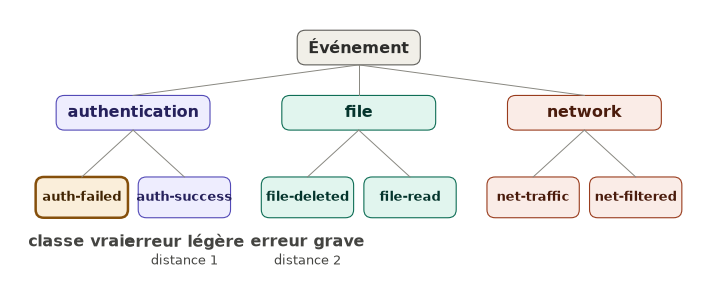

In [3]:
# --- 0.1b Figure : taxonomie erreurs ---
fig = SF.fig_taxonomie_erreurs(); fig.savefig(FIG_DIR / "00_sota_taxonomie_erreurs.png", dpi=140, bbox_inches="tight"); plt.show()

<!-- SOTA-AUTO -->
*Lecture.* Pour un log de classe `authentication-failed`, répondre `authentication-success` est une **erreur légère** (même famille, distance 1 dans l'arbre) ; répondre `file-deleted` est une **erreur grave** (autre famille, distance 2). C'est la distance utilisée dans nos mesures (0 : même classe ; 1 : autre classe de la même famille ; 2 : autre famille). **Nuance importante :** la distance d'arbre n'est qu'un **substitut** de la gravité réelle. Confondre un succès et un échec d'authentification est une erreur « légère » dans l'arbre mais potentiellement très grave en sécurité (un échec pris pour un succès peut cacher une attaque) ; l'article SIEVE signale lui-même ces paires proches. Nous gardons donc aussi une **analyse par paires de classes**.

**Deux grandes façons de construire un classifieur hiérarchique** (Silla et Freitas, *Data Mining and Knowledge Discovery* 22, 2011 ; résumé lu) : les approches **locales** (plusieurs petits classifieurs, un par nœud de l'arbre) et les approches **globales** (un seul modèle qui connaît l'arbre). En texte, des modèles globaux récents modélisent la hiérarchie comme un graphe : **HiAGM** (Zhou et al., ACL 2020) et **HiTIN** (Zhu et al., ACL 2023), tous deux lus au niveau du résumé, en **monde fermé**. Bertinetto et al. (CVPR 2020, « Making Better Mistakes », résumé lu) modifient la perte d'entraînement pour que les erreurs restent **légères** ; Kosmopoulos et al. (2013, résumé lu) proposent des mesures d'évaluation hiérarchiques.

**Notre construction (approche locale).** Une tête **famille**, puis une tête **classe fine** à l'intérieur de la famille ; la probabilité d'une classe est le **produit** des deux niveaux :

$$p(\text{classe})=p(\text{famille})\times p(\text{classe}\mid\text{famille})$$

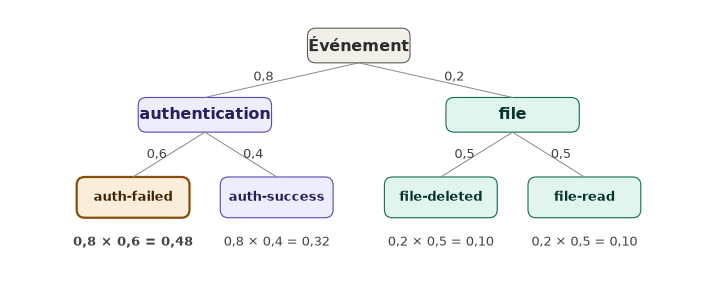

In [4]:
# --- 0.1b Figure : produit probas ---
fig = SF.fig_produit_probas(); fig.savefig(FIG_DIR / "00_sota_produit_probas.png", dpi=140, bbox_inches="tight"); plt.show()

<!-- SOTA-AUTO -->
*Lecture.* Ici `auth-failed` obtient 0,8 × 0,6 = **0,48** ; les quatre produits font 1. **Avantage :** la classe prédite appartient **toujours** à la famille prédite (cohérence). **Faiblesse :** si la famille est fausse, la bonne classe est hors de portée (l'erreur se **propage**) ; c'est une des raisons pour lesquelles le gain de la hiérarchie n'est pas démontré chez nous (hypothèse H1).

**La hiérarchie en monde ouvert.** Avec une hiérarchie, « inconnu » n'est plus une seule réponse : un log peut être une **classe nouvelle dans une famille connue**, ou une **famille nouvelle**. En vision, Linderman et al. (2022, résumé lu) proposent de **prédire à un niveau plus grossier** quand l'entrée est ambiguë, au lieu de simplement signaler « inconnu » ; Hannum et al. (2024) construisent l'arbre dans l'espace d'embedding ; ProTeCt (Wu et al., CVPR 2024) impose la **cohérence hiérarchique** ; Wallin et al. (2026) placent les classes nouvelles sous le groupe le plus adapté. Pour le **texte**, Kwon et al. (Findings EACL 2023, résumé lu) écrivent que gérer des étiquettes inconnues **en tenant compte de la hiérarchie** est « un problème encore ouvert ».

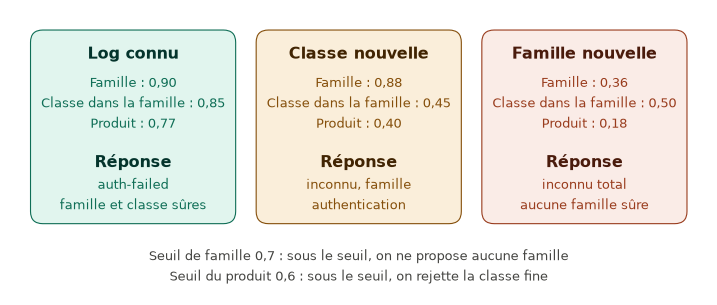

In [5]:
# --- 0.1b Figure : trois cas ---
fig = SF.fig_trois_cas(); fig.savefig(FIG_DIR / "00_sota_trois_cas.png", dpi=140, bbox_inches="tight"); plt.show()

<!-- SOTA-AUTO -->
*Lecture (probabilités inventées pour illustrer).* Un log connu reçoit sa classe ; une **classe nouvelle dans une famille connue** reçoit « inconnu, famille *authentication* » ; une **famille nouvelle** reçoit « inconnu total ». Utilité pour l'analyste : au lieu de 30 classes possibles, il n'en a que quelques-unes à examiner, et il sait quelle procédure ouvrir. **Risque** : un seuil de famille trop bas proposerait une famille même pour une famille nouvelle, une indication **fausse donnée avec confiance** ; ce seuil se règle donc, lui aussi, sur la validation des classes connues. Le document du projet demande exactement cela à son étape 6 (« si possible, la famille la plus plausible »). **Ajout prévu** : une métrique « la famille proposée est-elle la bonne ? » pour les inconnus rejetés dont la famille est connue.

<!-- SOTA-AUTO -->
### 0.1b.3 Bloc C : la détection d'inconnus (le cœur du projet)

**Le problème du monde ouvert.** Un classifieur standard produit une probabilité par classe connue, et ces probabilités font toujours 1 : **il n'a pas de case « inconnu »**. Face à un log jamais vu, il le range donc de force dans une classe connue, sans que l'on s'en aperçoive ; dans un SIEM, une attaque peut ainsi passer sous le radar. Notre expérience simule ce cas en **masquant 6 classes sur 30** à l'entraînement (cinq rotations) et en regardant si le modèle sait dire « inconnu ».

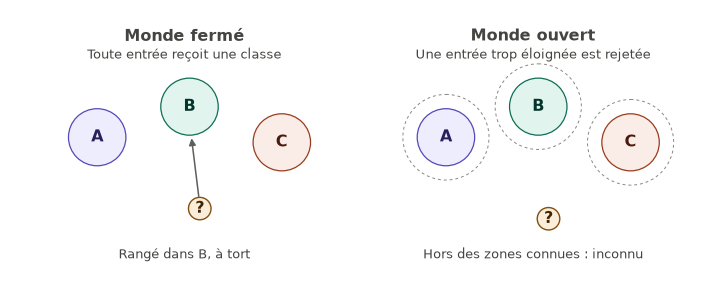

In [6]:
# --- 0.1b Figure : monde ferme ouvert ---
fig = SF.fig_monde_ferme_ouvert(); fig.savefig(FIG_DIR / "00_sota_monde_ferme_ouvert.png", dpi=140, bbox_inches="tight"); plt.show()

<!-- SOTA-AUTO -->
**Le score le plus simple : la probabilité maximale (MSP).** Hendrycks et Gimpel (2017) ont montré que cette confiance sert de base de comparaison. Avec les scores bruts $z_i$ du classifieur (un par classe) :

$$p_i=\frac{e^{z_i}}{\sum_j e^{z_j}},\qquad \text{MSP}=\max_i p_i$$

On **rejette** si le MSP est sous un **seuil**, réglé sur la validation de classes **connues** seulement (jamais en regardant les inconnues).

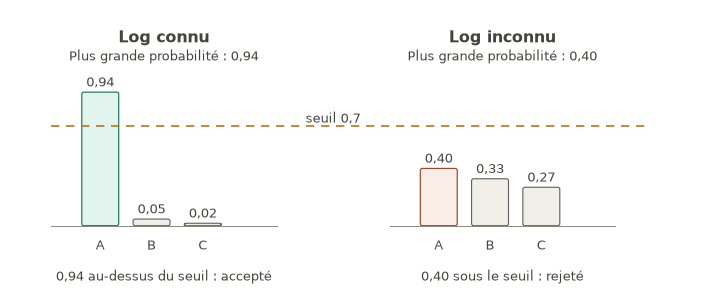

In [7]:
# --- 0.1b Figure : msp seuil ---
fig = SF.fig_msp_seuil(); fig.savefig(FIG_DIR / "00_sota_msp_seuil.png", dpi=140, bbox_inches="tight"); plt.show()

<!-- SOTA-AUTO -->
*Lecture.* Scores (4 ; 1 ; 0) : MSP de 0,94, au-dessus du seuil de 0,7, donc accepté. Scores (1,2 ; 1,0 ; 0,8) : MSP de 0,40, rejeté. **Le seuil est un compromis** : à 0,3, le log inconnu (0,40) est accepté, une erreur non détectée ; à 0,99, même le log connu (0,94) est rejeté, une fausse alerte. Pour un analyste, trop de fausses alertes finit par les faire ignorer toutes ; trop peu les laisse passer des attaques. Chez nous, le seuil visant 5 % de connus rejetés en rejetait 9 à 13 % au test, et laissait passer 80 à 89 % des inconnus.

**Les familles de méthodes (travaux lus).**

| Famille | Méthode (référence) | Idée, d'après le résumé | Exige |
|---|---|---|---|
| **Sortie du modèle** | MSP (Hendrycks et Gimpel, 2017) | confiance softmax maximale | rien de plus |
| | Énergie (Liu et al., 2020) | score d'énergie calculé à partir des scores bruts, jugé moins sur-confiant que le softmax | scores bruts |
| | ODIN (Liang et al., 2017/2018) | température et petites **perturbations de l'entrée** pour écarter les scores des connus et des inconnus | gradients de l'entrée |
| | OpenMax (Bendale et Boult, 2015/2016) | remplace le softmax : estime, avec les activations de l'avant-dernière couche et une méta-reconnaissance, la probabilité d'une classe inconnue | activations, données d'entraînement |
| **Distance dans l'espace interne** | Prototypes (Yang et al., 2018) | classer par similarité à des prototypes appris | entraînement spécifique |
| | Mahalanobis (Lee et al., 2018) | gaussiennes par classe sur les features ; distance de Mahalanobis | features |
| | kNN profond (Sun et al., 2022) | distance aux plus proches voisins, sans supposer de forme de distribution | features, données d'entraînement |
| | ViM (Wang et al., 2022) | combine un score d'espace de features et les scores bruts | features + scores |
| | ReAct (Sun et al., 2021) | tronque les activations anormales de l'avant-dernière couche | réseau profond |
| **Incertitude** | Ensembles (Lakshminarayanan et al., 2017) | plusieurs modèles indépendants | *N* entraînements |
| | MC dropout (Gal et Ghahramani, 2015/2016) | dropout actif à l'inférence | modèle avec dropout |
| **Entraînement spécial** | Outlier Exposure (Hendrycks et al., 2018/2019) | apprendre avec un jeu d'exemples « autres » | jeu d'outliers |
| | Perte contrastive (Zhou et al., 2021), frontière adaptative (Zhang et al., 2020/2021) | resserrer les classes, frontière sphérique par classe | ré-entraînement |

**Trois méthodes expliquées : OpenMax, Mahalanobis, kNN.** Dans les trois cas, on mesure à quel point le log est **loin de ce que le modèle connaît**, mais pas de la même façon.

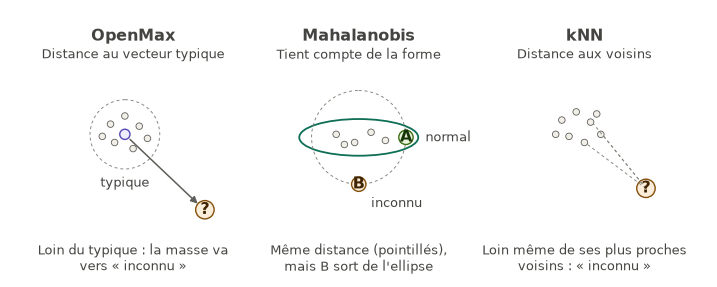

In [8]:
# --- 0.1b Figure : trois methodes ---
fig = SF.fig_trois_methodes(); fig.savefig(FIG_DIR / "00_sota_trois_methodes.png", dpi=140, bbox_inches="tight"); plt.show()

<!-- SOTA-AUTO -->
- **OpenMax.** Pour chaque classe, on garde son vecteur d'activations « typique » (moyenne sur les exemples bien classés). Plus un log est loin de ce vecteur, plus on retire de confiance à cette classe et on en donne à une classe « inconnu ». *Le détail de l'estimation (loi de Weibull sur les distances) sera relu dans l'article avant l'implémentation (étape 6) : ici, seul le principe du résumé est affirmé.* OpenMax a déjà été utilisée en **sécurité** (VAEMax, Qiu et al., 2024 ; intrusion réseau) ; c'est la baseline citée par le document du projet et **il nous manquait de l'avoir testée**.
- **Mahalanobis.** Même idée, mais la distance tient compte de la **forme** du nuage de chaque classe, en supposant une ellipse (loi gaussienne) :

$$d_M(x)=\min_c\sqrt{(x-\mu_c)^{\top}\Sigma^{-1}(x-\mu_c)}$$

  *En simple :* c'est la distance mesurée **en écarts-types, direction par direction**. Si un nuage s'étale avec un écart-type de 3 à l'horizontale et de 0,5 à la verticale, un log à une distance de 3 est à 1 écart-type s'il est à l'horizontale (ordinaire) et à 6 écarts-types s'il est à la verticale (très surprenant). Sur la figure, A et B sont à la même distance du centre, mais B sort de l'ellipse. Podolskiy et al. (2021) et Zhou et al. (2021) la trouvent très efficace sur des Transformers affinés, parce que ces modèles resserrent les classes.
- **kNN.** On ne suppose **aucune forme** : on regarde la distance du log à ses plus proches voisins parmi les exemples connus. Si même ses voisins les plus proches sont loin, c'est un inconnu. Elle tient donc compte de la forme **sans la supposer**.

**Où chaque méthode lit l'information.** Chaque méthode lit soit les **scores** du classifieur, soit un **vecteur** qui représente le log.

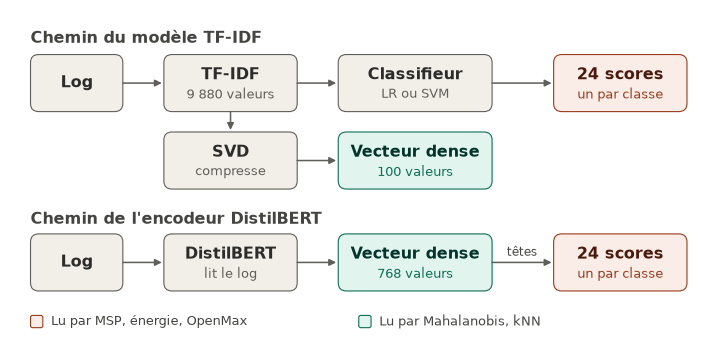

In [9]:
# --- 0.1b Figure : ou lire ---
fig = SF.fig_ou_lire(); fig.savefig(FIG_DIR / "00_sota_ou_lire.png", dpi=140, bbox_inches="tight"); plt.show()

<!-- SOTA-AUTO -->
*Lecture.* Pour le **TF-IDF**, un log devient un vecteur de 9 880 valeurs (dont environ 15 sont non nulles), le classifieur en tire 24 scores (un par classe connue d'une rotation : 30 moins 6) ; pour Mahalanobis et kNN il faut un vecteur **dense** plus petit, obtenu par une **SVD** qui compresse en environ 100 « thèmes » (nombre à **justifier**, sans jamais regarder les classes masquées : par la variance expliquée ou l'exactitude fermée sur 50, 100, 200, 300). Les vecteurs Skip-gram de 100 valeurs sont déjà denses. Pour l'**encodeur**, DistilBERT résume le log en un vecteur de 768 valeurs, que deux « têtes » transforment en scores : on a un vecteur naturel. *Contrainte pratique :* nous n'avons sauvegardé que les scores de l'encodeur ; il faudra extraire les vecteurs avec les modèles enregistrés (environ 2 minutes par rotation sur le Mac).

**Pourquoi un vecteur plutôt que les scores.** Les scores sont un résumé que le classifieur a appris à rendre **tranché** : un log inconnu peut obtenir un score très haut (chez nous, `user-creation` masquée est rangée à 100 % en `user-deletion`). Le vecteur garde plus d'information : un inconnu y est souvent loin de **tous** les nuages même quand le score est trompeur.

**Ce que dit la littérature sur le texte (NLP).** Hendrycks et al. (2020) : les Transformers préentraînés perdent moins en exactitude sous décalage et détectent mieux l'hors-distribution que les sacs de mots, les ConvNets et les LSTM. Arora et al. (2021) : on distingue le décalage de **fond** et le décalage **sémantique** ; l'estimation de densité bat la calibration sur le premier, pas sur le second. Baran et al. (2023) : huit méthodes classiques adaptables sans données supplémentaires **ratent beaucoup de décalages**. Vaze et al. (2021/2022) : **un bon classifieur fermé suffit presque** : la capacité à rejeter est très corrélée à l'exactitude en fermé. Surveys : Geng et al. (reconnaissance en monde ouvert), Yang et al. (2021), Lang et al. (2023, centré NLP), Costache et al. (2025, classification de texte en monde ouvert) ; benchmark : OpenOOD (Yang et al., 2022 ; v1.5, 2023). Pour le texte en monde ouvert, voir aussi DOC (Shu et al., 2017 ; résumé lu, mécanisme à lire) et Erlygin et al. (2026).

**Pourquoi nous écartons certaines méthodes** (raisonnement fondé sur ce que les résumés disent qu'elles exigent) : **ODIN** perturbe l'entrée, ce qui n'a pas de sens pour un texte discret et pour un TF-IDF ; sa partie « température » est approchée par l'énergie et par la mise à l'échelle de l'étape 9. **ReAct** concerne les réseaux profonds et se justifie surtout sur de grands réseaux de vision. **ViM** est proche de Mahalanobis (piste pour l'encodeur). **Outlier Exposure** exige un jeu d'exemples « autres » : n'en ayant pas d'honnête, l'utiliser avec nos classes masquées serait **tricher**. Les **pertes contrastive et frontière adaptative** demandent de ré-entraîner l'encodeur (coût GPU) : Mahalanobis simple en est la première étape ; elles restent des pistes.

<!-- SOTA-AUTO -->
### 0.1b.4 Bloc D : la robustesse du texte

**Qui attaque, et comment.** Dans un SIEM, une partie du contenu d'un log peut être contrôlée par un attaquant (nom d'utilisateur, adresse web, nom de fichier) : il cherche à faire **mal classer** son événement, ou à le faire passer pour normal, pour **échapper à l'alerte**. C'est le jeu des spammeurs contre les filtres anti-spam. Dalvi et al. (KDD 2004 ; **texte intégral lu**) décrivent des spammeurs qui insèrent des mots « non-spam » et cassent les mots par de la ponctuation. Lowd et Meek (CEAS 2005 ; **texte lu**) étudient les « *good word attacks* » : en attaque passive (sans retour du filtre), **50 % du spam bloqué passe avec 150 mots ajoutés ou moins** ; en attaque active (requêtes test), 30 mots suffisent ; le texte précise que des mots tirés **au hasard** dans un dictionnaire sont **inefficaces**, alors que des mots **fréquents** marchent bien mieux. Boucher et al. (IEEE S&P 2021, « Bad Characters » ; résumé lu) montrent qu'un seul changement **invisible** (caractère caché, homoglyphe, réordonnancement) dégrade un modèle et que trois peuvent casser la plupart des modèles, y compris des systèmes commerciaux ; la défense recommandée est d'**assainir l'entrée**.

**Nos trois attaques**, illustrées sur le même log :

| Attaque | Log après attaque | Ce qui change pour le modèle |
|---|---|---|
| aucune | `Failed password for root` | |
| fautes de frappe | `Faild pasword for root` | des mots mal écrits |
| homoglyphes | `Fаiled password for root` | le « а » est la lettre **cyrillique** U+0430, pas le « a » latin U+0061 |
| remplissage | `Failed password for root meeting notes lunch report` | du texte inoffensif est ajouté |

*En simple.* L'homoglyphe est le plus sournois : un humain ne voit **aucune différence**, mais pour la machine le mot est devenu **un autre mot**, absent du vocabulaire : il est ignoré, le log perd un de ses indices les plus parlants, et le modèle peut changer de classe ou hésiter et **rejeter à tort** un log légitime (chez nous, avec des homoglyphes forts, les connus rejetés à tort passent de 13 % à 22,5 %). La normalisation Unicode standard (NFKC) **ne corrige pas** cette attaque (vérifié) : le « а » cyrillique n'est pas une variante de compatibilité.

**Trois défenses.**

*1. La normalisation (garde-fou principal).* Avant de classer, on remplace chaque lettre « déguisée » par sa lettre normale. **La bonne référence** est la norme Unicode UTS #39 (*Security Mechanisms*, version 18.0.0 lue) et son fichier de **caractères confondables** : chaque caractère est associé à un « prototype » ; deux chaînes dont les « squelettes » coïncident sont confondables. **Précaution de la norme :** les squelettes servent à une **comparaison interne**, pas à l'affichage ni comme normalisation destinée à l'utilisateur. **Notre usage s'y conforme :** une canonicalisation **interne**, appliquée au texte juste avant le classifieur, jamais montrée à l'analyste. **Données :** le fichier `confusables.txt` officiel (763 128 octets, daté du 2026-08-06, copié dans `etat_de_l_art/unicode_confusables/`) contient 6 712 entrées dont **1 447 caractères non ASCII qui ressemblent à une lettre ASCII** (50 lettres ; 4 sources ASCII comme `I`→`l` ou `0`→`O` sont écartées, car les appliquer abîmerait du texte normal) ; NFKC en corrige **719** avec la base Unicode 15.0 du Python du notebook (lettres mathématiques, pleine largeur, variantes de compatibilité), il en **reste 728** (cyrillique, grec, cherokee, lisu, etc.) ; avec la base Unicode 16.0 d'un Python plus récent, un peu plus : le nombre dépend de la version de la base. **Défaut trouvé dans notre première version :** notre table de défense (18 lettres cyrilliques) est **exactement l'inverse** de la table utilisée par l'attaque, donc le résultat « la normalisation annule exactement l'attaque » (étape 9) est **tautologique** : un attaquant a plus de 700 façons de la contourner (728 avec la base Unicode du notebook), elle n'en connaît que 18 (environ 1 %).

*Test honnête de la défense (protocole retenu).* On ne peut pas tester « toutes les façons possibles », mais on teste **systématiquement** : (i) la défense est construite avec **une moitié** des caractères que NFKC ne corrige pas et l'attaque utilise **l'autre moitié** (généralisation à des homoglyphes inconnus de la défense) ; (ii) une **attaque adaptative** : l'attaquant, qui connaît la défense, choisit exprès des caractères qu'elle ne couvre pas ; (iii) on rapporte le **pire cas** et non la moyenne.

*2. L'entraînement adversarial.* On montre au modèle, à l'entraînement, des logs **déjà attaqués** avec leur bonne classe (analogie du vaccin). Goodfellow et al. (2014 ; V9) ont montré qu'il réduit l'erreur ; FreeLB (Zhu et al., 2019 ; résumé lu) ajoute du bruit adversarial sur les vecteurs de mots ; TextAttack (Morris et al., 2020 ; résumé lu) fournit les outils. Nos mesures (aperçu, étape 9) : la baisse relative au test, TF-IDF de mots.

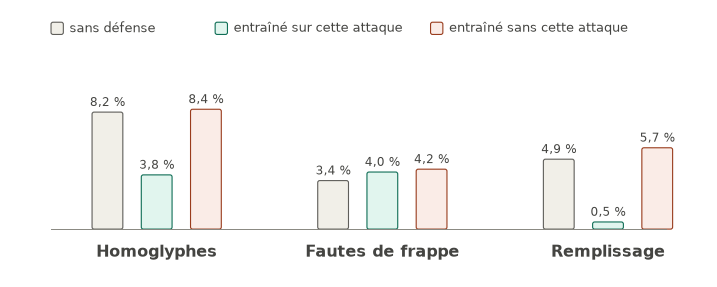

In [10]:
# --- 0.1b Figure : adversarial ---
fig = SF.fig_adversarial(); fig.savefig(FIG_DIR / "00_sota_adversarial.png", dpi=140, bbox_inches="tight"); plt.show()

<!-- SOTA-AUTO -->
*Lecture.* Le vaccin protège contre l'attaque **vue** (remplissage : 4,9 % → 0,5 %) mais pas contre une attaque **nouvelle** : la baisse remonte au niveau sans défense, voire au-dessus (8,4 % et 5,7 %). Le modèle apprend le **motif précis** vu à l'entraînement ; un motif nouveau est un problème nouveau (résultat constaté à l'étape 9 ; ce n'est pas une hypothèse numérotée écrite à l'avance).

*3. Les n-grammes de caractères.* Au lieu de mots entiers, on découpe le log en petits morceaux de lettres.

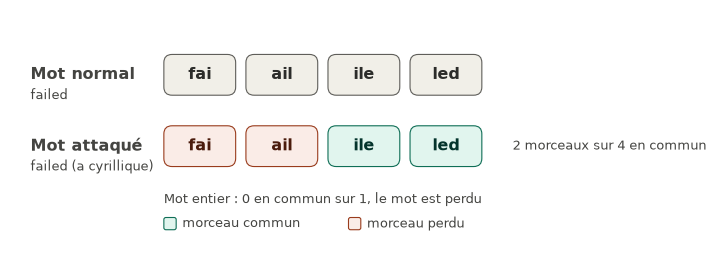

In [11]:
# --- 0.1b Figure : ngrammes ---
fig = SF.fig_ngrammes(); fig.savefig(FIG_DIR / "00_sota_ngrammes.png", dpi=140, bbox_inches="tight"); plt.show()

<!-- SOTA-AUTO -->
*Lecture.* Avec des morceaux de trois lettres, `failed` et `fаiled` partagent 2 morceaux sur 4 : une partie du signal survit (alors que le mot entier est perdu). Chez nous, les n-grammes de caractères perdent moins que les mots aux homoglyphes forts (10,6 % contre 21,5 %) mais **pas** au remplissage fort (14,4 % contre 12,5 %) : le remplissage ne modifie pas les mots, il **ajoute** du contenu et **noie** le signal. Un log est représenté par un vecteur de longueur 1 : avec 5 indices de poids 1/√5 ≈ 0,45, ajouter 5 mots ramène chacun à 1/√10 ≈ 0,32, soit **29 % de moins** ; les n-grammes de caractères aggravent cela (environ 342 valeurs non nulles par log contre 15 pour les mots). Coût : environ 12 fois plus lents et 5 fois plus gros.

**Défense en profondeur.** On combine : la normalisation en garde-fou principal, l'entraînement adversarial en renfort **sur les attaques que la normalisation laisse passer** (s'entraîner sur des homoglyphes déjà corrigés n'apprend rien), les n-grammes de caractères pour la tolérance aux altérations. On rapporte le **pire cas**. **Autres pistes de la littérature (non réalisées, citées comme travaux futurs)** : un étage de reconnaissance de mots avant le classifieur (Pruthi et al., ACL 2019 ; résumé lu) et les encodages robustes (Jones et al., ACL 2020 ; résumé lu). **Réalisme des attaques** : Morris et al. (2020, résumé lu) montrent qu'un exemple adversarial doit tromper le modèle **et** respecter des règles linguistiques (avec des seuils plus stricts, le succès des attaques par synonymes chute de plus de 70 points) ; AdvGLUE (Wang et al., 2021, résumé lu) : tous les modèles testés chutent fortement. Les attaques par synonymes (TextFooler, BERT-Attack) et par gradient (HotFlip) sont **hors périmètre** (coût, entrée discrète).

<!-- SOTA-AUTO -->
### 0.1b.5 Bloc E : la calibration

**Concept.** Un modèle est **calibré** si, parmi les logs où il se dit sûr à 90 %, il a raison 9 fois sur 10. On le vérifie par un **diagramme de fiabilité** : on regroupe les logs par confiance annoncée, et l'on trace la proportion de bonnes réponses ; un modèle parfait suit la diagonale. L'écart moyen se résume par l'**ECE** (*expected calibration error*) : $\text{ECE}=\sum_b \frac{n_b}{n}\,\lvert\text{exactitude}_b-\text{confiance}_b\rvert$.

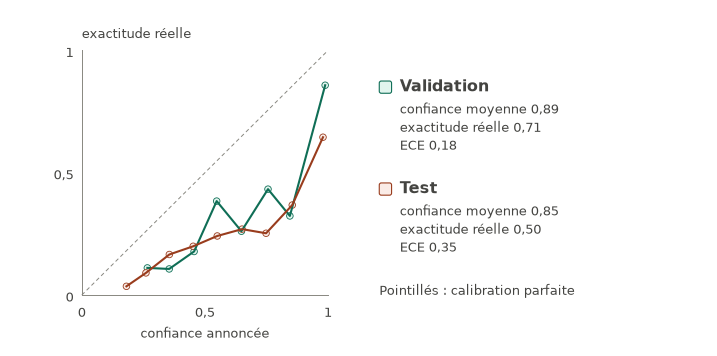

In [12]:
# --- 0.1b Figure : fiabilite ---
rel = SF.reliability_from_files(ROOT / "colab", ROOT / "colab" / "encoder_data_v2.csv.gz"); fig = SF.fig_fiabilite(rel)
fig.savefig(FIG_DIR / "00_sota_fiabilite.png", dpi=140, bbox_inches="tight"); plt.show()

<!-- SOTA-AUTO -->
*Lecture (calcul réel sur notre encodeur, 5 rotations regroupées, 95 760 logs de classes connues ; voir 6.10 et 7.8).* Les deux courbes sont **sous la diagonale** : le modèle est **sur-confiant**. En validation il se dit sûr à 89 % en moyenne et a raison 71 % du temps (ECE 0,18) ; au test, sur des gabarits jamais vus, 85 % annoncés pour 50 % réels (ECE 0,35). Quand il annonce 98 %, il a raison 65 % du temps au test. Un analyste peut alors **perdre confiance** et tout revérifier, ou, pire, **faire confiance** et laisser passer les erreurs.

**La correction simple : la mise à l'échelle par température** (Guo et al., 2017 ; résumé lu). On divise les scores bruts par un nombre $T$ avant le softmax :

$$p_i(T)=\frac{e^{z_i/T}}{\sum_j e^{z_j/T}}$$

Avec les scores (4 ; 1 ; 0) : à $T=1$, probabilités 0,94 · 0,05 · 0,02 ; à $T=2$, 0,74 · 0,16 · 0,10. On cherche $T$ sur la **validation** (un seul nombre à régler). La température **change beaucoup les probabilités** mais divise **tous** les scores par le même nombre : l'ordre des scores, donc la **classe prédite**, ne change jamais. Elle ne règle pas non plus la détection d'inconnus : l'ordre **entre logs connus et inconnus** reste le même (un inconnu de scores (4,2 ; 1 ; 0) passe de 0,947 à 0,755 et paraît toujours plus sûr qu'un connu de scores (4 ; 1 ; 0), de 0,936 à 0,736). La température corrige l'**honnêteté** des probabilités, pas le **classement** que mesure l'AUROC.

**Ce que dit la littérature.** Guo et al. (2017) : la température corrige en général très bien. Desai et Durrett (2020 ; résumé lu) : BERT et RoBERTa sont bien calibrés en domaine et moins mal calibrés hors domaine que les modèles de base ; la température aide en domaine, le lissage d'étiquettes hors domaine. Ovadia et al. (2019 ; résumé lu) : **sous décalage de données, la calibration a posteriori se dégrade**, et les méthodes qui moyennent plusieurs modèles tiennent mieux. **Nos résultats :** TF-IDF, $T=1{,}62$ fait passer l'ECE de 0,150 à 0,095 sans effet sur l'AUROC (0,603) ; encodeur : ECE de 0,18 en validation à 0,35 au test, le cas décrit par Ovadia.

<!-- SOTA-AUTO -->
### 0.1b.6 Synthèse, positionnement et décisions

**La lacune que le TP revendique (formulée prudemment).** D'après le protocole de recherche ci-dessus : (1) la **classification hiérarchique en monde ouvert** existe surtout en **vision** (Linderman 2022, Hannum 2024, ProTeCt 2024, Wallin 2026) ; pour le **texte**, la hiérarchie est traitée en monde fermé (HiAGM, HiTIN) et Kwon et al. (2023) la disent « encore ouverte » avec des étiquettes inconnues ; (2) les travaux sur les **logs** portent sur l'**anomalie** ou la classification **fermée** (DeepLog, LogBERT, Karlsen 2023) ; (3) en **intrusion**, le monde ouvert existe (Souza et al., énergie ; VAEMax, OpenMax) mais sur des **flux réseau**, pas sur des types d'événements de journaux ; (4) l'API Semantic Scholar donne **6 travaux** qui citent SIEVE (2025-2026) : revue SIEM-SOAR, audit de conformité cloud, bancs d'essai de cybersécurité, sécurité de centres de données loués, priorisation d'alertes, évaluation de systèmes de détection d'intrusion APT ; **aucun** ne traite de hiérarchie ni de monde ouvert. Requêtes rejouables : *hierarchical open-set text classification unknown classes taxonomy* ; *open-world OR open-set classification of security log events SIEM unknown event types* ; *novel log type detection OR unseen log event classification open-set log parsing* ; *citations de* SIEVE *(DOI 10.1016/j.comnet.2025.111330)*. **Ce que nous revendiquons :** une **évaluation par gabarit** (sans fuite) de la classification hiérarchique en monde ouvert sur des logs SIEM, avec une **comparaison systématique de méthodes** ; **ce que nous ne revendiquons pas :** une méthode meilleure que toutes les autres (nos premiers résultats montrent qu'aucun score d'inconnu ne bat clairement le MSP).

**Positionnement : ce que chaque méthode apporte et si elle répond à notre besoin.**

| Choix | Méthode (référence) | Apport | Répond à notre besoin ? | Statut dans le TP |
|---|---|---|---|---|
| Score d'inconnu | MSP (Hendrycks et Gimpel 2017) | baseline simple | oui comme baseline ; confiance trompeuse | testée (étape 6) |
| | Énergie (Liu 2020) | scores bruts | proche du MSP | testée |
| | Prototype (Yang 2018) | distance à des prototypes | partiel | testée |
| | Ensemble, MC dropout (Lakshminarayanan 2017 ; Gal 2016) | incertitude | coûteux | testés |
| | **OpenMax** (Bendale 2016) | activations + méta-reconnaissance ; baseline du projet ; précédent en intrusion | **oui** | **à ajouter** |
| | **Mahalanobis** (Lee 2018 ; Podolskiy 2021) | forme du nuage ; très efficace en texte avec Transformer affiné | **oui** | **à ajouter** |
| | **kNN** (Sun 2022) | sans hypothèse de forme | **oui** | **à ajouter** |
| | ODIN, ReAct, ViM, Outlier Exposure | exigent perturbation d'entrée, réseau profond, features profondes, jeu d'outliers | non (voir 0.1b.3) | écartées, citées |
| Tête | Plat | baseline | oui | testé |
| | Hiérarchique local (Silla et Freitas 2011) | cohérence, erreurs légères | oui | testé |
| | Hiérarchique global (HiAGM, HiTIN) | graphe de labels, monde fermé | non (fermé, coût) | écarté, cité |
| | **Hiérarchique + repli sur la famille** (Linderman 2022) | réponse utile quand on rejette | **oui** | **à ajouter** (métrique « famille proposée ») |
| Défense | Normalisation (Boucher 2021 ; UTS #39) | cause supprimée | oui, mais **à corriger** | testée, **à refaire avec la table officielle** |
| | Entraînement adversarial (FreeLB, TextAttack) | vaccin | partiel (attaque vue seulement) | testé |
| | N-grammes de caractères | tolérance aux altérations | partiel | testés |
| Calibration | Température (Guo 2017) | probabilités honnêtes | partiel (se dégrade sous décalage) | testée sur TF-IDF, **à ajouter sur l'encodeur** |
| Découpage | aléatoire / simple / *k* plis par groupes / imbriquée par groupes | robustesse de l'évaluation | oui | **à ajouter** (plis, imbriquée) |

**Chaque choix est comparé à au moins deux alternatives** (c'est l'exigence de l'étudiant) : représentations (mots, caractères, Skip-gram, encodeur ; étapes 5 à 7) ; tête (plat, hiérarchique, hiérarchique avec repli) ; score d'inconnu (huit scores : MSP, énergie, prototype, ensemble, MC dropout, OpenMax, Mahalanobis, kNN) ; défense (normalisation avec table maison puis officielle, entraînement adversarial, n-grammes de caractères, combinaison) ; calibration (aucune, température, ensemble) ; découpage (quatre protocoles). **Règle de décision écrite avant les chiffres :** une méthode n'est retenue que si elle dépasse la référence avec un intervalle de confiance (par gabarit) qui exclut 0 **et** un écart au moins égal au seuil pratique fixé à l'étape 2 (critères de succès, section 0.3) ; sinon on le dit : **« pas de différence mesurable »** est un résultat.

**Hypothèses issues de la littérature (elles prolongent H1 à H6 de la section 0.2).** *Réserve d'honnêteté :* H7 à H11 ont été écrites **avant les calculs nouveaux** qui les testent (corrélation de Vaze, Mahalanobis, kNN, OpenMax, température sur l'encodeur), mais **pas avant tous les résultats** : H9 a été formulée en connaissant déjà les AUROC par classe masquée, et H11 en connaissant déjà l'ECE de l'encodeur (0,18 en validation, 0,35 au test). Elles sont donc **moins strictes** que H1 à H6, écrites avant toute expérience.

| N° | Hypothèse | Source | Ce qui la réfuterait |
|---|---|---|---|
| **H7** | La qualité de détection est corrélée à la qualité en fermé (corrélation de rang entre macro-F1 fermé et AUROC, sur les rotations et les modèles) | Vaze et al. 2022 | corrélation proche de 0 ou négative |
| **H8** | Sur l'encodeur affiné, Mahalanobis détecte mieux que le MSP | Podolskiy 2021 ; Zhou 2021 | AUROC de Mahalanobis non supérieur au MSP (écart < 0,01 ou IC contenant 0) |
| **H9** | Les scores de sortie (MSP, énergie) détectent mal les inconnus sémantiquement proches : l'AUROC est plus bas pour les classes masquées dont la famille reste connue | Baran 2023 ; Arora 2021 | AUROC non plus bas pour ces classes |
| **H10** | kNN contre Mahalanobis : **exploratoire**, pas de prédiction ferme | Sun 2022 | — |
| **H11** | Une température calée sur la validation réduit l'ECE en validation mais **pas** (ou peu) au test | Ovadia 2019 | ECE au test réduit de façon comparable |

**Corrections et ajouts à reporter dans les étapes (liste de travail).** (1) Étapes 8-9 : refaire la normalisation avec la table officielle UTS #39 et le **test honnête** (moitiés de table, attaque adaptative, pire cas) ; (2) étape 6 : ajouter OpenMax, Mahalanobis, kNN (relire l'article d'OpenMax avant), extraire les vecteurs de l'encodeur, justifier la dimension de la SVD sans regarder les classes masquées ; (3) étape 6-7 : repli sur la famille et métrique « famille proposée » ; (4) étape 9 : température sur les scores de l'encodeur ; (5) étapes 3-4 et 6-7 : validation croisée par groupes et imbriquée sur les modèles linéaires ; (6) étape 10 : reprendre le positionnement et les limites. **Limites de cet état de l'art :** recherche non exhaustive dans l'absolu ; plusieurs sources lues au niveau du résumé seulement ; le mécanisme exact d'OpenMax et de DOC reste à relire dans le texte ; beaucoup de travaux sont en vision, leur transfert au texte est une hypothèse.

**Registre de vérification (suite).**

| N° | Affirmation | Source | Niveau |
|---|---|---|---|
| V74 | UTS #39 (v18.0.0) : `confusables.txt` du 2026-08-06 (763 128 octets) : 6 712 entrées, 1 447 caractères non ASCII ressemblant à une lettre ASCII (50 lettres ; 4 sources ASCII écartées) ; NFKC en corrige 719, il en reste 728 (base Unicode 15.0 de Python 3.12 ; un peu plus de corrigés avec la base 16.0) ; la norme précise que les squelettes servent à la comparaison interne, pas à l'affichage | page UTS #39 lue ; calcul sur le fichier | calcul + page lue |
| V75 | Notre table d'homoglyphes de défense (18 lettres cyrilliques, toutes présentes dans la table officielle) est l'inverse exact de la table de l'attaque : les résultats V57 et V73 (« annule exactement l'attaque ») sont tautologiques ; correction prévue | lecture de `src/tp2_attacks.py` ; calcul | observation |
| V76 | Aucun travail trouvé combinant hiérarchie, monde ouvert et logs SIEM ; 6 travaux citent SIEVE (Semantic Scholar, 2026-11-05), aucun sur ce sujet ; Kwon et al. 2023 : texte hiérarchique avec étiquettes inconnues « encore ouvert » | protocole de recherche ci-dessus | recherche (non exhaustive) |
| V77 | Lowd et Meek 2005 : attaque passive, 50 % du spam bloqué passe avec 150 mots ou moins ; active, 30 mots ; mots au hasard inefficaces, mots fréquents efficaces | texte du papier lu | texte lu |
| V78 | Diagramme de fiabilité de l'encodeur : confiance 0,89 et exactitude 0,71 en validation (ECE 0,18) ; 0,85 et 0,50 au test (ECE 0,35) ; confiance 98 % pour 65 % d'exactitude au test | calcul sur `colab/out_v2*/` | calcul |

**Bibliographie vérifiée.** Chaque ligne indique le niveau de vérification (*texte intégral lu*, *résumé lu*, ou *référence confirmée seulement*) et l'adresse ouverte le 2026-11-05.

<!-- SOTA-AUTO -->
**73 références** : 69 au niveau du résumé ou de la page, 3 avec une lecture du texte (au moins partielle), 1 confirmée seulement.

| N° | Référence | Sujet | Niveau | Adresse |
|---|---|---|---|---|
| E1 | Bendale et Boult, « Towards Open Set Deep Networks » (2015/2016) | OpenMax | résumé lu | https://arxiv.org/abs/1511.06233 |
| E2 | Hendrycks et Gimpel (2017) | MSP, base de comparaison | résumé lu | https://arxiv.org/abs/1610.02136 |
| E3 | Liang et al., ODIN (2017/2018) | température et perturbations de l'entrée | résumé lu | https://arxiv.org/abs/1706.02690 |
| E4 | Lee et al. (2018) | distance de Mahalanobis | résumé lu | https://arxiv.org/abs/1807.03888 |
| E5 | Liu et al., « Energy-based OOD detection » (2020) | score d'énergie | résumé lu | https://arxiv.org/abs/2010.03759 |
| E6 | Hendrycks et al., Outlier Exposure (2018/2019) | jeu d'outliers auxiliaire | résumé lu | https://arxiv.org/abs/1812.04606 |
| E7 | Sun et al. (2022) | kNN profond | résumé lu | https://arxiv.org/abs/2204.06507 |
| E8 | Wang et al., ViM (2022) | logit virtuel | résumé lu | https://arxiv.org/abs/2203.10807 |
| E9 | Sun et al., ReAct (2021) | activations rectifiées | résumé lu | https://arxiv.org/abs/2111.12797 |
| E10 | Yang et al. (2018) | prototypes convolutifs | résumé lu | https://arxiv.org/abs/1805.03438 |
| E11 | Lakshminarayanan et al. (2016/2017) | ensembles profonds | résumé lu | https://arxiv.org/abs/1612.01474 |
| E12 | Gal et Ghahramani (2015/2016) | MC dropout | résumé lu | https://arxiv.org/abs/1506.02142 |
| E13 | Vaze et al. (2021/2022) | « un bon classifieur fermé suffit » | résumé lu | https://arxiv.org/abs/2110.06207 |
| E14 | Yang et al., OpenOOD (2022) | benchmark OOD | résumé lu | https://arxiv.org/abs/2210.07242 |
| E15 | Zhang et al., OpenOOD v1.5 (2023) | benchmark OOD | résumé lu | https://arxiv.org/abs/2306.09301 |
| E16 | Geng et al. (2018-2020) | survey reconnaissance en monde ouvert | résumé lu | https://arxiv.org/abs/1811.08581 |
| E17 | Yang et al. (2021-2024) | survey détection hors distribution | résumé lu | https://arxiv.org/abs/2110.11334 |
| E18 | Dhamija et al. (2018) | agnostophobie, pertes entropiques | résumé lu | https://arxiv.org/abs/1811.04110 |
| E19 | Zhou et al. (EMNLP 2021) | contrastif + Mahalanobis, Transformers | résumé lu | https://arxiv.org/abs/2104.08812 |
| E20 | Arora et al. (2021) | types de textes hors distribution | résumé lu | https://arxiv.org/abs/2109.06827 |
| E21 | Hendrycks et al. (2020) | Transformers préentraînés et robustesse | résumé lu | https://arxiv.org/abs/2004.06100 |
| E22 | Podolskiy et al. (2021) | Mahalanobis, Transformers, intentions | résumé lu | https://arxiv.org/abs/2101.03778 |
| E23 | Zhang et al. (AAAI 2021) | frontière adaptative, intentions ouvertes | résumé lu | https://arxiv.org/abs/2012.10209 |
| E24 | Lang et al. (TMLR 2024) | survey OOD en NLP | résumé lu | https://arxiv.org/abs/2305.03236 |
| E25 | Baran et al. (2023) | méthodes classiques OOD en texte | résumé lu | https://arxiv.org/abs/2307.07002 |
| E26 | Costache et al. (2025) | classification de texte sous décalage de classes | résumé lu | https://arxiv.org/abs/2502.12965 |
| E27 | Shu et al., DOC (2017) | classification ouverte de documents | résumé lu | https://arxiv.org/abs/1709.08716 |
| E28 | Erlygin et al. (2026) | incertitude, texte en monde ouvert | résumé lu | https://arxiv.org/abs/2604.08560 |
| E29 | Silla et Freitas (2011) | survey classification hiérarchique | résumé lu (via recherche, DOI 10.1007/s10618-010-0175-9) | https://link.springer.com/doi/10.1007/s10618-010-0175-9 |
| E30 | Zhou et al., HiAGM (ACL 2020) | texte hiérarchique, graphe de labels | résumé lu | https://aclanthology.org/2020.acl-main.104/ |
| E31 | Zhu et al., HiTIN (ACL 2023) | texte hiérarchique, réseau léger | résumé lu | https://arxiv.org/abs/2305.15182 |
| E32 | Bertinetto et al. (CVPR 2020) | « Making Better Mistakes » | résumé lu | https://arxiv.org/abs/1912.09393 |
| E33 | Kosmopoulos et al. (2013) | mesures d'évaluation hiérarchiques | résumé lu | https://arxiv.org/abs/1306.6802 |
| E34 | Linderman et al. (2022) | repli sur un niveau grossier face à l'hors distribution | résumé lu | https://arxiv.org/abs/2209.04493 |
| E35 | Wu et al., ProTeCt (CVPR 2024) | taxonomie ouverte, cohérence hiérarchique | résumé lu | https://arxiv.org/abs/2306.02240 |
| E36 | Hannum et al. (2024) | reconnaissance ouverte hiérarchique guidée par les données | résumé lu | https://arxiv.org/abs/2411.02635 |
| E37 | Wallin et al. (2026) | classification ouverte hiérarchique semi-supervisée | résumé lu | https://arxiv.org/abs/2601.16541 |
| E38 | Kwon et al. (Findings EACL 2023) | texte hiérarchique, étiquettes inconnues « encore ouvert » | résumé lu (PDF) | https://aclanthology.org/2023.findings-eacl.46.pdf |
| E39 | Artioli et al., SIEVE (Computer Networks 266, 2025) | jeu de logs SIEM | texte intégral lu en partie (PDF local) | https://doi.org/10.1016/j.comnet.2025.111330 |
| E40 | Karlsen et al. (2023) | modèles de langue pour les logs de sécurité | résumé lu | https://arxiv.org/abs/2311.14519 |
| E41 | Akhtar et al. (2025) | survey, modèles de langue et logs de sécurité | résumé lu | https://arxiv.org/abs/2502.00677 |
| E42 | Du et al., DeepLog (CCS 2017) | anomalies dans les logs (LSTM) | référence confirmée seulement (DBLP) | https://dblp.dagstuhl.de/rec/conf/ccs/Du0ZS17.html |
| E43 | Guo et al., LogBERT (2021) | anomalies dans les logs (BERT) | résumé lu | https://arxiv.org/abs/2103.04475 |
| E44 | Landauer et al. (2022-2023) | survey anomalies dans les logs | résumé lu | https://arxiv.org/abs/2207.03820 |
| E45 | Zhu et al., Loghub (2020) | jeux de logs | résumé lu | https://arxiv.org/abs/2008.06448 |
| E46 | Vaarandi et al. (2024) | gabarits d'événements de sécurité par LLM | résumé lu | https://arxiv.org/abs/2409.05045 |
| E47 | Souza et al. (2021/2025) | intrusion réseau en monde ouvert (énergie) | résumé lu | https://arxiv.org/abs/2109.11224 |
| E48 | Qiu et al., VAEMax (2024) | intrusion en monde ouvert (OpenMax + autoencodeur) | résumé lu | https://arxiv.org/abs/2403.04193 |
| E49 | scikit-learn, « Cross-validation » | validation croisée, découpages par groupes | page lue | https://scikit-learn.org/stable/modules/cross_validation.html |
| E50 | scikit-learn, « Nested versus non-nested cross-validation » | validation croisée imbriquée | page lue | https://scikit-learn.org/stable/auto_examples/model_selection/plot_nested_cross_validation_iris.html |
| E51 | Cawley et Talbot (JMLR 2010) | biais de sélection de modèle | résumé lu | https://jmlr.org/papers/v11/cawley10a.html |
| E52 | Varoquaux (2017) | validation croisée et grandes marges d'erreur | résumé lu | https://arxiv.org/abs/1706.07581 |
| E53 | Dalvi et al. (KDD 2004) | classification adverse, spam | résumé et introduction lus | https://homes.cs.washington.edu/~pedrod/papers/kdd04.pdf |
| E54 | Lowd et Meek (CEAS 2005) | good word attacks | résumé et extraits du texte lus | https://www.ceas.cc/2005/papers/125.pdf |
| E55 | Boucher et al. (IEEE S&P 2021) | « Bad Characters » : attaques invisibles | résumé lu | https://arxiv.org/abs/2106.09898 |
| E56 | Pruthi et al. (ACL 2019) | reconnaissance de mots contre les fautes de frappe | résumé lu | https://arxiv.org/abs/1905.11268 |
| E57 | Jones et al. (ACL 2020) | encodages robustes | résumé lu | https://arxiv.org/abs/2005.01229 |
| E58 | Zhu et al., FreeLB (2019) | entraînement adversarial | résumé lu | https://arxiv.org/abs/1909.11764 |
| E59 | Morris et al., TextAttack (2020) | cadre d'attaques | résumé lu | https://arxiv.org/abs/2005.05909 |
| E60 | Morris et al. (2020) | réévaluation des exemples adversariaux | résumé lu | https://arxiv.org/abs/2004.14174 |
| E61 | Wang et al., AdvGLUE (2021) | benchmark de robustesse | résumé lu | https://arxiv.org/abs/2111.02840 |
| E62 | Jin et al., TextFooler (AAAI 2020) | attaque par synonymes | résumé lu | https://arxiv.org/abs/1907.11932 |
| E63 | Li et al., BERT-Attack (2020) | attaque par modèle de langue masqué | résumé lu | https://arxiv.org/abs/2004.09984 |
| E64 | Ebrahimi et al., HotFlip (ACL 2018) | attaque par gradient | résumé lu | https://arxiv.org/abs/1712.06751 |
| E65 | Goodfellow et al. (2014) | exemples adversariaux | résumé lu (registre V9) | https://arxiv.org/abs/1412.6572 |
| E66 | Unicode UTS #39 (v18.0.0) | confusables, squelettes | page lue (début) ; fichier analysé | https://www.unicode.org/reports/tr39/ |
| E67 | Guo et al. (2017) | calibration, température | résumé lu | https://arxiv.org/abs/1706.04599 |
| E68 | Desai et Durrett (2020) | calibration des Transformers | résumé lu | https://arxiv.org/abs/2003.07892 |
| E69 | Ovadia et al. (2019) | incertitude sous décalage | résumé lu | https://arxiv.org/abs/1906.02530 |
| E70 | Lin et al. (ACL 2023) | baseline linéaire pour le texte | résumé lu | https://arxiv.org/abs/2306.07111 |
| E71 | Wang et Manning (ACL 2012) | NB, SVM, bigrammes | résumé lu (PDF) | https://aclanthology.org/P12-2018.pdf |
| E72 | Sanh et al., DistilBERT (2019) | BERT distillé | résumé lu | https://arxiv.org/abs/1910.01108 |
| E73 | Devlin et al., BERT (2018) | encodeur bidirectionnel | résumé lu | https://arxiv.org/abs/1810.04805 |

## 0.2 Hypothèses de travail (écrites *avant* toute expérience)

| N° | Hypothèse | Ce qui la **réfuterait** |
|---|---|---|
| H1 | Une **tête hiérarchique** (famille + classe fine, avec contrainte de cohérence) garde une macro-F1 fermée au moins égale à celle d'un classifieur plat, et fait des erreurs **moins graves** (distance dans l'arbre plus petite). | Macro-F1 fermée **inférieure** au plat avec un intervalle de confiance qui exclut 0, ou distance d'erreur moyenne **non** réduite. |
| H2 | Un **score d'incertitude** avec rejet détecte les classes masquées nettement mieux que le hasard, et mieux que la **probabilité softmax maximale** seule. | AUROC de détection ≤ 0,5 + marge, ou aucune méthode n'améliore la baseline softmax de façon significative. |
| H3 | L'estimation d'incertitude dépend du **niveau de perturbation p** : plus p est grand, plus la détection d'inconnus se dégrade (logs moins « purs »). | Détection stable ou meilleure quand p augmente. |
| H4 | Les **classes très proches sémantiquement** (par exemple `directory-deleted` / `file-deleted`) sont des cas **difficiles pour le rejet** : une classe masquée sera souvent prise pour sa voisine connue. | Détection aussi bonne pour les classes masquées « voisines » que pour les classes « isolées ». |
| H5 | Les chiffres de classification fermée sur SIEVE (**paper : MaF1 proche de 1 sur un découpage aléatoire**) sont **gonflés par la fuite** entre gabarits ; un découpage par gabarit les fait baisser. | Même score avec un découpage par gabarit et avec un découpage aléatoire. |

**Pourquoi H5.** Le jeu SIEVE est **généré** : 100 000 logs par version à partir de seulement **440 gabarits** (voir registre, V3). Deux logs issus du même gabarit se ressemblent énormément. Un découpage aléatoire place donc presque certainement un « frère » de chaque log de test dans l'entraînement. Cette hypothèse sera **mesurée**, pas supposée.

**Hypothèses ajoutées ensuite.** **H6** (les n-grammes de caractères résistent mieux aux fautes de frappe et aux homoglyphes) a été écrite à l'étape 8, **avant** les chiffres. **H7 à H11** ont été écrites après la revue de la littérature (section 0.1b.6, tableau avec ce qui les réfuterait) : avant les calculs **nouveaux** qui les testent, mais **pas avant tous les résultats** (H9 et H11 ont été formulées en connaissant déjà des résultats exploratoires) ; elles sont donc **moins strictes** que H1 à H5.

## 0.3 Critères de succès et métriques (fixés avant les résultats)

**Pourquoi.** Choisir la métrique après avoir vu les chiffres pousse à prendre celle qui arrange. On fixe donc les règles ici. Le document du projet impose de rapporter la **macro-F1**, la précision/rappel par classe, la matrice de confusion, la **calibration** et le **coût d'inférence**, et de ne **pas** se contenter de l'exactitude.

| Axe | Métrique principale | Pourquoi celle-là | Contrôles |
|---|---|---|---|
| **Classification fermée** (E1) | **Macro-F1** sur les 30 classes | Moyenne non pondérée : une classe rare compte autant qu'une classe fréquente | F1 par classe, matrice de confusion, exactitude |
| **Détection d'inconnus** (E2) | **AUROC** (séparer connus / inconnus) et **FPR@95 %TPR** | AUROC : qualité du score sans choisir de seuil ; FPR@95 : fraction de **connus** à tort rejetés quand on retrouve 95 % des **connus** | AUPR, **OSCR**, taux de rejet erroné |
| **Hiérarchie** (E3) | **F1 famille**, **cohérence** enfant ∈ parent, **distance d'erreur dans l'arbre** | Mesure la *gravité* des erreurs | F1 parent / enfant |
| **Calibration** | **ECE** (erreur de calibration attendue) | Une probabilité de 0,9 doit être juste environ 9 fois sur 10 ; sinon le seuil de rejet n'a pas de sens | diagramme de fiabilité, **mise à l'échelle par température** (ECE avant et après) |
| **Robustesse** (E4) | **Variation de la macro-F1 selon p** (SIEVE_00 à 05) | Mesure ce qu'on perd quand les logs s'éloignent des gabarits | idem pour les métriques open-set |
| **Transfert** (E5) | Macro-F1 sur CDS (connus) et **taux de rejet** | Voir la réserve du registre (V5, V8) sur l'indépendance de CDS | par classe |
| **Coût** | Temps d'entraînement et d'inférence, mémoire | Un modèle précis mais inutilisable ne sert pas | taille du modèle |
| **Famille proposée** (E3bis) | **Exactitude de la famille proposée** pour les inconnus rejetés dont la famille est connue | Le projet demande « si possible, la famille la plus plausible » ; seuil de famille réglé sur la validation des connus | par famille, cas « famille nouvelle » à part |
| **Robustesse des défenses** (E7) | **Pire cas** de baisse relative de macro-F1 sur les attaques (fautes de frappe, homoglyphes, remplissage), la défense étant construite sur une partie de la table UTS #39 et attaquée avec une autre | Un attaquant choisit la pire condition, pas la moyenne | moyenne, par attaque, attaque adaptative |
| **Robustesse de l'évaluation** (E6) | Macro-F1 et AUROC **± écart-type** pour **quatre protocoles** de découpage (aléatoire en témoin, simple par gabarit, validation croisée par groupes à 5 plis, imbriquée par groupes) | Vérifier que les conclusions ne dépendent pas d'un découpage | IC par gabarit, rang des méthodes par protocole |
| **Fiabilité statistique** | **3 graines** x **5 rotations**, moyenne ± écart-type, intervalles de confiance (bootstrap **par gabarit**) | Un seul tirage peut être un coup de chance ; rééchantillonner des logs frères sous-estimerait l'incertitude | test apparié |

**Formules** (pour une classe $c$, avec $TP$, $FP$, $FN$ les vrais positifs, faux positifs et faux négatifs) :

$$\text{Précision}_c=\frac{TP_c}{TP_c+FP_c}\quad \text{Rappel}_c=\frac{TP_c}{TP_c+FN_c}\quad F1_c=\frac{2\,\text{Préc}_c\,\text{Rap}_c}{\text{Préc}_c+\text{Rap}_c}\quad \text{Macro-F1}=\frac1K\sum_{c=1}^{K}F1_c$$

$$\text{ECE}=\sum_{b=1}^{B}\frac{|S_b|}{N}\,\big|\,\text{exactitude}(S_b)-\text{confiance}(S_b)\,\big|$$

**En simple.** Précision : « quand je dis *classe c*, ai-je raison ? » Rappel : « parmi les vrais *c*, combien j'en attrape ? » Macro-F1 : une note unique qui n'oublie aucune classe. AUROC : « si je tire un log connu et un inconnu au hasard, quelle chance que mon score d'incertitude les ordonne correctement ? » (0,5 = hasard, 1 = parfait). FPR@95 : « pour garder 95 % des connus, quelle part des inconnus ai-je laissé passer ? » (plus petit = mieux).

> **Seuils chiffrés.** Comme au TP1, on ne peut pas décider honnêtement « un bon AUROC vaut X » avant d'avoir vu les données. Les seuils numériques de succès seront donc fixés **à la fin de l'étape 2**, **avant** toute ouverture du jeu de test et avant l'entraînement des modèles.

<!-- REV-0.3 -->
> **Ajout après l'état de l'art (0.1b).** Deux critères de plus, **S7 (calibration)** et **S8 (robustesse au pire cas)**, sont fixés à l'étape 2 (section 2.5) avec S1 à S6. Ils sont posés **après** avoir vu des résultats exploratoires (par exemple l'ECE de l'encodeur de 0,18 à 0,35) : ils **structurent la conclusion**, ils ne servent pas à départager des méthodes. Les mesures d'inconnus supplémentaires (OpenMax, Mahalanobis, kNN, repli sur la famille) utilisent les **mêmes** métriques que E2.

## 0.4 Plan de l'étude : ce qui est comparé

| Expérience | Protocole | Métriques |
|---|---|---|
| **E1** fermée | 30 classes connues, découpage par gabarit | macro-F1, F1 par classe |
| **E2** monde ouvert | **5 rotations** : 6 classes masquées sur 30, chaque classe masquée exactement une fois (voir 0.11) | AUROC, AUPR, FPR@95, OSCR |
| **E3** hiérarchie | famille puis classe fine | F1 parent / enfant, distance d'erreur |
| **E4** robustesse | les 6 versions SIEVE_00 à SIEVE_05 | variation des métriques selon p |
| **E5** transfert | entraîner sur SIEVE, tester sur CDS | macro-F1 (connus), taux de rejet |
| **E6** évaluation (ajout) | **quatre protocoles** de découpage sur les modèles linéaires : aléatoire (témoin), simple par gabarit, validation croisée par groupes (5 plis), validation croisée **imbriquée** par groupes ; test scellé inchangé ; encodeur sur le découpage simple (coût) | macro-F1, AUROC ± écart-type ; les conclusions tiennent-elles ? |
| **E7** défenses (ajout) | normalisation (table maison puis table officielle UTS #39, test sur moitiés de table et attaque adaptative), entraînement adversarial, n-grammes de caractères, combinaison | baisse relative, **pire cas** |

**Références (*baselines*) imposées** : softmax standard ; classifieur plat ; classifieur hiérarchique **sans** rejet ; détecteur type OpenMax ou *energy* ; détecteur par **distance aux prototypes**. Plus, comme au TP1, une référence classique **TF-IDF + modèle linéaire**, très forte sur ce type de texte structuré.

**Choix d'encodeur (décision écrite maintenant, validée à l'étape 5).** Il faut entraîner beaucoup de modèles (5 rotations x 3 graines x plusieurs niveaux p x plusieurs têtes). Compromis retenu : **`distilbert-base-cased` comme encodeur principal** (environ 2 fois plus rapide que BERT-base, version **sensible à la casse** car les logs contiennent des identifiants où la casse porte du sens), et **`bert-base-cased` en contrôle sur une seule rotation**. Règle : on n'adopte l'encodeur plus gros que si son gain de macro-F1 sur cette rotation est ≥ 0,005 avec un intervalle de confiance qui exclut 0 ; sinon on garde le plus léger. DeBERTa-v3 est écarté d'avance (entraînement en demi-précision fragile sur GPU T4, coût plus élevé) : c'est un choix de coût, réexaminable en conclusion. **Mise à jour (étapes 6 et 7) : écart au plan.** L'encodeur principal retenu au final est `distilbert-base-uncased` (le test `cased` contre `uncased` de 6.10 ne montre aucun avantage à garder la casse) ; **BERT-base de contrôle n'a pas été évalué** (coût de calcul). **Mise à jour (étapes 6 et 7) : écart au plan.** L'encodeur principal retenu au final est `distilbert-base-uncased` (le test `cased` contre `uncased` de 6.10 ne montre aucun avantage à garder la casse) ; **BERT-base de contrôle n'a pas été évalué** (coût de calcul).

<!-- REV-0.4 -->
**Méthodes ajoutées après l'état de l'art (0.1b).** Pour le score d'inconnu : **OpenMax**, **Mahalanobis** et **kNN** (huit scores au total avec MSP, énergie, prototype, ensemble, MC dropout) ; pour la décision : **repli sur la famille** avec la métrique « famille proposée » ; pour la calibration : **température sur les scores de l'encodeur** ; pour l'évaluation : validation croisée par groupes et imbriquée. **Chaque choix est comparé à au moins deux alternatives** (tableau de positionnement en 0.1b.6) ; la règle de décision est écrite avant les chiffres (intervalle par gabarit excluant 0 et écart au moins égal au seuil pratique de S5).

## 0.5 Périmètre, risques et règles de rigueur

**Ce qui est dans le périmètre** : SIEVE_00 à SIEVE_05 et CDS (440 logs), taxonomie à deux niveaux, rejet de classes masquées, robustesse au niveau de perturbation.

**Hors périmètre** (dit honnêtement) : détection de **vrais** événements nouveaux d'un autre SIEM ; séquences et dimension temporelle (le jeu n'en contient pas) ; validation experte de la taxonomie (voir 0.10).

| Risque | Pourquoi c'est grave | Parade prévue |
|---|---|---|
| **Fuite par gabarit** : 100 000 logs issus de 440 gabarits | Scores artificiellement proches de 1 | Découpage **par gabarit reconstitué** (étapes 2 et 3), contrôle de la distance gabarit test / gabarit train |
| **CDS non indépendant** : CDS est la **source** de SIEVE (registre V5, V8) | « Test sur logs réels » trompeur | Mesurer la similarité CDS ↔ SIEVE ; ne jamais présenter E5 comme un test indépendant sans cette mesure |
| **Classes à très peu de gabarits** (jusqu'à 2 pour `file-action-failure`) | Un découpage par gabarit laisse presque rien en test | Étudier le nombre de gabarits par classe (étape 2) ; stratégie de repli décrite à l'étape 3 |
| **Seuil de rejet réglé sur le test** | Biais optimiste | Seuil calibré **uniquement** sur validation avec classes masquées de validation |
| **Masquage ≠ nouveauté réelle** | Le masquage simule seulement l'open-set | Limite écrite dans la conclusion |
| **Taxonomie construite par nous** | Hypothèse non validée par un expert | Posée comme **hypothèse de démonstration** (0.10) |
| **Variabilité** | Une seule graine peut tromper | 3 graines x 5 rotations, IC par gabarit |
| **Test ouvert trop tôt** | Biais de sélection | Test **scellé** par code et journalisé, comme au TP1 |

<!-- REV-0.5 -->
| **Défense tautologique** : la table de normalisation est l'inverse exact de celle de l'attaque (V75) | « La normalisation annule l'attaque » ne prouve rien contre un autre attaquant | Table **officielle UTS #39** (étape 1.7), défense sur une moitié de la table et attaque sur l'autre, attaque adaptative, **pire cas** (étape 9) |
| **Découpage qui arrange** | Choisir a posteriori le protocole qui donne le meilleur score | **Quatre protocoles** comparés, conclusions rapportées pour chacun (0.1b.1, étapes 3 et 7) |
| **Prétraitement ajusté avant le découpage** | TF-IDF, SVD ou normalisation vus sur le test : fuite silencieuse | Tout ce qui apprend est ajusté sur l'entraînement **seul**, dans chaque pli (documentation scikit-learn) |
| **Confiance trompeuse** | Un seuil de rejet réglé sur une confiance non calibrée ne se transporte pas (ECE 0,18 puis 0,35) | Température sur la validation, ECE avant et après, réserve H11 |
| **Recherche bibliographique non exhaustive** | Revendiquer une lacune trop forte | Protocole de recherche écrit, formulation prudente (0.1b.6) |
| **Hypothèses H7 à H11 moins strictes** | Écrites en connaissant des résultats exploratoires | Dit explicitement en 0.2 et 0.1b.6 |

## 0.6 Environnement et reproductibilité

**Pourquoi.** Un résultat qu'on ne peut pas refaire n'est pas un résultat. On enregistre où l'on tourne, les versions de bibliothèques et la graine, pour qu'un autre (ou nous-mêmes dans un mois) obtienne les **mêmes** chiffres.

**Concepts.** **Graine (*seed*)** : nombre qui fixe le hasard de l'ordinateur. **Variabilité** : l'écart entre deux entraînements qui ne diffèrent que par la graine ; on la mesure avec **plusieurs** graines.

**Décision d'environnement.** Python 3.12 (`gensim` ne s'installe pas sous Python 3.14, constaté pendant le TP1).

In [13]:
# --- 0.6 Environnement, configuration et graines ---------------------------------
import os, sys, json, platform, random, hashlib, time, shutil
from pathlib import Path
from importlib import metadata

import numpy as np

# 1) Où tourne-t-on ? (le calcul lourd sera réparti entre ces environnements)
def detect_environment():
    if "KAGGLE_KERNEL_RUN_TYPE" in os.environ:
        return "kaggle"
    if "google.colab" in sys.modules or "COLAB_RELEASE_TAG" in os.environ:
        return "colab"
    return "local"

ENV = detect_environment()

# 2) Configuration centrale : UN SEUL endroit pour les réglages globaux
CONFIG = {
    "project": "TP2_logs_hierarchique_monde_ouvert",
    "seed": 42,                        # graine principale
    "seeds_for_variance": [42, 43, 44],  # 3 graines pour mesurer la variabilité (étape 7)
    "test_size": None,                 # fixé à l'étape 3
    "metrics_primary": ["macro_f1", "auroc_open", "fpr95_open"],
    "robustness_metric": "delta_macro_f1_over_p",
    "split_protocols": ["aleatoire_temoin", "simple_par_gabarit", "kplis_par_groupes", "imbriquee_par_groupes"],   # 0.1b.1, étape 3
    "n_group_folds": 5, "n_inner_folds": 3,
    "svd_dim_candidates": [50, 100, 200, 300],     # choisie SANS regarder les classes masquées (0.1b.3)
}

def set_seed(seed: int) -> None:
    # Fixe la graine de tous les générateurs aléatoires disponibles.
    random.seed(seed)
    np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    try:
        import torch
        torch.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    except ImportError:
        pass  # PyTorch pas encore installé : normal avant l'étape 5

set_seed(CONFIG["seed"])

# 3) Versions des bibliothèques (optionnelles = signalées proprement)
def version_of(pkg):
    try:
        return metadata.version(pkg)
    except metadata.PackageNotFoundError:
        return "non installé"

PACKAGES = ["numpy", "scipy", "pandas", "scikit-learn", "matplotlib", "joblib",
            "gensim", "torch", "transformers", "tokenizers", "datasets", "seaborn"]
print(f"Environnement : {ENV}")
print(f"Python        : {sys.version.split()[0]}  ({platform.platform()})")
print(f"Cœurs CPU     : {os.cpu_count()}")
print(f"Graine        : {CONFIG['seed']}")
print("-" * 40)
for p in PACKAGES:
    print(f"{p:<14}: {version_of(p)}")
try:
    import torch
    print("-" * 40)
    print(f"GPU CUDA      : {torch.cuda.is_available()}  |  GPU Apple (MPS) : {torch.backends.mps.is_available()}")
except ImportError:
    pass

Environnement : local
Python        : 3.12.16  (macOS-27.0.1-arm64-arm-64bit)
Cœurs CPU     : 11
Graine        : 42
----------------------------------------
numpy         : 2.5.4
scipy         : 1.18.1
pandas        : 3.1.1
scikit-learn  : 1.9.1
matplotlib    : 3.11.2
joblib        : 1.6.0
gensim        : 4.4.0
torch         : 2.15.0
transformers  : 5.22.1
tokenizers    : 0.23.3
datasets      : non installé
seaborn       : non installé
----------------------------------------
GPU CUDA      : False  |  GPU Apple (MPS) : True


**Contrôle.** La sortie ci-dessus doit afficher l'environnement (`local`), la version de Python et celle des bibliothèques déjà installées. `torch` et `transformers` sont installés en local depuis le 2026-11-05 : l'encodeur a été calculé sur Colab (rotations 1 et 2) **et** sur le GPU Apple du Mac (rotations 3 à 5) ; la sortie indique si CUDA ou MPS est disponible (section 0.8).

## 0.7 Organisation des fichiers et règle de réutilisabilité

**Règle.** Avant d'entraîner un modèle, on regarde s'il est **déjà sauvegardé** avec **la même configuration** ; si oui on le charge, sinon on l'entraîne et on le sauvegarde. La configuration est résumée par une empreinte (*hash*) qui inclut l'identifiant des données (`DATA_ID`) : changer les données ou un réglage force un nouvel entraînement.

| Dossier | Contenu |
|---|---|
| `artifacts/data/` | données, découpages, empreintes |
| `artifacts/features/` | représentations calculées |
| `artifacts/models/` | modèles entraînés (+ `meta.json` avec la configuration) |
| `artifacts/results/` | tableaux, JSON de résultats |
| `artifacts/figures/` | graphiques exportés |

In [14]:
# --- 0.7 Arborescence et mécanisme « charger ou entraîner » -----------------------
import joblib

ROOTS = {"local": Path.cwd(), "kaggle": Path("/kaggle/working/TP2"), "colab": Path("/content/TP2")}
PROJECT_ROOT = ROOTS[ENV]
ARTIFACTS = PROJECT_ROOT / "artifacts"
DIRS = {name: ARTIFACTS / name for name in ["data", "features", "models", "results", "figures"]}
for d in DIRS.values():
    d.mkdir(parents=True, exist_ok=True)

def config_hash(config: dict) -> str:
    # Empreinte stable d'une configuration (l'ordre des clés n'a pas d'importance).
    payload = json.dumps(config, sort_keys=True, default=str).encode("utf-8")
    return hashlib.sha256(payload).hexdigest()[:16]

def _default_save(obj, directory: Path) -> None:
    joblib.dump(obj, directory / "model.joblib")

def _default_load(directory: Path):
    return joblib.load(directory / "model.joblib")

def load_or_train(name, train_fn, config, *, save_fn=_default_save, load_fn=_default_load,
                  models_dir=None, force=False, verbose=True):
    # Charge le modèle `name` s'il existe ET si sa config n'a pas changé ; sinon l'entraîne et le sauvegarde.
    # save_fn / load_fn sont remplaçables : on les adaptera pour les Transformers (save_pretrained).
    models_dir = Path(models_dir) if models_dir is not None else DIRS["models"]
    target = models_dir / name
    meta_path = target / "meta.json"
    wanted = config_hash(config)

    if not force and meta_path.exists():
        meta = json.loads(meta_path.read_text())
        if meta.get("config_hash") == wanted:
            if verbose:
                print(f"[{name}] modèle trouvé (config identique) -> chargement, pas de réentraînement.")
            return load_fn(target)
        if verbose:
            print(f"[{name}] modèle trouvé mais config modifiée -> réentraînement.")
    elif verbose:
        print(f"[{name}] {'réentraînement forcé' if force else 'aucun modèle trouvé'} -> entraînement.")

    if target.exists():
        shutil.rmtree(target)
    target.mkdir(parents=True)
    t0 = time.perf_counter()
    model = train_fn()
    seconds = time.perf_counter() - t0
    save_fn(model, target)
    meta = {"name": name, "config": config, "config_hash": wanted,
            "train_seconds": round(seconds, 3), "env": ENV,
            "python": sys.version.split()[0], "saved_at": time.strftime("%Y-%m-%d %H:%M:%S")}
    meta_path.write_text(json.dumps(meta, indent=2, default=str))
    if verbose:
        print(f"[{name}] entraîné en {seconds:.2f} s et sauvegardé dans {target}")
    return model

print("Racine du projet :", PROJECT_ROOT)
for k, v in DIRS.items():
    print(f"  {k:<9} -> {v.relative_to(PROJECT_ROOT)}")

Racine du projet : <projet>/TP2
  data      -> artifacts/data
  features  -> artifacts/features
  models    -> artifacts/models
  results   -> artifacts/results
  figures   -> artifacts/figures


**Contrôle : on teste le mécanisme *avant* de s'en servir.** Un mini-modèle jouet doit montrer quatre comportements : (1) 1er appel : entraînement ; (2) 2e appel, même configuration : **chargement** ; (3) configuration modifiée : **réentraînement** ; (4) `force=True` : **réentraînement**.

In [15]:
# --- Auto-test de load_or_train (modèle jouet, dossier temporaire supprimé ensuite) ----
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

texts = ["gagnez de l'argent gratuit", "réunion demain à dix heures",
         "argent gratuit cliquez ici", "rapport du projet en pièce jointe"]
labels = [1, 0, 1, 0]
calls = {"n": 0}

def toy_train():
    calls["n"] += 1
    return make_pipeline(CountVectorizer(), LogisticRegression()).fit(texts, labels)

tmp = ARTIFACTS / "_selftest"
cfg = {"model": "toy", "C": 1.0}

m1 = load_or_train("toy", toy_train, cfg, models_dir=tmp)                  # 1) entraîne
m2 = load_or_train("toy", toy_train, cfg, models_dir=tmp)                  # 2) charge
m3 = load_or_train("toy", toy_train, {**cfg, "C": 10.0}, models_dir=tmp)   # 3) config changée
m4 = load_or_train("toy", toy_train, {**cfg, "C": 10.0}, models_dir=tmp, force=True)  # 4) forcé

assert calls["n"] == 3, f"attendu 3 entraînements (cas 1, 3, 4), obtenu {calls['n']}"
assert list(m2.predict(texts)) == list(m1.predict(texts)), "le modèle rechargé doit prédire comme l'original"
shutil.rmtree(tmp)
print("\nAUTO-TEST RÉUSSI : 3 entraînements au total (cas 1, 3 et 4) et 1 chargement (cas 2).")

[toy] aucun modèle trouvé -> entraînement.
[toy] entraîné en 0.01 s et sauvegardé dans <projet>/TP2/artifacts/_selftest/toy
[toy] modèle trouvé (config identique) -> chargement, pas de réentraînement.
[toy] modèle trouvé mais config modifiée -> réentraînement.
[toy] entraîné en 0.00 s et sauvegardé dans <projet>/TP2/artifacts/_selftest/toy
[toy] réentraînement forcé -> entraînement.
[toy] entraîné en 0.00 s et sauvegardé dans <projet>/TP2/artifacts/_selftest/toy

AUTO-TEST RÉUSSI : 3 entraînements au total (cas 1, 3 et 4) et 1 chargement (cas 2).


**Lecture du résultat.** Le test passe si l'on voit « aucun modèle trouvé -> entraînement », puis « modèle trouvé (config identique) -> chargement », puis deux réentraînements, et que le compteur d'entraînements final vaut 3 pour 4 appels.

## 0.8 Répartition du calcul : local, Kaggle, Colab

<!-- REV-0.8 -->
**Règle de travail (décidée avec l'étudiant).** Le **notebook local reste la zone de vérité** : les analyses, interprétations et graphiques des calculs déportés y sont **reportés**, et chaque script déporté est accompagné d'un court notebook explicatif. Tout ce qui est lourd (l'encodeur) tourne là où un GPU est disponible.

**Ce qui s'est réellement passé** (section mise à jour après coup, pour que le notebook dise la vérité) :

| Tâche | Où | Mesures |
|---|---|---|
| Audit, exploration, découpage, TF-IDF, modèles linéaires, scores d'inconnu sur représentations | **local** (CPU) | exécution complète du notebook : environ 8 à 12 minutes avec les caches |
| Encodeur, validation (5 rotations sans casse, 5 avec casse, une fenêtre de 512 jetons : 11 entraînements) | **Colab** (GPU T4), `colab/tp2_encoder_colab.ipynb` | 10 à 14 min par entraînement ; la limite d'utilisation GPU a été atteinte en cours de route |
| Encodeur, test et attaques, rotations 1 et 2 | **Colab v2**, `colab/tp2_encoder_colab_v2.ipynb` | environ 35 min par rotation (entraînement 11 à 15 min, prédictions avec 10 passages Monte-Carlo) ; modèles sauvegardés sur Drive pour reprendre |
| Encodeur, test, rotations 3 à 5 | **Mac, GPU Apple (MPS)**, `colab/local/run_local.py` | 17 à 19 min d'entraînement, 8 à 9 min de prédiction par jeu ; attention **classique** (`eager`) obligatoire pour le dropout Monte-Carlo ; poids dans `artifacts/models/encoder_local/` |
| Analyses, tableaux, figures, décisions | **local** (ce notebook) | zone de vérité unique |

**Constats à ne pas oublier.** (1) **Kaggle** : GPU et internet désactivés pour ce compte (V13) ; non utilisé. (2) **Colab** exige un notebook ouvert et connecté et des fichiers déposés à la main ; sa limite d'utilisation GPU est vite atteinte, d'où la sauvegarde de chaque modèle sur Drive. (3) Un Wi-Fi lent a rendu le téléchargement de modèles long, avant de redevenir rapide. (4) **Deux matériels** pour l'encodeur (CUDA et MPS) : bruit d'exécution de 0 à 0,02 entre les deux (6.10) ; les rotations 1 et 2 viennent de CUDA, 3 à 5 de MPS.


## 0.9 Sources et registre de vérification

**Principe.** Seules comptent les affirmations dont on sait d'où elles viennent. Chaque ligne du registre porte un **niveau de preuve** : *texte intégral* (lu dans le PDF fourni), *résumé* (page web), *documentation* (pages officielles consultées), *calcul* (mesuré ici), *convention*, ou *non sourcé* (à vérifier plus tard).

**Documents de référence.**
1. **Artioli, Dentamaro, Galantucci, Magrì, Pellegrini, Semeraro (2025)**, *SIEVE: Generating a cybersecurity log dataset collection for SIEM event classification*, *Computer Networks* 266, 111330, DOI 10.1016/j.comnet.2025.111330 : l'article **complet** est dans `TP/sieve-journal.pdf` (lu en entier pour les sections 3, 4, 6, 7).
2. **`Propositions_papiers_SIEVE_pipelines.pdf`** : le document du projet (pistes, pipeline, protocole E1-E5). Il précise lui-même que ce sont des *pistes à valider*, pas des preuves d'antériorité.
3. **Page officielle du jeu** (laboratoire des auteurs) : `cybersuite.it`, consultée.
4. **Elastic Common Schema (ECS)**, champ `event.category` : documentation officielle consultée.

### 0.9bis Registre de vérification

| N° | Affirmation | Source | Niveau |
|---|---|---|---|
| V1 | SIEVE = 6 versions (SIEVE_00 à 05) x 100 000 logs, **30 classes équilibrées** (3 333 ou 3 334 logs par classe), paires (log, label) | Article, section 3 et tableau 1 | texte intégral |
| V2 | Les versions diffèrent par le coefficient d'entropie **p** ∈ {0 ; 0,1 ; 0,2 ; 0,3 ; 0,4 ; 0,5} ; p = 0 : perturbation sans augmentation | Article, section 3 | texte intégral |
| V3 | SIEVE est **généré** à partir du **CDS** : **440 gabarits** (*templates*) réels en 30 classes (de 2 à 93 gabarits par classe), issus de Loghub, OSSEC et Public Security Log Sharing Site, validés par 3 experts | Article, section 4 et tableau 1 | texte intégral |
| V4 | Étiquetage **ECS** : les classes de SIEVE sont le niveau *action* (`authentication-success`...), le niveau *category* est plus large ; accord inter-experts **Krippendorff α = 0,82** sur 20 % des gabarits | Article, section 4 | texte intégral |
| V5 | L'article teste sur CDS en disant que SPICE « n'inclut pas les logs originaux dans SIEVE » ; mais SIEVE est **produit à partir** de ces mêmes 440 gabarits, donc CDS n'est **pas** un jeu indépendant | Article, section 6.3 + section 3 | texte intégral (interprétation : **à mesurer**, étape 3) |
| V6 | L'article découpe **75 / 25** (entraînement / validation) sans mention de gabarits ; confusions rapportées : `directory-deleted`/`file-deleted`, `directory-changed`/`file-modification`, `user-logout`/`connection-closed`, `authentication-failed`/`authentication-success` | Article, sections 6.3 et 6.6 | texte intégral |
| V7 | Test sur CDS (tableau 10) : macro-F1 de **0,9681** (LR, SIEVE_00) à **0,8704** (RF, SIEVE_04), BERT de **0,9182** à **0,8864** | Article, tableau 10 | texte intégral |
| V8 | Le document du projet décrit CDS comme « logs sources **non inclus** dans les versions synthétiques » : vrai à la lettre (V5), **trompeur** pour l'indépendance | Document du projet, section 1 | texte intégral (nuance : V5) |
| V9 | ECS `event.category` : 20 valeurs (`authentication`, `file`, `network`, `process`, `iam`, `session`, `web`, `database`, `host`, `configuration`, `intrusion_detection`...) | Documentation ECS | documentation |
| V10 | L'accès aux données se fait **sur demande par e-mail** (nom, affiliation, usage prévu, engagement de citer l'article) | Page officielle et section « Data availability » de l'article | résumé + texte intégral |
| V11 | Licence d'utilisation du **jeu** SIEVE | non indiquée sur la page ni dans la section « Data availability » de l'article (c'est l'**article** qui est sous licence CC BY-NC-ND, ce qui ne dit rien du jeu) | **non sourcé** : à demander aux auteurs |
| V12 | Méthodes d'incertitude et métriques open-set (softmax maximal, energy, OpenMax, prototypes, MC-dropout, OSCR) : références originales | pages arXiv ouvertes (voir E1 à E12 en 0.1b.6) ; **OSCR** : le résumé de Dhamija et al. ne nomme pas la mesure (V36) ; le mécanisme d'OpenMax reste à relire | résumé lu (nuances notées) |
| V13 | Sur Kaggle, GPU et internet **désactivés** pour ce compte (`cuda False`, DNS en échec), quota GPU hebdomadaire affiché : 108 000 s | Test `tp1-probe` + outil de quota | calcul |
| V14 | Taxonomie à 8 familles (0.10) : construction de **l'auteur du TP**, non validée par un expert SIEM | construction | convention |

<!-- REV-0.9 -->
**Suite du registre.** Les registres des étapes suivantes continuent la numérotation (V15 à V19 en 1.6, V20 et suivants plus loin) ; **V74 à V99** sont en 0.1b.6, 1.7, 3.7, 4.11, 5.8, 5.9, 6.4, 7.2b, 9.12 et 10.4c. La **bibliographie vérifiée de l'état de l'art** (73 références, notées E1 à E73, avec leur niveau de vérification) est en fin de 0.1b.6.

## 0.10 La taxonomie à deux niveaux (hypothèse de démonstration)

**Pourquoi.** Les 30 labels de SIEVE forment une liste plate. Le projet demande une **hiérarchie** : famille puis classe fine. Le jeu **ne fournit pas** de taxonomie prête à l'emploi : on la **construit**, on **documente** chaque famille et chaque cas ambigu.

**Méthode.** (1) On part du standard que les auteurs ont eux-mêmes utilisé, l'**Elastic Common Schema** : son champ `event.category` définit déjà des familles (authentication, file, network, process...) et l'article précise que les labels SIEVE sont le niveau *action* (V4, V9). (2) On rattache chaque classe à la famille ECS la plus proche d'après la **définition** de l'article (tableau 1). (3) Comme une famille d'**une seule classe** n'apporte rien à une tête hiérarchique, on fusionne les familles ECS minuscules (base de données, hôte, configuration) en une famille « système » ; on garde `ids-alert` seule (c'est une alerte de sécurité, distincte de tout le reste).

**Statut honnête.** Le document du projet demande de **faire valider la taxonomie par un spécialiste SIEM**. Pour la **démonstration** de ce TP, on **suppose** la taxonomie acceptable ; dans un **vrai rapport de laboratoire**, cette validation experte serait obligatoire. Les cas ambigus ci-dessous sont précisément ceux à soumettre à l'expert.

<!-- REV-0.10 -->
**Distance d'erreur dans l'arbre.** Nous mesurons la gravité d'une erreur par une distance simple : **0** (même classe), **1** (autre classe de la même famille), **2** (autre famille). C'est un **substitut** : confondre `authentication-success` et `authentication-failed` est une erreur « légère » dans l'arbre mais potentiellement grave en sécurité ; l'analyse **par paires de classes** complète donc cette distance (0.1b.2).

In [16]:
# --- 0.10 Taxonomie : 8 familles -> 30 classes (noms exacts du tableau 1 de l'article) ----------------
TAXONOMY = {
    "authentication":    ["authentication-failed", "authentication-success"],
    "identity_session":  ["user-creation", "user-deletion", "user-logout", "user-session-open"],
    "network":           ["connection-closed", "connection-failed", "connection-opened", "network-filtered", "network-traffic"],
    "web":               ["http-request-failure", "http-request-success"],
    "file":              ["directory-changed", "directory-created", "directory-deleted", "file-action-failure",
                          "file-deleted", "file-modification", "file-read", "file-write"],
    "process":           ["process-ended", "process-error", "process-info", "process-shutdown", "process-started"],
    "system":            ["database-operation", "hardware-monitoring", "system-configuration-changed"],
    "security_alert":    ["ids-alert"],
}
ECS_ORIGIN = {  # famille de ce TP -> catégorie(s) ECS d'où elle vient (V9)
    "authentication": "authentication", "identity_session": "iam + session", "network": "network", "web": "web",
    "file": "file", "process": "process", "system": "database + host + configuration", "security_alert": "intrusion_detection"}
# Table 1 de l'article (ordre des numéros de classe 0 à 29) et nombre de gabarits CDS par classe
PAPER_CLASSES = ["authentication-failed", "authentication-success", "connection-closed", "connection-failed", "connection-opened",
                 "database-operation", "directory-changed", "directory-created", "directory-deleted", "file-action-failure",
                 "file-deleted", "file-modification", "file-read", "file-write", "hardware-monitoring", "http-request-failure",
                 "http-request-success", "ids-alert", "network-filtered", "network-traffic", "process-ended", "process-error",
                 "process-info", "process-shutdown", "process-started", "system-configuration-changed", "user-creation",
                 "user-deletion", "user-logout", "user-session-open"]
CDS_COUNT = [69, 37, 15, 13, 16, 9, 4, 3, 3, 2, 4, 2, 3, 3, 22, 3, 4, 93, 7, 6, 6, 6, 7, 12, 34, 22, 8, 5, 19, 3]
assert len(PAPER_CLASSES) == 30 and sum(CDS_COUNT) == 440, "tableau 1 mal recopié"
CHILD2FAM = {c: f for f, cs in TAXONOMY.items() for c in cs}
# --- tests : chaque classe dans UNE seule famille, aucune oubliée, aucune inventée ---------------------
all_children = [c for cs in TAXONOMY.values() for c in cs]
assert sorted(all_children) == sorted(PAPER_CLASSES), "la taxonomie ne couvre pas exactement les 30 classes"
assert len(all_children) == len(set(all_children)) == 30
print(f"Taxonomie : {len(TAXONOMY)} familles, {len(all_children)} classes, chaque classe dans exactement une famille (vérifié).")
rows = [(f, ECS_ORIGIN[f], len(cs), sum(CDS_COUNT[PAPER_CLASSES.index(c)] for c in cs)) for f, cs in TAXONOMY.items()]
import pandas as pd
print(pd.DataFrame(rows, columns=["famille", "catégorie(s) ECS", "classes", "gabarits CDS"]).to_string(index=False))

Taxonomie : 8 familles, 30 classes, chaque classe dans exactement une famille (vérifié).
         famille                catégorie(s) ECS  classes  gabarits CDS
  authentication                  authentication        2           106
identity_session                   iam + session        4            35
         network                         network        5            57
             web                             web        2             7
            file                            file        8            24
         process                         process        5            65
          system database + host + configuration        3            53
  security_alert             intrusion_detection        1            93


**Cas ambigus documentés** (à soumettre à un expert dans un vrai rapport) :

| Paire | Familles | Pourquoi c'est ambigu | Effet attendu |
|---|---|---|---|
| `authentication-failed` / `authentication-success` | même famille | une seule différence de sens, mais enjeu de sécurité majeur (rapporté par l'article) | erreur « légère » dans l'arbre, **grave** en métier |
| `directory-deleted` / `file-deleted`, `directory-changed` / `file-modification` | même famille `file` | logs presque identiques (article, 6.6) | erreurs entre sœurs |
| `user-logout` / `connection-closed` | `identity_session` / `network` | sens différents, formulations proches (article, 6.6) | erreur entre **familles** : la plus grave |
| `user-session-open` / `authentication-success` | `identity_session` / `authentication` | une session s'ouvre souvent juste après une authentification réussie | frontière ECS floue |
| `process-ended` / `process-shutdown` | même famille | fin normale ou arrêt forcé | erreurs entre sœurs |
| `network-filtered` / `connection-failed` / `ids-alert` | `network` / `network` / `security_alert` | un pare-feu qui bloque ressemble à une connexion qui échoue ou à une alerte | zone floue entre familles |
| `file-action-failure` | `file` | **2 gabarits seulement** dans le CDS (V3) | très peu de variété |

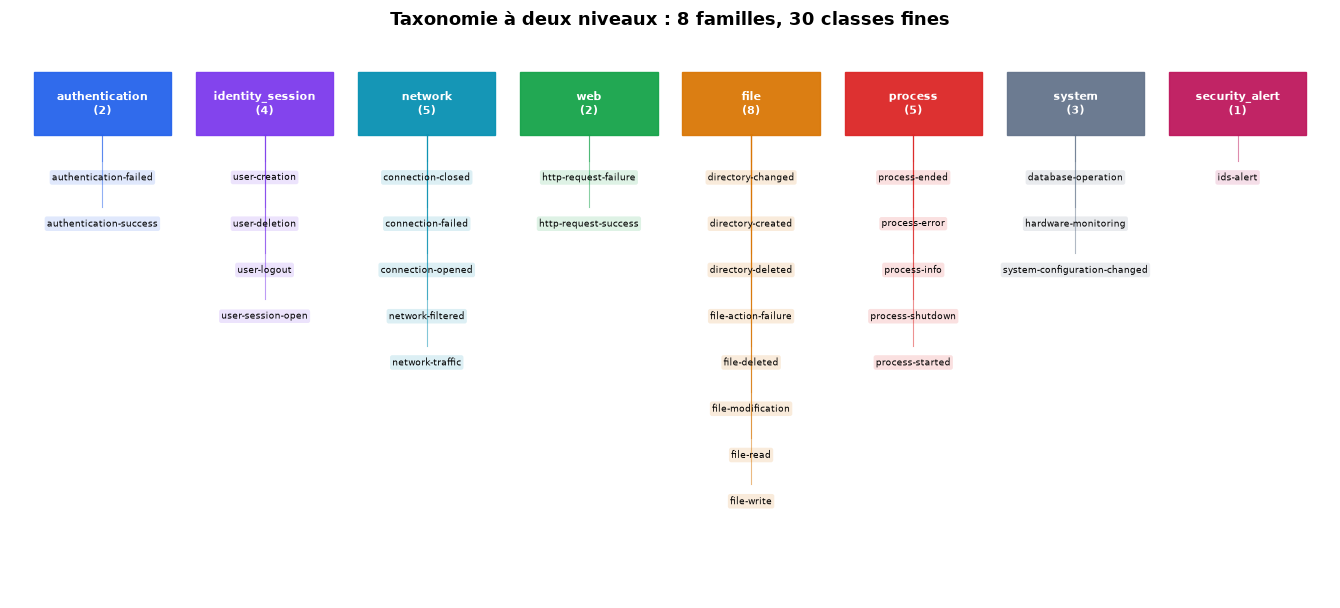

In [17]:
# --- 0.10 Figure : la taxonomie ---------------------------------------------------------------------
import matplotlib.pyplot as plt
FAM_COLORS = ["#2563eb", "#7c3aed", "#0891b2", "#16a34a", "#d97706", "#dc2626", "#64748b", "#be185d"]
fig, ax = plt.subplots(figsize=(13.5, 6.2)); ax.axis("off"); ax.set_xlim(0, 100); ax.set_ylim(0, 56)
ax.text(50, 54.5, "Taxonomie à deux niveaux : 8 familles, 30 classes fines", ha="center", fontsize=13, fontweight="bold")
fams = list(TAXONOMY); xs = np.linspace(7, 93, len(fams))
for x, (f, col) in zip(xs, zip(fams, FAM_COLORS)):
    ax.add_patch(plt.Rectangle((x - 5.2, 44), 10.4, 6, color=col, alpha=.95)); ax.text(x, 47, f"{f}\n({len(TAXONOMY[f])})", ha="center", va="center", color="white", fontsize=8, fontweight="bold")
    for i, c in enumerate(TAXONOMY[f]):
        y = 40 - i * 4.4
        ax.plot([x, x], [44, y + 1.6], color=col, lw=0.8, alpha=.5); ax.text(x, y, c, ha="center", va="center", fontsize=6.4, bbox=dict(boxstyle="round,pad=0.25", fc=col, ec="none", alpha=.14))
plt.tight_layout(); fig.savefig(DIRS["figures"] / "00_taxonomie.png", dpi=140); plt.show()

**Lecture de la figure.** Les familles les plus grosses sont `file` (8 classes), `network` et `process` (5 chacune). `security_alert` ne contient qu'une classe : c'est le seul cas où masquer cette classe revient à masquer **une famille entière** (dit à la section suivante). Cette taxonomie sert à : (a) la tête « famille » du modèle (étape 6), (b) la **distance d'erreur dans l'arbre** (0 = bonne classe, 1 = autre classe de la même famille, 2 = autre famille).

## 0.11 Les classes masquées : 5 rotations qui couvrent chaque classe une fois

**Pourquoi.** Pour étudier le monde ouvert **sans** données d'un autre SIEM, on **fait semblant** que certaines classes sont inconnues : on les retire de l'entraînement, et on vérifie que le modèle les rejette. Si on ne masquait **qu'un seul** ensemble de classes, le résultat dépendrait de ce choix chanceux ou malchanceux. On **répète** donc avec plusieurs ensembles.

**Décision (demandée « vas-y » par l'utilisateur, détail justifié ici).** On partitionne les 30 classes en **5 groupes de 6** (20 % chacun, comme demandé par le projet). Chaque classe est donc masquée **exactement une fois** : tout le monde est « inconnu » à tour de rôle, aucune classe n'est favorisée.

**Contraintes écrites avant le tirage** (pour que chaque rotation soit une expérience *informative*) :
1. Chaque famille de **2 classes ou plus** garde **au moins une classe connue** : on teste « classe nouvelle dans une famille connue ».
2. Au plus **3 classes masquées d'une même famille** par rotation.
3. Au moins **3 familles différentes** touchées par rotation.
4. `ids-alert` (famille d'une seule classe) est masquée dans une rotation : c'est le seul cas **« famille entièrement nouvelle »**, analysé **à part**.
5. Tirage **déterministe** (graine 42), avec le nombre d'essais enregistré.

<!-- REV-0.11 -->
**Remarque de méthode.** Les cinq rotations jouent le rôle d'une **validation croisée sur les classes** : chaque classe est masquée une fois, et l'on moyenne sur les rotations avec leur dispersion. Elles ne remplacent pas la validation croisée **par gabarits** (protocoles de 0.1b.1), qui porte sur le découpage des logs.

In [18]:
# --- 0.11 Rotations de classes masquées : partition 5 x 6, contraintes vérifiées ---------------------
ROT_SEED, N_ROT, K_HIDE = 42, 5, 6
def valid_rotation(group):
    fam_hidden = pd.Series([CHILD2FAM[c] for c in group]).value_counts()
    for f, n in fam_hidden.items():
        if len(TAXONOMY[f]) >= 2 and n >= len(TAXONOMY[f]): return False        # contrainte 1
        if n > 3: return False                                                  # contrainte 2
    return len(fam_hidden) >= 3                                                  # contrainte 3
def make_rotations(seed, max_tries=200000):
    rng = np.random.default_rng(seed)
    for t in range(1, max_tries + 1):
        perm = [str(c) for c in rng.permutation(PAPER_CLASSES)]; groups = [perm[i * K_HIDE:(i + 1) * K_HIDE] for i in range(N_ROT)]
        if all(valid_rotation(g) for g in groups): return [sorted(g) for g in groups], t
    raise RuntimeError("aucune partition valide trouvée")
ROTATIONS, tries = make_rotations(ROT_SEED)
# --- tests -------------------------------------------------------------------------------------------
flat = [c for g in ROTATIONS for c in g]
assert sorted(flat) == sorted(PAPER_CLASSES) and len(set(flat)) == 30, "chaque classe doit être masquée exactement une fois"
assert all(len(g) == K_HIDE for g in ROTATIONS) and all(valid_rotation(g) for g in ROTATIONS)
assert ROTATIONS == make_rotations(ROT_SEED)[0], "le tirage doit être reproductible"
print(f"Partition trouvée au tirage n° {tries} (graine {ROT_SEED}) ; chaque classe masquée exactement une fois ; reproductible.\n")
for r, g in enumerate(ROTATIONS, 1):
    novel_family = [c for c in g if len(TAXONOMY[CHILD2FAM[c]]) == 1]
    print(f"Rotation {r} : " + ", ".join(g) + (f"   <- famille entièrement nouvelle : {novel_family}" if novel_family else ""))
ROT_OF = {c: r for r, g in enumerate(ROTATIONS) for c in g}
import json
(DIRS["data"] / "taxonomy_and_rotations_v1.json").write_text(json.dumps({"taxonomy": TAXONOMY, "rotations": ROTATIONS, "seed": ROT_SEED, "tries": tries, "classes_paper_order": PAPER_CLASSES}, indent=1, ensure_ascii=False))

Partition trouvée au tirage n° 1 (graine 42) ; chaque classe masquée exactement une fois ; reproductible.

Rotation 1 : directory-created, http-request-success, process-info, process-started, system-configuration-changed, user-session-open
Rotation 2 : database-operation, file-deleted, network-traffic, process-ended, process-error, user-creation
Rotation 3 : authentication-failed, connection-failed, directory-changed, file-action-failure, http-request-failure, network-filtered
Rotation 4 : file-modification, file-read, hardware-monitoring, ids-alert, process-shutdown, user-logout   <- famille entièrement nouvelle : ['ids-alert']
Rotation 5 : authentication-success, connection-closed, connection-opened, directory-deleted, file-write, user-deletion


2341

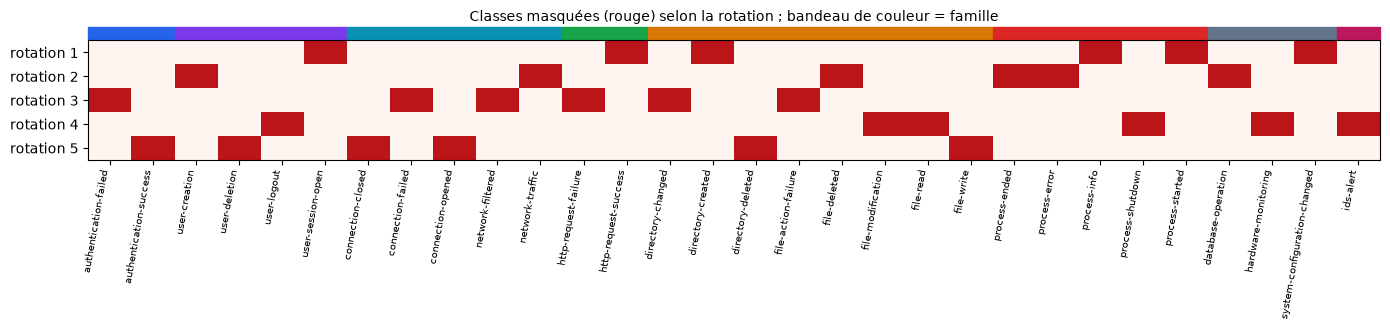

In [19]:
# --- 0.11 Figure : matrice rotations x classes -------------------------------------------------------
order = [c for f in TAXONOMY for c in TAXONOMY[f]]
M = np.zeros((N_ROT, 30));
for j, c in enumerate(order): M[ROT_OF[c], j] = 1
fig, ax = plt.subplots(figsize=(14, 3.4)); ax.imshow(M, cmap="Reds", aspect="auto", vmin=0, vmax=1.25)
ax.set_yticks(range(N_ROT)); ax.set_yticklabels([f"rotation {r + 1}" for r in range(N_ROT)]); ax.set_xticks(range(30)); ax.set_xticklabels(order, rotation=80, ha="right", fontsize=7)
x0 = 0
for f, col in zip(TAXONOMY, FAM_COLORS):
    n = len(TAXONOMY[f]); ax.add_patch(plt.Rectangle((x0 - .5, -1.05), n, 0.5, color=col, clip_on=False)); x0 += n
ax.set_title("Classes masquées (rouge) selon la rotation ; bandeau de couleur = famille", fontsize=10, pad=14)
plt.tight_layout(); fig.savefig(DIRS["figures"] / "00_rotations.png", dpi=140); plt.show()

**Lecture.** Chaque colonne a **une seule** case rouge : chaque classe est masquée une fois. Chaque ligne en a 6, réparties sur plusieurs familles. Les 5 rotations donnent 5 expériences d'« inconnu » ; les résultats seront **moyennés** et on rapportera aussi la **dispersion entre rotations** (un résultat qui varie beaucoup d'une rotation à l'autre dit que le choix des classes masquées compte).

**Limite assumée.** Masquer des classes **simule** le monde ouvert ; cela ne prouve pas la détection de toutes les nouveautés réelles (le document du projet le dit aussi).

## 0.12 Accès aux données : état et action nécessaire

**Constat (V10).** SIEVE n'est **pas** téléchargeable librement : le laboratoire des auteurs exige une **demande par e-mail** (nom, affiliation, usage prévu, engagement de citer l'article). Je n'ai **pas** envoyé cet e-mail à la place de l'utilisateur : il engage son identité et ses engagements. L'utilisateur l'a envoyé lui-même ; **les auteurs ont répondu par un lien de téléchargement** (archive `SIEVE_100K.zip`, six fichiers CSV). Le jeton du lien de partage n'est volontairement pas recopié dans ce notebook.

**Mise à jour (étape 1).** L'archive contient **uniquement** les six versions SIEVE_00 à 05. Le jeu **CDS (440 logs réels)** n'y figure **pas** : l'expérience E5 reste en suspens jusqu'à sa réception (voir 1.7).

<!-- REV-0.12 -->
**Mise à jour (après l'état de l'art).** (1) L'archive SIEVE est reçue et auditée (étape 1) ; le **CDS** reste absent (E5 en suspens). (2) Un **second fichier** a été téléchargé avec **l'accord explicite de l'étudiant** : `confusables.txt` de la norme Unicode UTS #39 (source : `https://www.unicode.org/Public/security/latest/confusables.txt`, 763 128 octets, version 18.0.0 datée du 2026-08-06) ; il a été traité comme donnée non fiable et est audité en **1.7**. (3) La **licence du jeu SIEVE** reste inconnue (V11).

## 0.13 Bilan de l'étape 0

**Ce qui est fixé.** Question et cinq hypothèses réfutables ; métriques et expériences E1 à E5 ; encodeur (DistilBERT sensible à la casse, BERT en contrôle sur une rotation) ; taxonomie à 8 familles adossée à ECS, **traitée comme hypothèse de démonstration** ; **5 rotations** de 6 classes masquées, chacune une fois, vérifiées par code ; mécanisme « charger ou entraîner » testé ; répartition du calcul (Kaggle + Colab en parallèle, local = zone de vérité).

**Ce qui a changé par rapport au plan annoncé.** Le document du projet décrit CDS comme un jeu de test de transfert « non inclus dans les versions synthétiques ». La lecture de l'article montre que CDS est la **source** de SIEVE : l'expérience E5 sera donc présentée avec cette réserve, et **mesurée** (similarité CDS ↔ SIEVE) avant toute conclusion.

**Ce qui a été débloqué.** Les données (0.12). **Ce qui reste en suspens.** Le jeu CDS (E5).

**Prochaine étape.** Étapes 1 à 3 ci-dessous.

<!-- REV-0.13 -->
**Mise à jour après la revue de la littérature.** Ont été ajoutés : l'**état de l'art** complet (0.1b : cinq blocs, lacune formulée avec prudence, 73 références vérifiées) ; la **question affinée** et ses cinq sous-questions (Q3 à Q5 prioritaires pour la fiabilité) ; les hypothèses **H6** (écrite à l'étape 8) et **H7 à H11** (avec la réserve d'honnêteté) ; deux critères de succès **S7 et S8** (fixés en 2.5) ; les expériences **E6** (quatre protocoles de découpage, dont la validation croisée imbriquée par groupes) et **E7** (défenses testées au pire cas) ; les méthodes d'inconnus **OpenMax, Mahalanobis, kNN** et le **repli sur la famille** ; de nouveaux risques en 0.5 ; la répartition du calcul **réellement suivie** (0.8). **Défaut reconnu :** la table de normalisation des homoglyphes était l'inverse de celle de l'attaque (V75) ; la correction est prévue à l'étape 9. Rien de ce qui précède n'a été supprimé.

---
# Étape 1 : Acquisition et audit des données

**Pourquoi cette étape existe.** Avant d'entraîner quoi que ce soit, on vérifie **ce qu'on a vraiment reçu** : les bons fichiers, complets, non corrompus, conformes à ce que l'article annonce. Au TP1, cette vérification a révélé qu'un jeu de données *en apparence parfait* était en réalité corrompu (quelques textes recopiés des milliers de fois). On ne fait donc **confiance à aucun fichier avant de l'avoir mesuré**.

**Concepts.**
- **Empreinte (*hash*, SHA-256)** : un « résumé » de 64 caractères d'un fichier. Si un seul octet change, l'empreinte change. Elle prouve qu'on travaille toujours sur **le même** fichier.
- **`DATA_ID`** : une empreinte courte des six fichiers ensemble ; tous les découpages et modèles lui sont rattachés, pour qu'un modèle ne soit jamais relié à d'autres données que celles qui l'ont produit.
- **Doublon exact** : deux lignes identiques au caractère près.
- **Conformité** : ce que l'on mesure est-il ce que l'article (V1) annonce ?

**En simple.** C'est contrôler la livraison avant de cuisiner : le colis est-il complet, les ingrédients sont-ils ceux de la commande, rien n'est-il avarié ?

## 1.1 Acquisition, empreintes et extraction sûre

**Provenance.** L'archive `SIEVE_100K.zip` a été fournie par les **auteurs eux-mêmes** (lien de partage reçu après la demande d'accès). Sa taille (31 043 250 octets) est celle annoncée par le serveur au moment du téléchargement ; on la **vérifie** ci-dessous. **Sécurité.** Un fichier téléchargé est une donnée non fiable : on vérifie qu'aucun chemin de l'archive ne cherche à sortir du dossier d'extraction (attaque « zip slip »), et on n'exécute rien de ce qu'elle contient.

<!-- REV-1 -->
**Mise à jour après l'état de l'art.** L'étape 1 audite désormais **deux** fichiers : l'archive SIEVE (sections 1.1 à 1.6, inchangées) et la **table officielle des caractères confondables** d'Unicode (section **1.7**), nécessaire pour corriger la défense contre les homoglyphes (étape 9). Même règle : aucun fichier n'est utilisé avant d'avoir été mesuré (taille, empreinte, version, contenu).

In [20]:
import re, zipfile, collections, hashlib
import pandas as pd, matplotlib.pyplot as plt
RED, BLUE, GREY = "#dc2626", "#2563eb", "#9ca3af"
FAM_COLORS = ["#2563eb", "#7c3aed", "#0891b2", "#16a34a", "#d97706", "#dc2626", "#64748b", "#be185d"]
RAW = DIRS["data"] / "raw"; ZIP = RAW / "sieve_zip" / "SIEVE_100K.zip"; EXTRACT = RAW / "sieve_extracted"
ZIP_SIZE_EXPECTED = 31043250
assert ZIP.exists(), f"Fichier absent : {ZIP.relative_to(PROJECT_ROOT)}"
zip_sha = hashlib.sha256(ZIP.read_bytes()).hexdigest()
print(f"Archive : {ZIP.name}  {ZIP.stat().st_size:,} octets  sha256 {zip_sha[:16]}...")
assert ZIP.stat().st_size == ZIP_SIZE_EXPECTED, "taille différente de celle annoncée par le serveur au téléchargement"
with zipfile.ZipFile(ZIP) as zf:
    names = zf.namelist()
    for nme in names:                                   # sécurité : aucun chemin ne doit sortir du dossier d'extraction
        assert not nme.startswith("/") and ".." not in Path(nme).parts, f"chemin suspect dans l'archive : {nme}"
    print("Contenu :", [(i.filename, f"{i.file_size / 1e6:.1f} Mo") for i in zf.infolist()])
    EXTRACT.mkdir(exist_ok=True)
    for nme in names:
        if not (EXTRACT / nme).exists(): zf.extract(nme, EXTRACT)
FILES = {v: EXTRACT / f"SIEVE_0{v}_100K.csv" for v in range(6)}
assert all(f.exists() for f in FILES.values()), "les 6 versions doivent être présentes"
manifest = {"zip": {"bytes": ZIP.stat().st_size, "sha256": zip_sha}, **{f.name: {"bytes": f.stat().st_size, "sha256": hashlib.sha256(f.read_bytes()).hexdigest()} for f in FILES.values()}}
(DIRS["data"] / "raw_manifest.json").write_text(json.dumps(manifest, indent=1))
for k, vv in manifest.items(): print(f"  {k:<20} {vv['bytes']:>12,} octets  {vv['sha256'][:16]}")
DATA_ID = hashlib.sha256("".join(manifest[f.name]["sha256"] for f in FILES.values()).encode()).hexdigest()[:16]
print("DATA_ID (empreinte des 6 fichiers) :", DATA_ID)

Archive : SIEVE_100K.zip  31,043,250 octets  sha256 3b15c579a847f759...
Contenu : [('SIEVE_00_100K.csv', '17.0 Mo'), ('SIEVE_01_100K.csv', '17.4 Mo'), ('SIEVE_02_100K.csv', '17.9 Mo'), ('SIEVE_03_100K.csv', '18.3 Mo'), ('SIEVE_04_100K.csv', '18.7 Mo'), ('SIEVE_05_100K.csv', '19.2 Mo')]
  zip                    31,043,250 octets  3b15c579a847f759
  SIEVE_00_100K.csv      16,985,152 octets  959a387e241d167d
  SIEVE_01_100K.csv      17,404,387 octets  0d143903157bf796
  SIEVE_02_100K.csv      17,873,215 octets  78850965e069c73a
  SIEVE_03_100K.csv      18,305,783 octets  e8335ad1f50617e0
  SIEVE_04_100K.csv      18,719,560 octets  7aa349d8e7e822e9
  SIEVE_05_100K.csv      19,203,280 octets  859d426745588630
DATA_ID (empreinte des 6 fichiers) : 999a1f7edf7eb964


**Lecture.** L'archive contient **exactement six fichiers**, un par version (SIEVE_00 à SIEVE_05), de 17 à 19 Mo chacun ; aucun chemin suspect. Les empreintes sont enregistrées dans `artifacts/data/raw_manifest.json`. Le `DATA_ID` ci-dessus identifie **ces six fichiers-là** : si on en remplaçait un, tout modèle sauvegardé serait rejeté.

*(Question posée en cours de route : « il y a six CSV, pourquoi n'en prendre qu'un ? » On les prend **tous** ; le lien donne une seule archive qui contient les six.)*

## 1.2 Lecture : le piège du format

Les fichiers ont deux particularités qu'on découvre **en les ouvrant**, pas en supposant :
1. Les **logs contiennent des virgules** (par exemple `Feb 03 12:00:01 host sshd[1]: error: user a, b failed`) **sans guillemets**. Un lecteur CSV standard (`pandas.read_csv`) croit que chaque virgule ouvre une nouvelle colonne et **échoue**.
2. Les lignes se terminent par `\r\n` (fins de ligne Windows) : si on n'y prend pas garde, le retour chariot `\r` reste collé au dernier mot de chaque log, ce qui fausse silencieusement les comptes de mots.

**Décision.** Lecture personnalisée : on coupe chaque ligne à la **première virgule seulement** (le nom de classe n'en contient jamais) et on retire `\r\n`. On **teste** que le lecteur standard échoue (preuve que le piège est réel) et qu'aucune ligne n'est rejetée.

In [21]:
def read_sieve(path):
    cats, logs, bad = [], [], 0
    with open(path, encoding="utf-8", newline="") as fh:
        header = fh.readline().rstrip("\r\n"); assert header == "category,log", header
        for line in fh:
            line = line.rstrip("\r\n")                  # les fichiers utilisent des fins de ligne Windows (\r\n)
            if "," not in line: bad += 1; continue
            c, l = line.split(",", 1); cats.append(c); logs.append(l)
    return pd.DataFrame({"category": cats, "log": logs}), bad
crlf = sum(1 for _ in open(FILES[0], encoding="utf-8", newline="") if _.endswith("\r\n"))
print(f"Fins de ligne Windows (\\r\\n) dans SIEVE_00 : {crlf:,} lignes sur 100 001 -> le retour chariot est retiré à la lecture (sinon il resterait collé au dernier mot de chaque log).")
# démonstration du piège : le lecteur CSV standard échoue sur ce fichier
try:
    pd.read_csv(FILES[0]); print("lecture pandas standard : OK (inattendu)")
except Exception as e:
    print("pandas.read_csv échoue, comme prévu :", str(e)[:90])
V = {}
for v in range(6):
    V[v], bad = read_sieve(FILES[v]); assert bad == 0, f"{bad} lignes sans virgule dans la version {v}"
    V[v]["version"] = v; V[v]["row"] = np.arange(len(V[v]))
print("Lecture personnalisée : OK, 0 ligne sans virgule dans les 6 fichiers.")

Fins de ligne Windows (\r\n) dans SIEVE_00 : 100,001 lignes sur 100 001 -> le retour chariot est retiré à la lecture (sinon il resterait collé au dernier mot de chaque log).
pandas.read_csv échoue, comme prévu : Error tokenizing data. C error: Expected 2 fields in line 737, saw 5



Lecture personnalisée : OK, 0 ligne sans virgule dans les 6 fichiers.


**Lecture.** (1) Les 100 001 lignes de SIEVE_00 se terminent bien par `\r\n` : le retour chariot est retiré. (2) `pandas.read_csv` échoue à la ligne 737 (« 2 champs attendus, 5 trouvés ») : **preuve** que les virgules sont dans les logs. (3) Notre lecture ne rejette aucune ligne.

## 1.3 Conformité avec l'article (V1, V2)

In [22]:
rows = []
for v in range(6):
    d = V[v]; vc = d["category"].value_counts()
    rows.append({"version": f"SIEVE_0{v}", "logs": len(d), "classes": d["category"].nunique(), "min/classe": int(vc.min()), "max/classe": int(vc.max()),
                 "logs distincts": d["log"].nunique(), "doublons exacts": int(len(d) - d["log"].nunique()), "longueur moyenne": round(d["log"].str.len().mean(), 1),
                 "longueur max": int(d["log"].str.len().max()), "non-ASCII": int((~d["log"].map(str.isascii)).sum()), "vides": int((d["log"].str.strip() == "").sum())})
audit1 = pd.DataFrame(rows); print(audit1.to_string(index=False))
assert (audit1["logs"] == 100000).all() and (audit1["classes"] == 30).all() and (audit1["min/classe"] >= 3333).all() and (audit1["max/classe"] <= 3334).all()
assert all(set(V[v]["category"]) == set(PAPER_CLASSES) for v in range(6)), "les 30 noms de classes doivent être exactement ceux du tableau 1 de l'article"
print("\nConforme à l'article (V1) : 6 x 100 000 logs, 30 classes, 3 333 ou 3 334 logs par classe, noms de classes identiques au tableau 1.")
audit1.to_csv(DIRS["results"] / "step1_audit_versions.csv", index=False)

 version   logs  classes  min/classe  max/classe  logs distincts  doublons exacts  longueur moyenne  longueur max  non-ASCII  vides
SIEVE_00 100000       30        3333        3334           99975               25             150.8          1059         97      0
SIEVE_01 100000       30        3333        3334          100000                0             155.0          1168        130      0
SIEVE_02 100000       30        3333        3334          100000                0             159.7          1249        145      0
SIEVE_03 100000       30        3333        3334          100000                0             164.1          1353        159      0
SIEVE_04 100000       30        3333        3334          100000                0             168.2          1491        196      0
SIEVE_05 100000       30        3333        3334          100000                0             173.0          1572        218      0

Conforme à l'article (V1) : 6 x 100 000 logs, 30 classes, 3 333 ou 3 334 lo

**Lecture (termes techniques).**
- Les six versions comptent chacune **100 000 logs**, **30 classes**, et **3 333 ou 3 334 logs par classe** : conforme à l'article (V1). Les noms des 30 classes sont **exactement** ceux du tableau 1.
- La **longueur moyenne grandit avec p** : 150,8 caractères à p = 0 jusqu'à 173,0 à p = 0,5 ; la longueur maximale passe de 1 059 à 1 572. Les perturbations ajoutent du texte.
- Les logs **non ASCII** sont rares (97 à 218 sur 100 000) et augmentent avec p : ce sont des caractères introduits par la perturbation.
- **Aucun log vide.**
- **SIEVE_00 contient 25 doublons exacts** (100 000 − 99 975) ; les cinq autres versions n'en ont aucun.

**En simple.** Le colis est conforme à la commande. Seule curiosité : le fichier p = 0, le plus « propre », a quelques lignes strictement identiques.

## 1.4 Doublons : exacts, contradictoires, partagés entre versions

In [23]:
dups_in = {v: V[v][V[v].duplicated("log", keep=False)] for v in range(6)}
print("Doublons exacts dans SIEVE_00 :", len(dups_in[0]), "lignes ; classes concernées :", dups_in[0]["category"].value_counts().to_dict())
conflict = V[0].groupby("log")["category"].nunique(); print("Même texte avec DEUX classes différentes (SIEVE_00) :", int((conflict > 1).sum()), "textes")
sets = {v: set(V[v]["log"]) for v in range(6)}
ov = pd.DataFrame([[len(sets[a] & sets[b]) for b in range(6)] for a in range(6)], index=[f"0{a}" for a in range(6)], columns=[f"0{b}" for b in range(6)])
print("\nLogs identiques (au caractère près) partagés entre versions :"); print(ov.to_string())
allv = pd.concat([V[v][["category", "log", "version"]] for v in range(6)]); cross = allv.groupby("log").agg(nv=("version", "nunique"), nc=("category", "nunique"))
print(f"\nTextes présents dans plusieurs versions : {int((cross.nv > 1).sum()):,} ; avec des classes contradictoires : {int((cross.nc > 1).sum())}")

Doublons exacts dans SIEVE_00 : 49 lignes ; classes concernées : {'connection-closed': 49}
Même texte avec DEUX classes différentes (SIEVE_00) : 0 textes



Logs identiques (au caractère près) partagés entre versions :
       00      01      02      03      04      05
00  99975       1       0       0       0       0
01      1  100000       0       0       0       0
02      0       0  100000       0       0       0
03      0       0       0  100000       0       0
04      0       0       0       0  100000       0
05      0       0       0       0       0  100000



Textes présents dans plusieurs versions : 1 ; avec des classes contradictoires : 0


**Lecture.**
- **Doublons de SIEVE_00 : 49 lignes concernées, toutes de la classe `connection-closed`.** C'est cohérent avec un gabarit **sans variable** ou presque (le générateur ne peut alors produire qu'un seul texte), ce qu'on retrouvera à l'étape 2.
- **Aucun texte n'a deux classes différentes** : pas de contradiction d'étiquette, donc pas de bruit d'étiquettes détectable par cette voie.
- **Les six versions ne partagent presque aucun texte** : un seul texte est commun à SIEVE_00 et SIEVE_01. Les versions sont donc des **échantillons distincts** et non des copies perturbées ligne à ligne : il n'y a **pas** de fuite par texte identique entre versions. *Mais* (c'est l'objet des étapes 2 et 3) des logs **différents** peuvent venir du **même gabarit** : c'est là que se cache la vraie fuite.

**Décision.** On **garde** les doublons exacts (49 lignes sur 100 000, un effet négligeable) mais on les **traite en groupe** : un texte et sa copie iront toujours du même côté du découpage, puisqu'ils partagent un gabarit.

## 1.5 Le jeu CDS (440 logs réels) est-il fourni ?

In [24]:
print("Fichiers reçus :", [f.name for f in FILES.values()])
print("CDS (440 gabarits réels) fourni dans l'archive :", False)
print("-> L'expérience E5 (transfert vers CDS) est en SUSPENS : le fichier n'est pas dans SIEVE_100K.zip. Il faudra le demander aux auteurs.")

Fichiers reçus : ['SIEVE_00_100K.csv', 'SIEVE_01_100K.csv', 'SIEVE_02_100K.csv', 'SIEVE_03_100K.csv', 'SIEVE_04_100K.csv', 'SIEVE_05_100K.csv']
CDS (440 gabarits réels) fourni dans l'archive : False
-> L'expérience E5 (transfert vers CDS) est en SUSPENS : le fichier n'est pas dans SIEVE_100K.zip. Il faudra le demander aux auteurs.


**Lecture et décision.** L'archive ne contient **pas** le CDS. Conséquence honnête : l'expérience **E5** (transfert vers des logs d'origine) **ne peut pas être menée aujourd'hui**. Au lieu d'inventer un substitut, on la **met en suspens** et on demande le fichier aux auteurs. En attendant, on utilise un **test par gabarits jamais vus** (étape 3), qui répond à la même question de fond : *le modèle sait-il classer des logs dont la **structure** ne ressemble à aucun exemple d'entraînement ?*

## 1.6 Registre de vérification (suite de la section 0.9bis)

| N° | Affirmation | Source | Niveau |
|---|---|---|---|
| V15 | `SIEVE_100K.zip` (31 043 250 octets, SHA-256 `3b15c579...`) fourni par les auteurs via un lien de partage, contient **exactement 6 CSV** (SIEVE_00 à 05) | Calcul (listage de l'archive) | calcul |
| V16 | Format : colonnes `category,log` ; fins de ligne `\r\n` ; virgules **non guillemetées** dans les logs (`pandas.read_csv` échoue) | Calcul | calcul |
| V17 | 6 x 100 000 logs, 30 classes, 3 333 ou 3 334 logs par classe, noms conformes au tableau 1 de l'article (confirme V1) | Calcul | calcul |
| V18 | 25 doublons exacts dans SIEVE_00 (tous `connection-closed`), aucun dans les autres versions ; aucun texte à deux classes ; un seul texte partagé entre versions | Calcul | calcul |
| V19 | Le jeu CDS (440 logs réels) **n'est pas** dans l'archive | Calcul | calcul |

<!-- REV-1.7 -->
## 1.7 Un second fichier : la table officielle des caractères confondables (UTS #39)

**Pourquoi.** Notre première défense contre les homoglyphes utilisait une table de 18 lettres, **l'inverse exact** de celle de l'attaque (V75) : elle ne prouve donc rien. La norme Unicode UTS #39 (*Security Mechanisms*) publie un fichier officiel, `confusables.txt`, qui associe à chaque caractère un **prototype** (par exemple la lettre cyrillique « а », U+0430, au « a » latin). C'est une **source indépendante** de nos attaques. La norme précise que ces « squelettes » servent à une **comparaison interne**, pas à l'affichage : notre usage est une canonicalisation **interne**, avant le classifieur.

**Provenance et sécurité.** Fichier téléchargé le 2026-11-05 avec l'accord de l'étudiant depuis `https://www.unicode.org/Public/security/latest/confusables.txt` ; donnée non fiable : on la **lit** sans jamais l'exécuter, après vérification de la taille et de l'empreinte relevées au téléchargement.

In [25]:
# --- 1.7 Audit de confusables.txt (taille, empreinte, version, contenu) ---------------------------------
import unicodedata as ud
from tp2_attacks import HOMOGLYPH
CONF = PROJECT_ROOT / "etat_de_l_art" / "unicode_confusables" / "confusables.txt"
EXPECTED = {"octets": 763128, "sha256": "6ed3ee967c9dfdf6677d563c9985182fbc50a2efb7d6059cd57b2e2ce18f5b92"}   # relevés au téléchargement
raw = CONF.read_bytes(); sha = hashlib.sha256(raw).hexdigest()
assert len(raw) == EXPECTED["octets"] and sha == EXPECTED["sha256"], "le fichier a changé depuis le téléchargement"
head = raw[:600].decode("utf-8-sig").splitlines(); version = next(l for l in head if "Version:" in l).split(":", 1)[1].strip(); date = next(l for l in head if l.startswith("# Date:")).split(":", 1)[1].strip()
rows = []
for line in raw.decode("utf-8-sig").splitlines():
    if line.startswith("#") or ";" not in line: continue
    f = [p.strip() for p in line.split("#")[0].split(";")]
    if len(f) >= 3: rows.append(("".join(chr(int(h, 16)) for h in f[0].split()), "".join(chr(int(h, 16)) for h in f[1].split())))
single_all = [(s, t) for s, t in rows if len(s) == 1 and len(t) == 1 and t.isascii() and t.isalpha()]
ascii_src = [(s, t) for s, t in single_all if ord(s) < 128]                    # ex. « I » -> « l », « 0 » -> « O » : les appliquer abîmerait le texte normal
single = [(s, t) for s, t in single_all if ord(s) >= 128]
conf_df = pd.DataFrame([{"caractere": s, "code": f"U+{ord(s):04X}", "lettre": t, "ecriture": ud.name(s, "?").split()[0], "corrige_par_nfkc": ud.normalize("NFKC", s) == t} for s, t in single])
conf_df.to_csv(DIRS["data"] / "confusables_ascii.csv", index=False)
ours = {c for c in HOMOGLYPH.values()}; found = sum(1 for c in ours if c in set(conf_df.caractere))
manifest = {"fichier": "confusables.txt", "source": "https://www.unicode.org/Public/security/latest/confusables.txt", "version_uts39": version, "date": date, "octets": len(raw), "sha256": sha,
            "entrees": len(rows), "caracteres_vers_lettre_ascii": len(conf_df), "lettres_latines_concernees": conf_df.lettre.nunique(), "corriges_par_nfkc": int(conf_df.corrige_par_nfkc.sum()),
            "restants_apres_nfkc": int((~conf_df.corrige_par_nfkc).sum()), "version_unicode_de_python": ud.unidata_version, "sources_ascii_ecartees": [f"{x}->{y}" for x, y in ascii_src], "notre_table_attaque": len(HOMOGLYPH), "notre_table_retrouvee_dans_la_table_officielle": found}
(DIRS["data"] / "confusables_manifest.json").write_text(json.dumps(manifest, indent=1, ensure_ascii=False))
print(f"UTS #39 v{version} ({date}) : {len(raw):,} octets, sha256 {sha[:16]}... conforme à l'empreinte relevée au téléchargement")
print(f"Base Unicode de ce Python : {ud.unidata_version} (le nombre de caractères corrigés par NFKC en dépend)")
print(f"{len(rows):,} entrées ; {len(conf_df):,} caractères NON ASCII ressemblent à une lettre ASCII ({conf_df.lettre.nunique()} lettres) ; NFKC en corrige {manifest['corriges_par_nfkc']}, il en reste {manifest['restants_apres_nfkc']}")
print("Sources ASCII écartées (les appliquer abîmerait du texte normal) :", [f"{x} -> {y}" for x, y in ascii_src])
print(f"Notre table d'attaque ({len(HOMOGLYPH)} lettres) : {found} retrouvées dans la table officielle, soit {len(HOMOGLYPH) / len(conf_df):.1%} des {len(conf_df):,} caractères")
print("Écritures des caractères restants :", conf_df[~conf_df.corrige_par_nfkc].ecriture.value_counts().head(8).to_dict())

UTS #39 v18.0.0 (2026-08-06, 01:05:35 GMT) : 763,128 octets, sha256 6ed3ee967c9dfdf6... conforme à l'empreinte relevée au téléchargement
Base Unicode de ce Python : 15.0.0 (le nombre de caractères corrigés par NFKC en dépend)
6,712 entrées ; 1,447 caractères NON ASCII ressemblent à une lettre ASCII (50 lettres) ; NFKC en corrige 719, il en reste 728
Sources ASCII écartées (les appliquer abîmerait du texte normal) : ['| -> l', '1 -> l', 'I -> l', '0 -> O']
Notre table d'attaque (18 lettres) : 18 retrouvées dans la table officielle, soit 1.2% des 1,447 caractères
Écritures des caractères restants : {'MATHEMATICAL': 139, 'LATIN': 55, 'CYRILLIC': 47, '?': 40, 'GREEK': 40, 'CHEROKEE': 36, 'WARANG': 27, 'LISU': 26}


**Lecture.** Le fichier est conforme à ce qui a été relevé au téléchargement (taille et empreinte). Il contient 6 712 entrées dont **1 447 caractères non ASCII** qui ressemblent à une lettre ASCII (50 lettres) ; **4 autres sources sont des caractères ASCII** (`|`, `1`, `I`, `0`, associés à `l`, `l`, `l`, `O`) que nous **écartons** : les appliquer transformerait par exemple chaque `I` en `l` dans du texte normal ; la normalisation Unicode standard NFKC en corrige **719** avec la base Unicode 15.0 de ce Python 3.12 (lettres mathématiques, pleine largeur, variantes de compatibilité), il en **reste 728** (cyrillique, grec, cherokee, lisu, etc.), qu'une table doit traiter. **Précision de reproductibilité :** avec un Python plus récent (base Unicode 16.0), NFKC en corrige un peu plus : ce nombre **dépend de la version de la base Unicode** utilisée, qui est donc enregistrée dans `confusables_manifest.json`. Nos 18 lettres cyrilliques s'y trouvent toutes, mais ne représentent qu'environ **1 %** des 1 447 caractères : un attaquant disposerait de centaines d'autres caractères. Les fichiers `confusables_ascii.csv` et `confusables_manifest.json` (dans `artifacts/data/`) servent à l'étape 9 : défense construite sur **une moitié** des caractères, attaque sur **l'autre**.

**Registre (suite).**

| N° | Affirmation | Source | Niveau |
|---|---|---|---|
| V79 | `confusables.txt` (UTS #39 v18.0.0, daté du 2026-08-06) : 763 128 octets, sha256 `6ed3ee96...f5b92`, téléchargé le 2026-11-05 avec l'accord de l'étudiant ; contenu mesuré en 1.7 (V74) | Calcul (cellule 1.7) | calcul |

---
# Étape 2 : Exploration (EDA) : analyses, courbes, risques et parades

**Pourquoi cette étape existe.** L'exploration sert à **comprendre** les données avant de modéliser, et surtout à repérer ce qui pourrait fausser les résultats. Ici, une question domine : le jeu est **généré** à partir de seulement 440 gabarits (V3). Si on ne le prend pas en compte, les modèles auront l'air excellents sans rien comprendre. Chaque risque repéré s'accompagne d'une **parade codée et testée**, pas seulement décrite.

**Concepts.**
- **Gabarit (*template*)** : la « phrase à trous » d'un log, par exemple `Failed password for <utilisateur> from <adresse IP> port <nombre>`. SIEVE remplit les trous avec des valeurs inventées pour fabriquer des milliers de logs à partir d'un seul gabarit.
- **Entropie p** : intensité des perturbations appliquées par SPICE (synonymes, mots ajoutés...) ; p = 0 : seulement le remplissage des trous.
- **Composante connexe** : dans un graphe où l'on relie deux logs jugés semblables, un groupe de logs reliés entre eux de proche en proche.

**En simple.** SIEVE, c'est 440 phrases-types, chacune rejouée des centaines de fois avec des noms, adresses et nombres différents. Deviner la classe d'un log dont on a déjà vu 200 « frères » est facile ; deviner la classe d'un log dont la phrase-type est **nouvelle** est autrement plus dur, et c'est ce dernier cas qui ressemble à la vie réelle.

## 2.1 Ce que la perturbation p change : vocabulaire et longueur

<!-- REV-2 -->
**Mise à jour après l'état de l'art.** L'exploration reste la même ; deux ajouts : (1) la table des **risques** de 2.4 reçoit les risques mis en évidence par la revue de la littérature (R10 à R15, ce sont ceux de la section 0.5) ; (2) la section **2.5** fixe, avant tout modèle, **deux critères de plus** : S7 (calibration) et S8 (robustesse au pire cas).

In [26]:
TOK_RE = re.compile(r"[A-Za-z]+|\d+|[^\sA-Za-z\d]")
CAL = {"mon", "tue", "wed", "thu", "fri", "sat", "sun", "jan", "feb", "mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"}
def toks_of(s):
    # jetons de structure : chiffres et noms de jours / mois remplacés par « # » (champs de date et nombres, variables par nature)
    return ["#" if (t.isdigit() or t.lower() in CAL) else t for t in TOK_RE.findall(s)]
t0 = time.perf_counter()
for v in range(6): V[v]["toks"] = [toks_of(s) for s in V[v]["log"]]
print(f"Tokenisation des 600 000 logs : {time.perf_counter() - t0:.0f} s")
word_re = re.compile(r"[A-Za-z]{2,}")
vocab = {v: collections.Counter(w.lower() for s in V[v]["log"] for w in word_re.findall(s)) for v in range(6)}
voc0 = set(vocab[0])
rows = []
for v in range(6):
    tot = sum(vocab[v].values()); new = sum(c for w, c in vocab[v].items() if w not in voc0)
    rows.append({"version": f"SIEVE_0{v}", "p": v / 10, "mots distincts": len(vocab[v]), "longueur moy. (car.)": round(V[v]["log"].str.len().mean(), 1), "jetons moy.": round(np.mean([len(t) for t in V[v]["toks"]]), 1),
                 "part de mots absents de SIEVE_00": round(new / tot, 4)})
eda_p = pd.DataFrame(rows); print(eda_p.to_string(index=False)); eda_p.to_csv(DIRS["results"] / "step2_effet_p.csv", index=False)

Tokenisation des 600 000 logs : 7 s


 version   p  mots distincts  longueur moy. (car.)  jetons moy.  part de mots absents de SIEVE_00
SIEVE_00 0.0           31627                 150.8         50.1                            0.0000
SIEVE_01 0.1           46880                 155.0         50.3                            0.0494
SIEVE_02 0.2           54721                 159.7         50.7                            0.0809
SIEVE_03 0.3           59848                 164.1         51.0                            0.1055
SIEVE_04 0.4           63612                 168.2         51.4                            0.1252
SIEVE_05 0.5           66385                 173.0         51.9                            0.1464


/var/folders/dy/0wxyjm6j2ln02k3ns61vj41c0000gn/T/ipykernel_14280/111283321.py:4: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bp = ax[0].boxplot(data, vert=False, showfliers=False, patch_artist=True, widths=.7)


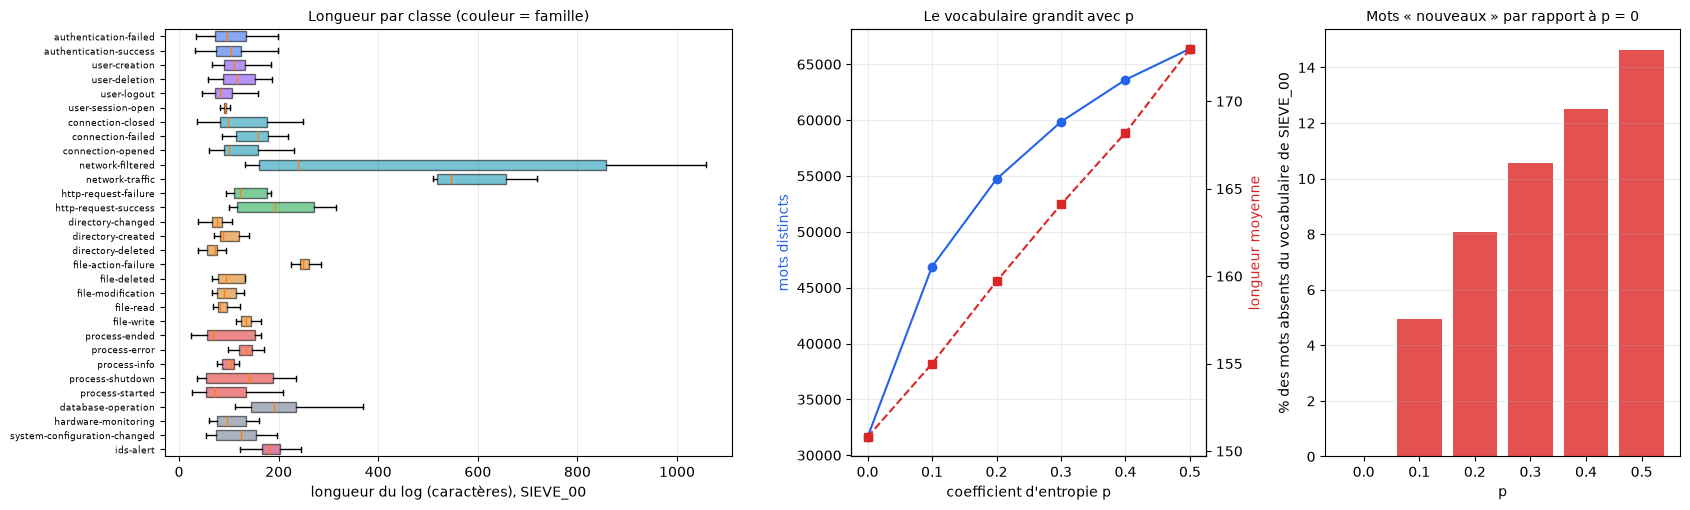

In [27]:
fig, ax = plt.subplots(1, 3, figsize=(17, 5.2), gridspec_kw={"width_ratios": [1.6, 1, 1]})
order = [c for f in TAXONOMY for c in TAXONOMY[f]]; L0 = V[0].assign(n=V[0]["log"].str.len())
data = [L0[L0.category == c]["n"].values for c in order]
bp = ax[0].boxplot(data, vert=False, showfliers=False, patch_artist=True, widths=.7)
cols = [FAM_COLORS[list(TAXONOMY).index(CHILD2FAM[c])] for c in order]
for patch, col in zip(bp["boxes"], cols): patch.set_facecolor(col); patch.set_alpha(.55)
ax[0].set_yticks(range(1, 31)); ax[0].set_yticklabels(order, fontsize=6.5); ax[0].invert_yaxis(); ax[0].set_xlabel("longueur du log (caractères), SIEVE_00"); ax[0].set_title("Longueur par classe (couleur = famille)", fontsize=10); ax[0].grid(axis="x", alpha=.25)
ax[1].plot(eda_p["p"], eda_p["mots distincts"], "o-", color=BLUE); ax[1].set_xlabel("coefficient d'entropie p"); ax[1].set_ylabel("mots distincts", color=BLUE); ax[1].set_title("Le vocabulaire grandit avec p", fontsize=10); ax[1].grid(alpha=.25)
ax1b = ax[1].twinx(); ax1b.plot(eda_p["p"], eda_p["longueur moy. (car.)"], "s--", color=RED); ax1b.set_ylabel("longueur moyenne", color=RED)
ax[2].bar(eda_p["p"].astype(str), 100 * eda_p["part de mots absents de SIEVE_00"], color=RED, alpha=.8); ax[2].set_xlabel("p"); ax[2].set_ylabel("% des mots absents du vocabulaire de SIEVE_00"); ax[2].set_title("Mots « nouveaux » par rapport à p = 0", fontsize=10); ax[2].grid(axis="y", alpha=.25)
plt.tight_layout(); fig.savefig(DIRS["figures"] / "02_longueurs_et_p.png", dpi=140); plt.show()

**Lecture de la figure (gauche, longueurs par classe, SIEVE_00).**
- Les longueurs varient énormément selon la classe : `network-traffic` (environ 500 à 700 caractères) et `network-filtered` (de 150 à plus de 850) sont de très **longs** logs (journaux de pare-feu avec beaucoup de champs), alors que `user-session-open`, `directory-deleted` ou `directory-changed` ne font qu'environ **90 caractères**.
- `user-session-open` et `file-action-failure` ont une boîte **très étroite** : tous leurs logs ont presque la même longueur, signe d'un **gabarit unique** ou presque.

**Conséquences.** *Bonne* : la longueur est un indice de la classe ; on s'attend à ce que les logs réseau très longs soient faciles à isoler (à vérifier à l'étape 7). *Mauvaise* : cette longueur est un **raccourci** (un modèle qui ne regarde que la longueur classe déjà bien certaines familles) ; un encodeur à fenêtre limitée (256 ou 512 jetons) **tronquerait** les plus longs logs (`network-filtered`), donc la longueur maximale devra être choisie **à l'étape 5** d'après ces chiffres.

**Lecture de la figure (centre et droite, effet de p).** Le **vocabulaire** double de p = 0 à p = 0,5 (31 627 puis 66 385 mots distincts), et la **part des mots absents de SIEVE_00** passe de 4,9 % à 14,6 %. Plus p est grand, plus les logs contiennent des mots que le modèle n'a jamais vus si on l'entraîne sur p = 0 : c'est ce que mesurera E4 (robustesse selon p). La croissance se **tasse** (les premiers pas de p apportent le plus de mots nouveaux), donc passer de p = 0,4 à 0,5 « change » moins le vocabulaire que de 0 à 0,1.

## 2.2 Reconstruire les gabarits

**Problème.** Pour découper sans fuite, il faut savoir **quels logs viennent du même gabarit**, or l'archive ne contient **pas** l'identifiant de gabarit. On le **reconstruit**.

**Méthode (décidée avant de la lancer).**
1. On remplace les **nombres** et les **noms de jours et de mois** par un jeton unique `#` (champs variables par nature : horodatages, ports, tailles).
2. Dans **chaque classe**, on garde les **mots constants** : ceux présents dans au moins une fraction **τ** des logs de la classe. Un mot de gabarit (« Failed », « password ») est dans beaucoup de logs ; une valeur inventée (un nom d'utilisateur) est dans très peu.
3. Deux logs sont **liés** si la ressemblance de **Jaccard** de leurs mots constants atteint un seuil ($J(A,B)=|A\cap B|/|A\cup B|$) ; un **gabarit** = une composante connexe.
4. **Validation** : l'article donne **le nombre de gabarits par classe** (tableau 1 : 440 au total). On choisit (τ, Jaccard) dans une petite grille en **minimisant l'écart logarithmique moyen** entre notre nombre de gabarits et celui de l'article. *Sous-estimer* (fusionner deux gabarits) est une erreur **prudente** pour un découpage sans fuite : deux gabarits fusionnés iront ensemble. *Sur-estimer* (couper un gabarit en deux) est l'erreur **dangereuse** : ses deux moitiés pourraient atterrir de part et d'autre du découpage.

In [28]:
import scipy.sparse as sps
from scipy.sparse.csgraph import connected_components
from sklearn.feature_extraction.text import CountVectorizer
def class_templates(toks_list, tau, thr):
    # Composantes connexes des logs d'une classe : on ne garde que les jetons « constants » (présents dans >= tau des logs de la classe),
    # deux logs sont liés si la ressemblance de Jaccard de leurs jetons constants atteint thr. Renvoie (étiquettes, jetons constants).
    n = len(toks_list); body = [[t for t in ts if t != "#"] for ts in toks_list]
    cv = CountVectorizer(analyzer=lambda x: x, binary=True); X = cv.fit_transform(body).tocsr()
    df = np.asarray(X.sum(0)).ravel() / n; keep = np.where(df >= tau)[0]; Xk = X[:, keep].astype(np.float32)
    inter = (Xk @ Xk.T).tocsr(); sz = np.asarray(Xk.sum(1)).ravel(); r, c = inter.nonzero(); jac = inter.data / (sz[r] + sz[c] - inter.data + 1e-9)
    m = jac >= thr; A = sps.csr_matrix((np.ones(int(m.sum())), (r[m], c[m])), shape=(n, n)); k, lab = connected_components(A, directed=False)
    return k, lab, np.array(cv.get_feature_names_out())[keep], Xk
GRID = [(tau, thr) for tau in (0.03, 0.05, 0.08) for thr in (0.7, 0.8)]
cds = dict(zip(PAPER_CLASSES, CDS_COUNT)); tpl_cache = DIRS["results"] / "step2_template_grid.json"
if tpl_cache.exists(): grid_res = json.loads(tpl_cache.read_text())
else:
    grid_res = {}
    for tau, thr in GRID:
        t0 = time.perf_counter(); cnt = {}
        for cl in PAPER_CLASSES:
            idx = np.where(V[0]["category"].values == cl)[0]; cnt[cl] = int(class_templates([V[0]["toks"].iloc[i] for i in idx], tau, thr)[0])
        grid_res[f"{tau}|{thr}"] = cnt; print(f"  tau={tau} Jaccard>={thr} : {sum(cnt.values())} gabarits en {time.perf_counter() - t0:.0f} s", flush=True)
    tpl_cache.write_text(json.dumps(grid_res))
def grid_score(cnt):    # erreur logarithmique moyenne par rapport au nombre de gabarits annoncé (tableau 1) ; sous-estimer = fusionner, ce qui est prudent
    return float(np.mean([abs(np.log(cnt[c] / cds[c])) for c in PAPER_CLASSES]))
gt = pd.DataFrame([{"tau": float(k.split("|")[0]), "Jaccard": float(k.split("|")[1]), "gabarits trouvés (440 attendus)": sum(v.values()),
                    "erreur log moyenne": round(grid_score(v), 3), "classes sous-estimées": sum(v[c] < cds[c] for c in PAPER_CLASSES), "classes sur-estimées": sum(v[c] > cds[c] for c in PAPER_CLASSES)} for k, v in grid_res.items()])
print(gt.to_string(index=False)); BEST = min(grid_res, key=lambda k: grid_score(grid_res[k])); TAU, THR = [float(x) for x in BEST.split("|")]
print(f"\nRéglage retenu (erreur logarithmique minimale) : tau = {TAU}, Jaccard >= {THR}")

 tau  Jaccard  gabarits trouvés (440 attendus)  erreur log moyenne  classes sous-estimées  classes sur-estimées
0.03      0.7                              288               0.440                     20                     2
0.03      0.8                             1045               0.492                     17                     7
0.05      0.7                              235               0.421                     20                     1
0.05      0.8                              311               0.298                     17                     4
0.08      0.7                              215               0.473                     21                     1
0.08      0.8                              280               0.326                     18                     2

Réglage retenu (erreur logarithmique minimale) : tau = 0.05, Jaccard >= 0.8


**Lecture.** Aucune des six combinaisons de la grille (τ de 0,03, 0,05 ou 0,08 ; Jaccard de 0,7 ou 0,8) n'atteint exactement 440 ; la meilleure est **τ = 0,05 avec Jaccard ≥ 0,8** (**311** gabarits, erreur logarithmique **0,298**). Un seuil trop bas (τ = 0,03, Jaccard 0,8) **explose** le nombre de gabarits (1 045) : des mots rares y sont pris pour du gabarit. Le réglage retenu **sous-estime** 17 classes et en **sur-estime** 4.

In [29]:
t0 = time.perf_counter(); proto = {}; tpl_of = {v: np.full(100000, -1) for v in range(6)}; score_of = {v: np.zeros(100000, dtype=np.float32) for v in range(6)}; gid_base = 0; tpl_class = []
for cl in PAPER_CLASSES:
    idx = np.where(V[0]["category"].values == cl)[0]; k, lab, kept, Xk = class_templates([V[0]["toks"].iloc[i] for i in idx], TAU, THR)
    Xk = Xk.tocsr(); P = np.zeros((k, len(kept)), dtype=np.float32)
    for g in range(k): P[g] = np.asarray(Xk[np.where(lab == g)[0]].mean(0)).ravel()
    proto[cl] = (kept, (P >= 0.5).astype(np.float32)); tpl_of[0][idx] = gid_base + lab; score_of[0][idx] = 1.0; tpl_class += [cl] * k
    for v in range(1, 6):
        jdx = np.where(V[v]["category"].values == cl)[0]; vocab_ix = {t: i for i, t in enumerate(kept)}
        M = np.zeros((len(jdx), len(kept)), dtype=np.float32)
        for r_, j in enumerate(jdx):
            for t in set(V[v]["toks"].iloc[j]):
                ci = vocab_ix.get(t)
                if ci is not None: M[r_, ci] = 1
        PP = proto[cl][1]; inter = M @ PP.T; un = M.sum(1)[:, None] + PP.sum(1)[None, :] - inter; jac = inter / np.maximum(un, 1e-9)
        tpl_of[v][jdx] = gid_base + jac.argmax(1); score_of[v][jdx] = jac.max(1)
    gid_base += k
N_TPL = gid_base; tpl_class = np.array(tpl_class)
print(f"{N_TPL} gabarits recomposés (440 attendus) en {time.perf_counter() - t0:.0f} s ; versions p>0 affectées au gabarit le plus proche de leur classe.")
cmp_t = pd.DataFrame({"classe": PAPER_CLASSES, "famille": [CHILD2FAM[c] for c in PAPER_CLASSES], "gabarits (article)": CDS_COUNT, "gabarits recomposés": [int((tpl_class == c).sum()) for c in PAPER_CLASSES]})
print(cmp_t.to_string(index=False)); cmp_t.to_csv(DIRS["results"] / "step2_gabarits_par_classe.csv", index=False)
sc_tab = pd.DataFrame({f"SIEVE_0{v}": pd.Series(score_of[v]).describe(percentiles=[.05, .25, .5]).round(3) for v in range(6)}).T[["mean", "5%", "25%", "50%"]]
print("\nSimilarité (Jaccard) entre chaque log et son gabarit affecté :"); print(sc_tab.to_string())

311 gabarits recomposés (440 attendus) en 17 s ; versions p>0 affectées au gabarit le plus proche de leur classe.
                      classe          famille  gabarits (article)  gabarits recomposés
       authentication-failed   authentication                  69                   51
      authentication-success   authentication                  37                   30
           connection-closed          network                  15                   12
           connection-failed          network                  13                   12
           connection-opened          network                  16                   14
          database-operation           system                   9                    8
           directory-changed             file                   4                    4
           directory-created             file                   3                    3
           directory-deleted             file                   3                    4
         file-ac

**Lecture (termes techniques).**
- **Les classes à peu de gabarits sont retrouvées presque exactement** : `directory-changed` (4 sur 4), `directory-created` (3 sur 3), `file-action-failure` (2 sur 2), `file-deleted` (4 sur 4), `file-modification` (2 sur 2), `file-write` (3 sur 3), `http-request-failure` (3 sur 3), `http-request-success` (4 sur 4), `process-info` (7 sur 7).
- **Les classes à beaucoup de gabarits sont sous-estimées** : `ids-alert` **13 contre 93** (nombreux gabarits très voisins qui fusionnent), `hardware-monitoring` 13 contre 22, `authentication-failed` 51 contre 69.
- **Quelques classes sont sur-estimées** : `process-shutdown` 22 contre 12, `network-filtered` 12 contre 7, `process-ended` 10 contre 6. C'est le **risque dangereux** : voir 2.6 pour sa mesure.
- **`user-session-open`** : 1 gabarit retrouvé contre 3 annoncés (fusion).
- **Affectation des versions p > 0** : on assigne chaque log de SIEVE_01 à SIEVE_05 au gabarit de **sa classe** le plus ressemblant. La ressemblance moyenne **baisse régulièrement** avec p : 1,000 (p = 0, par construction), 0,915, 0,889, 0,870, 0,856, 0,838. Même à p = 0,5, les **5 % de logs les moins ressemblants** gardent un Jaccard de 0,615 : l'affectation reste nette.

**Limite assumée.** La reconstruction est une **approximation** (311 gabarits contre 440). Elle est **volontairement prudente** (plus de fusions que de coupures) et **sera contrôlée sur les données** à l'étape 3 par un audit des plus proches voisins, qui ne dépend pas d'elle.

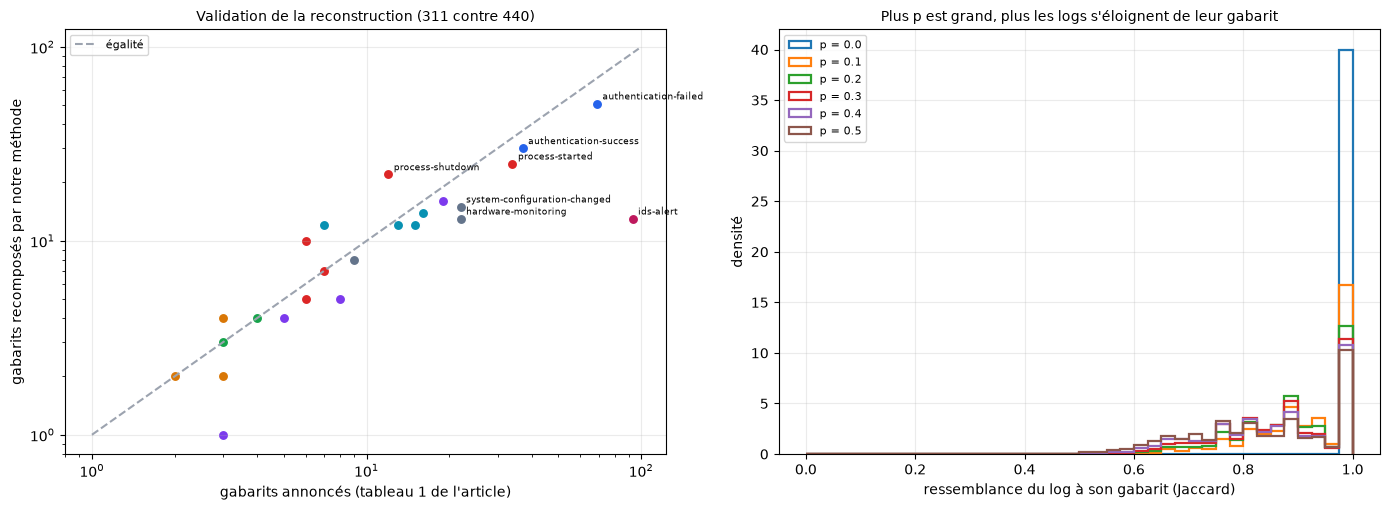

In [30]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5.2))
mx = max(cmp_t["gabarits (article)"].max(), cmp_t["gabarits recomposés"].max()) + 5
ax[0].plot([1, mx], [1, mx], color=GREY, ls="--", label="égalité"); 
for _, r_ in cmp_t.iterrows():
    ax[0].scatter(r_["gabarits (article)"], r_["gabarits recomposés"], color=FAM_COLORS[list(TAXONOMY).index(r_["famille"])], s=55, edgecolor="white")
for _, r_ in cmp_t.iterrows():
    if abs(r_["gabarits recomposés"] - r_["gabarits (article)"]) >= 6: ax[0].annotate(r_["classe"], (r_["gabarits (article)"], r_["gabarits recomposés"]), fontsize=6.5, xytext=(4, 3), textcoords="offset points")
ax[0].set_xscale("log"); ax[0].set_yscale("log"); ax[0].set_xlabel("gabarits annoncés (tableau 1 de l'article)"); ax[0].set_ylabel("gabarits recomposés par notre méthode"); ax[0].set_title(f"Validation de la reconstruction ({N_TPL} contre 440)", fontsize=10); ax[0].legend(fontsize=8); ax[0].grid(alpha=.25)
for v in range(6): ax[1].hist(score_of[v], bins=np.linspace(0, 1, 41), histtype="step", lw=1.6, label=f"p = {v / 10}", density=True)
ax[1].set_xlabel("ressemblance du log à son gabarit (Jaccard)"); ax[1].set_ylabel("densité"); ax[1].set_title("Plus p est grand, plus les logs s'éloignent de leur gabarit", fontsize=10); ax[1].legend(fontsize=8); ax[1].grid(alpha=.25)
plt.tight_layout(); fig.savefig(DIRS["figures"] / "02_gabarits.png", dpi=140); plt.show()
np.savez_compressed(DIRS["data"] / f"templates_{DATA_ID}.npz", **{f"tpl{v}": tpl_of[v] for v in range(6)}, **{f"score{v}": score_of[v] for v in range(6)}, tpl_class=tpl_class)

**Lecture de la figure.** À gauche, chaque point est une classe : proches de la diagonale = gabarits bien retrouvés ; sous la diagonale = fusionnés (cas de `ids-alert`, loin en dessous). À droite, la distribution de la ressemblance d'un log à son gabarit : à p = 0, tout est à 1,0 (pic) ; à mesure que p augmente, la masse **se déplace vers la gauche** (0,6 à 0,9) : les logs s'éloignent de leur gabarit d'origine. C'est le mécanisme même de la perturbation, rendu **visible**.

## 2.3 Quelles classes se ressembleront ? (et ce que l'article en dit)

Paires de classes les plus proches (cosinus des centroïdes TF-IDF, SIEVE_00) :
  0.553  authentication-failed          authentication-success         même famille
  0.523  connection-closed              connection-opened              même famille
  0.466  network-filtered               network-traffic                même famille
  0.439  user-creation                  user-deletion                  même famille
  0.433  connection-closed              user-logout                    familles différentes
  0.418  process-ended                  process-shutdown               même famille
  0.405  authentication-success         user-logout                    familles différentes
  0.397  user-logout                    user-session-open              même famille
  0.378  connection-failed              connection-opened              même famille
  0.374  directory-created              directory-deleted              même famille
  0.360  directory-deleted              file-deleted             

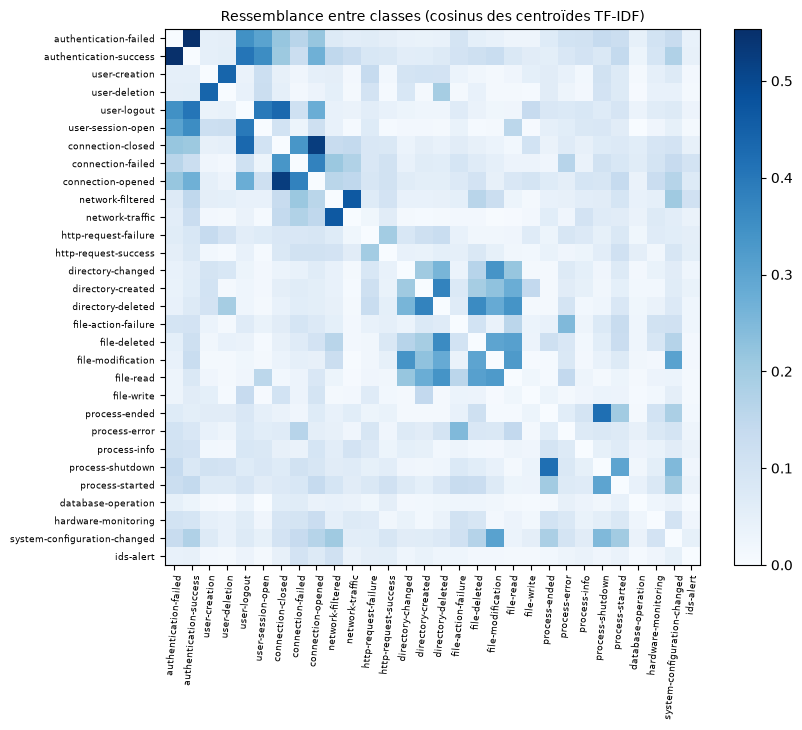

In [31]:
from sklearn.feature_extraction.text import TfidfVectorizer
samp = V[0].groupby("category", group_keys=False).sample(300, random_state=CONFIG["seed"])
tv = TfidfVectorizer(token_pattern=r"[A-Za-z]{2,}", lowercase=True, sublinear_tf=True, min_df=3); Xs = tv.fit_transform(samp["log"])
cent = np.vstack([np.asarray(Xs[np.where(samp["category"].values == c)[0]].mean(0)).ravel() for c in PAPER_CLASSES]); cent /= np.linalg.norm(cent, axis=1, keepdims=True); S = cent @ cent.T; np.fill_diagonal(S, 0)
pairs = sorted([(S[i, j], PAPER_CLASSES[i], PAPER_CLASSES[j]) for i in range(30) for j in range(i + 1, 30)], reverse=True)[:12]
print("Paires de classes les plus proches (cosinus des centroïdes TF-IDF, SIEVE_00) :")
for s_, a, b in pairs: print(f"  {s_:.3f}  {a:<30} {b:<30} {'même famille' if CHILD2FAM[a] == CHILD2FAM[b] else 'familles différentes'}")
RPT = [("directory-deleted", "file-deleted"), ("directory-changed", "file-modification"), ("user-logout", "connection-closed"), ("authentication-failed", "authentication-success")]
print("\nPaires que l'article dit confondues (V6) et leur rang parmi les 435 paires :")
allp = sorted([(S[i, j], PAPER_CLASSES[i], PAPER_CLASSES[j]) for i in range(30) for j in range(i + 1, 30)], reverse=True)
for a, b in RPT:
    rk = [k for k, (s_, x, y) in enumerate(allp, 1) if {x, y} == {a, b}][0]; print(f"  {a} / {b} : rang {rk} sur 435, cosinus {S[PAPER_CLASSES.index(a), PAPER_CLASSES.index(b)]:.3f}")
fig, ax = plt.subplots(figsize=(8.6, 7.4)); ordr = [PAPER_CLASSES.index(c) for c in order]; im = ax.imshow(S[np.ix_(ordr, ordr)], cmap="Blues", vmin=0, vmax=max(0.5, S.max()))
ax.set_xticks(range(30)); ax.set_xticklabels(order, rotation=85, fontsize=6.3); ax.set_yticks(range(30)); ax.set_yticklabels(order, fontsize=6.3); plt.colorbar(im, fraction=0.04); ax.set_title("Ressemblance entre classes (cosinus des centroïdes TF-IDF)", fontsize=10)
plt.tight_layout(); fig.savefig(DIRS["figures"] / "02_classes_proches.png", dpi=140); plt.show()

**Lecture.** Les paires les plus proches par le vocabulaire sont `authentication-failed` / `authentication-success` (cosinus **0,553**, rang **1** sur 435), `connection-closed` / `connection-opened`, `network-filtered` / `network-traffic`, `user-creation` / `user-deletion`.

**Contrôle contre l'article (V6).** L'article rapporte quatre confusions ; leurs paires occupent les rangs **1** (`authentication-failed` / `authentication-success`), **5** (`user-logout` / `connection-closed`), **11** (`directory-deleted` / `file-deleted`) et **15** (`directory-changed` / `file-modification`) sur 435 : elles font **toutes** partie des 15 paires les plus proches de notre propre mesure, **sans** qu'on ait entraîné de modèle. C'est une **corroboration indépendante** du texte de l'article, et la preuve que ces confusions viennent des **données** (des logs réellement presque identiques), pas d'un défaut de tel ou tel classifieur.

**Conséquences pour la suite.** Parmi les 12 paires les plus proches, **9 sont dans la même famille** : une erreur y sera « légère » dans la taxonomie (distance 1). Les paires `connection-closed` / `user-logout` et `authentication-success` / `user-logout` traversent les familles : ce seront les erreurs **graves** (distance 2), à surveiller en E3.

## 2.4 Risques, conséquences (bonnes et mauvaises) et parades

| N° | Constat (mesuré) | Conséquence **mauvaise** | Conséquence **bonne** | Parade (codée et testée) |
|---|---|---|---|---|
| R1 | 100 000 logs par version, générés à partir de seulement 440 gabarits (V3) | Un découpage aléatoire met des « frères » du même gabarit des deux côtés : scores gonflés | Les gabarits donnent une unité naturelle de découpage | **Découpage par gabarit** (étape 3), vérifié par assertion |
| R2 | Gabarits reconstruits, pas fournis : 311 contre 440 | Une coupure erronée pourrait laisser fuiter | Les fusions rendent la fuite plus rare | Audit **indépendant** des plus proches voisins (3.4) |
| R3 | 4 classes à 1 ou 2 gabarits, 8 classes à 3 ou 4 | Pas de test ni de validation strictement propres pour ces classes | — | Trois **paliers** A, B, C (3.1), métriques rapportées **par palier** |
| R4 | Les versions sont des échantillons distincts, pas des copies (V18) | — | Pas de fuite par texte identique entre versions | Vérifié (1.4) ; le groupe est tout de même **commun à toutes les versions** |
| R5 | Longueurs très différentes selon la classe (90 à plus de 850 caractères) | La longueur est un raccourci ; une fenêtre trop courte tronque les logs les plus longs | Indice utile pour la tête « famille » | Choix de la fenêtre de l'encodeur **d'après ces chiffres** (étape 5) |
| R6 | Vocabulaire x2 de p = 0 à 0,5 | Un modèle appris à p = 0 voit 15 % de mots nouveaux à p = 0,5 | Gradient naturel de difficulté pour E4 | Évaluation **par version** (E4) |
| R7 | Confusions annoncées par l'article confirmées (rangs 1, 5, 11, 15) | Plafond de performance sur ces paires | Taxonomie : l'erreur reste « légère » dans la plupart des cas | Distance d'erreur dans l'arbre (E3) |
| R8 | CDS absent de l'archive (V19) | E5 impossible aujourd'hui | — | Mis en suspens ; test par gabarits jamais vus en attendant |
| R9 | Seuil de rejet réglable sur le test = biais | Résultats optimistes | — | Seuil calé sur les **connus de validation seulement** (3.2) ; test scellé |
| R10 | Défense contre les homoglyphes bâtie sur la table de l'attaque (V75) | Résultat tautologique | Table officielle UTS #39 (1.7), moitiés de table, attaque adaptative, pire cas (étape 9) |
| R11 | Découpage choisi a posteriori | Protocole qui arrange | Quatre protocoles comparés (étape 3) |
| R12 | Prétraitement ajusté avant le découpage | Fuite silencieuse | Tout ajusté sur l'entraînement seul, dans chaque pli |
| R13 | Confiance non calibrée (ECE 0,18 à 0,35) | Seuil de rejet qui ne se transporte pas | Température, ECE avant et après (étapes 6 et 9) |
| R14 | Recherche bibliographique non exhaustive | Lacune trop forte | Protocole écrit, formulation prudente (0.1b.6) |
| R15 | H7 à H11 moins strictes que H1 à H6 | Hypothèses formulées avec des résultats exploratoires | Dit en 0.2 et 0.1b.6 |

## 2.5 Seuils de succès (fixés *avant* tout modèle)

On avait promis (0.3) de fixer les seuils chiffrés à la fin de cette étape, avant le jeu de test et avant les modèles. **Transparence** : la seule mesure de classification qu'on ait vue est celle du classifieur de référence de l'étape 3 (3.6) ; elle sert de **plancher**, pas de cible.

In [32]:

# --- 2.5 Seuils de succès, écrits dans un fichier AVANT les modèles ----------------------------------------
criteria = {
    "S1_closed_macro_f1": {"description": "macro-F1 en 30 classes, découpage PAR GABARIT, moyenne sur 3 graines",
                           "plancher_reference": "SVM linéaire TF-IDF : voir 3.6", "acceptable": "plancher + 0,05 avec IC excluant 0", "cible": "plancher + 0,15"},
    "S2_open_auroc": {"description": "AUROC de détection des classes masquées, moyenne sur 5 rotations", "acceptable": 0.80, "cible": 0.90},
    "S3_open_fpr95": {"description": "FPR@95 %TPR (part des inconnus acceptés à tort), moyenne sur 5 rotations", "acceptable_max": 0.50, "cible_max": 0.30},
    "S4_hierarchie": {"description": "F1 famille >= F1 classe fine + 0,10 ; part de prédictions cohérentes (enfant dans la famille prédite) = 100 % par construction"},
    "S5_decision_statistique": {"regle": "différence réelle si l'IC bootstrap par gabarit (95 %) exclut 0 ET |écart| >= 0,01 (marge plus large qu'au TP1, bruit plus fort)"},
    "S6_cout": {"inference_ms_par_log": 100, "remarque": "indicatif"},
    "S7_calibration": {"description": "ECE du MSP sur les classes connues (validation), avant et après mise à l'échelle par température", "acceptable_max": 0.10, "cible_max": 0.05,
                       "remarque": "posé APRÈS l'état de l'art, en connaissant des résultats exploratoires (ECE de l'encodeur 0,18 à 0,35) : structure la conclusion, ne départage pas des méthodes"},
    "S8_robustesse": {"description": "pire cas de baisse relative de macro-F1 sur les attaques, défense bâtie sur une moitié de la table UTS #39 et attaquée avec l'autre (attaque adaptative incluse)", "acceptable_max": 0.10, "cible_max": 0.05,
                      "remarque": "idem : posé après l'état de l'art"},
    "E6_protocoles_de_decoupage": ["aleatoire_temoin", "simple_par_gabarit", "kplis_par_groupes_5", "imbriquee_par_groupes_5x3"],
    "version_des_criteres": 2, "S1_a_S6_inchanges_depuis_la_version_1": True,
    "ecrit_le": time.strftime("%Y-%m-%d %H:%M:%S"), "test_ouvert": False,
}
(DIRS["results"] / "success_criteria.json").write_text(json.dumps(criteria, indent=1, ensure_ascii=False))
print(json.dumps(criteria, indent=1, ensure_ascii=False))


{
 "S1_closed_macro_f1": {
  "description": "macro-F1 en 30 classes, découpage PAR GABARIT, moyenne sur 3 graines",
  "plancher_reference": "SVM linéaire TF-IDF : voir 3.6",
  "acceptable": "plancher + 0,05 avec IC excluant 0",
  "cible": "plancher + 0,15"
 },
 "S2_open_auroc": {
  "description": "AUROC de détection des classes masquées, moyenne sur 5 rotations",
  "acceptable": 0.8,
  "cible": 0.9
 },
 "S3_open_fpr95": {
  "description": "FPR@95 %TPR (part des inconnus acceptés à tort), moyenne sur 5 rotations",
  "acceptable_max": 0.5,
  "cible_max": 0.3
 },
 "S4_hierarchie": {
  "description": "F1 famille >= F1 classe fine + 0,10 ; part de prédictions cohérentes (enfant dans la famille prédite) = 100 % par construction"
 },
 "S5_decision_statistique": {
  "regle": "différence réelle si l'IC bootstrap par gabarit (95 %) exclut 0 ET |écart| >= 0,01 (marge plus large qu'au TP1, bruit plus fort)"
 },
 "S6_cout": {
  "inference_ms_par_log": 100,
  "remarque": "indicatif"
 },
 "S7_calibra

<!-- REV-2.5 -->
**Lecture (ajouts).** **S1 à S6 sont inchangés** (fixés avant tout modèle). **S7** : un ECE du MSP d'au plus 0,10 est acceptable et d'au plus 0,05 est la cible ; **S8** : une baisse relative de macro-F1 au pire cas d'au plus 10 % est acceptable et d'au plus 5 % est la cible. **Honnêteté :** S7 et S8 sont posés **après** la revue de la littérature et après avoir vu des résultats exploratoires ; les seuils (0,10 et 0,05 ; 10 % et 5 %) sont des **conventions de lecture** et non des valeurs réglées pour qu'une méthode les atteigne ; ils servent à structurer la conclusion de l'étape 10, jamais à choisir entre deux méthodes (pour cela, la règle de S5 s'applique). L'expérience **E6** (quatre protocoles de découpage) est enregistrée dans le même fichier.

---
# Étape 3 : Découpage sans fuite par gabarit, et protocole open-set

**Pourquoi cette étape existe.** Un modèle se juge sur ce qu'il n'a **jamais vu**. Ici, « jamais vu » doit vouloir dire : **un gabarit** (une phrase-type) **jamais vu**, pas seulement un log jamais vu. Sinon la note ne mesure que la capacité à reconnaître des variantes d'exemples déjà appris.

**Concepts.** *Entraînement (train)* : pour apprendre. *Validation (val)* : pour choisir (réglages, seuil de rejet). *Test* : une seule évaluation finale, **scellée**. *Fuite* : information du val ou du test qui a glissé dans l'apprentissage. *Découpage par groupes* : tous les logs d'un même gabarit vont du **même côté**.

**En simple.** Pour un examen de conduite, on ne peut pas faire passer le même parcours que celui de l'entraînement : on prend un parcours **nouveau**. Notre « parcours », c'est le gabarit.

## 3.1 Combien de gabarits par classe ? Trois paliers

In [33]:
grp_n = pd.Series(np.concatenate([tpl_of[v] for v in range(6)])).value_counts().sort_index()      # logs par gabarit, toutes versions confondues
G_PER_CLASS = {c: int((tpl_class == c).sum()) for c in PAPER_CLASSES}
tiers = pd.Series({c: ("A : >= 5 gabarits (découpage strict en 3 jeux)" if g >= 5 else "B : 3 ou 4 gabarits (train/test stricts, validation prélevée dans l'entraînement)" if g >= 3 else "C : 1 ou 2 gabarits (au mieux 1 gabarit en test)") for c, g in G_PER_CLASS.items()})
print(tiers.value_counts().sort_index().to_string()); print()
for t_ in sorted(tiers.unique()): print(t_, "->", [f"{c} ({G_PER_CLASS[c]})" for c in PAPER_CLASSES if tiers[c] == t_][:30])

A : >= 5 gabarits (découpage strict en 3 jeux)                                       18
B : 3 ou 4 gabarits (train/test stricts, validation prélevée dans l'entraînement)     8
C : 1 ou 2 gabarits (au mieux 1 gabarit en test)                                      4

A : >= 5 gabarits (découpage strict en 3 jeux) -> ['authentication-failed (51)', 'authentication-success (30)', 'connection-closed (12)', 'connection-failed (12)', 'connection-opened (14)', 'database-operation (8)', 'hardware-monitoring (13)', 'ids-alert (13)', 'network-filtered (12)', 'network-traffic (5)', 'process-ended (10)', 'process-error (5)', 'process-info (7)', 'process-shutdown (22)', 'process-started (25)', 'system-configuration-changed (15)', 'user-creation (5)', 'user-logout (16)']
B : 3 ou 4 gabarits (train/test stricts, validation prélevée dans l'entraînement) -> ['directory-changed (4)', 'directory-created (3)', 'directory-deleted (4)', 'file-deleted (4)', 'file-write (3)', 'http-request-failure (3)', 'http-re

**Lecture.** Découper « par gabarit » n'a de sens que s'il y a **assez de gabarits** pour en mettre quelques-uns dans chaque jeu. D'où trois **paliers** :
- **Palier A (18 classes, 5 gabarits ou plus)** : découpage **strict en trois jeux** (train, val, test), sans gabarit partagé.
- **Palier B (8 classes, 3 ou 4 gabarits)** : **train et test stricts** (un gabarit entier en test), mais la **validation** est un **prélèvement dans les gabarits d'entraînement** (donc *non* indépendante : signalée `val_leaky`).
- **Palier C (4 classes, 1 ou 2 gabarits)** : au mieux un gabarit en test ; `user-session-open` n'a **qu'un** gabarit, donc son découpage est un tirage aléatoire **assumé comme fuyant**.

**Conséquence.** Toute métrique sera rapportée **globalement** et **par palier** ; les chiffres des paliers B et C sont **optimistes** (et on le dira à chaque fois).

## 3.2 Règle d'attribution (écrite avant de la lancer) et exécution

**Règle.** Palier A : on cherche la répartition des gabarits dans (train, val, test) qui s'approche le plus de **70 / 15 / 15** en nombre de logs, avec au moins un gabarit en validation et en test. Pour les classes jusqu'à 10 gabarits, la recherche est **exhaustive** (3¹⁰ cas) ; au-delà, on procède du plus gros au plus petit. **Les mêmes gabarits vont dans le même jeu pour les six versions** (un gabarit n'est jamais en entraînement à p = 0 et en test à p = 0,3). **Seuil de rejet** : calé sur les **seuls connus de validation** (on accepte 95 % d'entre eux) ; **aucun inconnu** n'est utilisé pour régler le seuil.

In [34]:
SPLIT_NAMES = ["train", "val", "test"]; TARGET = np.array([0.70, 0.15, 0.15]); SPLIT_SEED = 42
import itertools
def allocate_strict(sizes):
    # Palier A. Recherche EXHAUSTIVE de la répartition des gabarits dans (train, val, test) qui minimise l'écart L1 aux cibles 70/15/15,
    # avec au moins un gabarit en val et en test (jusqu'à 10 gabarits : 3^10 cas) ; au-delà, glouton du plus gros au plus petit.
    ids = sorted(sizes, key=lambda g: -sizes[g]); tot = sum(sizes.values()); w = np.array([sizes[g] for g in ids], dtype=float)
    if len(ids) <= 10:
        best = None
        for combo in itertools.product(range(3), repeat=len(ids)):
            if 1 not in combo or 2 not in combo or 0 not in combo: continue
            sh = np.array([w[[i for i, k in enumerate(combo) if k == j]].sum() / tot for j in range(3)]); cost = np.abs(sh - TARGET).sum()
            if best is None or cost < best[0] - 1e-12: best = (cost, combo)
        return dict(zip(ids, best[1]))
    cur = np.zeros(3); out = {}
    for g in ids:
        k = int(np.argmax((TARGET * tot - cur) / (TARGET * tot))); out[g] = k; cur[k] += sizes[g]
    for k in (1, 2):
        if k not in out.values():
            donor = min((g for g in ids if out[g] == 0), key=lambda g: sizes[g]); out[donor] = k
    return out
rng_t = random.Random(SPLIT_SEED); gsplit = {}; r_ = np.random.default_rng(SPLIT_SEED)
for cl in PAPER_CLASSES:
    gids = [int(g) for g in np.where(tpl_class == cl)[0]]; sizes = {g: int(grp_n.get(g, 0)) for g in gids}
    if len(gids) >= 5: gsplit.update(allocate_strict(sizes))
    elif len(gids) >= 2:                                   # paliers B et C : un gabarit (le plus proche de 15 % des logs) va en test, les autres en entraînement
        tot = sum(sizes.values()); t_g = min(gids, key=lambda g: abs(sizes[g] / tot - 0.15)); gsplit.update({g: (2 if g == t_g else 0) for g in gids})
    else: gsplit[gids[0]] = -1
parts = []
for v in range(6):
    d = V[v][["category", "version", "row"]].copy(); d["group"] = tpl_of[v]; d["jaccard"] = score_of[v]; parts.append(d)
S = pd.concat(parts, ignore_index=True); S["gsplit"] = S["group"].map(gsplit); S["tier"] = S["category"].map(tiers.str[0])
S["split"] = [SPLIT_NAMES[k] if k >= 0 else None for k in S["gsplit"]]
for cl in PAPER_CLASSES:                                    # paliers B, C : validation prélevée (15 % des logs de la classe) dans l'entraînement ; palier C à 1 gabarit : tirage interne
    ix = S.index[S["category"] == cl]
    if tiers[cl][0] in "BC" and G_PER_CLASS[cl] >= 2:
        tr = ix[S.loc[ix, "split"] == "train"]; pick = r_.random(len(tr)) < 0.15 * len(ix) / len(tr); S.loc[tr[pick], "split"] = "val"
    elif G_PER_CLASS[cl] == 1: S.loc[ix, "split"] = r_.choice(SPLIT_NAMES, size=len(ix), p=TARGET)
S["val_leaky"] = (S["tier"].isin(["B", "C"])) & (S["split"] == "val"); S["test_strict"] = ~((S["tier"] == "C") & (S["category"].map(G_PER_CLASS) == 1))
assert S["split"].notna().all()
print(S["split"].value_counts().rename("logs").to_frame().assign(part=lambda x: (x.logs / len(S)).round(3)).to_string())
# --- vérifications par code ---------------------------------------------------------------------------
chk = S[S["test_strict"]]; tt = chk[chk["split"].isin(["train", "test"])]
assert (tt.groupby("group")["split"].nunique() == 1).all(), "un gabarit est à la fois en entraînement et en test : fuite"
strictA = S[S["tier"] == "A"]; assert (strictA.groupby("group")["split"].nunique() == 1).all(), "palier A : un gabarit dans deux jeux"
assert S.groupby("category")["split"].nunique().drop(index=[c for c in PAPER_CLASSES if G_PER_CLASS[c] == 1]).min() == 3, "une classe n'a pas les trois jeux"
print(f"\nContrôle : aucun gabarit n'est à la fois en entraînement et en test (29 classes sur 30), et les {int((tiers.str[0] == 'A').sum())} classes du palier A n'ont aucun gabarit partagé entre deux jeux.")
share = pd.crosstab(S["category"], S["split"], normalize="index").loc[PAPER_CLASSES, SPLIT_NAMES]; print("Part de logs par jeu, médiane des classes :", share.median().round(3).to_dict(), "| classes à moins de 50 % en entraînement :", [c for c in PAPER_CLASSES if share.loc[c, "train"] < .5])

         logs   part
split               
train  378905  0.632
test   127453  0.212
val     93642  0.156

Contrôle : aucun gabarit n'est à la fois en entraînement et en test (29 classes sur 30), et les 18 classes du palier A n'ont aucun gabarit partagé entre deux jeux.


Part de logs par jeu, médiane des classes : {'train': 0.667, 'val': 0.153, 'test': 0.167} | classes à moins de 50 % en entraînement : ['file-action-failure', 'file-modification']


**Lecture.** Au total : **63,2 % en entraînement, 15,6 % en validation, 21,2 % en test** (600 000 logs sur les six versions). Le test est plus gros que visé (21 % contre 15 %) parce que les gabarits sont **indivisibles** : un gros gabarit en test pèse lourd. La **médiane par classe** est bien proche de la cible (66,7 / 15,3 / 16,7). Seules `file-action-failure` et `file-modification`, qui n'ont que 2 gabarits, ont moins de la moitié de leurs logs en entraînement.

**Contrôles par code (assertions).** Aucun gabarit n'est à la fois en entraînement et en test ; les 18 classes du palier A n'ont aucun gabarit partagé entre deux jeux ; chaque classe a ses trois jeux.

## 3.3 Sauvegarde et garde du jeu de test

In [35]:
class SealedSplits:
    # Donne train et val librement ; le test exige un déverrouillage explicite et journalisé (même mécanisme qu'au TP1).
    def __init__(self, df, log_path):
        self.df = df; self.log_path = Path(log_path)
        if not self.log_path.exists(): self.log_path.write_text("[]")
    def get(self, name, unlock_test=False, why=""):
        if name == "test":
            if not unlock_test: raise PermissionError("Le jeu de test est scellé : unlock_test=True et une raison sont requis (étape 7).")
            log = json.loads(self.log_path.read_text()); log.append({"when": time.strftime("%Y-%m-%d %H:%M:%S"), "why": why}); self.log_path.write_text(json.dumps(log, indent=2))
        return self.df[self.df["split"] == name]
SP = S[["version", "row", "category", "group", "split", "tier", "val_leaky", "test_strict", "jaccard"]].copy(); SP["jaccard"] = SP["jaccard"].round(4)
SP_PATH = DIRS["data"] / "splits_v1.csv.gz"; SP.to_csv(SP_PATH, index=False, compression={"method": "gzip", "mtime": 0})
meta = {"version": 1, "data_id": DATA_ID, "seed": SPLIT_SEED, "target": TARGET.tolist(), "template_params": {"tau": TAU, "jaccard": THR}, "n_groups": int(N_TPL),
        "tiers": {c: tiers[c][0] for c in PAPER_CLASSES}, "templates_per_class": G_PER_CLASS, "splits_sha256": hashlib.sha256(SP_PATH.read_bytes()).hexdigest()[:16], "rotations": ROTATIONS}
(DIRS["data"] / "splits_v1_meta.json").write_text(json.dumps(meta, indent=1)); (DIRS["results"] / "test_access_log.json").write_text("[]") if not (DIRS["results"] / "test_access_log.json").exists() else None   # ne JAMAIS remettre le journal à zéro
sealed = SealedSplits(SP, DIRS["results"] / "_selftest_access.json")
assert len(sealed.get("train")) > 0
try: sealed.get("test"); raise AssertionError("l'accès au test sans déverrouillage aurait dû échouer")
except PermissionError as e: print("Refus attendu :", e)
(DIRS["results"] / "_selftest_access.json").unlink(); print("Garde du test : auto-test réussi. Découpage enregistré :", SP_PATH.name, meta["splits_sha256"])

Refus attendu : Le jeu de test est scellé : unlock_test=True et une raison sont requis (étape 7).
Garde du test : auto-test réussi. Découpage enregistré : splits_v1.csv.gz 035dbbec929384c0


**Lecture.** Le découpage est enregistré avec son empreinte (`splits_v1.csv.gz`) et le `DATA_ID`. La classe `SealedSplits` **refuse** l'accès au test sans déverrouillage explicite et journalisé ; le journal (`test_access_log.json`) est vide : **le test n'a pas été ouvert**.

## 3.4 Le découpage est-il vraiment sans fuite ? Un audit qui ne dépend pas des gabarits reconstruits

**Pourquoi.** Nos gabarits sont *reconstruits* (2.2) ; on ne peut pas se fier à eux pour prouver leur propre qualité. On mesure donc **directement** la ressemblance de chaque log de test avec son **plus proche voisin d'entraînement de la même classe** (cosinus TF-IDF) : si la fuite est écartée, cette ressemblance doit **chuter**.

In [36]:
from sklearn.feature_extraction.text import TfidfVectorizer
def nn_audit(v, split_col):
    d = V[v].copy(); d["split"] = split_col; tv = TfidfVectorizer(token_pattern=r"[A-Za-z]{2,}", lowercase=True, sublinear_tf=True, min_df=2); X = tv.fit_transform(d["log"]); best = np.zeros(len(d))
    for cl in PAPER_CLASSES:
        te = np.where((d["category"].values == cl) & (d["split"].values == "test"))[0]; tr = np.where((d["category"].values == cl) & (d["split"].values == "train"))[0]
        if len(te) == 0 or len(tr) == 0: continue
        sim = (X[te] @ X[tr].T).tocsr(); best[te] = np.asarray(sim.max(axis=1).todense()).ravel()
    return best[d["split"].values == "test"], d
rows = []; nn_store = {}
for v in (0, 5):
    rnd = np.random.default_rng(SPLIT_SEED).choice(SPLIT_NAMES, size=100000, p=TARGET)
    for nm, col in (("aléatoire", rnd), ("par gabarit", S[S["version"] == v].sort_values("row")["split"].values)):
        b, _ = nn_audit(v, col); nn_store[(v, nm)] = b
        rows.append({"version": f"SIEVE_0{v}", "découpage": nm, "logs de test": len(b), "cosinus médian au plus proche voisin": round(float(np.median(b)), 3), "part >= 0,90": f"{(b >= .9).mean():.1%}", "part >= 0,95": f"{(b >= .95).mean():.1%}"})
leak = pd.DataFrame(rows); print(leak.to_string(index=False)); leak.to_csv(DIRS["results"] / "step3_fuite_voisins.csv", index=False)

 version   découpage  logs de test  cosinus médian au plus proche voisin part >= 0,90 part >= 0,95
SIEVE_00   aléatoire         14977                                 0.739        24.0%        16.1%
SIEVE_00 par gabarit         21245                                 0.276         1.0%         0.5%
SIEVE_05   aléatoire         14977                                 0.593         5.0%         3.8%
SIEVE_05 par gabarit         21268                                 0.257         0.2%         0.1%


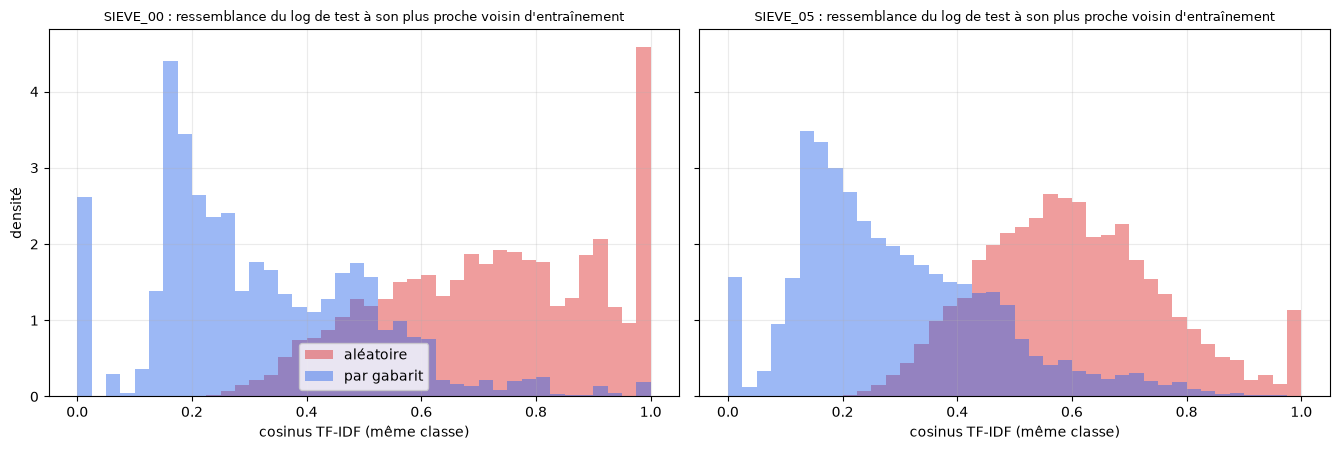

In [37]:
fig, ax = plt.subplots(1, 2, figsize=(13.5, 4.6), sharey=True)
for a, v in zip(ax, (0, 5)):
    for nm, col in (("aléatoire", RED), ("par gabarit", BLUE)): a.hist(nn_store[(v, nm)], bins=np.linspace(0, 1, 41), histtype="stepfilled", alpha=.45, color=col, label=nm, density=True)
    a.set_title(f"SIEVE_0{v} : ressemblance du log de test à son plus proche voisin d'entraînement", fontsize=9); a.set_xlabel("cosinus TF-IDF (même classe)"); a.grid(alpha=.25)
ax[0].set_ylabel("densité"); ax[0].legend(); plt.tight_layout(); fig.savefig(DIRS["figures"] / "03_fuite_gabarits.png", dpi=140); plt.show()

**Lecture (termes techniques).**
- **Découpage aléatoire** : à p = 0, le log de test a, **dans 24,0 % des cas**, un voisin d'entraînement de cosinus **≥ 0,90** (16,1 % ≥ 0,95) ; le cosinus **médian** est **0,739**. Le pic à 1,0 de la figure (rouge) montre de **vraies copies**.
- **Découpage par gabarit** : la part ≥ 0,90 tombe à **1,0 %** (0,5 % ≥ 0,95) et le cosinus médian à **0,276**.
- **À p = 0,5**, même un découpage aléatoire est moins fuyant (5,0 % ≥ 0,90, médiane 0,593) : la perturbation **masque en partie** la fuite, parce qu'elle éloigne les frères d'un même gabarit. Le découpage par gabarit reste net (0,2 % ≥ 0,90).
- Il **reste** une petite queue (1,0 % à p = 0, 0,2 % à p = 0,5) de logs de test très proches d'un log d'entraînement : ce sont soit des gabarits **sur-estimés** (2.2, risque dangereux) soit des gabarits d'une même classe qui se **ressemblent vraiment**. Elle est **mesurée**, donc **bornée**, et sera rapportée avec les résultats.

**En simple.** Avec un tirage au sort, un log de test sur quatre a un quasi-jumeau dans l'entraînement ; avec le découpage par gabarit, c'est un sur cent.

## 3.5 Première mesure de H5 : le score fermé est-il gonflé par la fuite ?

Avec un classifieur très simple (SVM linéaire sur TF-IDF de mots, SIEVE_00 seulement), on compare les deux découpages. **Ce n'est qu'un aperçu** ; la mesure formelle, avec intervalles de confiance et plusieurs graines, est faite à l'étape 7.

In [38]:
from sklearn.svm import LinearSVC
from sklearn.metrics import f1_score
def quick_f1(v, split_col):
    d = V[v].copy(); d["split"] = split_col; tv = TfidfVectorizer(token_pattern=r"[A-Za-z]{2,}", lowercase=True, sublinear_tf=True, min_df=2)
    Xtr = tv.fit_transform(d.loc[d.split == "train", "log"]); te = d[d.split == "test"]; m = LinearSVC(C=1.0).fit(Xtr, d.loc[d.split == "train", "category"])
    return f1_score(te["category"], m.predict(tv.transform(te["log"])), average="macro")
col_g = S[S["version"] == 0].sort_values("row")["split"].values; rnd0 = np.random.default_rng(SPLIT_SEED).choice(SPLIT_NAMES, size=100000, p=TARGET)
f_r, f_g = quick_f1(0, rnd0), quick_f1(0, col_g)
print(f"Macro-F1 (30 classes, SVM linéaire TF-IDF, SIEVE_00) : découpage aléatoire {f_r:.4f} | découpage par gabarit {f_g:.4f} | écart {f_r - f_g:+.4f}")

Macro-F1 (30 classes, SVM linéaire TF-IDF, SIEVE_00) : découpage aléatoire 0.9735 | découpage par gabarit 0.4580 | écart +0.5154


**Lecture et interprétation.** **0,9735** avec un découpage aléatoire, à **0,0002** de la valeur que l'article rapporte pour son SVM sur SIEVE_00 (**0,9737**, tableau 7 ; protocoles voisins mais non identiques : lui 75/25, nous 70/15/15, et un classifieur de même famille), contre **0,458** avec un découpage par gabarit : un écart de **+0,515**. **L'hypothèse H5 est confirmée, et très nettement** : l'essentiel du score fermé « excellent » vient de la **reconnaissance de gabarits déjà vus**, pas de la compréhension de ce qu'est un événement d'authentification ou de suppression de fichier.

**Prudence.** (1) Ce 0,458 est un **plancher** (un modèle linéaire sur des mots, avec 60 % de logs d'entraînement seulement) : un meilleur modèle fera mieux, et c'est l'enjeu des étapes suivantes. (2) Il mélange des classes à nombreux gabarits (palier A) et des classes à 2 ou 3 gabarits où apprendre à partir d'**un ou deux** gabarits est pratiquement impossible : on le détaillera **par palier**. (3) Le contrôle que le pipeline **fonctionne** est que le **même** code donne 0,9735 avec le découpage aléatoire, c'est-à-dire **ce que l'article annonce**.

**Conséquences pour tout le TP2.**
- **Bonne** : on sait maintenant que le jeu est **bien plus difficile** qu'il n'en a l'air ; les comparaisons de modèles auront du sens.
- **Mauvaise** : les chiffres publiés sur SIEVE (SVM 0,9737 à p = 0, BERT 0,9730, tableau 7) correspondent à un découpage **aléatoire 75/25 sans mention de gabarits** (V6) ; ils **surestiment** donc la généralisation à de nouveaux gabarits. Ce n'est pas une erreur de l'article : il annonce lui-même un test sur le CDS pour juger la généralisation (tableau 10, V7), mais ce test a ses propres limites (V5).
- **Parade** : toutes nos évaluations utilisent le découpage par gabarit, et on donnera **aussi** le chiffre « aléatoire » pour pouvoir comparer avec la littérature.

## 3.6 Bilan des étapes 1 à 3

**Ce qui est établi (mesuré).** Les six fichiers sont reçus, complets et conformes à l'article ; les logs sont **distincts** d'une version à l'autre ; 311 gabarits recomposés (contre 440), prudemment fusionnés ; les 4 confusions de l'article sont retrouvées parmi les 15 paires de classes les plus proches ; un découpage **par gabarit** fait chuter la ressemblance test / entraînement de **24 % à 1 %** (logs avec voisin à cosinus ≥ 0,90) et le score fermé de **0,97 à 0,46** ; test **scellé** ; seuils de succès écrits avant les modèles.

**Ce qui est approximatif (dit honnêtement).** Les gabarits sont reconstruits ; 12 classes sur 30 n'ont pas assez de gabarits pour un découpage strict en trois jeux (paliers B et C) ; la taxonomie n'est pas validée par un expert ; le jeu CDS manque, donc E5 est en suspens.

**Ce qui reste non vérifié** (registre) : V11 (licence) ; V12 (références des méthodes d'incertitude) ; l'accord exact entre le vocabulaire de l'article (118 333 à 164 839 jetons, tokenisation différente) et le nôtre.

**Registre (suite).**

| N° | Affirmation | Source | Niveau |
|---|---|---|---|
| V20 | Vocabulaire (mots d'au moins 2 lettres, minuscules) : de 31 627 (p = 0) à 66 385 (p = 0,5) ; part de mots absents de SIEVE_00 : 4,9 % à 14,6 % | Calcul | calcul |
| V21 | Reconstruction des gabarits : 311 trouvés (τ = 0,05, Jaccard ≥ 0,8) contre 440 annoncés ; les petites classes sont retrouvées presque exactement ; `ids-alert` 13 contre 93 | Calcul + tableau 1 | calcul (approximation) |
| V22 | Les 4 confusions de l'article (V6) sont aux rangs 1, 5, 11 et 15 des 435 paires de classes par cosinus des centroïdes TF-IDF | Calcul | calcul |
| V23 | Plus proche voisin d'entraînement (cosinus ≥ 0,90) : 24,0 % (aléatoire) contre 1,0 % (par gabarit) à p = 0 ; 5,0 % contre 0,2 % à p = 0,5 | Calcul | calcul |
| V24 | SVM linéaire TF-IDF, SIEVE_00, 30 classes : macro-F1 0,9735 (aléatoire) contre 0,458 (par gabarit) ; aperçu, non définitif | Calcul | calcul |
| V25 | L'article rapporte, sur SIEVE_00 (découpage 75/25), un macro-F1 de 0,9737 pour son SVM et 0,9730 pour BERT (tableau 7) ; notre aléatoire 0,9735 s'en approche à 0,0002 | Article, tableau 7 + calcul | texte intégral + calcul |

**Prochaine étape.** Étape 4 : prétraitement des logs (quoi masquer, quoi garder), puis étapes 5 et 6.

<!-- REV-3.6 -->
**Ajout après l'état de l'art.** La section **3.7** mesure la même référence sous **quatre protocoles** de découpage (aléatoire, simple, par groupes, imbriquée) : le plancher par gabarit est d'environ 0,5 (de 0,42 à 0,58), l'écart-type entre plis d'environ 0,04.

<!-- REV-3.7 -->
## 3.7 Quatre protocoles de découpage pour une même mesure (ajout après l'état de l'art)

**Pourquoi.** Le découpage par gabarit de 3.2 est **un** découpage : le résultat dépend des gabarits tombés en validation (36 pour le palier A). Pour savoir si nos conclusions tiennent, on mesure **la même chose** (macro-F1 du classifieur linéaire de référence sur les classes du palier A, SIEVE_00) sous **quatre protocoles**, définis en 0.1b.1 :

| Protocole | Principe |
|---|---|
| **P0** aléatoire, 5 plis | on mélange les logs : **témoin négatif** qui montre la fuite |
| **P1** simple par gabarit | entraînement puis validation strictes du découpage de 3.2 |
| **P2** par groupes, 5 plis | un gabarit n'est jamais coupé ; cinq estimations |
| **P3** imbriquée par groupes | boucle intérieure (3 plis) qui règle C, boucle extérieure (5 plis) qui évalue |

**Règles.** Le **test scellé n'est pas utilisé** : tout se passe sur l'entraînement et la validation. Tout ce qui apprend (TF-IDF, classifieur) est **ajusté sur l'entraînement du pli seul**. On vérifie l'absence de fuite par un `assert` (aucun gabarit des deux côtés) et par la part de logs de test ayant un **quasi-jumeau** (cosinus d'au moins 0,90) dans l'entraînement. Les résultats sont gardés en cache.

(résultats rechargés depuis le cache)
                                              protocole  évaluations macro-F1 palier A pire / meilleur pli macro-F1 classes présentes quasi-jumeaux (cos. >= 0,90)
                          P0 aléatoire, 5 plis (témoin)            5   0.9872 ± 0.0011       0.986 / 0.989                     0.9645                        25.4%
     P1 simple par gabarit (entraînement -> validation)            1   0.4220 ± 0.0000       0.422 / 0.422                     0.4220                         0.0%
                                 P2 par groupes, 5 plis            5   0.5070 ± 0.0415       0.477 / 0.575                     0.4574                         0.0%
P3 imbriquée par groupes (5 x 3, C réglé à l'intérieur)            5   0.5105 ± 0.0448       0.480 / 0.587                     0.4655                         0.0%

C choisi à l'intérieur, par pli extérieur : [0.1, 0.3, 0.1, 3.0, 0.1] | score interne moyen - score extérieur moyen (optimisme du réglage) : -0.02

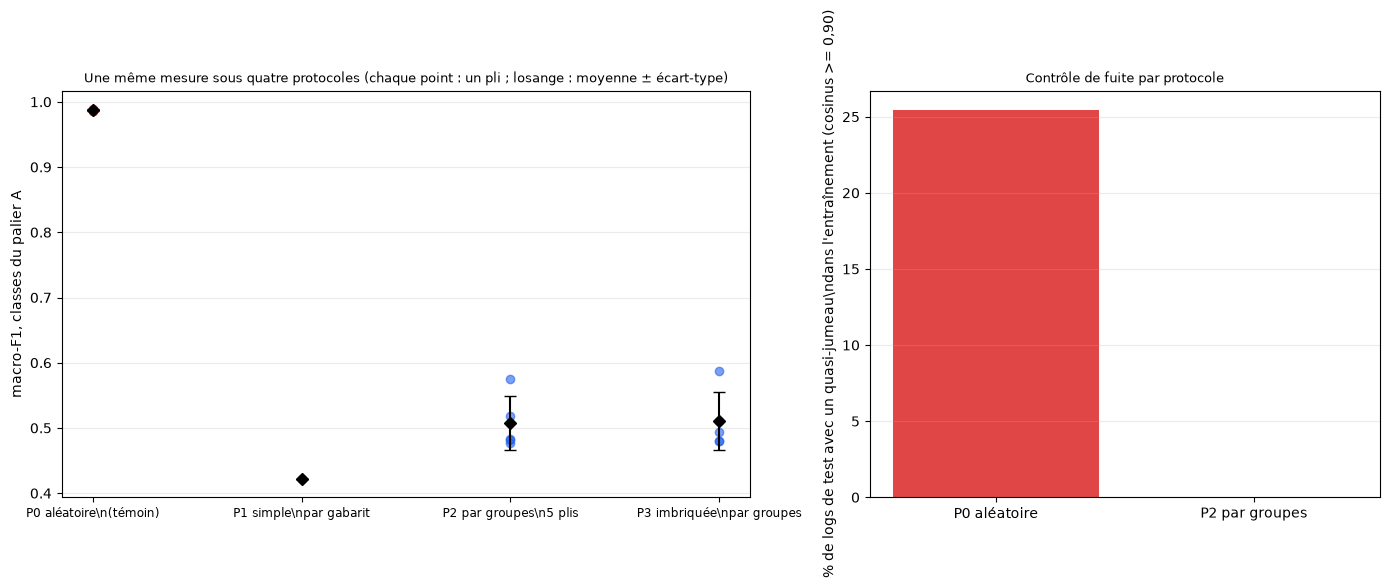

In [39]:
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold
CACHE3 = DIRS["results"] / "cache_step3"; CACHE3.mkdir(exist_ok=True)
P37 = {"version": 0, "k": 5, "k_inner": 3, "C_grid": [0.1, 0.3, 1.0, 3.0], "seed": int(SPLIT_SEED), "tfidf": "jetons [A-Za-z]{2,}, minuscules, min_df=2, sous-linéaire"}
key37 = hashlib.sha256(json.dumps([P37, DATA_ID, meta["splits_sha256"], "s3p37v1"], sort_keys=True).encode()).hexdigest()[:16]; f37 = CACHE3 / f"{key37}.json"
d0 = S[(S["version"] == P37["version"]) & S["split"].isin(["train", "val"])].reset_index(drop=True)          # le TEST scellé n'est JAMAIS utilisé ici
TXT37 = V[P37["version"]]["log"].values[d0["row"].values]; Y37 = d0["category"].values; G37 = d0["group"].values.astype(int)
A_CLASSES = [c for c in PAPER_CLASSES if tiers[c][0] == "A"]
def mf1(y_t, y_p, only_A):
    labs = [c for c in (A_CLASSES if only_A else PAPER_CLASSES) if c in set(y_t)]
    return float(f1_score(y_t, y_p, average="macro", labels=labs))
def tfidf37(txt):
    tv = TfidfVectorizer(token_pattern=r"[A-Za-z]{2,}", lowercase=True, sublinear_tf=True, min_df=2, dtype=np.float32); return tv, tv.fit_transform(txt)       # ajusté sur l'entraînement SEUL, à chaque fois
def fit_eval(tr_i, te_i, C):
    tv, Xtr = tfidf37(TXT37[tr_i]); return LinearSVC(C=C).fit(Xtr, Y37[tr_i]).predict(tv.transform(TXT37[te_i]))
X_ALL = TfidfVectorizer(token_pattern=r"[A-Za-z]{2,}", lowercase=True, sublinear_tf=True, min_df=2, dtype=np.float32).fit_transform(TXT37)           # uniquement pour l'audit de fuite
def leak_share(tr_i, te_i):
    best = np.zeros(len(te_i))
    for c in PAPER_CLASSES:
        pos = np.where(Y37[te_i] == c)[0]; rc = tr_i[Y37[tr_i] == c]
        if len(pos) == 0 or len(rc) == 0: continue
        best[pos] = np.asarray((X_ALL[te_i[pos]] @ X_ALL[rc].T).tocsr().max(axis=1).todense()).ravel()
    return float((best >= 0.90).mean())
def rec(tr_i, te_i, p, **kw): return {"f1_A": mf1(Y37[te_i], p, True), "f1_all": mf1(Y37[te_i], p, False), "fuite_090": leak_share(tr_i, te_i), **kw}
if f37.exists(): R37 = json.loads(f37.read_text()); print("(résultats rechargés depuis le cache)")
else:
    t0 = time.perf_counter(); R37 = {"P0": [], "P1": None, "P2": [], "P3": []}
    for tr_i, te_i in StratifiedKFold(P37["k"], shuffle=True, random_state=P37["seed"]).split(TXT37, Y37): R37["P0"].append(rec(tr_i, te_i, fit_eval(tr_i, te_i, 1.0)))
    folds = list(StratifiedGroupKFold(P37["k"], shuffle=True, random_state=P37["seed"]).split(TXT37, Y37, G37))
    for tr_i, te_i in folds:
        assert not (set(G37[tr_i]) & set(G37[te_i])), "un gabarit se retrouve des deux côtés"
        R37["P2"].append(rec(tr_i, te_i, fit_eval(tr_i, te_i, 1.0)))
    for tr_i, te_i in folds:
        inner = list(StratifiedGroupKFold(P37["k_inner"], shuffle=True, random_state=P37["seed"] + 1).split(TXT37[tr_i], Y37[tr_i], G37[tr_i])); sc = {C: [] for C in P37["C_grid"]}
        for itr, iva in inner:
            a, b = tr_i[itr], tr_i[iva]; tv, Xa = tfidf37(TXT37[a]); Xb = tv.transform(TXT37[b])
            for C in sc: sc[C].append(mf1(Y37[b], LinearSVC(C=C).fit(Xa, Y37[a]).predict(Xb), True))
        bestC = max(sc, key=lambda C: np.mean(sc[C])); R37["P3"].append(rec(tr_i, te_i, fit_eval(tr_i, te_i, bestC), C=bestC, interne=float(np.mean(sc[bestC]))))
    tr1 = np.where(d0["split"].values == "train")[0]; va1 = np.where((d0["split"].values == "val") & (~d0["val_leaky"].values.astype(bool)))[0]
    R37["P1"] = rec(tr1, va1, fit_eval(tr1, va1, 1.0)); R37["secondes"] = round(time.perf_counter() - t0); f37.write_text(json.dumps(R37))
def summ(name, lab, L):
    a = np.array([r["f1_A"] for r in L]); b = np.array([r["f1_all"] for r in L]); u = np.array([r["fuite_090"] for r in L])
    return {"protocole": lab, "évaluations": len(L), "macro-F1 palier A": f"{a.mean():.4f} ± {a.std(ddof=1) if len(a) > 1 else 0:.4f}", "pire / meilleur pli": f"{a.min():.3f} / {a.max():.3f}", "macro-F1 classes présentes": f"{b.mean():.4f}", "quasi-jumeaux (cos. >= 0,90)": f"{u.mean():.1%}", "_moy": a.mean()}
t37 = pd.DataFrame([summ("P0", "P0 aléatoire, 5 plis (témoin)", R37["P0"]), summ("P1", "P1 simple par gabarit (entraînement -> validation)", [R37["P1"]]), summ("P2", "P2 par groupes, 5 plis", R37["P2"]), summ("P3", "P3 imbriquée par groupes (5 x 3, C réglé à l'intérieur)", R37["P3"])])
pd.set_option("display.width", 250); print(t37.drop(columns="_moy").to_string(index=False)); t37.drop(columns="_moy").to_csv(DIRS["results"] / "step3_protocoles.csv", index=False)
opt = np.mean([r["interne"] for r in R37["P3"]]) - np.mean([r["f1_A"] for r in R37["P3"]])
print(f"\nC choisi à l'intérieur, par pli extérieur : {[r['C'] for r in R37['P3']]} | score interne moyen - score extérieur moyen (optimisme du réglage) : {opt:+.4f}")
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1.35, 1]})
for k, (nm, L, col) in enumerate((("P0 aléatoire\\n(témoin)", R37["P0"], RED), ("P1 simple\\npar gabarit", [R37["P1"]], BLUE), ("P2 par groupes\\n5 plis", R37["P2"], BLUE), ("P3 imbriquée\\npar groupes", R37["P3"], BLUE))):
    a = [r["f1_A"] for r in L]; ax[0].scatter([k] * len(a), a, color=col, alpha=.6, s=36, zorder=3); ax[0].errorbar(k, np.mean(a), yerr=(np.std(a, ddof=1) if len(a) > 1 else 0), fmt="D", color="k", capsize=4, zorder=4)
ax[0].set_xticks(range(4)); ax[0].set_xticklabels(["P0 aléatoire\\n(témoin)", "P1 simple\\npar gabarit", "P2 par groupes\\n5 plis", "P3 imbriquée\\npar groupes"], fontsize=8.5); ax[0].set_ylabel("macro-F1, classes du palier A"); ax[0].set_title("Une même mesure sous quatre protocoles (chaque point : un pli ; losange : moyenne ± écart-type)", fontsize=9); ax[0].grid(axis="y", alpha=.25)
for k, (nm, L, col) in enumerate((("P0", R37["P0"], RED), ("P2", R37["P2"], BLUE))): ax[1].bar(k, np.mean([r["fuite_090"] for r in L]) * 100, color=col, alpha=.85)
ax[1].set_xticks([0, 1]); ax[1].set_xticklabels(["P0 aléatoire", "P2 par groupes"]); ax[1].set_ylabel("% de logs de test avec un quasi-jumeau\\ndans l'entraînement (cosinus >= 0,90)"); ax[1].set_title("Contrôle de fuite par protocole", fontsize=9); ax[1].grid(axis="y", alpha=.25)
plt.tight_layout(); fig.savefig(DIRS["figures"] / "03_protocoles.png", dpi=140); plt.show()

**Lecture (termes techniques).**
- **Le témoin montre la fuite.** Avec des plis tirés au hasard : macro-F1 de **0,987 ± 0,001** et **25,4 %** des logs de test ont un quasi-jumeau d'entraînement ; avec des plis par gabarit : **0,507 ± 0,042** (P2) et **0,0 %** de quasi-jumeaux (0,2 % dans un pli). La chute de près de moitié vient donc du **découpage**, pas du modèle : **H5 est confirmée sous les quatre protocoles**.
- **L'imbrication ne change presque rien ici.** P3 donne **0,511 ± 0,045** contre 0,507 pour P2 : un écart de +0,004, très inférieur à l'écart-type entre plis (0,04). Le C choisi à l'intérieur change d'un pli à l'autre (0,1 ; 0,3 ; 0,1 ; 3 ; 0,1) : **pour ce modèle sur ce jeu, le réglage de C compte très peu**, donc le biais de sélection que l'imbrication protège est faible. Elle reste le protocole **prudent**, et le sera davantage pour des réglages plus sensibles (seuils de rejet, dimension de la SVD). Le « score interne moins score extérieur » est négatif (−0,025) parce que les plis intérieurs s'entraînent sur moins de logs : ce n'est **pas** une mesure directe de l'optimisme.
- **La validation simple est sur le versant pessimiste.** P1 (0,422) est **plus bas que chacun des cinq plis** de P2 (0,477 à 0,575) : la façon dont les 36 gabarits de validation sont tombés et un entraînement plus petit y contribuent. La **bonne mesure de l'incertitude** est donc l'écart entre plis (environ 0,04), pas l'intervalle d'un seul découpage.
- **Conséquence pour Q3.** Le plancher de la classification fermée par gabarit est d'environ **0,5** (de 0,42 à 0,58 selon les gabarits) ; **un écart inférieur à environ 0,04 ou 0,05 entre deux méthodes est indétectable** avec ce nombre de gabarits : c'est la limite à garder en tête aux étapes 6 et 7, où les mêmes quatre protocoles s'appliquent aux comparaisons plat/hiérarchique et aux scores d'inconnu.

**Registre (suite).**

| N° | Affirmation | Source | Niveau |
|---|---|---|---|
| V80 | Quatre protocoles (SIEVE_00, SVM linéaire TF-IDF, classes du palier A) : aléatoire 5 plis 0,9872 ± 0,0011 (25,4 % de quasi-jumeaux) ; simple par gabarit 0,4220 ; par groupes 5 plis 0,5070 ± 0,0415 (0,0 % de quasi-jumeaux) ; imbriquée 5 x 3 : 0,5105 ± 0,0448, C choisi 0,1 / 0,3 / 0,1 / 3 / 0,1 | Calcul (3.7) | calcul |

---
# Étape 4 : Prétraitement des logs

**Pourquoi cette étape existe.** Avant de transformer un log en nombres, on décide **quoi lui faire subir** : mettre en minuscules ? masquer les adresses IP ? garder la ponctuation ? couper les logs trop longs ? Chaque choix peut **aider** (en retirant du bruit) ou **nuire** (en retirant de l'information). Les recettes de manuel du texte naturel (mots vides, minuscules, lemmatisation) ont été conçues pour des **phrases**, pas pour des journaux de machines. On ne les applique donc pas par habitude : **on mesure chaque choix**, avec une règle écrite à l'avance.

**Concepts.**
- **Normalisation** : mettre le texte sous une forme standard (ici : Unicode NFKC, qui unifie par exemple l'espace insécable et l'espace ordinaire).
- **Masquage typé** : remplacer chaque *champ variable* par un jeton qui garde sa **nature** (`iptok` pour une adresse IP, `timetok` pour une heure, `numtok` pour un nombre). Le modèle apprend alors « il y a une adresse IP ici », pas « il y a *42.101.106.249* ».
- **Jeton (*token*)** : une unité de texte (un mot, un symbole).
- **Mots vides (*stopwords*)** : mots très fréquents (« the », « is »...) qu'on retire parfois ; dans un log, « from » ou « on » peuvent justement structurer l'événement.
- **Troncature** : ne garder que les N premiers caractères.

**En simple.** Un log, c'est une ligne comme `[Thu Dec 17 02:47:06 1992] [client 42.101.106.249] authentication failure`. L'heure et l'adresse changent à chaque ligne et ne disent rien du **type** d'événement ; « authentication failure » le dit. Le prétraitement doit aider le modèle à regarder ce qui compte. Mais attention : retirer l'heure peut aussi retirer le **format** de l'heure, qui est un indice du *logiciel* qui a écrit le log.

## 4.1 Le module de normalisation

Les règles sont **déterministes** : elles n'apprennent **rien** des données (pas de vocabulaire, pas de statistique), donc les appliquer au jeu de test ne crée **aucune fuite**. Le module est écrit dans `src/tp2_logtext.py` pour être réutilisable tel quel sur Kaggle et Colab.

In [40]:
MODULE_SRC = r'''"""Normalisation de logs de sécurité (TP2, étape 4).

Règles DÉTERMINISTES : aucune statistique n'est apprise sur les données, donc les appliquer au test ne crée pas de fuite.
"""
import re
import unicodedata

MONTHS = "Jan|Feb|Mar|Apr|May|Jun|Jul|Aug|Sep|Oct|Nov|Dec"
DAYS = "Mon|Tue|Wed|Thu|Fri|Sat|Sun"
PATTERNS = {   # ordre d'application : du plus spécifique au plus général
    "time": [
        re.compile(rf"\b(?:{DAYS})\s+(?:{MONTHS})\s+\d{{1,2}}\s+\d{{2}}:\d{{2}}:\d{{2}}\s+\d{{4}}\b"),
        re.compile(r"\b\d{4}-\d{2}-\d{2}[ T]\d{2}:\d{2}:\d{2}(?:[.,]\d+)?\b"),
        re.compile(rf"\b(?:{MONTHS})\s+\d{{1,2}}\s+\d{{2}}:\d{{2}}:\d{{2}}\b"),
        re.compile(r"\b\d{1,2}[./]\d{1,2}\s+\d{2}:\d{2}:\d{2}\b"),
        re.compile(r"\b\d{4}-\d{2}-\d{2}\b"),
        re.compile(r"\b\d{2}:\d{2}:\d{2}\b"),
    ],
    "uuid": [re.compile(r"\b[0-9a-fA-F]{8}-(?:[0-9a-fA-F]{4}-){3}[0-9a-fA-F]{12}\b")],
    "mac": [re.compile(r"\b(?:[0-9A-Fa-f]{2}[:-]){5}[0-9A-Fa-f]{2}\b")],
    "ip": [re.compile(r"\b\d{1,3}(?:\.\d{1,3}){3}\b")],
    "url": [re.compile(r"(?i)\b(?:https?|ftp)://[^\s\"'<>]+")],
    "email": [re.compile(r"[\w.+-]+@[\w-]+(?:\.[\w-]+)+")],
    "hex": [re.compile(r"\b0x[0-9a-fA-F]+\b"), re.compile(r"\b(?=[0-9a-fA-F]*\d)(?=[0-9a-fA-F]*[a-fA-F])[0-9a-fA-F]{8,}\b")],
    "num": [re.compile(r"\b\d+(?:\.\d+)?\b")],
}
TOKENS = {"time": " timetok ", "uuid": " uuidtok ", "mac": " mactok ", "ip": " iptok ", "url": " urltok ", "email": " emailtok ", "hex": " hextok ", "num": " numtok "}
ORDER = ["time", "uuid", "mac", "ip", "url", "email", "hex", "num"]
WORD_RE = re.compile(r"[A-Za-z]{2,}")
WORD_PUNCT_RE = re.compile(r"[A-Za-z]{2,}|[^\sA-Za-z\d]")
CTRL_RE = re.compile(r"[\x00-\x08\x0b\x0c\x0e-\x1f\x7f]")
SKLEARN_STOP = None


def normalize(text, mask=(), unicode_norm=True):
    """Texte -> texte : Unicode NFKC, retrait des caractères de contrôle, puis masquage typé des champs variables listés dans `mask`."""
    t = text.rstrip("\r\n")
    if unicode_norm:
        t = unicodedata.normalize("NFKC", t)
        t = CTRL_RE.sub(" ", t)
    for kind in ORDER:
        if kind in mask:
            for pat in PATTERNS[kind]:
                t = pat.sub(TOKENS[kind], t)
    return t


def tokenize(text, mask=(), lower=True, punct=False, stop=False, trunc=None, unicode_norm=True):
    """Texte -> liste de jetons. mask : types de champs remplacés par un jeton (ex. ('ip', 'time', 'num'))."""
    t = text[:trunc] if trunc else text
    t = normalize(t, mask, unicode_norm)
    toks = (WORD_PUNCT_RE if punct else WORD_RE).findall(t)
    if lower:
        toks = [w.lower() for w in toks]
    if stop:
        global SKLEARN_STOP
        if SKLEARN_STOP is None:
            from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
            SKLEARN_STOP = frozenset(ENGLISH_STOP_WORDS)
        toks = [w for w in toks if w.lower() not in SKLEARN_STOP]
    return toks
'''
(PROJECT_ROOT / "src" / "tp2_logtext.py").write_text(MODULE_SRC)
MODULE_HASH = hashlib.sha256(MODULE_SRC.encode()).hexdigest()[:12]
sys.path.insert(0, str(PROJECT_ROOT / "src"))
import importlib, tp2_logtext; importlib.reload(tp2_logtext)
from tp2_logtext import normalize, tokenize
print("Module src/tp2_logtext.py écrit (hash", MODULE_HASH + ")")

Module src/tp2_logtext.py écrit (hash 2b5360ac2128)


## 4.2 Tests unitaires : on teste avant de s'en servir

Chaque règle a un cas de test avec le résultat attendu. Deux pièges sont couverts exprès : (1) **l'ordre des règles** compte (une date doit être reconnue **avant** les nombres, sinon `17:04:54` deviendrait trois `numtok`) ; (2) un nombre **collé à des lettres** (`abc123`) n'est pas un champ numérique.

In [41]:
def T(inp, mask, expected, **kw):
    out = normalize(inp, mask, **kw).split(); exp = expected.split()
    assert out == exp, f"{inp!r} -> {out} (attendu {exp})"
T("[Thu Dec 17 02:47:06 1992] [error] [client 42.101.106.249] user bob", ("time", "ip"), "[ timetok ] [error] [client iptok ] user bob")
T("2024-12-08 07:35:01,000000 prepare.java:765", ("time", "num"), "timetok prepare.java: numtok")
T("Aug 17 17:04:54 ball su[10832]: failed", ("time", "num"), "timetok ball su[ numtok ]: failed")
T("id 3f2504e0-4f89-41d3-9a0c-0305e82c3301 mac 00:1A:2b:3C:4d:5E", ("uuid", "mac", "num"), "id uuidtok mac mactok")
T("see http://a.b/c?d=1 or mail x.y@z.com", ("url", "email"), "see urltok or mail emailtok")
T("addr 0xdeadbeef and deadbeef12 and cafe", ("hex",), "addr hextok and hextok and cafe")
T("size 4096 bytes, ratio 0.5", ("num",), "size numtok bytes, ratio numtok")
T("abc123 stays", ("num",), "abc123 stays")                    # un nombre collé à des lettres n'est pas un champ numérique seul
T("keep 42.101.106.249", (), "keep 42.101.106.249")            # rien n'est masqué sans demande
assert normalize("a b\x07c\r\n") == "a b c"                  # NFKC : espace insécable -> espace ; contrôle -> espace ; CRLF retiré
assert tokenize("Failed PASSWORD for 12 users", lower=True) == ["failed", "password", "for", "users"]
assert tokenize("Failed PASSWORD", lower=False) == ["Failed", "PASSWORD"]
assert tokenize("a1=bc; fail", punct=True) == ["=", "bc", ";", "fail"]
assert tokenize("the user is here", stop=True) == ["user"]
assert tokenize("abcdefghij", trunc=4) == ["abcd"]
m = ("time", "ip", "num"); s = "client 42.101.106.249 at Aug 17 17:04:54 size 12"
assert normalize(normalize(s, m), m).split() == normalize(s, m).split(), "idempotence"
print("Tests unitaires : 16 contrôles réussis (masques typés, ordre des règles, nombres collés, idempotence, majuscules, mots vides, troncature).")

Tests unitaires : 16 contrôles réussis (masques typés, ordre des règles, nombres collés, idempotence, majuscules, mots vides, troncature).


**Lecture.** Les seize contrôles réussissent, dont l'**idempotence** (appliquer deux fois le masquage donne le même résultat qu'une fois : sinon un log déjà traité serait modifié de nouveau).

## 4.3 Parcours d'un exemple, étape par étape

In [42]:
ex = V[0]["log"].iloc[int(np.where(V[0]["category"].values == "authentication-failed")[0][0])]
ex2 = V[3]["log"].iloc[int(np.where(V[3]["category"].values == "connection-closed")[0][5])]
for nm, e in (("SIEVE_00, authentication-failed", ex), ("SIEVE_03, connection-closed", ex2)):
    print(f"\n--- {nm}\nbrut      : {e}")
    print("masqué    :", normalize(e, ("time", "ip", "num")).strip())
    print("mots      :", tokenize(e))
    print("structure :", tokenize(e, mask=("time", "ip", "hex", "num"), punct=True))


--- SIEVE_00, authentication-failed
brut      : [Thu Dec 17 02:47:06 1992] [error] [client 42.101.106.249] user barnesandrew: authentication failure for "/different/paper.mov/responsibility": Password Mismatch
masqué    : [ timetok ] [error] [client  iptok ] user barnesandrew: authentication failure for "/different/paper.mov/responsibility": Password Mismatch
mots      : ['thu', 'dec', 'error', 'client', 'user', 'barnesandrew', 'authentication', 'failure', 'for', 'different', 'paper', 'mov', 'responsibility', 'password', 'mismatch']
structure : ['[', 'timetok', ']', '[', 'error', ']', '[', 'client', 'iptok', ']', 'user', 'barnesandrew', ':', 'authentication', 'failure', 'for', '"', '/', 'different', '/', 'paper', '.', 'mov', '/', 'responsibility', '"', ':', 'password', 'mismatch']

--- SIEVE_03, connection-closed
brut      : Aug 01 07:06:56 result rshd[67325]: Connection from 27.217.215.114 against the law  on illegal port
masqué    : timetok  result rshd[ numtok ]: Connection from  i

**Lecture.** Dans le premier exemple (SIEVE_00, `authentication-failed`), la version *brute* contient une date complète (`[Thu Dec 17 02:47:06 1992]`) et une adresse IP ; la version « mots » garde `thu` et `dec` (des noms de jour et de mois, donc du bruit) mais perd les chiffres ; la version « structure » les remplace par `timetok` et `iptok` et garde les crochets, les deux-points et les guillemets. Dans le second (SIEVE_03, perturbé), la phrase « against the law » remplace un mot du gabarit d'origine : c'est la **perturbation SPICE** de p > 0.

## 4.4 Quels champs variables contiennent les logs ?

Pour savoir **ce que le masquage toucherait**, on compte, sur 6 000 logs de SIEVE_00 (200 par classe), combien contiennent chaque type de champ.

In [43]:
from tp2_logtext import PATTERNS, ORDER
samp_f = V[0].groupby("category", group_keys=False).sample(200, random_state=CONFIG["seed"])
rows = []
for kind in ORDER:
    cnt = []
    for s_ in samp_f["log"]:
        t_ = s_; n_ = 0
        for k2 in ORDER[:ORDER.index(kind) + 1]:          # on respecte l'ordre d'application des règles (un champ déjà masqué n'est pas recompté)
            for pat in PATTERNS[k2]:
                t_, m_ = pat.subn(" ", t_)
                if k2 == kind: n_ += m_
        cnt.append(n_)
    cnt = np.array(cnt); rows.append({"type de champ": kind, "logs contenant au moins un champ": f"{(cnt > 0).mean():.1%}", "champs par log (moyenne)": round(float(cnt.mean()), 2)})
print(pd.DataFrame(rows).to_string(index=False))

type de champ logs contenant au moins un champ  champs par log (moyenne)
         time                            92.0%                      1.02
         uuid                             4.1%                      0.08
          mac                             1.8%                      0.03
           ip                            40.2%                      0.68
          url                             0.9%                      0.01
        email                             1.1%                      0.01
          hex                            10.6%                      0.17
          num                            89.0%                      3.97


**Lecture (termes techniques).**
- **Presque tous les logs contiennent une heure (92 %, 1,02 par log) et des nombres (89 %, environ 4 par log)** : ce sont les champs variables **par excellence**. Les masquer retire un grand volume de valeurs distinctes sans rien changer à la phrase-type.
- **Adresses IP : 40 % des logs** (0,68 par log). **Hexadécimaux : 10,6 %**, UUID : 4,1 %, adresses MAC : 1,8 %, courriels : 1,1 %, URL : 0,9 %. Ces derniers sont rares : leur masquage n'affectera presque aucun log.

**Conséquence.** On s'attend à ce que le masquage de l'heure, des nombres et des IP ait de l'effet (il touche presque tout) et que celui des UUID, MAC, courriels et URL n'en ait quasiment pas.

## 4.5 Protocole d'expérience

**Tout est mesuré avec le même classifieur de référence** (SVM linéaire sur TF-IDF de mots, minimum 2 documents par mot), pour isoler l'effet du prétraitement. **Une idée à la fois** par rapport à la référence V0 (« mots, minuscules »).

**Données de mesure (fixées d'avance).**
- **Entraînement** : 333 logs par classe et par version, soit **59 940** logs (échantillon de l'entraînement du découpage par gabarit).
- **Validation** : 133 logs par classe et par version, soit **23 940** logs.
- **Mesure principale** : macro-F1 des **18 classes du palier A**, dont les gabarits de validation sont **vraiment jamais vus** (14 364 logs répartis dans **36 gabarits**).
- **Intervalles de confiance** : bootstrap **par gabarit** (on rééchantillonne des **gabarits entiers**, 400 fois, jamais des logs isolés : deux logs d'un même gabarit ne sont pas indépendants, et les rééchantillonner séparément donnerait des intervalles **trop étroits**).

**Variantes.** V1 masquage de tous les types de champs ; V2 ponctuation et symboles gardés comme jetons ; V3 les deux ; V4 casse conservée ; V5 mots vides anglais retirés (scikit-learn, 318 mots) ; V6 et V7 troncature à 128 et 256 caractères (utile pour choisir la fenêtre d'un encodeur) ; V8 masquage de l'heure et de l'IP seulement ; V9 tout cumulé (masques, ponctuation, casse, mots vides).

In [44]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import f1_score
CACHE4 = DIRS["results"] / "cache_step4"; CACHE4.mkdir(exist_ok=True)
SPLITS_SHA = json.loads((DIRS["data"] / "splits_v1_meta.json").read_text())["splits_sha256"]
def sample_rows(split, n_per_class, seed0):
    out = []
    for v in range(6):
        d = S[(S.version == v) & (S.split == split)]
        for k, cl in enumerate(PAPER_CLASSES):
            g = d[d.category == cl]; out.append(g.sample(min(len(g), n_per_class), random_state=seed0 + 100 * v + k))
    return pd.concat(out)
tr_rows = sample_rows("train", 333, int(CONFIG["seed"])); va_rows = sample_rows("val", 133, int(CONFIG["seed"]) + 7)
tr_rows = tr_rows.reset_index(drop=True); va_rows = va_rows.reset_index(drop=True)
LOG = {v: V[v]["log"].values for v in range(6)}
tr_text = [LOG[v][r] for v, r in zip(tr_rows.version, tr_rows.row)]; va_text = [LOG[v][r] for v, r in zip(va_rows.version, va_rows.row)]
ytr = tr_rows.category.values; yva = va_rows.category.values
CI = {c: i for i, c in enumerate(PAPER_CLASSES)}; yva_i = np.array([CI[c] for c in yva]); tierA = np.array([tiers[c][0] == "A" for c in PAPER_CLASSES])
mask_A_rows = tierA[yva_i]; grp_va = va_rows.group.values; ver_va = va_rows.version.values
print(f"Entraînement : {len(tr_text):,} logs (333 par classe et par version) ; validation : {len(va_text):,} logs ; dont palier A : {int(mask_A_rows.sum()):,} logs dans {len(set(grp_va[mask_A_rows]))} gabarits")
def macro_f1_from_conf(C, classes_mask):
    # C : (..., 30, 30) matrice vrai x prédit ; macro-F1 sur les classes de classes_mask (vraies ou prédites)
    tp = np.einsum("...ii->...i", C); fn = C.sum(-1) - tp; fp = C.sum(-2) - tp
    f1 = 2 * tp / np.maximum(2 * tp + fp + fn, 1); return f1[..., classes_mask].mean(-1)
def group_conf(pred_i, rows_mask):
    gs = grp_va[rows_mask]; ug = np.unique(gs); M = np.zeros((len(ug), 900)); idx = {g: k for k, g in enumerate(ug)}
    for g, t, p in zip(gs, yva_i[rows_mask], pred_i[rows_mask]): M[idx[g], t * 30 + p] += 1
    return M
NBOOT = 400; boot_rng = np.random.default_rng(CONFIG["seed"]); ug_A = np.unique(grp_va[mask_A_rows]); BW = boot_rng.multinomial(len(ug_A), np.ones(len(ug_A)) / len(ug_A), size=NBOOT).astype(float)
def boot_delta(predA, predB):
    MA, MB = group_conf(predA, mask_A_rows), group_conf(predB, mask_A_rows)
    fa = macro_f1_from_conf((BW @ MA).reshape(NBOOT, 30, 30), tierA); fb = macro_f1_from_conf((BW @ MB).reshape(NBOOT, 30, 30), tierA); d = fb - fa
    return float(d.mean()), float(np.quantile(d, .025)), float(np.quantile(d, .975))
print("Outils prêts : bootstrap par GABARIT (on rééchantillonne des gabarits entiers, pas des logs, car deux logs d'un même gabarit ne sont pas indépendants).")

Entraînement : 59,940 logs (333 par classe et par version) ; validation : 23,940 logs ; dont palier A : 14,364 logs dans 36 gabarits
Outils prêts : bootstrap par GABARIT (on rééchantillonne des gabarits entiers, pas des logs, car deux logs d'un même gabarit ne sont pas indépendants).


In [45]:
BASE = dict(mask=(), lower=True, punct=False, stop=False, trunc=None)
MASK_ALL = ("time", "uuid", "mac", "ip", "url", "email", "hex", "num")
VARIANTS = {
    "V0 référence (mots, minuscules)":            dict(BASE),
    "V1 + champs masqués par type":                dict(BASE, mask=MASK_ALL),
    "V2 + ponctuation et symboles gardés":         dict(BASE, punct=True),
    "V3 + masques ET ponctuation":                 dict(BASE, mask=MASK_ALL, punct=True),
    "V4 casse conservée":                          dict(BASE, lower=False),
    "V5 mots vides anglais retirés":               dict(BASE, stop=True),
    "V6 tronqué à 128 caractères":                 dict(BASE, trunc=128),
    "V7 tronqué à 256 caractères":                 dict(BASE, trunc=256),
    "V8 masques seulement IP et heures":           dict(BASE, mask=("time", "ip")),
    "V9 tout cumulé : masques, ponctuation, casse, mots vides": dict(BASE, mask=MASK_ALL, punct=True, lower=False, stop=True),
}
print(pd.DataFrame([{"variante": k, **{kk: (",".join(vv) if isinstance(vv, tuple) and vv else vv) for kk, vv in v.items()}} for k, v in VARIANTS.items()]).to_string(index=False))

                                                variante                               mask  lower  punct  stop  trunc
                         V0 référence (mots, minuscules)                                 ()   True  False False    NaN
                            V1 + champs masqués par type time,uuid,mac,ip,url,email,hex,num   True  False False    NaN
                     V2 + ponctuation et symboles gardés                                 ()   True   True False    NaN
                             V3 + masques ET ponctuation time,uuid,mac,ip,url,email,hex,num   True   True False    NaN
                                      V4 casse conservée                                 ()  False  False False    NaN
                           V5 mots vides anglais retirés                                 ()   True  False  True    NaN
                             V6 tronqué à 128 caractères                                 ()   True  False False  128.0
                             V7 tronqué à 256 ca

## 4.6 Règles de décision (écrites avant de lancer)

In [46]:
RULES = """
1. Mesure principale : macro-F1 des 18 classes du palier A (gabarits de validation JAMAIS vus), moyenne des six versions.
2. Mesure de robustesse : macro-F1 sur SIEVE_05 (p = 0,5) pour un modèle entraîné sur toutes les versions (écart à la mesure principale).
3. Une variante est une PERTE RÉELLE si l'IC à 95 % (bootstrap par gabarit) de sa différence avec V0 est entièrement négatif ET |écart| >= 0,01 : on la REJETTE.
4. Un GAIN RÉEL (IC entièrement positif ET écart >= 0,01) : on l'ADOPTE.
5. Sinon (indistinguable) : on garde la variante LA PLUS SIMPLE (celle qui a le moins d'étapes), sauf si elle réduit la taille du vocabulaire d'au moins 20 %.
6. Les décisions adoptées sont ensuite combinées et la combinaison est re-mesurée (les effets ne s'additionnent pas toujours).
"""
print(RULES)


1. Mesure principale : macro-F1 des 18 classes du palier A (gabarits de validation JAMAIS vus), moyenne des six versions.
2. Mesure de robustesse : macro-F1 sur SIEVE_05 (p = 0,5) pour un modèle entraîné sur toutes les versions (écart à la mesure principale).
3. Une variante est une PERTE RÉELLE si l'IC à 95 % (bootstrap par gabarit) de sa différence avec V0 est entièrement négatif ET |écart| >= 0,01 : on la REJETTE.
4. Un GAIN RÉEL (IC entièrement positif ET écart >= 0,01) : on l'ADOPTE.
5. Sinon (indistinguable) : on garde la variante LA PLUS SIMPLE (celle qui a le moins d'étapes), sauf si elle réduit la taille du vocabulaire d'au moins 20 %.
6. Les décisions adoptées sont ensuite combinées et la combinaison est re-mesurée (les effets ne s'additionnent pas toujours).



**Pourquoi ces règles.** Elles interdisent de choisir « la variante qui a le meilleur chiffre » : sur 36 gabarits de validation, un écart de 0,01 peut être du simple hasard. On exige donc que l'**intervalle de confiance exclue 0** *et* que l'écart soit **non négligeable** (≥ 0,01). À défaut, on garde la solution **la plus simple** : une étape de prétraitement de plus est une source d'erreur de plus.

## 4.7 Exécution

In [47]:
def run_variant(name, cfg):
    ckey = hashlib.sha256(json.dumps([name, {k: (list(v) if isinstance(v, tuple) else v) for k, v in cfg.items()}, DATA_ID, SPLITS_SHA, MODULE_HASH, "s4v1"], sort_keys=True).encode()).hexdigest()[:16]
    cj, cz = CACHE4 / f"{ckey}.json", CACHE4 / f"{ckey}.npz"
    if cj.exists() and cz.exists():
        r = json.loads(cj.read_text()); r["_pred"] = np.load(cz)["pred"]; r["cached"] = True; return r
    t0 = time.perf_counter()
    f = lambda txt: tokenize(txt, **cfg)
    tv = TfidfVectorizer(analyzer=f, sublinear_tf=True, min_df=2, dtype=np.float32); Xtr = tv.fit_transform(tr_text); Xva = tv.transform(va_text)
    t_fit = time.perf_counter() - t0; m = LinearSVC(C=1.0).fit(Xtr, ytr); pred = np.array([CI[c] for c in m.predict(Xva)])
    rA = float(f1_score(yva_i[mask_A_rows], pred[mask_A_rows], average="macro", labels=np.where(tierA)[0]))
    per_v = {str(v): float(f1_score(yva_i[mask_A_rows & (ver_va == v)], pred[mask_A_rows & (ver_va == v)], average="macro", labels=np.where(tierA)[0])) for v in range(6)}
    res = {"name": name, "dim": int(Xtr.shape[1]), "f1_A": rA, "f1_all": float(f1_score(yva_i, pred, average="macro")), "by_version": per_v, "f1_A_mean_versions": float(np.mean(list(per_v.values()))),
           "secs": round(time.perf_counter() - t0, 1)}
    cj.write_text(json.dumps(res)); np.savez_compressed(cz, pred=pred); res["_pred"] = pred; res["cached"] = False; return res
results = {}; t_all = time.perf_counter()
for nm, cfg in VARIANTS.items():
    r = run_variant(nm, cfg); results[nm] = r
    print(f"{nm:<62} dim={r['dim']:>7,}  F1 palier A={r['f1_A_mean_versions']:.4f}  F1 à p=0,5={r['by_version']['5']:.4f}  [{'cache' if r['cached'] else str(round(r['secs'])) + ' s'}]")
print(f"Durée : {time.perf_counter() - t_all:.0f} s")

V0 référence (mots, minuscules)                                dim=  9,880  F1 palier A=0.4745  F1 à p=0,5=0.4667  [cache]
V1 + champs masqués par type                                   dim=  9,410  F1 palier A=0.4734  F1 à p=0,5=0.4676  [cache]
V2 + ponctuation et symboles gardés                            dim=  9,912  F1 palier A=0.4210  F1 à p=0,5=0.4166  [cache]
V3 + masques ET ponctuation                                    dim=  9,442  F1 palier A=0.4286  F1 à p=0,5=0.4243  [cache]
V4 casse conservée                                             dim= 10,489  F1 palier A=0.4257  F1 à p=0,5=0.4292  [cache]
V5 mots vides anglais retirés                                  dim=  9,654  F1 palier A=0.4966  F1 à p=0,5=0.4905  [cache]
V6 tronqué à 128 caractères                                    dim=  8,695  F1 palier A=0.5101  F1 à p=0,5=0.5166  [cache]
V7 tronqué à 256 caractères                                    dim=  8,932  F1 palier A=0.4873  F1 à p=0,5=0.4890  [cache]
V8 masques seule

## 4.8 Résultats : effets et intervalles de confiance

In [48]:
v0 = results[list(VARIANTS)[0]]; rows = []
for nm, r in results.items():
    if nm == list(VARIANTS)[0]: d = (0.0, 0.0, 0.0)
    else: d = boot_delta(v0["_pred"], r["_pred"])
    verdict = "référence" if nm == list(VARIANTS)[0] else ("gain réel" if d[1] > 0 and d[0] >= 0.01 else "perte réelle" if d[2] < 0 and -d[0] >= 0.01 else "indistinguable")
    rows.append({"variante": nm, "dim": r["dim"], "F1 A (6 versions)": round(r["f1_A_mean_versions"], 4), "F1 A à p=0": round(r["by_version"]["0"], 4), "F1 A à p=0,5": round(r["by_version"]["5"], 4),
                 "Δ vs V0": round(d[0], 4), "IC 95 %": f"[{d[1]:+.4f} ; {d[2]:+.4f}]", "verdict": verdict, "dim vs V0": f"{r['dim'] / v0['dim'] - 1:+.0%}"})
res4 = pd.DataFrame(rows); pd.set_option("display.width", 250); print(res4.to_string(index=False)); res4.to_csv(DIRS["results"] / "step4_pretraitement.csv", index=False)

                                                variante   dim  F1 A (6 versions)  F1 A à p=0  F1 A à p=0,5  Δ vs V0             IC 95 %        verdict dim vs V0
                         V0 référence (mots, minuscules)  9880             0.4745      0.4816        0.4667   0.0000 [+0.0000 ; +0.0000]      référence       +0%
                            V1 + champs masqués par type  9410             0.4734      0.4784        0.4676  -0.0021 [-0.0196 ; +0.0148] indistinguable       -5%
                     V2 + ponctuation et symboles gardés  9912             0.4210      0.4205        0.4166  -0.0398 [-0.0816 ; +0.0193] indistinguable       +0%
                             V3 + masques ET ponctuation  9442             0.4286      0.4317        0.4243  -0.0374 [-0.0790 ; +0.0222] indistinguable       -4%
                                      V4 casse conservée 10489             0.4257      0.4208        0.4292  -0.0494 [-0.1002 ; -0.0054]   perte réelle       +6%
                           V

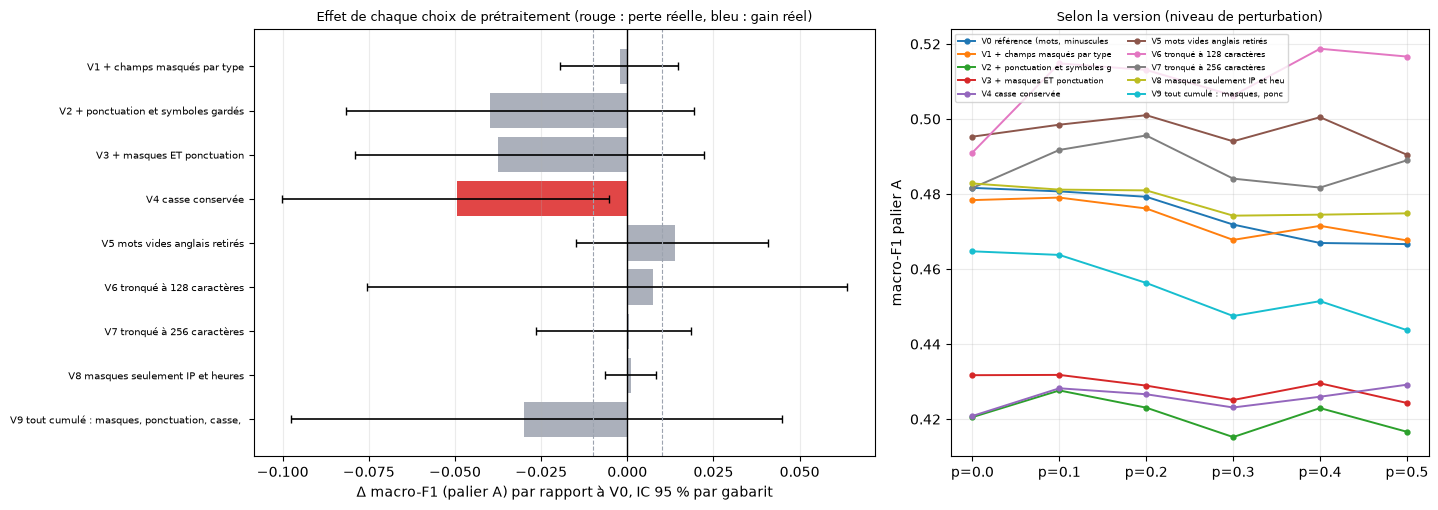

In [49]:
fig, ax = plt.subplots(1, 2, figsize=(14.5, 5.2), gridspec_kw={"width_ratios": [1.3, 1]})
dd = res4.iloc[1:].copy(); lo = [float(x.split(";")[0].strip("[ +")) for x in dd["IC 95 %"]]; hi = [float(x.split(";")[1].strip("] +")) for x in dd["IC 95 %"]]
y = np.arange(len(dd)); colv = [RED if v == "perte réelle" else BLUE if v == "gain réel" else GREY for v in dd["verdict"]]
ax[0].barh(y, dd["Δ vs V0"], color=colv, alpha=.85); ax[0].errorbar(dd["Δ vs V0"], y, xerr=[dd["Δ vs V0"] - lo, np.array(hi) - dd["Δ vs V0"]], fmt="none", color="k", lw=1.2, capsize=3)
ax[0].axvline(0, color="k", lw=1); ax[0].axvline(0.01, color=GREY, ls="--", lw=.8); ax[0].axvline(-0.01, color=GREY, ls="--", lw=.8)
ax[0].set_yticks(y); ax[0].set_yticklabels([n[:46] for n in dd["variante"]], fontsize=7.5); ax[0].invert_yaxis(); ax[0].set_xlabel("Δ macro-F1 (palier A) par rapport à V0, IC 95 % par gabarit"); ax[0].set_title("Effet de chaque choix de prétraitement (rouge : perte réelle, bleu : gain réel)", fontsize=9.5); ax[0].grid(axis="x", alpha=.25)
for nm, r in results.items(): ax[1].plot(range(6), [r["by_version"][str(v)] for v in range(6)], marker="o", ms=3.5, lw=1.4, label=nm[:30])
ax[1].set_xticks(range(6)); ax[1].set_xticklabels([f"p={v / 10}" for v in range(6)]); ax[1].set_ylabel("macro-F1 palier A"); ax[1].set_title("Selon la version (niveau de perturbation)", fontsize=9.5); ax[1].legend(fontsize=6, ncol=2); ax[1].grid(alpha=.25)
plt.tight_layout(); fig.savefig(DIRS["figures"] / "04_effets_pretraitement.png", dpi=140); plt.show()

**Note de lecture sur la colonne « Δ ».** La colonne « F1 palier A » est la **moyenne des six macro-F1 par version**. La colonne « Δ » et son intervalle viennent du **bootstrap par gabarit**, qui recalcule la macro-F1 en **regroupant les prédictions des six versions** : c'est une autre façon d'agréger, donc le Δ peut **différer** de la simple différence des deux colonnes F1 (par exemple, un F1 de 0,4727 contre 0,4745 donne un Δ de −0,0197 plus bas). Les verdicts ci-dessous s'appuient sur **Δ et son intervalle**, jamais sur la différence des colonnes.

**Lecture (termes techniques).**
- **Référence V0** : macro-F1 de **0,4745** sur les 18 classes du palier A (vocabulaire de 9 880 mots), de **0,4816** à p = 0 à **0,4667** à p = 0,5. C'est le niveau « classifieur linéaire sur des gabarits jamais vus », cohérent avec le plancher de **0,458** vu en 3.6 (qui, lui, portait sur les 30 classes).
- **Seule perte réelle : conserver la casse (V4)**, **−0,049**, IC **[−0,100 ; −0,005]**. Garder « Failed » et « failed » comme deux mots différents **fragmente** le vocabulaire (+ 6 % de mots) et rend chaque mot plus rare : le modèle voit moins d'exemples de chacun. Sur des gabarits nouveaux, cette fragmentation coûte.
- **Aucun gain réel.** Retirer les mots vides (V5, **+0,014**, IC [−0,015 ; +0,041]) ou tronquer à 128 caractères (V6, **+0,008**, IC [−0,075 ; +0,064]) ont des écarts positifs mais des intervalles qui **contiennent 0** : on ne peut pas affirmer qu'ils aident.
- **Garder la ponctuation** (V2, **−0,040** ; V3, **−0,037**) fait **perdre** presque 0,04 en valeur centrale, mais l'IC contient 0 (par exemple [−0,082 ; +0,019]) : indistinguable, avec une tendance négative. Des symboles comme `[`, `:`, `"` sont partout et ne distinguent pas les classes ; ils diluent les mots utiles.
- **Masquer les champs** (V1, **−0,002**) ou seulement IP et heure (V8, **+0,001**) ne change **rien** de mesurable, alors qu'ils touchent 92 % et 40 % des logs (4.4) : le modèle de mots **ignore déjà** ces champs, puisque dans V0 les chiffres sont déjà ignorés (seuls les mots d'au moins deux lettres sont gardés) : masquer une IP ou une heure revient à retirer ce que le modèle ne regardait déjà pas. Ce n'est **pas** une preuve que masquer est inutile pour un **Transformer** (qui lit les chiffres) : à vérifier à l'étape 6.
- **Tout cumuler (V9)** : **−0,030**, indistinguable de V0 mais plus bas : on ne gagne rien à empiler.
- **Effet de p** : pour toutes les variantes, le score à p = 0,5 reste dans quelques centièmes de celui à p = 0. Le prétraitement **ne rend pas** le modèle plus robuste à la perturbation, ou pas de façon mesurable ici.

**Limite statistique (à dire).** Les IC sont **larges** (souvent ±0,05 à ±0,07) parce que le palier A de validation ne compte que **36 gabarits** : c'est la **puissance** de l'expérience qui est faible, pas forcément l'effet qui est nul. On ne peut donc détecter que des **grandes** différences (comme la casse, −0,049).

## 4.9 Décision

In [50]:
v0n = list(VARIANTS)[0]; adopted = []; log_dec = []
for _, r in res4.iterrows():
    if r["variante"] == v0n or r["variante"].startswith("V9"): continue
    dimgain = -float(r["dim vs V0"].strip("%")) / 100
    if r["verdict"] == "perte réelle": dec = "rejetée (perte réelle)"
    elif r["verdict"] == "gain réel": dec = "adoptée (gain réel)"; adopted.append(r["variante"])
    elif dimgain >= 0.20: dec = "adoptée (neutre, vocabulaire réduit d'au moins 20 %)"; adopted.append(r["variante"])
    else: dec = "non adoptée (neutre, sans bénéfice mesuré : on garde le plus simple)"
    log_dec.append((r["variante"], r["Δ vs V0"], r["verdict"], r["dim vs V0"], dec))
dec_df = pd.DataFrame(log_dec, columns=["variante", "Δ", "verdict", "dim vs V0", "décision"]); pd.set_option("display.max_colwidth", 80); print(dec_df.to_string(index=False)); print("\nÉtapes adoptées :", adopted)

                           variante       Δ        verdict dim vs V0                                                             décision
       V1 + champs masqués par type -0.0021 indistinguable       -5% non adoptée (neutre, sans bénéfice mesuré : on garde le plus simple)
V2 + ponctuation et symboles gardés -0.0398 indistinguable       +0% non adoptée (neutre, sans bénéfice mesuré : on garde le plus simple)
        V3 + masques ET ponctuation -0.0374 indistinguable       -4% non adoptée (neutre, sans bénéfice mesuré : on garde le plus simple)
                 V4 casse conservée -0.0494   perte réelle       +6%                                               rejetée (perte réelle)
      V5 mots vides anglais retirés  0.0137 indistinguable       -2% non adoptée (neutre, sans bénéfice mesuré : on garde le plus simple)
        V6 tronqué à 128 caractères  0.0075 indistinguable      -12% non adoptée (neutre, sans bénéfice mesuré : on garde le plus simple)
        V7 tronqué à 256 caractère

**Décision.** Aucune étape n'est adoptée par la règle ; la casse est **rejetée**. Le pipeline retenu est donc **A = V0** : normalisation Unicode (NFKC), retrait des caractères de contrôle et de `\r\n`, **minuscules**, mots de **deux lettres ou plus**, sans masque, sans ponctuation, sans retrait de mots vides, sans troncature. C'est le plus simple, et c'est celui avec lequel les étapes 2 et 3 ont travaillé.

**Ce qu'on ne tranche pas (honnêtement).**
1. **Masquage et ponctuation pour un Transformer** : un encodeur lit les chiffres et les symboles ; V1 et V2 y seront retestés (étape 6) avec un **vrai** encodeur.
2. **Casse pour l'encodeur** : à l'étape 0 on avait écrit **« `distilbert-base-cased` »** en pariant que la casse porte du sens dans les logs. Le résultat V4 (**perte réelle** pour un modèle de mots) **contredit en partie** ce pari ; mais un encodeur apprend ses propres sous-mots, donc la conclusion n'est pas transférable telle quelle. On **testera les deux** (`uncased` contre `cased`) sur une rotation à l'étape 6 : c'est la correction directe de notre hypothèse initiale.
3. **Fenêtre de l'encodeur** : la troncature à 128 ou 256 caractères n'a pas d'effet mesurable (V6, V7) sur le modèle de mots ; la fenêtre en jetons de l'encodeur sera choisie à l'étape 5 à partir des **longueurs** (2.1) : `network-filtered` et `network-traffic` dépassent 500 caractères.

## 4.10 Enregistrement des pipelines

In [51]:
PIPE_A = {"name": "A", "usage": "TF-IDF, caractères, vecteurs de mots", "normalisation": "Unicode NFKC, retrait des caractères de contrôle et de \\r\\n", "masques": [], "minuscules": True, "ponctuation": False, "mots_vides": False, "troncature": None,
          "etapes_adoptees_par_la_regle": adopted, "module": "src/tp2_logtext.py", "module_hash": MODULE_HASH}
PIPE_B = {"name": "B", "usage": "encodeur Transformer (tokenizer propre au modèle)", "normalisation": "Unicode NFKC, retrait des caractères de contrôle et de \\r\\n", "masques": [], "casse": "à trancher à l'étape 6 (cased contre uncased)", "troncature": "fenêtre de l'encodeur, choisie à l'étape 5",
          "module": "src/tp2_logtext.py", "module_hash": MODULE_HASH}
(DIRS["data"] / "preprocessing_pipelines.json").write_text(json.dumps({"A": PIPE_A, "B": PIPE_B, "data_id": DATA_ID, "splits_sha256": SPLITS_SHA}, indent=2, ensure_ascii=False))
print("Enregistré : preprocessing_pipelines.json")
print("Pipeline A :", {k: PIPE_A[k] for k in ("masques", "minuscules", "ponctuation", "mots_vides")}, "| module", MODULE_HASH)

Enregistré : preprocessing_pipelines.json
Pipeline A : {'masques': [], 'minuscules': True, 'ponctuation': False, 'mots_vides': False} | module 2b5360ac2128


**Registre (suite).**

| N° | Affirmation | Source | Niveau |
|---|---|---|---|
| V26 | Champs variables dans SIEVE_00 (6 000 logs) : heure 92,0 %, nombres 89,0 %, IP 40,2 %, hexadécimaux 10,6 %, UUID 4,1 %, MAC 1,8 %, courriel 1,1 %, URL 0,9 % | Calcul | calcul |
| V27 | Prétraitement (SVM linéaire TF-IDF, palier A, gabarits jamais vus, 36 gabarits de validation) : seule la casse conservée est une perte réelle (−0,049, IC [−0,100 ; −0,005]) ; masques, ponctuation, mots vides, troncature : indistinguables de V0 | Calcul | calcul (puissance limitée) |
| V28 | Bootstrap par gabarit, 400 rééchantillonnages : un intervalle sur des logs isolés serait trop étroit car les logs d'un gabarit sont corrélés | Field et Welsh, *Bootstrapping clustered data*, J. R. Stat. Soc. B 69(3), 369-390, 2007 (DOI 10.1111/j.1467-9868.2007.00593.x) : le bootstrap par grappes est cohérent sous les modèles de transformation et d'effets aléatoires | résumé lu |

**Bilan de l'étape 4.** Le prétraitement qui marche le mieux est **le plus simple** ; la mesure a **rejeté** un réflexe (garder la casse) et **n'a validé aucune** des « bonnes pratiques » du texte naturel. La puissance statistique est limitée par le petit nombre de gabarits ; les choix qu'on n'a pas pu trancher (masques et casse pour l'encodeur) sont reportés à l'étape 6, où l'on testera avec un vrai Transformer.

**Prochaine étape.** Étape 5 : représentations (TF-IDF de mots et de caractères, vecteurs de mots, encodeur Transformer).

<!-- REV-4.b -->
**Ajout après l'état de l'art.** La section **4.11** montre que les logs propres ne contiennent pas de caractères confondables, que la canonicalisation officielle (V10) n'a aucun effet sur du texte propre (gardée comme garde-fou défensif pour l'étape 9), et que les décisions de l'étape 4 tiennent sous la validation croisée par groupes : V4 (casse) est une perte fragile, V5 (mots vides) devient une perte régulière.

<!-- REV-4.11 -->
## 4.11 Ajouts après l'état de l'art : caractères confondables et stabilité des décisions

**(a) Y a-t-il des caractères confondables dans les logs propres ?** (b) **V10 : canonicalisation officielle** : avant le prétraitement de V0, chaque caractère non ASCII de la table UTS #39 (1.7) est remplacé par la lettre ASCII qui lui ressemble (**les 4 sources ASCII de la table sont écartées** : elles transformeraient un `I` en `l`). On la mesure sur du **texte propre**, avec la **même règle de décision** que les autres variantes : elle ne doit pas nuire quand il n'y a pas d'attaque. (c) **Stabilité des décisions** : les variantes V1 (masques), V4 (casse) et V5 (mots vides) sont re-mesurées sous la validation croisée **par groupes à 5 plis** (sur l'entraînement et la validation de l'échantillon de l'étape 4), en comparant, pli par pli, à V0. Règle de stabilité (un contrôle, pas un test formel) : « perte régulière » si la variante perd dans **les 5 plis** avec une moyenne d'au moins 0,01 ; « gain régulier » dans le cas inverse ; sinon « indistinguable ».

In [52]:
conf = pd.read_csv(DIRS["data"] / "confusables_ascii.csv"); conf = conf[conf["caractere"].map(lambda c: ord(c) >= 128)]
CONF_MAP = dict(zip(conf["caractere"], conf["lettre"])); CONF_SET = set(CONF_MAP)
ALL_TXT = list(tr_text) + list(va_text)
non_ascii = np.array([any(ord(ch) >= 128 for ch in t) for t in ALL_TXT]); has_conf = np.array([any(ch in CONF_SET for ch in t) for t in ALL_TXT])
print(f"(a) Logs de SIEVE avec au moins un caractère non ASCII : {non_ascii.mean():.3%} ; avec un caractère confondable de la table officielle : {has_conf.mean():.3%} (sur {len(ALL_TXT):,} logs d'entraînement et de validation)")
def canon_official(t): return "".join(CONF_MAP.get(ch, ch) for ch in t)
def run_variant_pre(name, cfg, pre):
    ckey = hashlib.sha256(json.dumps([name, {k: (list(v) if isinstance(v, tuple) else v) for k, v in cfg.items()}, DATA_ID, SPLITS_SHA, MODULE_HASH, "s4v1pre-uts39", int(len(CONF_MAP))], sort_keys=True).encode()).hexdigest()[:16]
    cj, cz = CACHE4 / f"{ckey}.json", CACHE4 / f"{ckey}.npz"
    if cj.exists() and cz.exists(): r = json.loads(cj.read_text()); r["_pred"] = np.load(cz)["pred"]; r["cached"] = True; return r
    t0 = time.perf_counter(); f = lambda txt: tokenize(pre(txt), **cfg)
    tv = TfidfVectorizer(analyzer=f, sublinear_tf=True, min_df=2, dtype=np.float32); Xtr = tv.fit_transform(tr_text); Xva = tv.transform(va_text); m = LinearSVC(C=1.0).fit(Xtr, ytr); pred = np.array([CI[c] for c in m.predict(Xva)])
    per_v = {str(v): float(f1_score(yva_i[mask_A_rows & (ver_va == v)], pred[mask_A_rows & (ver_va == v)], average="macro", labels=np.where(tierA)[0])) for v in range(6)}
    res = {"name": name, "dim": int(Xtr.shape[1]), "f1_A_mean_versions": float(np.mean(list(per_v.values()))), "by_version": per_v, "secs": round(time.perf_counter() - t0, 1)}
    cj.write_text(json.dumps(res)); np.savez_compressed(cz, pred=pred); res["_pred"] = pred; res["cached"] = False; return res
v0n = list(VARIANTS)[0]; v0r = results[v0n]; r10 = run_variant_pre("V10 canonicalisation UTS #39 (texte propre)", dict(BASE), canon_official)
d10 = boot_delta(v0r["_pred"], r10["_pred"]); verd10 = "gain réel" if d10[1] > 0 and d10[0] >= 0.01 else "perte réelle" if d10[2] < 0 and -d10[0] >= 0.01 else "indistinguable"
print(f"(b) V10 : F1 palier A {r10['f1_A_mean_versions']:.4f} contre {v0r['f1_A_mean_versions']:.4f} pour V0 ; Δ {d10[0]:+.4f} IC [{d10[1]:+.4f} ; {d10[2]:+.4f}] -> {verd10} ; vocabulaire {r10['dim']:,} contre {v0r['dim']:,} mots")
# (c) stabilité des décisions : validation croisée par groupes (5 plis par gabarit) sur l'entraînement et la validation de l'échantillon de l'étape 4
POOL_Y = np.array(list(ytr) + list(yva)); POOL_G = np.concatenate([tr_rows["group"].values, va_rows["group"].values]).astype(int)
CV_VARIANTS = [v0n, "V1 + champs masqués par type", "V4 casse conservée", "V5 mots vides anglais retirés"]
ckeycv = hashlib.sha256(json.dumps([CV_VARIANTS, DATA_ID, SPLITS_SHA, MODULE_HASH, "s4cv5v1"], sort_keys=True).encode()).hexdigest()[:16]; fcv = CACHE4 / f"cv_{ckeycv}.json"
if fcv.exists(): CV4 = json.loads(fcv.read_text()); print("(c) (résultats rechargés depuis le cache)")
else:
    t0 = time.perf_counter(); folds4 = list(StratifiedGroupKFold(5, shuffle=True, random_state=int(SPLIT_SEED)).split(np.zeros(len(POOL_Y)), POOL_Y, POOL_G)); CV4 = {}
    for nm in CV_VARIANTS:
        toks = [tokenize(t, **VARIANTS[nm]) for t in ALL_TXT]; sc = []
        for tr_i, te_i in folds4:
            tv = TfidfVectorizer(analyzer=lambda x: x, sublinear_tf=True, min_df=2, dtype=np.float32); Xa = tv.fit_transform([toks[i] for i in tr_i]); Xb = tv.transform([toks[i] for i in te_i])
            p = LinearSVC(C=1.0).fit(Xa, POOL_Y[tr_i]).predict(Xb); sc.append(float(f1_score(POOL_Y[te_i], p, average="macro", labels=[c for c in A_CLASSES if c in set(POOL_Y[te_i])])))
        CV4[nm] = sc
    CV4["secondes"] = round(time.perf_counter() - t0); fcv.write_text(json.dumps(CV4))
rows = []
for nm in CV_VARIANTS[1:]:
    dlt = np.array(CV4[nm]) - np.array(CV4[v0n]); verdict = "perte régulière" if (dlt < 0).all() and dlt.mean() <= -0.01 else "gain régulier" if (dlt > 0).all() and dlt.mean() >= 0.01 else "indistinguable"
    rows.append({"variante": nm, "F1 V0 (moy. des 5 plis)": round(float(np.mean(CV4[v0n])), 4), "F1 variante": round(float(np.mean(CV4[nm])), 4), "Δ moyen": round(float(dlt.mean()), 4), "Δ par pli": [round(float(x), 3) for x in dlt], "plis où la variante perd": int((dlt < 0).sum()), "verdict sous validation croisée": verdict})
cv_df = pd.DataFrame(rows); print("\n(c) Les décisions de l'étape 4 sous la validation croisée par groupes (5 plis) :"); print(cv_df.to_string(index=False)); cv_df.to_csv(DIRS["results"] / "step4_decisions_validation_croisee.csv", index=False)

(a) Logs de SIEVE avec au moins un caractère non ASCII : 0.089% ; avec un caractère confondable de la table officielle : 0.000% (sur 83,880 logs d'entraînement et de validation)
(b) V10 : F1 palier A 0.4745 contre 0.4745 pour V0 ; Δ +0.0000 IC [+0.0000 ; +0.0000] -> indistinguable ; vocabulaire 9,880 contre 9,880 mots
(c) (résultats rechargés depuis le cache)

(c) Les décisions de l'étape 4 sous la validation croisée par groupes (5 plis) :
                     variante  F1 V0 (moy. des 5 plis)  F1 variante  Δ moyen                                Δ par pli  plis où la variante perd verdict sous validation croisée
 V1 + champs masqués par type                   0.4964       0.4955  -0.0008      [-0.01, -0.006, 0.011, 0.002, -0.0]                         3                  indistinguable
           V4 casse conservée                   0.4964       0.4742  -0.0222  [-0.021, -0.087, -0.008, -0.029, 0.033]                         4                  indistinguable
V5 mots vides anglais retiré

**Lecture (termes techniques).**
- **(a) Les logs de SIEVE sont quasi purement ASCII** : **0,089 %** contiennent un caractère non ASCII et **aucun** un caractère confondable de la table officielle. Les homoglyphes n'existent donc **que sous attaque** : la défense ne se juge qu'à l'étape 9.
- **(b) V10 n'a aucun effet sur le texte propre** : même macro-F1 (0,4745), même vocabulaire (9 880 mots), Δ de +0,0000. Par la règle 5 elle n'est **pas adoptée** dans le pipeline de base A. Elle est **conservée comme garde-fou défensif** : appliquée seulement dans les évaluations d'attaque de l'étape 9, où l'on mesurera son utilité (avec la table coupée en deux, voir 0.1b.4) ; son coût sur du texte propre est nul.
- **(c) Les décisions de l'étape 4 tiennent, avec deux nuances.** **V1 (masques)** : indistinguable sous les deux protocoles (Δ moyen −0,001, 3 plis sur 5 en baisse). **V4 (casse conservée)** : la « perte réelle » de l'étape 4 (−0,049) est **moins nette** sous validation croisée : Δ moyen de −0,022, perte dans 4 plis sur 5 mais **gain de +0,033 dans un pli** ; le verdict de « perte réelle » est donc **fragile** (le sens est confirmé, l'amplitude et la régularité ne le sont pas) ; la casse reste rejetée (rien n'est démontré en sa faveur). **V5 (mots vides)** : indistinguable à l'étape 4 (+0,014), mais **perte régulière** sous validation croisée (Δ moyen −0,012, 5 plis sur 5 en baisse) : retirer les mots vides **nuit** sans doute (ce sont des mots de structure dans un log, comme `from` ou `on`) ; la non-adoption est confortée. **Aucune variante ne donne de gain régulier : le pipeline V0 reste le bon choix.**
- **Ce qui a été tranché depuis** (étapes 5 et 6). *Casse pour l'encodeur* : `uncased` fait +0,019 de macro-F1 en moyenne (4 rotations sur 5) et ne perd pas en détection : la casse n'a **aucun avantage net** (6.10). *Fenêtre* : 256 jetons retenus, 512 sans gain net sur la rotation 1. *Masques et ponctuation pour l'encodeur* : **non retestés** avec l'encodeur (écart au plan, dit ici).

**Registre (suite).**

| N° | Affirmation | Source | Niveau |
|---|---|---|---|
| V81 | 0,089 % des logs d'entraînement et de validation (échantillon de l'étape 4, 83 880 logs) contiennent un caractère non ASCII, 0 % un caractère confondable de la table officielle ; V10 : Δ +0,0000, vocabulaire inchangé | Calcul (4.11) | calcul |
| V82 | Décisions sous validation croisée par groupes (5 plis, classes du palier A) : V1 Δ moyen −0,0008 ; V4 −0,0222 (4 plis sur 5 en baisse, +0,033 dans un pli) ; V5 −0,0115 (5 plis sur 5 en baisse) | Calcul (4.11) | calcul (5 plis seulement) |

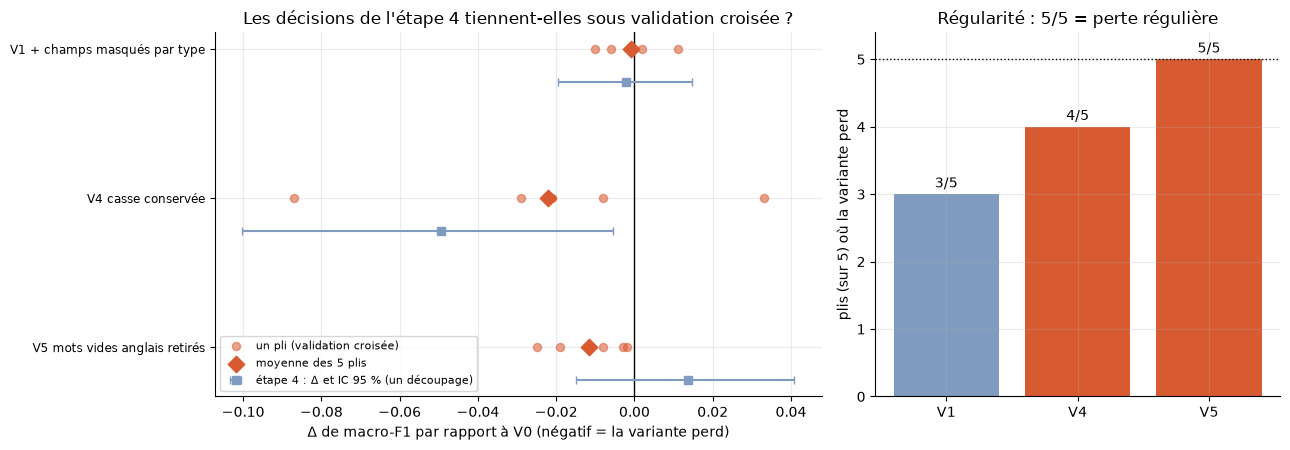

In [53]:
import tp2_new_figs as NF
fig = NF.fig_4_11(DIRS["results"], DIRS["figures"]); plt.show()

**Lecture du visuel.** Les **points corail** sont les cinq plis de la validation croisée, le **losange** leur moyenne ; les **carrés gris-bleu** rappellent le résultat de l'étape 4 (un seul découpage), avec son intervalle. V5 (mots vides) paraissait neutre à l'étape 4 et perd dans les 5 plis ; V4 (casse) perd moins nettement qu'annoncé (un pli gagne) ; V1 (masques) reste neutre. À droite : plus la barre est haute, plus la perte est régulière (5/5 = perte régulière).

---
# Étape 5 : Représentations (transformer un log en nombres)

**Pourquoi cette étape existe.** Un algorithme d'apprentissage ne lit pas du texte : il manipule des **nombres**. La *représentation* est la « traduction » du log en vecteur. Elle décide de **ce que le modèle peut voir** : si la traduction perd une information (l'ordre des mots, le sens d'un mot rare), aucun classifieur ne la retrouvera. C'est un choix **aussi important** que celui du classifieur, surtout ici, où le test porte sur des gabarits **jamais vus**.

**Les trois familles comparées.**

| Famille | Idée | Exemples ici | Dimension |
|---|---|---|---|
| **Creuse (*sparse*)** | une colonne par mot (ou suite de mots, ou suite de lettres) ; presque tout vaut 0 | BoW, TF-IDF, n-grammes de mots, n-grammes de caractères | 10⁴ à 3·10⁵ |
| **Dense, par vecteurs de mots** | chaque mot a un petit vecteur appris ; un log = **moyenne** des vecteurs de ses mots | Word2Vec (CBOW, Skip-gram), FastText, GloVe | 100 |
| **Dense, contextuelle** | un Transformer lit tout le log ; le vecteur d'un mot dépend de ses voisins | DistilBERT, BERT | 768 |

**En simple.** Les comptages demandent : « quels mots apparaissent, et combien ? ». Les vecteurs de mots demandent : « ces mots se **ressemblent**-ils par le sens ? » (*failed* proche de *unsuccessful*). Les Transformers demandent : « que veut dire ce mot **dans ce log** ? ».

**Règle d'or (anti-fuite).** Tout ce qui **apprend quelque chose des données** (le vocabulaire, les poids IDF, les vecteurs Word2Vec) est **ajusté sur l'entraînement seulement**, puis **appliqué** tel quel à la validation et au test. Ici, les vecteurs de mots sont appris sans étiquette sur **tous les logs d'entraînement**, jamais sur val ni test.

**Protocole commun (décidé avant les résultats).**
- Textes : **pipeline A** de l'étape 4 (minuscules, mots d'au moins deux lettres).
- Même classifieur pour tous : **SVM linéaire** (réglage C fixé d'avance : 1,0 pour les représentations creuses, 0,1 pour les 100 dimensions standardisées), pour **isoler l'effet de la représentation**. Limite assumée : une représentation peut mieux convenir à un autre classifieur ; l'étape 6 croise les deux.
- Mêmes logs qu'à l'étape 4 : 59 940 en entraînement, 23 940 en validation, mesure principale = macro-F1 des 18 classes du **palier A** (36 gabarits), **bootstrap par gabarit**.
- Une différence est *réelle* si l'intervalle de confiance exclut 0 **et** |écart| ≥ 0,01 (règle S5).
- On rapporte aussi la **dimension**, le nombre de valeurs non nulles par log et le **temps** (axe « coût »).

In [54]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.preprocessing import Normalizer, StandardScaler
from sklearn.pipeline import make_pipeline
import scipy.sparse as sps
CACHE5 = DIRS["results"] / "cache_step5"; CACHE5.mkdir(exist_ok=True)
def word_tokens(txt): return tokenize(txt)                                   # pipeline A de l'étape 4 : minuscules, mots de 2 lettres ou plus
def make_key(name, spec, extra=()):
    return hashlib.sha256(json.dumps([name, spec, DATA_ID, SPLITS_SHA, MODULE_HASH, "s5v1", *extra], sort_keys=True, default=str).encode()).hexdigest()[:16]
def evaluate_rep(name, spec, featurize, clf_factory, extra=()):
    # featurize(train_texts, val_texts) -> (X_train, X_val, infos) ; tout est AJUSTÉ sur les textes d'entraînement seulement.
    key = make_key(name, spec, extra); cj, cz = CACHE5 / f"{key}.json", CACHE5 / f"{key}.npz"
    if cj.exists() and cz.exists():
        r = json.loads(cj.read_text()); r["_pred"] = np.load(cz)["pred"]; r["cached"] = True; return r
    t0 = time.perf_counter(); Xtr, Xva, info = featurize(tr_text, va_text); t_feat = time.perf_counter() - t0
    clf = clf_factory().fit(Xtr, ytr); pred = np.array([CI[c] for c in clf.predict(Xva)])
    per_v = {str(v): float(f1_score(yva_i[mask_A_rows & (ver_va == v)], pred[mask_A_rows & (ver_va == v)], average="macro", labels=np.where(tierA)[0])) for v in range(6)}
    r = {"name": name, "dim": int(Xtr.shape[1]), "nnz_doc": float((Xtr.nnz if sps.issparse(Xtr) else Xtr.size) / Xtr.shape[0]), "f1_A": float(np.mean(list(per_v.values()))), "by_version": per_v,
         "f1_all": float(f1_score(yva_i, pred, average="macro")), "secs_feat": round(t_feat, 1), "secs": round(time.perf_counter() - t0, 1), **info}
    cj.write_text(json.dumps(r, default=str)); np.savez_compressed(cz, pred=pred); r["_pred"] = pred; r["cached"] = False; return r
lin = lambda: LinearSVC(C=1.0)
lin_dense = lambda: LinearSVC(C=0.1, dual=False)                            # 100 dimensions standardisées : forme primale, plus rapide ; C fixé d'avance
print("Protocole : mêmes 59 940 logs d'entraînement, mêmes 23 940 logs de validation, même mesure (macro-F1 du palier A, 36 gabarits), bootstrap par gabarit qu'à l'étape 4.")

Protocole : mêmes 59 940 logs d'entraînement, mêmes 23 940 logs de validation, même mesure (macro-F1 du palier A, 36 gabarits), bootstrap par gabarit qu'à l'étape 4.


## 5.1 Les représentations creuses : sac de mots, TF-IDF, n-grammes

**Sac de mots (*Bag of Words*, BoW).** On bâtit un **vocabulaire** (les mots vus à l'entraînement, présents dans au moins 2 logs), puis chaque log devient un vecteur dont la case *j* contient **combien de fois** le mot *j* apparaît. L'ordre est perdu.

**TF-IDF.** On pondère chaque mot par son **pouvoir distinctif** :

$$\mathrm{idf}(t)=\ln\frac{1+N}{1+\mathrm{df}(t)}+1\qquad \mathrm{tfidf}(t,d)=\mathrm{tf}(t,d)\times\mathrm{idf}(t)$$

avec $N$ le nombre de logs d'entraînement et $\mathrm{df}(t)$ le nombre de logs contenant $t$. Le vecteur est ensuite **normalisé** (norme 1). Un mot présent dans tous les logs d'une classe et dans peu d'autres classes aura une grande valeur ; *failed*, très fréquent dans toutes les familles, en aura moins.

**Variantes testées, une idée à la fois.**
- **BoW** : comptages bruts, **binaire** (présent / absent), ou comptages **normalisés** (norme L2).
- **TF-IDF mots** : la référence.
- **N-grammes de mots** (1-2, 1-3) : on ajoute les suites de 2 ou 3 mots (*password for*, *failed password for*) pour retrouver un peu d'**ordre**. Le prix : la dimension explose.
- **N-grammes de caractères** (3 à 5 lettres, *à l'intérieur* des mots ; ou 2 à 4 sur la chaîne entière) : *failed* devient ` fa`, `fai`, `ail`, `ile`, `led`... Un mot **transformé** par la perturbation SPICE (un synonyme, une lettre changée) garde une partie de ses morceaux : candidat naturel pour la **robustesse**.

**Démonstration à la main (3 courts logs).** Le TF-IDF est calculé **à la main** puis comparé par **assertion** à scikit-learn : on sait ce que fait la bibliothèque.

In [55]:
demo = ["failed password for root from iptok", "accepted password for root from iptok", "connection closed by iptok"]
cvd = CountVectorizer(); B_ = cvd.fit_transform(demo).toarray(); vd = cvd.get_feature_names_out()
print(pd.DataFrame(B_, columns=vd, index=["log1", "log2", "log3"]).to_string())
Nn = len(demo); dfd = (B_ > 0).sum(0); idfd = np.log((1 + Nn) / (1 + dfd)) + 1
tfh = B_ * idfd; tfh = tfh / np.linalg.norm(tfh, axis=1, keepdims=True); tfs = TfidfVectorizer().fit_transform(demo).toarray()
assert np.allclose(tfh, tfs, atol=1e-6)
print("\nidf (mots peu fréquents = plus distinctifs) :", {w: round(float(v), 3) for w, v in zip(vd, idfd)})
print("TF-IDF à la main identique à scikit-learn (assertion réussie).")
print("Cosinus log1/log2 :", round(float(tfh[0] @ tfh[1]), 3), "(ne diffèrent que par « failed » / « accepted »)  | log1/log3 :", round(float(tfh[0] @ tfh[2]), 3))
cvc = CountVectorizer(analyzer="char_wb", ngram_range=(3, 5)).fit(["failed"]); print("N-grammes de caractères de « failed » (3 à 5) :", list(cvc.get_feature_names_out()))

      accepted  by  closed  connection  failed  for  from  iptok  password  root
log1         0   0       0           0       1    1     1      1         1     1
log2         1   0       0           0       0    1     1      1         1     1
log3         0   1       1           1       0    0     0      1         0     0

idf (mots peu fréquents = plus distinctifs) : {'accepted': 1.693, 'by': 1.693, 'closed': 1.693, 'connection': 1.693, 'failed': 1.693, 'for': 1.288, 'from': 1.288, 'iptok': 1.0, 'password': 1.288, 'root': 1.288}
TF-IDF à la main identique à scikit-learn (assertion réussie).
Cosinus log1/log2 : 0.727 (ne diffèrent que par « failed » / « accepted »)  | log1/log3 : 0.1
N-grammes de caractères de « failed » (3 à 5) : [' fa', ' fai', ' fail', 'ail', 'aile', 'ailed', 'ed ', 'fai', 'fail', 'faile', 'ile', 'iled', 'iled ', 'led', 'led ']


**Lecture de la démonstration.** Les mots présents dans un seul log (*accepted*, *by*, *closed*, *connection*, *failed*) reçoivent l'IDF le plus grand (1,693), ceux présents dans deux logs (*for*, *from*, *password*, *root*) 1,288, et le jeton `iptok`, présent partout, le plus petit (1,0). Les logs 1 et 2, qui ne diffèrent que par *failed* / *accepted*, ont un cosinus de **0,727** ; le log 3, très différent, **0,1** avec le log 1. C'est ce **cosinus** qui sous-tend l'audit de fuite de l'étape 3. Les n-grammes de caractères de *failed* montrent comment un mot est découpé : 15 morceaux, dont ` fa` (début de mot) et `ed ` (fin de mot).

Maintenant, les huit variantes sur le vrai jeu (**ajustées sur l'entraînement uniquement**).

In [56]:
def sparse_feat(kind, **kw):
    def f(a, b):
        if kind == "tfidf": v = TfidfVectorizer(dtype=np.float32, **kw)
        elif kind == "count_l2": v = make_pipeline(CountVectorizer(dtype=np.float32, **kw), Normalizer())
        else: v = CountVectorizer(dtype=np.float32, binary=(kind == "binary"), **kw)
        Xa = v.fit_transform(a); return Xa, v.transform(b), {}
    return f
WORD = dict(analyzer=word_tokens, min_df=2)
SPARSE = {
    "BoW comptages":                 ("count", WORD),
    "BoW binaire":                   ("binary", WORD),
    "BoW comptages + norme L2":      ("count_l2", WORD),
    "TF-IDF mots":                   ("tfidf", dict(WORD, sublinear_tf=True)),
    "TF-IDF mots 1-2 grammes":       ("tfidf", dict(analyzer=lambda s: (lambda w: w + [a + " " + b for a, b in zip(w, w[1:])])(word_tokens(s)), min_df=2, sublinear_tf=True)),
    "TF-IDF mots 1-3 grammes":       ("tfidf", dict(analyzer=lambda s: (lambda w: w + [a + " " + b for a, b in zip(w, w[1:])] + [a + " " + b + " " + c for a, b, c in zip(w, w[1:], w[2:])])(word_tokens(s)), min_df=2, sublinear_tf=True)),
    "TF-IDF caractères 3-5 (dans les mots)": ("tfidf", dict(analyzer="char_wb", ngram_range=(3, 5), min_df=3, max_features=300000, sublinear_tf=True, lowercase=True)),
    "TF-IDF caractères 2-4": ("tfidf", dict(analyzer="char", ngram_range=(2, 4), min_df=3, max_features=300000, sublinear_tf=True, lowercase=True)),
}
res5 = {}; t_all = time.perf_counter()
for nm, (kind, kw) in SPARSE.items():
    r = evaluate_rep(nm, [kind, {k: (v if not callable(v) else "fn") for k, v in kw.items()}], sparse_feat(kind, **kw), lin); res5[nm] = r
    print(f"{nm:<42} dim={r['dim']:>8,}  nnz/log={r['nnz_doc']:>6.0f}  F1 palier A={r['f1_A']:.4f}  F1 tous={r['f1_all']:.4f}  [{'cache' if r['cached'] else str(round(r['secs'])) + ' s'}]")
print(f"Durée : {time.perf_counter() - t_all:.0f} s")

BoW comptages                              dim=   9,880  nnz/log=    15  F1 palier A=0.4282  F1 tous=0.6084  [cache]
BoW binaire                                dim=   9,880  nnz/log=    15  F1 palier A=0.4344  F1 tous=0.6118  [cache]
BoW comptages + norme L2                   dim=   9,880  nnz/log=    15  F1 palier A=0.4408  F1 tous=0.6225  [cache]
TF-IDF mots                                dim=   9,880  nnz/log=    15  F1 palier A=0.4745  F1 tous=0.6426  [cache]
TF-IDF mots 1-2 grammes                    dim=  75,530  nnz/log=    26  F1 palier A=0.4901  F1 tous=0.6530  [cache]
TF-IDF mots 1-3 grammes                    dim= 129,485  nnz/log=    33  F1 palier A=0.4896  F1 tous=0.6524  [cache]
TF-IDF caractères 3-5 (dans les mots)      dim= 300,000  nnz/log=   342  F1 palier A=0.5050  F1 tous=0.6588  [cache]
TF-IDF caractères 2-4                      dim= 220,981  nnz/log=   406  F1 palier A=0.4537  F1 tous=0.6333  [cache]
Durée : 0 s


**Lecture (termes techniques).**
- **Le TF-IDF mots (référence)** donne **0,4745** (vocabulaire de 9 880 mots, 15 mots non nuls par log).
- **BoW sans pondération** : **0,4282** (comptages), **0,4344** (binaire), **0,4408** (comptages normalisés). Passer des comptages bruts au TF-IDF fait gagner **+0,046** : l'IDF (donner moins de poids aux mots omniprésents) aide sur des gabarits nouveaux.
- **N-grammes de mots** : 1-2 grammes **0,4901**, 1-3 grammes **0,4896** : légèrement mieux que la référence, pour une dimension multipliée par **8** et **13** (75 530 et 129 485 colonnes). Le troisième ordre n'apporte **rien** de plus.
- **N-grammes de caractères 3-5** : **0,5050**, le meilleur chiffre, mais avec une dimension de 300 000 (plafonnée), 342 valeurs non nulles par log (**23 fois** plus que le TF-IDF mots) et **37 secondes** au lieu de 2. Les n-grammes **2-4** sont moins bons (**0,4537**) : trop courts pour être spécifiques.

**Pourquoi on n'a pas encore le droit de conclure.** Les intervalles de confiance sont donnés en 5.9 ; ils sont **larges** (palier A de validation : 36 gabarits seulement).

## 5.2 Les vecteurs de mots : Word2Vec, FastText, GloVe

**Idée commune (cours NLP21, pages 21 à 34 : « on reconnaît un mot à ses voisins »).** On apprend pour chaque mot un petit vecteur (100 nombres) tel que deux mots qui apparaissent dans des **contextes semblables** aient des vecteurs **proches**. Aucune étiquette de classe n'est utilisée : apprentissage **non supervisé**.

| Méthode | Comment elle apprend | Particularité |
|---|---|---|
| **Word2Vec CBOW** | prédire un mot à partir de la moyenne de ses voisins | rapide, lisse les mots rares |
| **Word2Vec Skip-gram** | prédire les voisins à partir d'un mot | meilleur pour les mots rares |
| **FastText** (Skip-gram + sous-mots) | un mot = somme de ses **n-grammes de caractères** (3 à 6 lettres) | donne un vecteur même à un mot **jamais vu** |
| **GloVe** | factorise les **co-occurrences globales** d'un corpus | ici **pré-entraîné** (Wikipédia + Gigaword), repris du TP1 : rien n'est appris sur nos logs |

**Décisions écrites avant les résultats.** (1) **Appris sur nos logs ou pré-entraîné ?** On teste les deux : l'hypothèse est que le vocabulaire des logs (*rshd*, *iptok*, *pam_ldap*) est très éloigné de l'anglais général. (2) **Du mot au log** : **moyenne** simple ou **pondérée par l'IDF**. (3) **Réglages fixes** (valeurs usuelles) : dimension 100, fenêtre 5, mots présents au moins 3 fois, 5 époques, graine 42 ; FastText : sous-mots de 3 à 6 lettres, 200 000 casiers de hachage.

**Module et tests.** Le code d'agrégation est écrit dans `src/tp2_vec.py` ; on le teste d'abord sur un mini-lexique à la main (moyenne simple, moyenne pondérée, log sans mot connu).

In [57]:
VEC_SRC = r'''"""Vectorisation de logs par moyenne de vecteurs de mots (TP2, étape 5).

Familles de vecteurs de mots :
  - w2v_cbow, w2v_sg : Word2Vec appris sur les logs d'entraînement (gensim) ;
  - fasttext         : FastText (Skip-gram + n-grammes de caractères) appris sur les logs ;
  - glove            : GloVe pré-entraîné (Wikipedia + Gigaword), simplement chargé.

Un log devient la moyenne (éventuellement pondérée par l'IDF) des vecteurs de ses mots.
fit() n'est appelé que sur l'entraînement : jamais sur val ni test. Aucune étiquette n'est lue.
"""
import time

import numpy as np
import scipy.sparse as sps
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.feature_extraction.text import CountVectorizer

from tp2_logtext import tokenize as _tok


def tokenize(text):
    return _tok(text)                      # pipeline A : minuscules, mots de 2 lettres ou plus


def _identity(s):
    return s


class DocEmbedder(BaseEstimator, TransformerMixin):
    def __init__(self, kind="w2v_sg", dim=100, window=5, min_count=3, epochs=5, weighting="mean",
                 seed=42, workers=8, glove_path=None, bucket=200000):
        self.kind = kind; self.dim = dim; self.window = window; self.min_count = min_count
        self.epochs = epochs; self.weighting = weighting; self.seed = seed; self.workers = workers
        self.glove_path = glove_path; self.bucket = bucket

    def fit(self, texts, y=None):
        t0 = time.perf_counter()
        docs = [tokenize(t) for t in texts]
        if self.kind == "glove":
            from gensim.models import KeyedVectors
            self.wv_ = KeyedVectors.load(str(self.glove_path))
            self.dim = self.wv_.vector_size
        elif self.kind in ("w2v_cbow", "w2v_sg"):
            from gensim.models import Word2Vec
            m = Word2Vec(sentences=docs, vector_size=self.dim, window=self.window, min_count=self.min_count,
                         sg=int(self.kind == "w2v_sg"), epochs=self.epochs, workers=self.workers, seed=self.seed)
            self.wv_ = m.wv
        elif self.kind == "fasttext":
            from gensim.models import FastText
            m = FastText(sentences=docs, vector_size=self.dim, window=self.window, min_count=self.min_count,
                         sg=1, epochs=self.epochs, workers=self.workers, seed=self.seed, bucket=self.bucket,
                         min_n=3, max_n=6)
            self.wv_ = m.wv
        else:
            raise ValueError(self.kind)
        cv = CountVectorizer(tokenizer=_identity, preprocessor=None, lowercase=False, token_pattern=None, binary=True)
        Xb = cv.fit_transform(docs); df = np.asarray(Xb.sum(0)).ravel(); n = Xb.shape[0]
        self.idf_ = {w: float(np.log((1 + n) / (1 + d)) + 1.0) for w, d in zip(cv.get_feature_names_out(), df)}
        self.idf_default_ = float(np.log(1 + n) + 1.0)
        self.fit_seconds_ = time.perf_counter() - t0
        return self

    def transform(self, texts):
        docs = [tokenize(t) for t in texts]
        cv = CountVectorizer(tokenizer=_identity, preprocessor=None, lowercase=False, token_pattern=None)
        C = cv.fit_transform(docs).astype(np.float32).tocsr()
        words = cv.get_feature_names_out()
        E = np.zeros((len(words), self.dim), dtype=np.float32); known = np.zeros(len(words), dtype=np.float32)
        subwords = self.kind == "fasttext"
        for i, w in enumerate(words):
            if subwords or w in self.wv_.key_to_index:
                E[i] = self.wv_[w]; known[i] = 1.0
        wt = np.ones(len(words), dtype=np.float32)
        if self.weighting == "idf":
            wt = np.array([self.idf_.get(w, self.idf_default_) for w in words], dtype=np.float32)
        Cw = (C @ sps.diags(wt * known)).tocsr()
        num = Cw @ E
        den = np.asarray(Cw.sum(1)).ravel()
        out = np.zeros_like(num); nz = den > 0
        out[nz] = num[nz] / den[nz, None]
        tot = np.asarray(C.sum(1)).ravel(); cov = np.asarray((C @ sps.diags(known)).sum(1)).ravel()
        self.last_coverage_ = float(cov.sum() / max(tot.sum(), 1)); self.last_empty_ = float((~nz).mean())
        return out

    def __getstate__(self):
        st = self.__dict__.copy()
        if self.kind == "glove":
            st.pop("wv_", None)
        return st

    def __setstate__(self, st):
        self.__dict__.update(st)
        if self.kind == "glove" and "wv_" not in self.__dict__:
            from gensim.models import KeyedVectors
            self.wv_ = KeyedVectors.load(str(self.glove_path))
'''
if "__VEC_SRC__" not in VEC_SRC: (PROJECT_ROOT / "src" / "tp2_vec.py").write_text(VEC_SRC)
VEC_HASH = hashlib.sha256((PROJECT_ROOT / "src" / "tp2_vec.py").read_bytes()).hexdigest()[:12]
import tp2_vec; importlib.reload(tp2_vec); from tp2_vec import DocEmbedder
class _FakeWV(dict):
    key_to_index = property(lambda self: self)
_e = DocEmbedder(kind="w2v_sg", dim=2); _e.wv_ = _FakeWV({"failed": np.array([1., 0.]), "password": np.array([0., 1.])}); _e.idf_ = {"failed": 1.0, "password": 3.0}; _e.idf_default_ = 5.0
assert np.allclose(_e.transform(["failed failed password zzzz"]), [[2 / 3, 1 / 3]]); _e.weighting = "idf"; assert np.allclose(_e.transform(["failed failed password"]), [[2 / 5, 3 / 5]])
assert np.allclose(_e.transform(["zzzz"]), [[0, 0]]) and _e.last_empty_ == 1.0
print("Module src/tp2_vec.py prêt (hash", VEC_HASH + ") ; tests : moyenne simple, moyenne pondérée IDF, log sans mot connu -> vecteur nul : OK")

Module src/tp2_vec.py prêt (hash 6d09bf373fd2) ; tests : moyenne simple, moyenne pondérée IDF, log sans mot connu -> vecteur nul : OK


**Lecture.** La moyenne simple de `failed failed password` (avec `zzzz` inconnu et ignoré) vaut bien (2/3, 1/3), et la moyenne pondérée par l'IDF (2/5, 3/5) : l'agrégation fait ce qu'on croit. *Avertissement technique* : lors de l'apprentissage, `gensim` écrit des messages `Exception ignored in ... our_dot_float` sans détail ; l'apprentissage reste correct (vérifié par les voisins ci-dessous), mais le **parallélisme** (8 fils) rend l'apprentissage **non strictement reproductible** d'une exécution à l'autre ; c'est pourquoi les modèles sont **sauvegardés** et rechargés.

In [58]:
import joblib
GLOVE_KV = PROJECT_ROOT.parent / "TP1" / "artifacts" / "data" / "pretrained" / "glove-wiki-gigaword-100.kv"
all_train_text = [LOG[v][r] for v, r in zip(S.loc[S.split == "train", "version"], S.loc[S.split == "train", "row"])]
print(f"Logs d'entraînement disponibles pour l'apprentissage non supervisé : {len(all_train_text):,}")
EMB = {"w2v_cbow": "Word2Vec CBOW", "w2v_sg": "Word2Vec Skip-gram", "fasttext": "FastText Skip-gram", "glove": "GloVe 100d (pré-entraîné, TP1)"}
embedders = {}
for k, lab_ in EMB.items():
    path = DIRS["features"] / f"emb_{k}_{DATA_ID[:8]}_{VEC_HASH}.joblib"
    if path.exists(): e = joblib.load(path)
    else:
        e = DocEmbedder(kind=k, workers=8, seed=CONFIG["seed"], **({"glove_path": str(GLOVE_KV)} if k == "glove" else {})).fit(all_train_text)
        joblib.dump(e, path)
    embedders[k] = e; print(f"{lab_:<34} vocabulaire {len(e.wv_.key_to_index):>8,} mots  dim {e.dim}  ajusté en {getattr(e, 'fit_seconds_', 0):.0f} s")
print("\nVoisins de quelques mots du domaine (Skip-gram appris sur les logs) :")
for w in ["failed", "authentication", "deleted", "connection", "directory", "shutdown"]:
    print(f"  {w:<15}", ", ".join(x for x, _ in embedders["w2v_sg"].wv_.most_similar(w, topn=6)))
for k in ("w2v_sg", "glove"):
    e = embedders[k]; e.weighting = "mean"; _ = e.transform(va_text); print(f"Couverture de la validation par {EMB[k]} : {e.last_coverage_:.1%} des jetons ; logs sans aucun mot connu : {e.last_empty_:.2%}")

Logs d'entraînement disponibles pour l'apprentissage non supervisé : 378,905


Word2Vec CBOW                      vocabulaire   24,485 mots  dim 100  ajusté en 12 s


Word2Vec Skip-gram                 vocabulaire   24,485 mots  dim 100  ajusté en 21 s


FastText Skip-gram                 vocabulaire   24,485 mots  dim 100  ajusté en 38 s


GloVe 100d (pré-entraîné, TP1)     vocabulaire  400,000 mots  dim 100  ajusté en 4 s

Voisins de quelques mots du domaine (Skip-gram appris sur les logs) :
  failed          unmet, crashed, unsuccessful, unresolved, defective, flawed
  authentication  verification, validation, identity, mechanism, security, severing
  deleted         discarded, erased, uninstalled, cleared, renamed, repurposed
  connection      link, linkage, interconnection, connectivity, established, license
  directory       folder, listing, catalog, hierarchical, index, tree
  shutdown        power, finalize, fulfill, complete, accomplish, appletalk


Couverture de la validation par Word2Vec Skip-gram : 94.3% des jetons ; logs sans aucun mot connu : 0.00%


Couverture de la validation par GloVe 100d (pré-entraîné, TP1) : 85.6% des jetons ; logs sans aucun mot connu : 0.00%


**Lecture (termes techniques).**
- Le vocabulaire des logs d'entraînement est **petit** : **24 485 mots** (contre 400 000 pour GloVe). C'est cohérent avec un jeu généré à partir de 440 gabarits.
- **Vérification de santé des vecteurs.** Les voisins de *failed* sont *unmet, crashed, unsuccessful, unresolved* ; ceux de *authentication* : *verification, validation, identity, security* ; ceux de *directory* : *folder, listing, catalog* ; ceux de *deleted* : *discarded, erased, cleared*. L'apprentissage **a fonctionné** : les vecteurs rapprochent des mots de même sens.
- **Observation intéressante.** Ces voisins sont des **synonymes de dictionnaire** (*failed* / *unsuccessful*) et non des mots du jargon des logs. Une explication **plausible** (non démontrée ici) : la perturbation SPICE remplace des mots par des synonymes (l'article précise que les dictionnaires ont été définis par des experts) ; les synonymes apparaissent alors dans les **mêmes contextes**, ce qui est précisément ce que Word2Vec détecte.
- **Couverture de la validation** : **94,3 %** des jetons connus de Word2Vec appris sur les logs, **85,6 %** de GloVe. GloVe ne connaît pas beaucoup de mots propres aux logs (*rshd*, *iptok*, noms de services).

## 5.3 Évaluation des vecteurs de mots

In [59]:
def dense_feat(k, wgt):
    def f(a, b):
        e = embedders[k]; e.weighting = wgt; Xa = e.transform(a); Xb = e.transform(b); sc = StandardScaler().fit(Xa)
        return sc.transform(Xa), sc.transform(Xb), {"coverage": round(e.last_coverage_, 4)}
    return f
DENSE = {f"{EMB[k]} | {w}": (k, w) for k in EMB for w in ("mean", "idf")}
t_all = time.perf_counter()
for nm, (k, w) in DENSE.items():
    r = evaluate_rep(nm, [k, w], dense_feat(k, w), lin_dense, extra=(VEC_HASH,)); res5[nm] = r
    print(f"{nm:<46} dim={r['dim']:>4}  F1 palier A={r['f1_A']:.4f}  F1 tous={r['f1_all']:.4f}  couverture={r.get('coverage', float('nan')):.3f}  [{'cache' if r['cached'] else str(round(r['secs'])) + ' s'}]")
print(f"Durée : {time.perf_counter() - t_all:.0f} s")

Word2Vec CBOW | mean                           dim= 100  F1 palier A=0.4278  F1 tous=0.6127  couverture=0.943  [cache]
Word2Vec CBOW | idf                            dim= 100  F1 palier A=0.4325  F1 tous=0.6165  couverture=0.943  [cache]
Word2Vec Skip-gram | mean                      dim= 100  F1 palier A=0.4677  F1 tous=0.6410  couverture=0.943  [cache]
Word2Vec Skip-gram | idf                       dim= 100  F1 palier A=0.4727  F1 tous=0.6417  couverture=0.943  [cache]
FastText Skip-gram | mean                      dim= 100  F1 palier A=0.4460  F1 tous=0.6281  couverture=1.000  [cache]
FastText Skip-gram | idf                       dim= 100  F1 palier A=0.4447  F1 tous=0.6264  couverture=1.000  [cache]
GloVe 100d (pré-entraîné, TP1) | mean          dim= 100  F1 palier A=0.3230  F1 tous=0.5274  couverture=0.856  [cache]
GloVe 100d (pré-entraîné, TP1) | idf           dim= 100  F1 palier A=0.2588  F1 tous=0.4675  couverture=0.856  [cache]
Durée : 0 s


**Lecture (termes techniques).**
- **Skip-gram appris sur les logs, pondéré IDF : 0,4727** ; sa version simple **0,4677**. C'est la meilleure des représentations denses, **au niveau** du TF-IDF mots (0,4745), avec **100 dimensions au lieu de 9 880**.
- **CBOW est nettement moins bon** (0,4278 et 0,4325) que Skip-gram, ce qui est **attendu** : le Skip-gram traite mieux les mots rares, et les logs en sont pleins.
- **FastText** (0,4460 et 0,4447) fait **moins bien** que Skip-gram malgré sa couverture de 100 % : ses sous-mots **sur-rapprochent** des mots qui se ressemblent par leurs lettres sans avoir le même sens.
- **GloVe pré-entraîné est le pire de loin : 0,3230 (simple) et 0,2588 (pondéré IDF)**, une **perte réelle** de **0,133** et **0,176**. C'est le résultat de l'hypothèse « vocabulaire d'un autre registre » : des vecteurs appris sur des encyclopédies et des articles de presse ne représentent pas le jargon des logs. La pondération IDF **aggrave** la perte, parce qu'elle donne de l'importance justement aux mots rares, que GloVe ne connaît pas (14,4 % des jetons absents).
- **Pondérer par l'IDF** aide Skip-gram (+0,005) et CBOW (+0,005) et **nuit** à FastText et GloVe : pas d'effet systématique.

## 5.4 Représentations contextuelles : ce qu'on peut faire sans GPU

**Idée.** Un **Transformer** pré-entraîné (BERT et sa version allégée DistilBERT) lit tout le log grâce à l'**attention** : chaque jeton « regarde » les autres pour décider de son sens ; son vecteur dépend donc du contexte. Il coupe les mots en **sous-mots** (*WordPiece*) pour ne jamais rencontrer de mot inconnu.

**Ce qu'on a pu faire ici.** L'extraction de représentations **gelées** (le Transformer lit le log et on moyenne ses sorties) et l'**affinage** (le Transformer est ré-entraîné) exigent un **GPU**, absent en local ; Kaggle est bloqué (GPU et internet restent désactivés, probablement faute de vérification du téléphone) et Colab demande un lancement manuel. Ces deux calculs sont donc **reportés à l'étape 6**. Ce qu'on peut faire **dès maintenant**, sans GPU, c'est **mesurer comment les tokenizers découpent les logs**, car cela fixe la **fenêtre** de l'encodeur (nombre maximal de jetons lus par log) :
- *Trop courte* : on **tronque** les logs longs et on perd de l'information.
- *Trop longue* : calcul et mémoire **quadratiques** (l'attention compare chaque jeton à chaque autre).

**Règle écrite avant la mesure.** On retient **la plus petite fenêtre parmi 128, 256 et 512** pour laquelle **au plus 3 %** des logs sont tronqués, pour *chacun* des deux tokenizers (sans casse et avec casse).

In [60]:
from transformers import AutoTokenizer
HF_CACHE = None                                                              # cache Hugging Face par défaut (~/.cache/huggingface)
len_sample = V[0].groupby("category", group_keys=False).sample(300, random_state=CONFIG["seed"]); len_sample5 = V[5].groupby("category", group_keys=False).sample(300, random_state=CONFIG["seed"])
txts = [normalize(t) for t in pd.concat([len_sample, len_sample5])["log"]]; cats_ = list(pd.concat([len_sample, len_sample5])["category"])
tk_rows = []; tk_len = {}
for m in ["distilbert-base-uncased", "distilbert-base-cased", "bert-base-cased"]:
    try: tk = AutoTokenizer.from_pretrained(m, cache_dir=HF_CACHE)
    except Exception as e: print(m, "indisponible :", str(e)[:80]); continue
    enc = tk(txts, add_special_tokens=True, truncation=False)["input_ids"]; L = np.array([len(x) for x in enc]); tk_len[m] = L
    unk = np.mean([sum(i == tk.unk_token_id for i in x) / len(x) for x in enc]); words = np.array([max(1, len(t.split())) for t in txts])
    tk_rows.append({"tokenizer": m, "jetons médiane": int(np.median(L)), "p95": int(np.quantile(L, .95)), "max": int(L.max()), "tronqués à 128": f"{(L > 128).mean():.1%}", "à 256": f"{(L > 256).mean():.1%}", "à 512": f"{(L > 512).mean():.1%}",
                    "jetons par mot": round(float((L / words).mean()), 2), "part de [UNK]": f"{unk:.3%}"})
tk_df = pd.DataFrame(tk_rows); print(tk_df.to_string(index=False))
Lc = tk_len["distilbert-base-cased"]; bycl = pd.DataFrame({"classe": cats_, "n": Lc}).groupby("classe")["n"].agg(["median", lambda s: (s > 256).mean()]); bycl.columns = ["jetons médiane", "part > 256"]
print("\nClasses les plus longues (distilbert-base-cased) :"); print(bycl.sort_values("jetons médiane", ascending=False).head(6).round(2).to_string())

<projet>/TP1/.venv312/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (555 > 512). Running this sequence through the model will result in indexing errors


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (518 > 512). Running this sequence through the model will result in indexing errors


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (518 > 512). Running this sequence through the model will result in indexing errors


              tokenizer  jetons médiane  p95  max tronqués à 128 à 256 à 512  jetons par mot part de [UNK]
distilbert-base-uncased              49  175  559           8.0%  2.5%  0.1%            3.92        0.000%
  distilbert-base-cased              53  185  608           9.7%  3.0%  0.7%            4.23        0.000%
        bert-base-cased              53  185  608           9.7%  3.0%  0.7%            4.23        0.000%

Classes les plus longues (distilbert-base-cased) :
                      jetons médiane  part > 256
classe                                          
network-traffic                263.0        0.62
network-filtered               137.0        0.30
file-action-failure            105.5        0.00
ids-alert                       83.0        0.00
http-request-success            81.0        0.00
database-operation              75.0        0.00


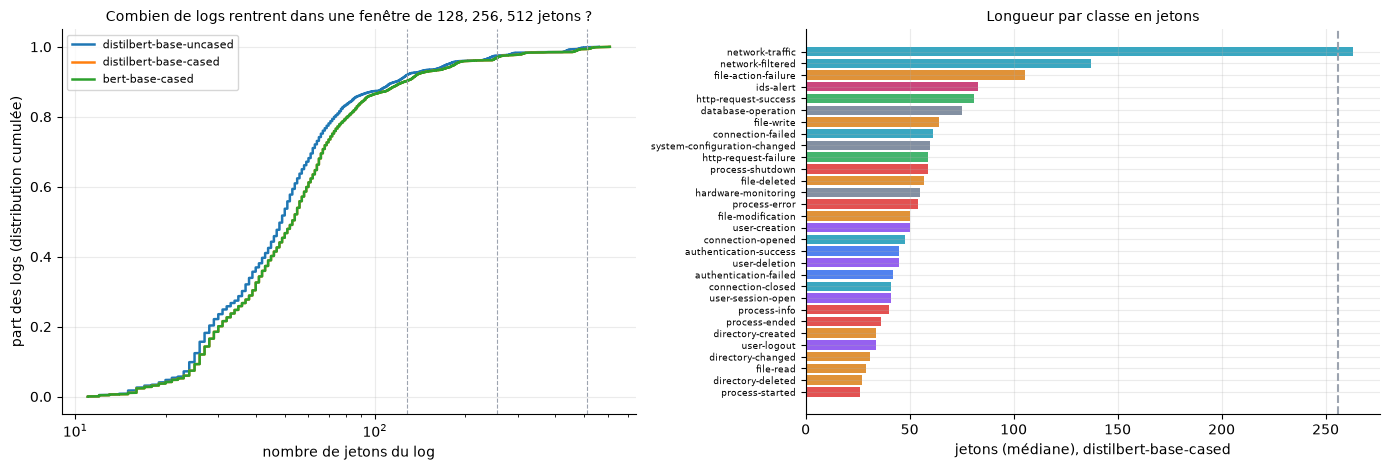

In [61]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
for m, L in tk_len.items(): xs = np.sort(L); ax[0].plot(xs, np.arange(1, len(xs) + 1) / len(xs), label=m, lw=1.8)
for w_ in (128, 256, 512): ax[0].axvline(w_, color=GREY, ls="--", lw=.8)
ax[0].set_xscale("log"); ax[0].set_xlabel("nombre de jetons du log"); ax[0].set_ylabel("part des logs (distribution cumulée)"); ax[0].set_title("Combien de logs rentrent dans une fenêtre de 128, 256, 512 jetons ?", fontsize=10); ax[0].legend(fontsize=8); ax[0].grid(alpha=.25)
bc = bycl.sort_values("jetons médiane"); ax[1].barh(range(30), bc["jetons médiane"], color=[FAM_COLORS[list(TAXONOMY).index(CHILD2FAM[c])] for c in bc.index], alpha=.8); ax[1].set_yticks(range(30)); ax[1].set_yticklabels(bc.index, fontsize=6.5)
ax[1].axvline(256, color=GREY, ls="--"); ax[1].set_xlabel("jetons (médiane), distilbert-base-cased"); ax[1].set_title("Longueur par classe en jetons", fontsize=10); ax[1].grid(axis="x", alpha=.25)
plt.tight_layout(); fig.savefig(DIRS["figures"] / "05_longueurs_jetons.png", dpi=140); plt.show()

**Lecture (termes techniques).**
- Un log occupe **49 jetons en médiane** (sans casse) ou **53** (avec casse) ; 95 % des logs tiennent en **175** ou **185** jetons ; le maximum est de **559** ou **608**.
- **Fragmentation forte** : **3,9 à 4,2 jetons par mot** (un texte anglais courant en produit nettement moins ; non mesuré ici). Les logs sont pleins d'identifiants et de mots techniques que WordPiece **découpe en morceaux**. Aucun jeton inconnu (`[UNK]` : 0 %) : le découpage ne perd rien.
- **Le tokenizer avec casse (cased) produit environ 8 % de jetons de plus** (médiane 53 contre 49) : il garde « Failed » et « failed » séparés, ce qui est exactement le fragment du vocabulaire vu à l'étape 4.
- **Troncature** : à 128 jetons, **8,0 %** (sans casse) et **9,7 %** (avec casse) des logs sont coupés ; à 256, **2,5 %** et **3,0 %** ; à 512, **0,1 %** et **0,7 %**.
- **Classes les plus longues** : `network-traffic` (médiane **263** jetons, **62 %** au-delà de 256) et `network-filtered` (137, **30 %** au-delà de 256).

**Décision (règle appliquée).** La plus petite fenêtre qui tronque au plus 3 % des logs est **256 jetons** (2,5 % et 3,0 %). **Mais** cette fenêtre tronque **62 %** des logs de `network-traffic` et **30 %** de `network-filtered` : la règle globale **cache** un problème par classe. **Parade** : à l'étape 6, un **contrôle** comparera les fenêtres 256 et 512 sur **ces deux classes** ; si l'écart est réel, on passe à 512 pour tout le monde.

## 5.5 Synthèse avec intervalles de confiance

**Référence** : TF-IDF mots. Chaque autre ligne est comparée à elle avec le **bootstrap par gabarit** de l'étape 4.

In [62]:
REF5 = "TF-IDF mots"; ref_pred = res5[REF5]["_pred"]; rows = []
for nm, r in res5.items():
    d = (0.0, 0.0, 0.0) if nm == REF5 else boot_delta(ref_pred, r["_pred"])
    verdict = "référence" if nm == REF5 else ("gain réel" if d[1] > 0 and d[0] >= 0.01 else "perte réelle" if d[2] < 0 and -d[0] >= 0.01 else "indistinguable")
    rows.append({"représentation": nm, "famille": "dense" if "|" in nm else "creuse", "dim": r["dim"], "F1 palier A": round(r["f1_A"], 4), "F1 à p=0": round(r["by_version"]["0"], 4), "F1 à p=0,5": round(r["by_version"]["5"], 4),
                 "F1 tous": round(r["f1_all"], 4), "Δ vs TF-IDF mots": round(d[0], 4), "IC 95 %": f"[{d[1]:+.4f} ; {d[2]:+.4f}]", "verdict": verdict})
syn5 = pd.DataFrame(rows); pd.set_option("display.width", 260); print(syn5.to_string(index=False)); syn5.to_csv(DIRS["results"] / "step5_representations.csv", index=False)

                       représentation famille    dim  F1 palier A  F1 à p=0  F1 à p=0,5  F1 tous  Δ vs TF-IDF mots             IC 95 %        verdict
                        BoW comptages  creuse   9880       0.4282    0.4362      0.4182   0.6084           -0.0351 [-0.0622 ; +0.0014] indistinguable
                          BoW binaire  creuse   9880       0.4344    0.4420      0.4222   0.6118           -0.0294 [-0.0599 ; +0.0024] indistinguable
             BoW comptages + norme L2  creuse   9880       0.4408    0.4467      0.4396   0.6225           -0.0246 [-0.0426 ; -0.0024]   perte réelle
                          TF-IDF mots  creuse   9880       0.4745    0.4816      0.4667   0.6426            0.0000 [+0.0000 ; +0.0000]      référence
              TF-IDF mots 1-2 grammes  creuse  75530       0.4901    0.4955      0.4814   0.6530            0.0029 [-0.0324 ; +0.0363] indistinguable
              TF-IDF mots 1-3 grammes  creuse 129485       0.4896    0.4927      0.4850   0.6524    

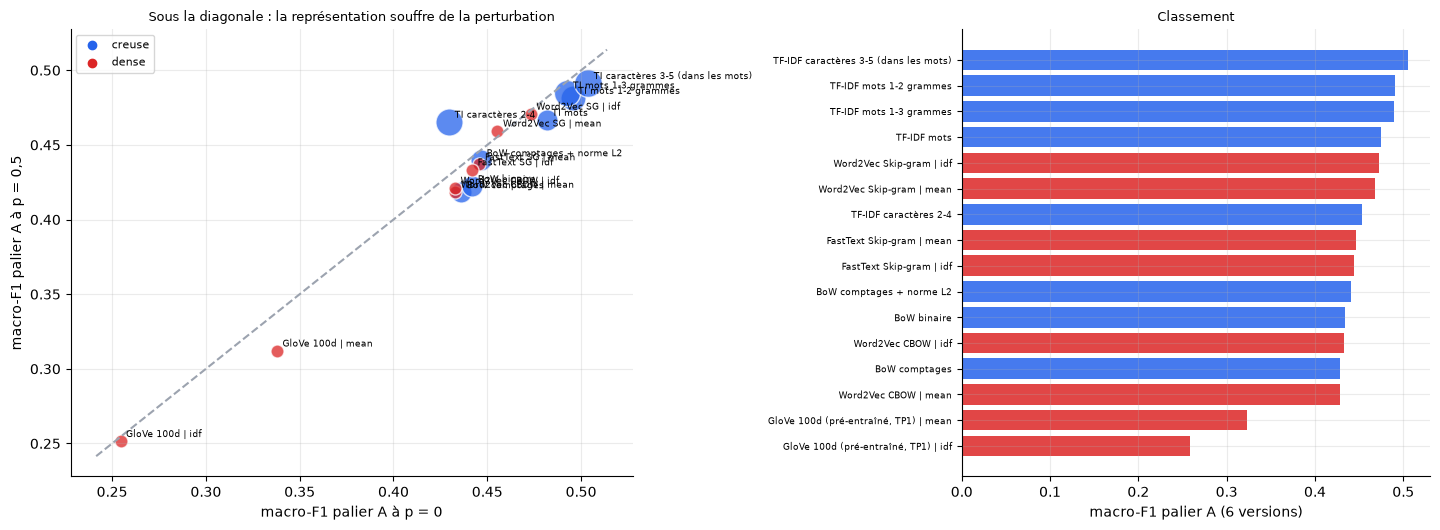

In [63]:
fig, ax = plt.subplots(1, 2, figsize=(14.5, 5.4), gridspec_kw={"width_ratios": [1.2, 1]})
colf = {"creuse": BLUE, "dense": RED}
for _, r in syn5.iterrows(): ax[0].scatter(r["F1 à p=0"], r["F1 à p=0,5"], s=40 + 12 * np.log10(r["dim"]) ** 2, color=colf[r["famille"]], alpha=.75, edgecolor="white"); ax[0].annotate(r["représentation"].replace("TF-IDF ", "TI ").replace(" (pré-entraîné, TP1)", "").replace(" Skip-gram", " SG"), (r["F1 à p=0"], r["F1 à p=0,5"]), fontsize=6.3, xytext=(4, 3), textcoords="offset points")
lim = [min(syn5["F1 à p=0"].min(), syn5["F1 à p=0,5"].min()) - .01, max(syn5["F1 à p=0"].max(), syn5["F1 à p=0,5"].max()) + .01]; ax[0].plot(lim, lim, color=GREY, ls="--")
ax[0].set_xlabel("macro-F1 palier A à p = 0"); ax[0].set_ylabel("macro-F1 palier A à p = 0,5"); ax[0].set_title("Sous la diagonale : la représentation souffre de la perturbation", fontsize=9.5); ax[0].grid(alpha=.25)
for f, c in colf.items(): ax[0].scatter([], [], color=c, label=f)
ax[0].legend(fontsize=8); srt = syn5.sort_values("F1 palier A"); lo = [float(x.split(";")[0].strip("[ +")) for x in srt["IC 95 %"]]; hi = [float(x.split(";")[1].strip("] +")) for x in srt["IC 95 %"]]
ax[1].barh(range(len(srt)), srt["F1 palier A"], color=[colf[f] for f in srt["famille"]], alpha=.85); ax[1].set_yticks(range(len(srt))); ax[1].set_yticklabels([n[:44] for n in srt["représentation"]], fontsize=6.8); ax[1].set_xlabel("macro-F1 palier A (6 versions)"); ax[1].set_title("Classement", fontsize=9.5); ax[1].grid(axis="x", alpha=.25)
plt.tight_layout(); fig.savefig(DIRS["figures"] / "05_representations.png", dpi=140); plt.show()

**Note de lecture sur la colonne « Δ ».** La colonne « F1 palier A » est la **moyenne des six macro-F1 par version**. La colonne « Δ » et son intervalle viennent du **bootstrap par gabarit**, qui recalcule la macro-F1 en **regroupant les prédictions des six versions** : c'est une autre façon d'agréger, donc le Δ peut **différer** de la simple différence des deux colonnes F1 (par exemple, un F1 de 0,4727 contre 0,4745 donne un Δ de −0,0197 plus bas). Les verdicts ci-dessous s'appuient sur **Δ et son intervalle**, jamais sur la différence des colonnes.

**Lecture de la figure.** À gauche, chaque point est une représentation (taille = log de la dimension) ; la diagonale marque « même score à p = 0 et à p = 0,5 ». **Presque tout est sur la diagonale** : aucune représentation ne souffre nettement de la perturbation entre p = 0 et p = 0,5 (les écarts sont de l'ordre de 0,01 à 0,03). Seuls les **n-grammes de caractères 2-4** sont *au-dessus* (0,4654 à p = 0,5 contre 0,4297 à p = 0) : le bruit de la perturbation y **aide** un peu, mais c'est un point isolé. À droite, le classement : les trois premiers sont creux (caractères 3-5, mots 1-2 et 1-3 grammes), puis le TF-IDF mots et le Skip-gram pondéré (0,4745 et 0,4727), et **loin derrière GloVe**.

**Lecture du tableau (termes techniques).**
- **Une seule perte réelle parmi les creuses** : le BoW normalisé (**−0,025**, IC [−0,043 ; −0,002]). Les deux GloVe sont les deux autres **pertes réelles** (−0,133 et −0,176).
- **Aucun gain réel.** Le meilleur écart est celui des caractères 3-5 (**+0,016**, IC [−0,045 ; +0,083]) : un intervalle qui s'étend de −0,045 à +0,083 ne permet pas d'affirmer qu'ils sont meilleurs que le TF-IDF mots.
- **Presque toutes les autres représentations sont « indistinguables »** : on ne peut pas les départager sur 36 gabarits. C'est le **résultat important** de l'étape : **la représentation compte beaucoup moins que le découpage** (étape 3 : 0,97 contre 0,46). Toutes les représentations plafonnent à environ **0,43 à 0,51** sur ce protocole sans fuite, alors que n'importe laquelle d'entre elles dépasse **0,97** avec un découpage aléatoire. Le facteur limitant n'est pas la façon de **coder** les logs, mais l'**information disponible** quand le gabarit est nouveau.

## 5.6 Finalistes pour l'étape 6 (règle écrite avant les chiffres)

**Règle.** (F1) la **référence** TF-IDF mots, toujours incluse ; (F2) la meilleure **autre** représentation creuse (par macro-F1 du palier A) ; (F3) la meilleure représentation **dense** ; (F4) l'**encodeur** Transformer, avec le test `uncased` contre `cased` annoncé à l'étape 4, et la fenêtre issue de 5.4.

In [64]:
sp_other = syn5[(syn5.famille == "creuse") & (syn5["représentation"] != REF5)].sort_values("F1 palier A", ascending=False).iloc[0]["représentation"]
dn_best = syn5[syn5.famille == "dense"].sort_values("F1 palier A", ascending=False).iloc[0]["représentation"]
tk_cased = tk_df.set_index("tokenizer").loc["distilbert-base-cased"]; tk_unc = tk_df.set_index("tokenizer").loc["distilbert-base-uncased"]
trunc = {w: {m: float(tk_df.set_index("tokenizer").loc[m, c].strip("%")) for m in ("distilbert-base-uncased", "distilbert-base-cased")} for w, c in ((128, "tronqués à 128"), (256, "à 256"), (512, "à 512"))}
MAXLEN = next(w for w in (128, 256, 512) if max(trunc[w].values()) <= 3.0)
FINALISTS = {"F1": REF5, "F2": sp_other, "F3": dn_best, "F4": f"encodeur {'distilbert-base-uncased'} contre {'distilbert-base-cased'} (fenêtre {MAXLEN} jetons)"}
(DIRS["results"] / "step5_finalistes.json").write_text(json.dumps({"finalistes": FINALISTS, "max_len": MAXLEN, "troncature_pct": trunc, "data_id": DATA_ID}, indent=1, ensure_ascii=False))
for k, v in FINALISTS.items(): print(f"{k} : {v}")
print("Troncature (% de logs) :", trunc)

F1 : TF-IDF mots
F2 : TF-IDF caractères 3-5 (dans les mots)
F3 : Word2Vec Skip-gram | idf
F4 : encodeur distilbert-base-uncased contre distilbert-base-cased (fenêtre 256 jetons)
Troncature (% de logs) : {128: {'distilbert-base-uncased': 8.0, 'distilbert-base-cased': 9.7}, 256: {'distilbert-base-uncased': 2.5, 'distilbert-base-cased': 3.0}, 512: {'distilbert-base-uncased': 0.1, 'distilbert-base-cased': 0.7}}


**Lecture.** **F1** TF-IDF mots (référence, 9 880 colonnes) ; **F2** TF-IDF caractères 3-5 (le meilleur creux, malgré son coût) ; **F3** Word2Vec Skip-gram pondéré IDF (le meilleur dense, 100 colonnes) ; **F4** encodeur DistilBERT sans casse **contre** avec casse, fenêtre **256** jetons, contrôle 256 contre 512 sur les classes `network-*`.

**Ce qu'on n'a pas fait (dit honnêtement).** (1) Les représentations **contextuelles gelées** n'ont **pas** été mesurées : l'encodeur est **affiné** et évalué en 6.10, 7.8 et 9.11. La comparaison sans casse / avec casse y est faite sur les 5 rotations (validation) et la fenêtre 256 contre 512 sur la **rotation 1 entière**, et non sur les seules classes `network-*` prévues : **écart au plan**, assumé ici. (2) Les **vecteurs de mots ne sont pas affinés** (on garde les valeurs usuelles) : un meilleur réglage pourrait changer leur rang. (3) On a mesuré avec **un seul classifieur** (SVM linéaire) ; l'étape 6 croise représentations et classifieurs. (4) Les **intervalles larges** viennent du petit nombre de gabarits de validation : un écart de moins de 0,05 est ici **indétectable**.

**Registre (suite).**

| N° | Affirmation | Source | Niveau |
|---|---|---|---|
| V29 | SVM linéaire, palier A, gabarits jamais vus : TF-IDF mots 0,4745 ; 1-2 grammes 0,4901 ; 1-3 grammes 0,4896 ; caractères 3-5 0,5050 ; caractères 2-4 0,4537 ; BoW 0,4282 / 0,4344 / 0,4408 (comptages, binaire, normalisé) ; tous « indistinguables » de la référence sauf BoW normalisé (perte réelle −0,025) | Calcul | calcul (puissance limitée) |
| V30 | Vecteurs de mots appris sur nos logs : Skip-gram pondéré IDF 0,4727, Skip-gram 0,4677, FastText 0,4460, CBOW 0,4278 ; GloVe pré-entraîné 0,3230 et 0,2588 (pertes réelles −0,133 et −0,176) ; couverture : 94,3 % (Skip-gram), 85,6 % (GloVe) | Calcul | calcul |
| V31 | Les voisins des mots dans nos Skip-gram sont des synonymes de dictionnaire (*failed* : *unsuccessful*, *unmet*) ; lien avec le remplacement de synonymes de SPICE : hypothèse plausible, non démontrée | Calcul + lecture de l'article | calcul + hypothèse |
| V32 | Longueur en jetons (distilbert-base-uncased / cased) : médiane 49 / 53, p95 175 / 185, 3,9 / 4,2 jetons par mot, [UNK] 0 % ; troncature à 256 : 2,5 % / 3,0 % ; `network-traffic` : médiane 263 jetons, 62 % > 256 | Calcul | calcul |
| V33 | Fenêtre retenue : 256 jetons (règle : plus petite fenêtre avec ≤ 3 % de troncature) ; contrôle 256 contre 512 sur `network-*` à l'étape 6 | Décision | convention |
| V34 | WordPiece (tokenizer de BERT) et mécanisme d'attention : définitions et références originales | connaissances à vérifier | **non sourcé** : à vérifier |

**Bilan de l'étape 5.** Toutes les représentations plafonnent entre 0,43 et 0,51 sur des gabarits jamais vus : le choix de la représentation compte **bien moins** que le découpage. Le **seul** résultat net est négatif : un **GloVe pré-entraîné ne convient pas** au jargon des logs (perte réelle −0,13 à −0,18). Les finalistes sont fixés ; la fenêtre de l'encodeur (256 jetons) est choisie avec un contrôle prévu sur les classes longues.

**Prochaine étape.** Étape 6 : modèles (classifieur à plat, classifieur hiérarchique, scores d'inconnu et rejet), avec sauvegarde des modèles.

<!-- REV-5.8 -->
## 5.8 Ajouts après la discussion de l'étape 5 : les contraires, et un test du décalage de domaine

**Pourquoi.** En discutant l'étape 5, deux affirmations sont restées **sans mesure** : (a) Word2Vec rapproche des mots qui apparaissent dans les mêmes contextes, donc peut-être aussi des **contraires** (*failed* / *accepted*) ; (b) l'encodeur pré-entraîné ne bat pas TF-IDF, et notre explication principale (le pré-entraînement porte sur du texte courant, pas sur des logs : **décalage de domaine**) n'avait **jamais été testée**. On les mesure ici, sans toucher aux sections précédentes.

### 5.8a Les contraires dans nos vecteurs Skip-gram

On compare le cosinus de paires de **contraires** et de **synonymes** au cosinus de **paires aléatoires** de mots fréquents (la référence : ce qu'est une proximité « sans lien »).

In [65]:
# ---- R5.8a : les contraires dans nos vecteurs Skip-gram
wv = embedders["w2v_sg"].wv_
PAIRS_ANT = [("failed", "accepted"), ("allowed", "denied"), ("opened", "closed"), ("created", "deleted"), ("enabled", "disabled"), ("started", "stopped"), ("success", "failure")]
PAIRS_SYN = [("failed", "unsuccessful"), ("deleted", "erased")]
top = wv.index_to_key[:5000]; rng_ = np.random.default_rng(CONFIG["seed"])
ia, ib = rng_.integers(0, len(top), 4000), rng_.integers(0, len(top), 4000); keep = ia != ib
Va = np.stack([wv[top[i]] for i in ia[keep]]); Vb = np.stack([wv[top[i]] for i in ib[keep]])
rand_cos = (Va * Vb).sum(1) / (np.linalg.norm(Va, axis=1) * np.linalg.norm(Vb, axis=1))
rows = []
for kind, plist in (("contraires", PAIRS_ANT), ("synonymes", PAIRS_SYN)):
    for a, b in plist:
        if a not in wv.key_to_index or b not in wv.key_to_index: rows.append({"type": kind, "paire": f"{a} / {b}", "cosinus": None, "rang de la 2e parmi les voisins de la 1re": "mot absent", "part des paires aléatoires moins proches": None}); continue
        c = float(wv.similarity(a, b)); rank = [w for w, _ in wv.most_similar(a, topn=len(wv.key_to_index))].index(b) + 1
        rows.append({"type": kind, "paire": f"{a} / {b}", "cosinus": round(c, 3), "rang de la 2e parmi les voisins de la 1re": f"{rank:,} sur {len(wv.key_to_index):,}", "part des paires aléatoires moins proches": f"{(rand_cos < c).mean():.0%}"})
ant_df = pd.DataFrame(rows); print(ant_df.to_string(index=False))
print(f"\nRéférence : {len(rand_cos):,} paires aléatoires parmi les 5 000 mots les plus fréquents ; cosinus médian {np.median(rand_cos):.3f}, 90e centile {np.quantile(rand_cos, .9):.3f}.")
ant_df.to_csv(DIRS["results"] / "step5_contraires_skipgram.csv", index=False)


      type                 paire  cosinus rang de la 2e parmi les voisins de la 1re part des paires aléatoires moins proches
contraires     failed / accepted    0.355                          1,557 sur 24,485                                      57%
contraires      allowed / denied    0.282                         13,525 sur 24,485                                      34%
contraires       opened / closed    0.593                             58 sur 24,485                                      91%
contraires     created / deleted    0.479                            351 sur 24,485                                      80%
contraires    enabled / disabled    0.406                         15,490 sur 24,485                                      68%
contraires     started / stopped    0.332                          7,932 sur 24,485                                      50%
contraires     success / failure    0.203                         22,584 sur 24,485                                      14%


**Lecture (5.8a).**
- **Les contraires ne sont pas systématiquement rapprochés, mais certains le sont.** `opened` / `closed` : cosinus **0,593**, rang **58** sur 24 485 mots ; `created` / `deleted` : **0,479**, rang **351** ; `failed` / `accepted` : **0,355**, rang **1 557** (dans la moyenne des paires aléatoires : 57 % de paires aléatoires moins proches) ; `success` / `failure` : **0,203** (loin : 14 %). Les **synonymes** sont bien plus proches : `failed` / `unsuccessful` **0,852** (rang 3), `deleted` / `erased` **0,879** (rang 2).
- **Conclusion mesurée.** La limite annoncée (des mots opposés qui apparaissent dans les mêmes contextes peuvent avoir des vecteurs voisins) est **réelle pour certaines paires** (`opened`/`closed`, `created`/`deleted`), **absente pour d'autres**. Elle ne remet pas en cause la comparaison de l'étape 5 ; elle est une **raison de prudence** pour interpréter les voisins d'un mot.

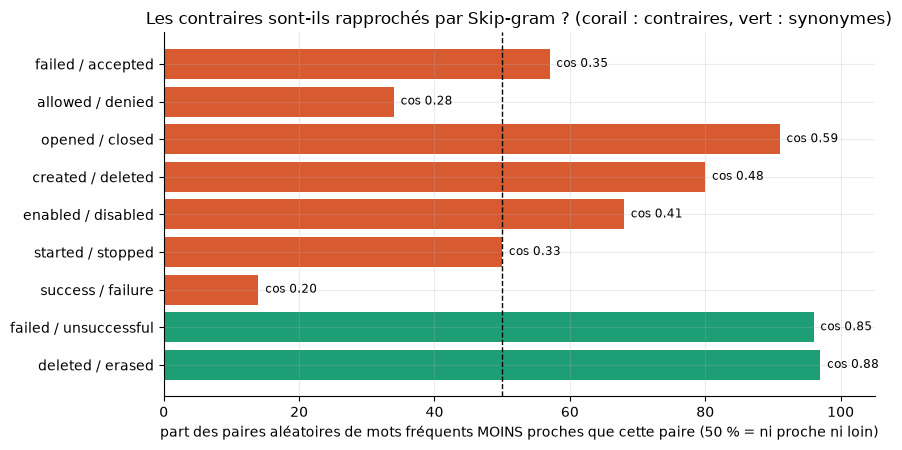

In [66]:
import tp2_new_figs as NF
fig = NF.fig_5_8a(DIRS["results"], DIRS["figures"]); plt.show()

**Lecture du visuel.** Chaque barre dit si la paire de mots est **plus proche** que des paires de mots tirés au hasard (50 % = ni proche ni loin). Les **synonymes** (vert) sont très proches ; les **contraires** (corail) dépendent de la paire : `opened`/`closed` sont proches, `success`/`failure` sont loin.

### 5.8b Test du décalage de domaine : encodeur **gelé**, pré-entraîné contre initialisé au hasard

**Principe.** On ne réentraîne rien. On extrait un vecteur par log (moyenne des vecteurs de jetons, 768 nombres) avec **deux copies de la même architecture** DistilBERT et le **même tokenizer** : l'une **pré-entraînée**, l'autre **initialisée au hasard** (mêmes poids de départ à chaque exécution, graine fixée). On entraîne ensuite le **même** classifieur linéaire sur chacun, avec le protocole des représentations précédentes (mêmes 59 940 logs d'entraînement, mêmes 23 940 de validation, bootstrap par gabarit).

**Ce que le test mesure.** Si le pré-entraînement n'apporte rien sur des logs, les deux copies donnent le même résultat. Si l'écart entre les deux est grand, le pré-entraînement porte une information utile pour les logs.

**Règles de lecture, fixées avant d'avoir vu les résultats** (on utilise les mêmes seuils qu'ailleurs : « gain réel » si Δ ≥ 0,01 et borne basse de l'IC > 0) :
- **R1** : pré-entraîné **indistinguable** de l'initialisé au hasard → le pré-entraînement n'apporte **rien** sur les logs : compatible avec le décalage de domaine.
- **R2** : pré-entraîné **gain réel** sur l'initialisé au hasard, mais **sous** TF-IDF → le pré-entraînement aide mais ne suffit pas : le décalage de domaine n'explique **qu'en partie**.
- **R3** : pré-entraîné **au niveau de** TF-IDF ou au-dessus → l'hypothèse « le pré-entraînement ne sert pas » est **réfutée** pour l'état gelé.

**Limites dites d'avance.** Un encodeur gelé n'est **pas** l'encodeur affiné des étapes 6 à 9 : le test ne dit rien de l'affinage. Un transformeur initialisé au hasard reste un extracteur de traits utilisable (la moyenne de projections aléatoires conserve une partie de l'information lexicale), donc l'écart mesuré est une **borne basse** de l'apport du pré-entraînement.

In [67]:
# ---- R5.8b : encodeur GELÉ, pré-entraîné contre initialisé au hasard (même architecture, même tokenizer, aucun affinage)
import torch
from transformers import AutoModel, AutoConfig, AutoTokenizer
ENC_NAME = "distilbert-base-uncased"; FROZEN_DIR = DIRS["features"] / "frozen_encoder"; FROZEN_DIR.mkdir(exist_ok=True)
FDEV = "mps" if torch.backends.mps.is_available() else "cpu"
tk_f = AutoTokenizer.from_pretrained(ENC_NAME)
def frozen_vectors(texts, tag, pretrained, max_len=256, bs=64):
    path = FROZEN_DIR / f"{tag}_{DATA_ID[:8]}_{len(texts)}.npy"
    if path.exists(): return np.load(path)
    torch.manual_seed(int(CONFIG["seed"]))
    model = (AutoModel.from_pretrained(ENC_NAME) if pretrained else AutoModel.from_config(AutoConfig.from_pretrained(ENC_NAME))).to(FDEV).eval()
    order = np.argsort([len(t) for t in texts]); out = np.zeros((len(texts), model.config.dim), dtype=np.float32); part = path.with_suffix(".partial.npz"); start = 0
    if part.exists():                                                                       # REPRISE : on repart du dernier lot sauvegardé
        z = np.load(part); out, start = z["out"], int(z["next"]); print(f"  reprise de l'extraction {tag} au log {start}/{len(texts)}", flush=True)
    with torch.no_grad():
        for s in range(start, len(texts), bs):
            idx = order[s:s + bs]; b = tk_f([texts[i] for i in idx], padding=True, truncation=True, max_length=max_len, return_tensors="pt").to(FDEV)
            h = model(**b).last_hidden_state; m = b["attention_mask"].unsqueeze(-1).to(h.dtype)
            out[idx] = ((h * m).sum(1) / m.sum(1)).float().cpu().numpy()          # moyenne des vecteurs de jetons (hors bourrage)
            if (s // bs) % 50 == 49: np.savez(str(part) + ".tmp.npz", out=out, next=s + bs); os.replace(str(part) + ".tmp.npz", part)
    np.save(path, out); part.unlink(missing_ok=True); del model; return out
def frozen_feat(tag, pretrained):
    def f(a, b):
        Xa = frozen_vectors(a, tag + "_tr", pretrained); Xb = frozen_vectors(b, tag + "_va", pretrained); sc = StandardScaler().fit(Xa)
        return sc.transform(Xa), sc.transform(Xb), {}
    return f
res5b = {}
for nm, (tag, pre) in {"Encodeur gelé, pré-entraîné": ("pre", True), "Encodeur gelé, initialisé au hasard": ("rnd", False)}.items():
    r = evaluate_rep(nm, [tag, ENC_NAME], frozen_feat(tag, pre), lin_dense, extra=("frozen1",)); res5b[nm] = r
    print(f"{nm:<38} dim={r['dim']}  F1 palier A={r['f1_A']:.4f}  F1 tous={r['f1_all']:.4f}  [{'cache' if r['cached'] else str(round(r['secs'])) + ' s'}]")
P_TF, P_PRE, P_RND = res5[REF5]["_pred"], res5b["Encodeur gelé, pré-entraîné"]["_pred"], res5b["Encodeur gelé, initialisé au hasard"]["_pred"]
def verdict_of(d): return "gain réel" if d[1] > 0 and d[0] >= 0.01 else "perte réelle" if d[2] < 0 and -d[0] >= 0.01 else "indistinguable"
cmp_rows = []
for lab, (pa, pb) in {"pré-entraîné contre TF-IDF mots": (P_TF, P_PRE), "initialisé au hasard contre TF-IDF mots": (P_TF, P_RND), "pré-entraîné contre initialisé au hasard": (P_RND, P_PRE)}.items():
    d = boot_delta(pa, pb); cmp_rows.append({"comparaison (Δ = second moins premier)": lab, "Δ macro-F1": round(d[0], 4), "IC 95 %": f"[{d[1]:+.4f} ; {d[2]:+.4f}]", "verdict": verdict_of(d)})
cmp_df = pd.DataFrame(cmp_rows); print("\n" + cmp_df.to_string(index=False)); cmp_df.to_csv(DIRS["results"] / "step5_encodeur_gele.csv", index=False)


Encodeur gelé, pré-entraîné            dim=768  F1 palier A=0.4547  F1 tous=0.6157  [cache]
Encodeur gelé, initialisé au hasard    dim=768  F1 palier A=0.4447  F1 tous=0.6123  [cache]

  comparaison (Δ = second moins premier)  Δ macro-F1             IC 95 %        verdict
         pré-entraîné contre TF-IDF mots     -0.0369 [-0.1308 ; +0.0374] indistinguable
 initialisé au hasard contre TF-IDF mots     -0.0488 [-0.1188 ; +0.0137] indistinguable
pré-entraîné contre initialisé au hasard      0.0119 [-0.0312 ; +0.0506] indistinguable


**Lecture (5.8b).**
- **Résultats (macro-F1 du palier A).** TF-IDF mots **0,4745** ; encodeur gelé pré-entraîné **0,4547** ; encodeur gelé initialisé au hasard **0,4447**.
- **Pré-entraîné contre initialisé au hasard** : Δ = **+0,0119**, IC 95 % **[−0,0312 ; +0,0506]** : **indistinguable**. **Pré-entraîné contre TF-IDF** : Δ = −0,0369 [−0,1308 ; +0,0374], et **initialisé au hasard contre TF-IDF** : Δ = −0,0488 [−0,1188 ; +0,0137] : indistinguables aussi (le Δ vient du bootstrap par gabarit, il peut différer de la différence des colonnes F1).
- **Application de la règle R1** (écrite avant les chiffres) : le pré-entraînement **n'apporte rien de mesurable** sur nos logs à l'état gelé. C'est **compatible** avec un décalage entre le langage du pré-entraînement et celui des logs ; ce **n'est pas une preuve** : l'intervalle est large (environ ± 0,04, donc un petit gain ne peut être exclu), l'état gelé n'est pas l'état affiné des étapes 6 à 9, et un transformeur au hasard reste un extracteur de traits utilisable.
- **Formulation retenue pour la défense.** « L'encodeur pré-entraîné ne bat pas TF-IDF sur nos logs. À l'état gelé, le pré-entraînement n'apporte pas de gain mesurable par rapport à un encodeur initialisé au hasard, ce qui est compatible avec un décalage de domaine, sans le prouver. »

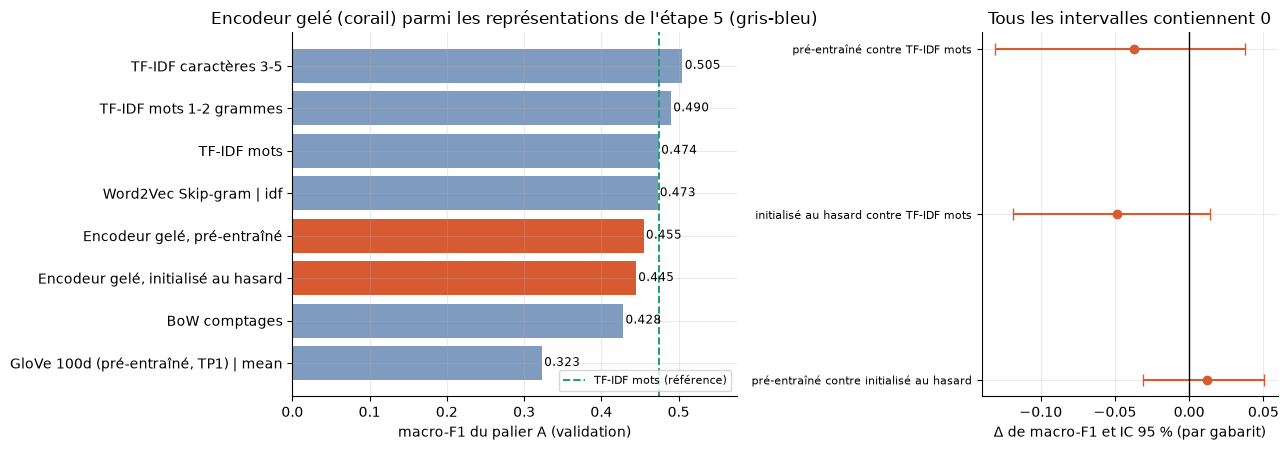

In [68]:
import tp2_new_figs as NF
fig = NF.fig_5_8b(DIRS["results"], DIRS["figures"]); plt.show()

**Lecture du visuel.** À gauche, les **représentations de l'étape 5** (gris-bleu) et les deux **encodeurs gelés** (corail) classés par macro-F1 : ils se placent juste sous TF-IDF mots (trait vert). À droite, les écarts avec leurs intervalles : **tous contiennent 0**, donc rien n'est démontré entre le pré-entraîné, l'initialisé au hasard et TF-IDF.

### 5.8c La fragmentation : contrôle exploratoire

**Principe.** Si la découpe en morceaux (3,9 jetons par mot) gênait l'encodeur, l'écart avec TF-IDF devrait **croître** avec le nombre de jetons par mot. On découpe les logs de validation du palier A en trois groupes de même taille selon cette valeur.

**Limite dite d'avance.** C'est une **corrélation**, pas une expérience : les logs très fragmentés sont aussi ceux de certaines classes (les `network-*` sont longs). Un écart croissant serait **compatible** avec l'hypothèse, un écart stable ne la confirmerait pas non plus.

In [69]:
# ---- R5.8c : la fragmentation (jetons par mot) explique-t-elle l'écart ? Contrôle EXPLORATOIRE, non causal
lens = np.array([len(x) for x in tk_f(list(va_text), add_special_tokens=True, truncation=False)["input_ids"]]); nw = np.array([max(1, len(t.split())) for t in va_text]); tpw = lens / nw
cuts = np.quantile(tpw[mask_A_rows], [1 / 3, 2 / 3]); grp = np.digitize(tpw, cuts); rows = []
for g, lab in enumerate(["peu fragmentés", "moyens", "très fragmentés"]):
    m = mask_A_rows & (grp == g)
    rows.append({"tiers de logs (palier A)": lab, "jetons par mot (moyenne)": round(float(tpw[m].mean()), 2), "logs": int(m.sum()), "exactitude TF-IDF": round(float((P_TF[m] == yva_i[m]).mean()), 3), "exactitude encodeur gelé": round(float((P_PRE[m] == yva_i[m]).mean()), 3)})
fr_df = pd.DataFrame(rows); fr_df["écart (TF-IDF moins encodeur)"] = (fr_df["exactitude TF-IDF"] - fr_df["exactitude encodeur gelé"]).round(3); print(fr_df.to_string(index=False)); fr_df.to_csv(DIRS["results"] / "step5_fragmentation.csv", index=False)


tiers de logs (palier A)  jetons par mot (moyenne)  logs  exactitude TF-IDF  exactitude encodeur gelé  écart (TF-IDF moins encodeur)
          peu fragmentés                      2.31  4782              0.511                     0.395                          0.116
                  moyens                      3.44  4794              0.805                     0.673                          0.132
         très fragmentés                      6.66  4788              0.260                     0.370                         -0.110


**Lecture (5.8c).** L'écart d'exactitude entre TF-IDF et l'encodeur gelé ne **croît pas** avec la fragmentation : **+0,116** (logs peu fragmentés, 2,31 jetons par mot), **+0,132** (moyens, 3,44), **−0,110** (très fragmentés, 6,66 : l'encodeur fait **mieux** que TF-IDF). L'hypothèse « la découpe en morceaux gêne l'encodeur » **n'est pas soutenue** par ce contrôle. *Limite :* les logs très fragmentés appartiennent surtout à certaines classes (les `network-*` sont longs) ; c'est une corrélation, pas une expérience.

**Hypothèses de l'étape 5 non testées (dit honnêtement).** L'affinage sur seulement 440 gabarits (mémorisation) et la dépendance à une seule graine d'affinage n'ont **pas** été testés : ils demandent plusieurs affinages (calcul GPU).

**Registre (suite).**

| N° | Affirmation | Source | Niveau |
|---|---|---|---|
| V83 | Contraires dans Skip-gram : `opened`/`closed` cosinus 0,593 (rang 58), `created`/`deleted` 0,479 (351), `failed`/`accepted` 0,355 (1 557), `success`/`failure` 0,203 ; synonymes `failed`/`unsuccessful` 0,852 (rang 3), `deleted`/`erased` 0,879 (rang 2) | Calcul (5.8a) | calcul |
| V84 | Encodeur gelé : pré-entraîné 0,4547, initialisé au hasard 0,4447, TF-IDF 0,4745 ; Δ pré-entraîné moins hasard +0,0119 IC [−0,0312 ; +0,0506] : indistinguable ; compatible avec un décalage de domaine, non prouvé | Calcul (5.8b) | calcul (puissance limitée) |
| V85 | Écart TF-IDF moins encodeur gelé par tiers de fragmentation : +0,116 ; +0,132 ; −0,110 : ne croît pas | Calcul (5.8c) | calcul (corrélation) |

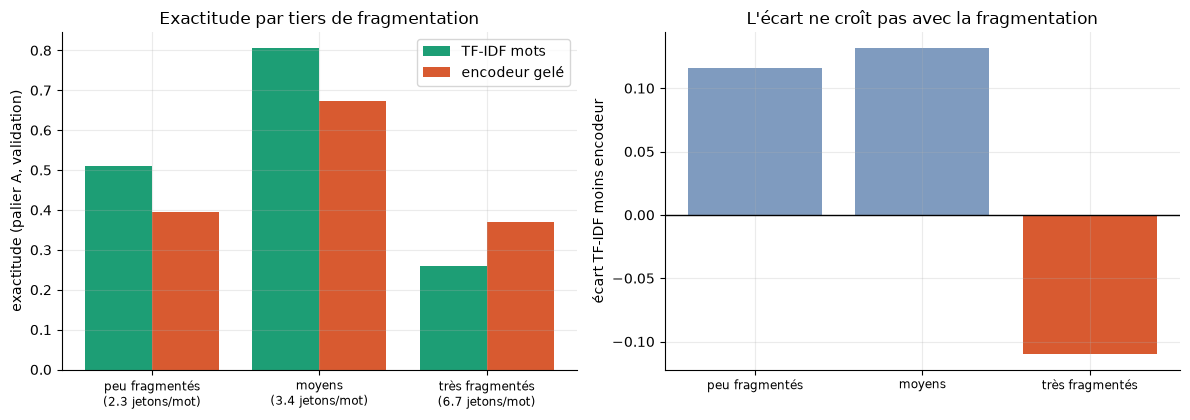

In [70]:
import tp2_new_figs as NF
fig = NF.fig_5_8c(DIRS["results"], DIRS["figures"]); plt.show()

**Lecture du visuel.** À gauche, l'exactitude par tiers de logs (du moins au plus fragmenté en jetons) pour TF-IDF (vert) et l'encodeur gelé (corail). À droite, l'écart : il **ne grandit pas** avec la fragmentation (il s'inverse même pour le tiers le plus fragmenté).

<!-- REV-5.9 -->
## 5.9 Les fichiers du professeur (SIEVE, 35 000 logs par version) : fuite sur données fraîches et taille du jeu

**Les fichiers.** Le professeur a fourni six fichiers, `output_0.log` à `output_0.5.log` (dossier `TP/`) : un par niveau de perturbation p = 0 ; 0,1 ; … ; 0,5, de **35 000 logs** chacun, avec les 30 classes **équilibrées** (environ 1 167 logs par classe). L'article de SIEVE décrit une première itération de **35 000** échantillons, puis des tailles de 50 000 et de 100 000 : ce sont les versions de **35 000**. Les fichiers `SIEVE_xx_100K.csv` utilisés jusqu'ici sont les versions de **100 000**. On dispose donc de **12 fichiers**, tous utilisés ci-dessous.

**Ce qu'ils sont, mesuré avant de s'en servir.** Les logs du professeur sont **nouveaux** (12 logs sur 35 000 seulement sont identiques à ceux de `SIEVE_00_100K.csv`, 0 pour les cinq autres), mais ils viennent des **mêmes gabarits** : à p = 0, **24,7 %** ont un quasi-jumeau (cosinus d'au moins 0,90) dans `SIEVE_00_100K.csv`, presque exactement le taux d'un découpage aléatoire de l'étape 3 (25,4 %) ; la classe du plus proche est la même dans 92 % des cas. Ce sont donc des **valeurs nouvelles sur des gabarits connus**.

**Ce qu'ils permettent, et ce qu'ils ne permettent pas.** Ils **ne mesurent pas** la généralisation à des gabarits nouveaux et **ne remplacent pas** le test scellé de l'étape 7 (qui n'est pas touché ici). Ils servent à **trois contrôles** :
- **(a) Fuite sur données fraîches.** On entraîne TF-IDF + SVM linéaire sur l'entraînement de SIEVE (découpage **par gabarit** de l'étape 3) et on l'évalue sur les six fichiers du professeur.
- **(b) Taille du jeu.** On entraîne sur un fichier de 100 000 logs et on teste sur le fichier de 35 000 de même p, puis l'inverse, pour les six p.
- **(c) Courbe de taille et quasi-jumeaux.** Macro-F1 selon le nombre de logs d'entraînement, avec un découpage **aléatoire** (mêmes gabarits) et un découpage **par gabarit** (gabarits nouveaux) ; part de quasi-jumeaux selon p.

**Hypothèses, écrites avant les chiffres.**
- **H13 (fuite sur données fraîches).** Le modèle entraîné sur les gabarits d'entraînement obtient une macro-F1 **d'au moins 0,90** sur le fichier du professeur à p = 0, **décroissante avec p**, et l'écart avec la validation (gabarits nouveaux) est **d'au moins 0,25**. *Réfutée* si le score est sous 0,90 ou l'écart sous 0,25.
- **H14 (taille).** Avec un découpage **aléatoire**, la macro-F1 **croît puis sature** (gain de 35 000 à 60 000 logs **inférieur à 0,01**, comme l'article : « gains négligeables ») ; avec un découpage **par gabarit**, elle reste **à peu près plate** (écart entre le plus petit et le plus grand entraînement **inférieur à 0,05**). *Réfutée* sinon.
- **H15 (quasi-jumeaux).** La part de quasi-jumeaux est d'environ **25 % à p = 0** et **décroît** quand p augmente.

*Limites dites d'avance :* un seul modèle (TF-IDF mots + SVM linéaire, `C = 1`) ; une seule graine d'échantillonnage ; les logs du professeur sont des tirages du même générateur, pas des logs réels ; le résultat (a) n'est **pas** une évaluation du système, c'est une **mise en évidence de la fuite**. La provenance des fichiers (générateur de SIEVE, taille 35 000) a été vérifiée dans l'article, pas auprès du professeur.

In [71]:
# ---- R5.9a : lecture des 12 fichiers et fuite sur données fraîches (entraîné sur SIEVE 100K, testé sur les logs du professeur)
from sklearn.metrics import accuracy_score
PROF = PROJECT_ROOT.parent; P_NAMES = ["0", "0.1", "0.2", "0.3", "0.4", "0.5"]; CACHE59 = DIRS["results"] / "cache_step5_prof"; CACHE59.mkdir(exist_ok=True)
def read_prof(name):
    cats, txt = [], []
    with open(PROF / f"output_{name}.log", encoding="utf-8", errors="replace", newline="") as f:
        next(f)
        for line in f:
            line = line.rstrip("\r\n"); i = line.find(",")
            if i > 0: cats.append(line[:i]); txt.append(line[i + 1:])
    return np.array(cats), txt
FRESH = {p: read_prof(p) for p in P_NAMES}; assert all(set(c) == set(PAPER_CLASSES) for c, _ in FRESH.values())
CATFULL = {v: V[v]["category"].values for v in range(6)}; TXTFULL = {v: list(LOG[v]) for v in range(6)}                       # les 6 fichiers SIEVE_xx_100K au complet
print("Fichiers du professeur :", {p: len(t) for p, (c, t) in FRESH.items()}, "| SIEVE 100K :", {v: len(t) for v, t in TXTFULL.items()})
def fit_eval(tag, train_txt, y_train, evals):
    cj = CACHE59 / f"{hashlib.sha256(json.dumps([tag, DATA_ID, len(train_txt), {k: len(v[0]) for k, v in evals.items()}, 's59v1'], sort_keys=True).encode()).hexdigest()[:16]}.json"
    if cj.exists(): return json.loads(cj.read_text())
    vec = TfidfVectorizer(analyzer=word_tokens, min_df=2, sublinear_tf=True, dtype=np.float32); Xtr = vec.fit_transform(train_txt); clf = LinearSVC(C=1.0).fit(Xtr, y_train); res = {"n_train": len(train_txt), "dim": int(Xtr.shape[1])}
    for nm, (t, y) in evals.items(): pr = clf.predict(vec.transform(t)); res[nm] = {"f1": float(f1_score(y, pr, average="macro")), "acc": float(accuracy_score(y, pr))}
    cj.write_text(json.dumps(res)); return res
t0 = time.perf_counter(); evA = {"validation (gabarits nouveaux)": (va_text, yva), **{f"fichier du professeur p={p}": (t, c) for p, (c, t) in FRESH.items()}}
rA = fit_eval("A_train_gabarits", tr_text, ytr, evA); rowsA = [{"jeu évalué": k, "macro-F1 (30 classes)": round(v["f1"], 4), "exactitude": round(v["acc"], 4)} for k, v in rA.items() if isinstance(v, dict)]
dfA = pd.DataFrame(rowsA); print(f"Modèle TF-IDF mots + SVM linéaire entraîné sur {rA['n_train']:,} logs d'entraînement de SIEVE (découpage par gabarit de l'étape 3), {rA['dim']:,} colonnes ; durée {time.perf_counter() - t0:.0f} s"); print(dfA.to_string(index=False)); dfA.to_csv(DIRS["results"] / "step5_donnees_fraiches.csv", index=False)


Fichiers du professeur : {'0': 35000, '0.1': 35000, '0.2': 35000, '0.3': 35000, '0.4': 35000, '0.5': 35000} | SIEVE 100K : {0: 100000, 1: 100000, 2: 100000, 3: 100000, 4: 100000, 5: 100000}
Modèle TF-IDF mots + SVM linéaire entraîné sur 59,940 logs d'entraînement de SIEVE (découpage par gabarit de l'étape 3), 9,880 colonnes ; durée 0 s
                    jeu évalué  macro-F1 (30 classes)  exactitude
validation (gabarits nouveaux)                 0.6426      0.6891
     fichier du professeur p=0                 0.8107      0.8103
   fichier du professeur p=0.1                 0.8087      0.8083
   fichier du professeur p=0.2                 0.8072      0.8067
   fichier du professeur p=0.3                 0.8037      0.8033
   fichier du professeur p=0.4                 0.8019      0.8016
   fichier du professeur p=0.5                 0.7985      0.7979


In [72]:
# ---- R5.9b : effet de la taille du jeu : 100K contre 35K, dans les deux sens, pour les six niveaux de perturbation (reprise : cache par apprentissage)
rowsB = []; t0 = time.perf_counter()
for k, p in enumerate(P_NAMES):
    cF, tF = FRESH[p]; r100 = fit_eval(f"B_100K_vers_35K_{p}", TXTFULL[k], CATFULL[k], {"35K": (tF, cF)}); r35 = fit_eval(f"B_35K_vers_100K_{p}", tF, cF, {"100K": (TXTFULL[k], CATFULL[k])})
    rowsB.append({"p": float(p), "entraîné sur 100K, testé sur 35K": round(r100["35K"]["f1"], 4), "entraîné sur 35K, testé sur 100K": round(r35["100K"]["f1"], 4), "colonnes (100K)": r100["dim"], "colonnes (35K)": r35["dim"]})
dfB = pd.DataFrame(rowsB); print(f"durée {time.perf_counter() - t0:.0f} s"); print(dfB.to_string(index=False)); dfB.to_csv(DIRS["results"] / "step5_taille_croisee.csv", index=False)


durée 0 s
  p  entraîné sur 100K, testé sur 35K  entraîné sur 35K, testé sur 100K  colonnes (100K)  colonnes (35K)
0.0                            0.9721                            0.9732             7739            4629
0.1                            0.9713                            0.9708            12122            6493
0.2                            0.9695                            0.9690            14419            7589
0.3                            0.9685                            0.9662            15827            8021
0.4                            0.9673                            0.9649            16652            8480
0.5                            0.9668                            0.9630            17295            8644


In [73]:
# ---- R5.9c : courbe de taille (version p = 0) : découpage aléatoire (même gabarits) contre découpage par gabarit (gabarits nouveaux)
SIZES = [2000, 5000, 10000, 20000, 35000, 60000]; rng59 = np.random.default_rng(CONFIG["seed"]); cat0 = CATFULL[0]; txt0 = TXTFULL[0]; allrows = np.arange(len(txt0)); hold = rng59.choice(allrows, 20000, replace=False); pool = np.setdiff1d(allrows, hold)
def strat(rows, labels, n, seed):
    r = np.random.default_rng(seed); out = []; per = max(1, n // len(PAPER_CLASSES))
    for c in PAPER_CLASSES:
        ii = rows[labels[rows] == c]; out.append(r.choice(ii, min(per, len(ii)), replace=False))
    return np.concatenate(out)
S0 = S[S.version == 0].sort_values("row"); trow = S0[S0.split == "train"].row.values; vrow = S0[S0.split == "val"].row.values; rowsC = []; t0 = time.perf_counter()
for n in SIZES:
    sr = strat(pool, cat0, n, 1); rr = fit_eval(f"C_aleatoire_{n}", [txt0[i] for i in sr], cat0[sr], {"holdout": ([txt0[i] for i in hold], cat0[hold])})
    st = strat(trow, cat0, n, 2); rg = fit_eval(f"C_gabarits_{n}", [txt0[i] for i in st], cat0[st], {"val": ([txt0[i] for i in vrow], cat0[vrow])})
    rowsC.append({"logs d'entraînement": len(sr), "découpage aléatoire (mêmes gabarits)": round(rr["holdout"]["f1"], 4), "logs (gabarits)": len(st), "découpage par gabarit (gabarits nouveaux)": round(rg["val"]["f1"], 4)})
dfC = pd.DataFrame(rowsC); print(f"durée {time.perf_counter() - t0:.0f} s"); print(dfC.to_string(index=False)); dfC.to_csv(DIRS["results"] / "step5_courbe_taille.csv", index=False)


durée 1 s
 logs d'entraînement  découpage aléatoire (mêmes gabarits)  logs (gabarits)  découpage par gabarit (gabarits nouveaux)
                1980                                0.9547             1980                                     0.6245
                4980                                0.9721             4980                                     0.6271
                9990                                0.9744             9990                                     0.6284
               19980                                0.9731            19980                                     0.6323
               34980                                0.9710            34980                                     0.6177
               60000                                0.9714            57193                                     0.6155


In [74]:
# ---- R5.9d : part de quasi-jumeaux (cosinus >= 0,90) entre les logs du professeur et SIEVE 100K de même p (même mesure qu'à l'étape 3)
rowsD = []; r_ = np.random.default_rng(CONFIG["seed"]); t0 = time.perf_counter()
for k, p in enumerate(P_NAMES):
    cF, tF = FRESH[p]; idx = r_.choice(len(tF), 3000, replace=False); vec = TfidfVectorizer(analyzer=word_tokens, min_df=2, sublinear_tf=True, dtype=np.float32).fit(TXTFULL[k])
    XR = vec.transform(TXTFULL[k]); XA = vec.transform([tF[i] for i in idx]); best = np.zeros(len(idx)); arg = np.zeros(len(idx), int)
    for s in range(0, len(idx), 500): M_ = (XA[s:s + 500] @ XR.T).toarray(); best[s:s + 500] = M_.max(1); arg[s:s + 500] = M_.argmax(1)
    rowsD.append({"p": float(p), "cosinus médian au plus proche": round(float(np.median(best)), 3), "part >= 0,90": round(float((best >= 0.90).mean()), 3), "part >= 0,70": round(float((best >= 0.70).mean()), 3), "classe du plus proche identique": round(float(np.mean(CATFULL[k][arg] == cF[idx])), 3)})
dfD = pd.DataFrame(rowsD); print(f"durée {time.perf_counter() - t0:.0f} s"); print(dfD.to_string(index=False)); dfD.to_csv(DIRS["results"] / "step5_jumeaux_professeur.csv", index=False)


durée 15 s
  p  cosinus médian au plus proche  part >= 0,90  part >= 0,70  classe du plus proche identique
0.0                          0.757         0.262         0.610                            0.936
0.1                          0.713         0.148         0.531                            0.927
0.2                          0.675         0.103         0.441                            0.916
0.3                          0.644         0.078         0.363                            0.916
0.4                          0.633         0.072         0.347                            0.911
0.5                          0.613         0.057         0.285                            0.905


<!-- REV-5.9e -->
### 5.9e Pourquoi 0,81 et non 0,97 ? (décomposition, ajout après le résultat de 5.9a)

H13 annonçait au moins 0,90 en (a) ; on obtient 0,81. Explication à **vérifier** : le modèle de (a) n'est entraîné que sur les gabarits du découpage d'**entraînement** de l'étape 3 ; une partie des logs du professeur vient de gabarits qui sont dans la **validation** ou le **test** de SIEVE, donc **inconnus** de ce modèle. Mesure : pour 5 000 logs du fichier p = 0, on regarde **à quel découpage appartient le log de SIEVE_00 le plus proche** (cosinus) et l'exactitude du modèle de (a) selon ce découpage. *Règle écrite avant le résultat :* l'explication tient si l'exactitude est **élevée (au moins 0,90)** quand le plus proche voisin est dans l'entraînement et **nettement plus basse** (au moins 0,15 de moins) quand il est dans la validation ou le test.

In [75]:
# ---- R5.9e : pourquoi 0,81 et non 0,97 ? Décomposition selon le découpage auquel appartient le log SIEVE le plus proche
cF, tF = FRESH["0"]; idx = np.random.default_rng(CONFIG["seed"]).choice(len(tF), 5000, replace=False); tt = [tF[i] for i in idx]; yy = cF[idx]
vecN = TfidfVectorizer(analyzer=word_tokens, min_df=2, sublinear_tf=True, dtype=np.float32).fit(TXTFULL[0]); XR = vecN.transform(TXTFULL[0]); XA = vecN.transform(tt); arg = np.zeros(len(idx), int); best = np.zeros(len(idx))
for s_ in range(0, len(idx), 500): M_ = (XA[s_:s_ + 500] @ XR.T).toarray(); best[s_:s_ + 500] = M_.max(1); arg[s_:s_ + 500] = M_.argmax(1)
split0 = S[S.version == 0].set_index("row")["split"]; nn_split = split0.reindex(arg).values                                          # découpage (entraînement, validation, test) du log SIEVE_00 le plus proche
vecT = TfidfVectorizer(analyzer=word_tokens, min_df=2, sublinear_tf=True, dtype=np.float32).fit(tr_text); clfT = LinearSVC(C=1.0).fit(vecT.transform(tr_text), ytr); ok = (clfT.predict(vecT.transform(tt)) == yy)       # modèle de 5.9a
rows = []
for lab, m in (("plus proche voisin dans l'entraînement", nn_split == "train"), ("plus proche voisin dans la validation", nn_split == "val"), ("plus proche voisin dans le test", nn_split == "test"), ("similarité ≥ 0,90", best >= 0.90), ("similarité < 0,90", best < 0.90)):
    rows.append({"groupe": lab, "part des logs": round(float(m.mean()), 3), "exactitude": round(float(ok[m].mean()), 4) if m.any() else float("nan")})
dfE = pd.DataFrame(rows); print(f"exactitude globale sur ces {len(idx):,} logs : {ok.mean():.4f}"); print(dfE.to_string(index=False)); dfE.to_csv(DIRS["results"] / "step5_donnees_fraiches_decomposition.csv", index=False)


exactitude globale sur ces 5,000 logs : 0.8070
                                groupe  part des logs  exactitude
plus proche voisin dans l'entraînement          0.635      0.9568
 plus proche voisin dans la validation          0.170      0.6726
       plus proche voisin dans le test          0.196      0.4376
                     similarité ≥ 0,90          0.257      0.8600
                     similarité < 0,90          0.743      0.7886


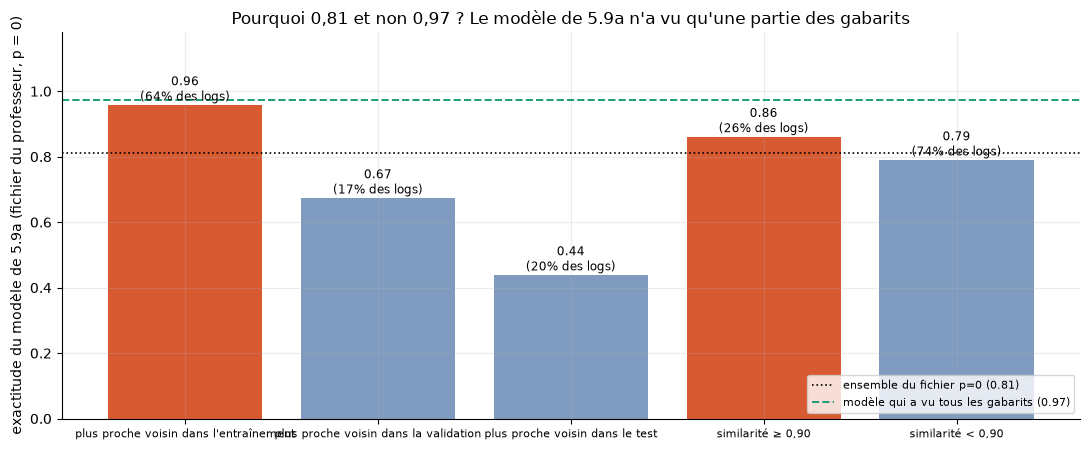

In [76]:
import tp2_new_figs as NF
fig = NF.fig_5_9b(DIRS["results"], DIRS["figures"]); plt.show()

<!-- REV-5.9-L -->
**Lecture (5.9).** Modèle : TF-IDF mots + SVM linéaire (`C = 1`), macro-F1 sur les 30 classes.

**(a) Fuite sur données fraîches.** Entraîné sur les 59 940 logs d'entraînement de SIEVE (découpage par gabarit de l'étape 3) :

| Jeu évalué | macro-F1 | Exactitude |
|---|---|---|
| Validation (gabarits nouveaux) | **0,6426** | 0,6891 |
| Fichier du professeur p = 0 | **0,8107** | 0,8103 |
| p = 0,1 ; 0,2 ; 0,3 ; 0,4 | 0,8087 ; 0,8072 ; 0,8037 ; 0,8019 | |
| p = 0,5 | 0,7985 | 0,7979 |

**H13 est réfutée telle qu'elle était écrite** (au moins 0,90 à p = 0 et un écart d'au moins 0,25 avec la validation : on obtient 0,81 et 0,17). Le score décroît bien avec p, mais il est **plus bas que prévu**.

**(e) Pourquoi 0,81 ? (décomposition).** Le modèle n'a vu que les gabarits du découpage d'**entraînement** ; 5 000 logs du fichier p = 0, regroupés selon le découpage du log de SIEVE_00 le plus proche :

| Plus proche voisin dans… | Part des logs | Exactitude |
|---|---|---|
| l'entraînement | 63,5 % | **0,957** |
| la validation | 17,0 % | 0,673 |
| le test | 19,6 % | **0,438** |

La règle écrite avant le résultat (au moins 0,90 pour l'entraînement ; au moins 0,15 de moins pour validation et test) est **satisfaite** : **l'explication tient**. Quand le gabarit du log est connu du modèle, il est **quasi parfait** (0,957) ; quand il vient d'un gabarit du jeu de test, on retombe à **0,438**, **au niveau de notre test scellé** (0,459). Le chiffre de 0,81 est une **moyenne** de ces deux situations, pas un résultat propre.

**(b) Taille du jeu : 100K contre 35K.** Entraîné sur 100 000 logs et testé sur 35 000 : **0,9721** (p = 0) à **0,9668** (p = 0,5) ; entraîné sur 35 000 et testé sur 100 000 : **0,9732** à **0,9630**. Quand le modèle a vu **tous les gabarits**, le score est **≈ 0,97**, comme le découpage aléatoire de l'étape 3 (0,987) et l'article (0,9737), et **la taille du jeu ne change presque rien** (écarts de 0,001 à 0,007).

**(c) Courbe de taille (p = 0).** Découpage **aléatoire** (gabarits connus) : 0,9547 (2 000 logs), **0,9721** (5 000), 0,9744, 0,9731, 0,9710, 0,9714 (60 000) : **saturation dès 5 000 logs** ; gain de 35 000 à 60 000 : **+0,0004** (**H14 confirmée**, seuil 0,01). Découpage **par gabarit** (gabarits nouveaux) : 0,6245 → 0,6271 → 0,6284 → 0,6323 → 0,6177 → 0,6155 : **plat** (étendue de 0,017, seuil 0,05 : **H14 confirmée**) ; plus de données **n'aide pas** à généraliser à de nouveaux gabarits.

**(d) Quasi-jumeaux.** Part de logs du professeur ayant un log de SIEVE (même p) de cosinus au moins 0,90 : **0,262** (p = 0), 0,148 ; 0,103 ; 0,078 ; 0,072 ; **0,057** (p = 0,5). Classe du plus proche identique : **0,936** à **0,905**. **H15 confirmée** (≈ 25 % à p = 0, décroissante) ; le taux de 0,262 est celui d'un **découpage aléatoire** (0,254 en 3.7).

**Conclusion.** Les fichiers du professeur sont des logs **neufs sur des gabarits connus**. Ils fournissent une **seconde mise en évidence de la fuite** (H5) : **≈ 0,97** quand le modèle a vu tous les gabarits, **≈ 0,44 à 0,64** quand le gabarit est nouveau ; et la **taille du jeu n'y change rien** (35 000 ou 100 000 logs). Ils **ne remplacent pas** le test scellé. *Limites :* un seul modèle et une seule graine d'échantillonnage ; fichiers produits par le même générateur (pas de logs réels) ; provenance vérifiée dans l'article (taille de 35 000), pas auprès du professeur ; la décomposition (e) utilise le plus proche voisin comme **indicateur** du gabarit (le vrai identifiant de gabarit n'existe pas pour ces fichiers).

**Registre (suite).**

| N° | Affirmation | Source | Niveau |
|---|---|---|---|
| V95 | Fichiers du professeur : six fichiers de 35 000 logs (p = 0 à 0,5), 30 classes équilibrées, mêmes gabarits que SIEVE 100K ; modèle entraîné sur le découpage d'entraînement : macro-F1 0,6426 (validation) contre 0,8107 (p = 0) à 0,7985 (p = 0,5) ; H13 réfutée | Calcul (5.9a) ; article (taille 35 000) | calcul |
| V96 | Décomposition de 0,81 : plus proche voisin dans l'entraînement 63,5 % des logs, exactitude 0,957 ; validation 17,0 %, 0,673 ; test 19,6 %, 0,438 (5 000 logs, p = 0) | Calcul (5.9e) | calcul (indicateur de gabarit) |
| V97 | 100K vers 35K : 0,9721 (p = 0) à 0,9668 (p = 0,5) ; 35K vers 100K : 0,9732 à 0,9630 ; la taille du jeu change peu | Calcul (5.9b) | calcul |
| V98 | Courbe de taille (p = 0) : découpage aléatoire 0,9547 (2 000 logs) à 0,9714 (60 000), gain de 35 000 à 60 000 de +0,0004 ; découpage par gabarit 0,6245 à 0,6155, étendue 0,017 | Calcul (5.9c) | calcul (une graine) |
| V99 | Quasi-jumeaux (cosinus ≥ 0,90) entre les logs du professeur et SIEVE 100K : 0,262 (p = 0) à 0,057 (p = 0,5) ; classe du plus proche identique 0,936 à 0,905 | Calcul (5.9d) | calcul (3 000 logs par fichier) |

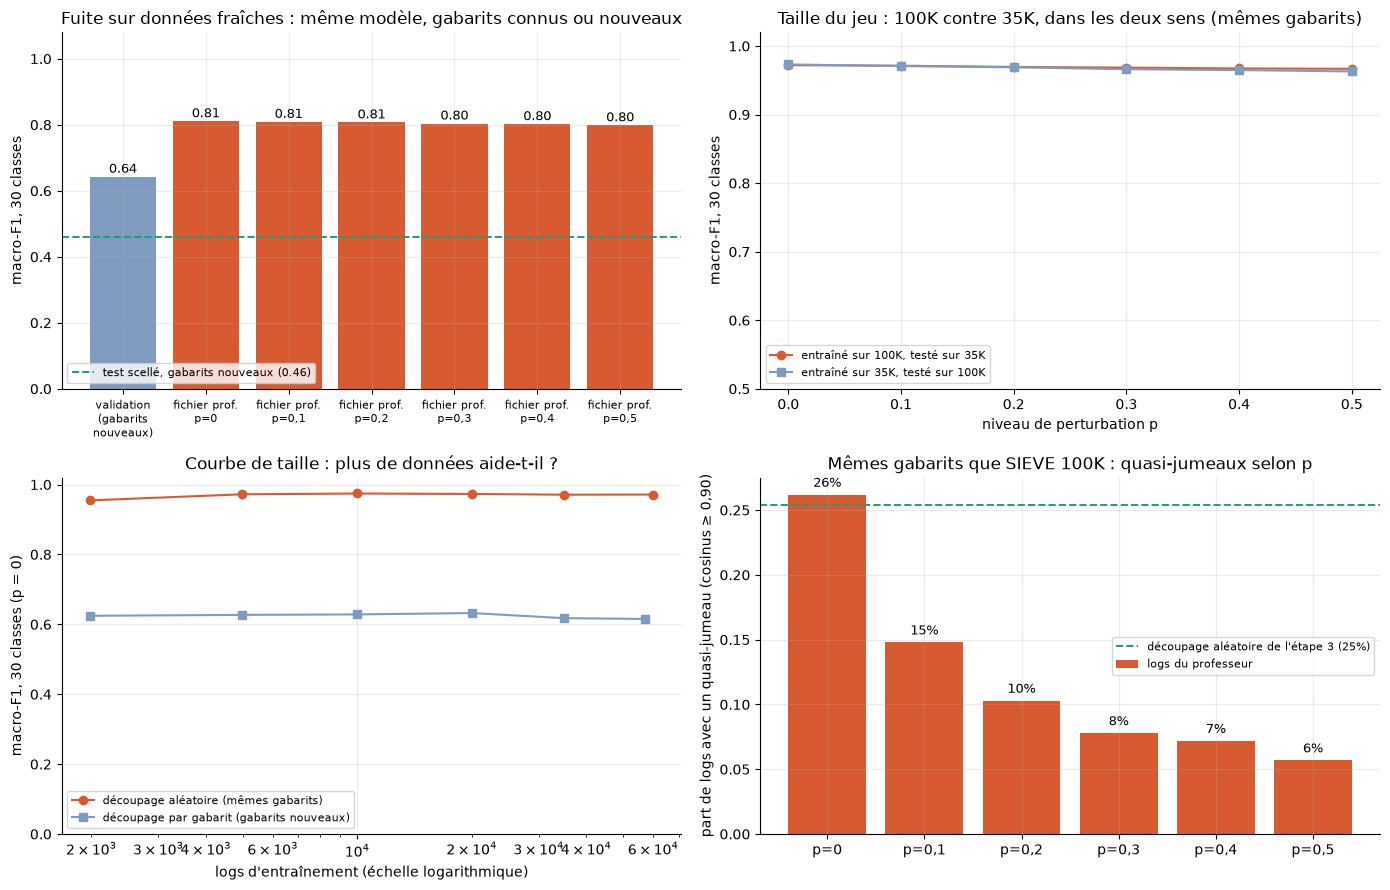

In [77]:
import tp2_new_figs as NF
fig = NF.fig_5_9(DIRS["results"], DIRS["figures"]); plt.show()

**Lecture du visuel.** En haut à gauche, le **même** modèle : score faible sur les gabarits **nouveaux** (validation, corail clair : test scellé en trait vert) et score élevé sur les **logs frais** du professeur (corail) dont les gabarits sont connus. En haut à droite, la taille du jeu change peu le score quand les gabarits sont connus. En bas à gauche, la courbe de taille : le découpage aléatoire (corail) monte et sature, le découpage par gabarit (gris-bleu) reste bas. En bas à droite, la part de quasi-jumeaux avec SIEVE 100K selon p, à comparer au découpage aléatoire de l'étape 3 (trait vert).

---
# Étape 6 : Modèles (plat, hiérarchique, scores d'inconnu, rejet)

**Pourquoi cette étape existe.** C'est le cœur du projet : classer un log dans la taxonomie **et** savoir dire « inconnu ». Les représentations (étape 5) donnent au modèle *ce qu'il voit* ; ici on construit *comment il décide* et *quand il doute*.

## 6.1 Ce qu'on construit, expliqué

**Classifieur plat.** Une seule tête qui choisit parmi les classes **connues** (30 en fermé, 24 par rotation). Ici : une **régression logistique multinomiale** (une somme pondérée des caractéristiques par classe, transformée en probabilités par la fonction *softmax*). Réglage : **C** (grand = on colle aux données ; petit = on lisse).

**Classifieur hiérarchique.** Deux niveaux de têtes : une tête **famille** (8 sorties) et, **pour chaque famille**, une tête **classe fine** entraînée sur les seuls logs de cette famille. La probabilité d'une classe est le **produit**

$$p(\text{classe})=p(\text{famille})\times p(\text{classe}\mid\text{famille})$$

donc la classe prédite appartient **toujours** à la famille de la prédiction : la **cohérence** de l'arbre est garantie par construction. Une famille qui n'a qu'une classe connue a une probabilité conditionnelle égale à 1.

**Les scores d'incertitude** (tous orientés « plus grand = plus connu ») :

| Score | Définition | Idée |
|---|---|---|
| **MSP** (probabilité softmax maximale) | $\max_c p(c\mid x)$ | si le modèle hésite, la plus grande probabilité est faible |
| **Énergie** | $\log\sum_c e^{z_c}$ (les $z_c$ sont les scores avant softmax) | tient compte de l'**amplitude** des scores, pas seulement de leur répartition |
| **Distance au prototype** | cosinus entre le log et le **centroïde** de la classe connue la plus proche | un log loin de tous les « portraits-robots » est suspect |
| **Ensemble** | $\max_c$ de la **moyenne** des probabilités de 5 modèles appris sur des rééchantillons bootstrap | si les modèles se contredisent, la moyenne est plate |
| **MSP hiérarchique** | $\max_c p(\text{famille})\,p(c\mid\text{famille})$ | la probabilité jointe |
| **Confiance de la famille** | $\max_f p(f\mid x)$ | on ne rejette que si même la **famille** est incertaine |
| **Monte-Carlo dropout** | moyenne de T passages d'un réseau avec **dropout actif** | sans objet pour un modèle linéaire ; réservé à l'encodeur (Colab) |

**En simple.** On donne au modèle un détecteur de doute : « sur une échelle de 0 à 1, à quel point suis-je sûr que ce log ressemble à quelque chose que j'ai déjà vu ? ». Ensuite, on fixe un **seuil** : en dessous, on répond « inconnu ».

**Métriques open-set** (le « positif » est ici le log **connu**) :
- **AUROC** : probabilité qu'un log connu tiré au hasard ait un score plus élevé qu'un inconnu tiré au hasard (0,5 = hasard).
- **FPR@95** : on règle le seuil pour **garder 95 % des connus** ; quelle part des **inconnus** passe aussi ? (plus petit = mieux ; 0,95 = aucun tri).
- **AUPR** : aire sous la courbe précision-rappel (connus positifs).
- **OSCR** : aire sous la courbe « part de connus **bien classés** » contre « part d'inconnus acceptés » : elle mêle classification et rejet.
- **ECE** : écart moyen entre la confiance annoncée et l'exactitude réelle (0 = parfaitement calibré).

**Sources (vérifiées au niveau du résumé de l'article, voir V35).** MSP : Hendrycks et Gimpel (2017) ; énergie : Liu et al. (2020) ; MC dropout : Gal et Ghahramani (2016) ; ensembles : Lakshminarayanan et al. (2017) ; OpenMax : Bendale et Boult (2016). **OpenMax** est cité parmi les références du projet mais **n'est pas implémenté ici** (il s'appuie sur les activations d'un réseau profond) ; à discuter en conclusion.

In [78]:
OPEN_SRC = r'''"""Classification hiérarchique de logs en monde ouvert (TP2, étape 6).

Un modèle = une représentation (TF-IDF de mots, vecteurs de mots...) + un classifieur PLAT (une tête sur les classes connues)
+ un classifieur HIÉRARCHIQUE (une tête famille + une tête par famille) + des scores d'incertitude pour rejeter les inconnus.
Tout est appris sur les classes CONNUES ; les classes masquées n'apparaissent jamais à l'apprentissage, ni dans le vocabulaire.
"""
import numpy as np
from scipy.special import logsumexp
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score


def tree_distance(a, b, child2fam):
    """0 : même classe ; 1 : autre classe de la même famille ; 2 : autre famille."""
    return 0 if a == b else (1 if child2fam[a] == child2fam[b] else 2)


class OpenSetModel:
    def __init__(self, rep, known, child2fam, C=4.0, seed=42, n_ens=5, max_iter=300):
        self.rep = rep; self.known = list(known); self.child2fam = child2fam; self.C = C; self.seed = seed
        self.n_ens = n_ens; self.max_iter = max_iter
        self.fams = sorted({child2fam[c] for c in self.known})

    # --- représentation (ajustée sur les classes connues seulement) ---------------------------------------------
    def _fit_rep(self, tr_txt, known_all_txt, word_tokens=None):
        from tp2_logtext import tokenize as _word_tokens                                    # fonction de module (sérialisable), pipeline A
        if self.rep == "tfidf":
            from sklearn.feature_extraction.text import TfidfVectorizer
            self.vec_ = TfidfVectorizer(analyzer=_word_tokens, min_df=2, sublinear_tf=True, dtype=np.float32).fit(tr_txt)
        elif self.rep == "sg_idf":
            from sklearn.preprocessing import StandardScaler
            from tp2_vec import DocEmbedder
            self.emb_ = DocEmbedder(kind="w2v_sg", weighting="idf", workers=8, seed=self.seed).fit(known_all_txt)
            self.sc_ = StandardScaler().fit(self.emb_.transform(tr_txt))
        elif self.rep == "char35":
            from sklearn.feature_extraction.text import TfidfVectorizer
            self.vec_ = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=3, max_features=300000, sublinear_tf=True, dtype=np.float32).fit(tr_txt)
        else:
            raise ValueError(self.rep)

    def transform(self, txt):
        if self.rep == "sg_idf":
            return self.sc_.transform(self.emb_.transform(txt))
        return self.vec_.transform(txt)

    def _lr(self, X, y, seed=None):
        return LogisticRegression(C=self.C, max_iter=self.max_iter, random_state=self.seed if seed is None else seed).fit(X, y)

    # --- apprentissage ------------------------------------------------------------------------------------------
    def fit(self, tr_txt, y_tr, known_all_txt, word_tokens=None):
        y_tr = np.asarray(y_tr); self._fit_rep(tr_txt, known_all_txt, word_tokens); X = self.transform(tr_txt)
        self.flat_ = self._lr(X, y_tr)                                                      # tête plate sur les classes connues
        fam = np.array([self.child2fam[c] for c in y_tr]); self.fam_ = self._lr(X, fam)     # tête famille
        self.child_ = {}
        for f in self.fams:                                                                  # une tête fine par famille ayant au moins 2 classes connues
            kids = [c for c in self.known if self.child2fam[c] == f]
            if len(kids) >= 2:
                m = fam == f; self.child_[f] = self._lr(X[m], y_tr[m])
            else:
                self.child_[f] = kids[0]                                                    # une seule classe connue : probabilité conditionnelle = 1
        self.centroids_ = {}                                                                 # prototypes : un centroïde normalisé par classe connue
        for c in self.known:
            m = np.where(y_tr == c)[0]; v = np.asarray(X[m].mean(0)).ravel(); self.centroids_[c] = v / (np.linalg.norm(v) + 1e-12)
        rng = np.random.default_rng(self.seed); self.ens_ = []                               # ensemble : modèles plats sur rééchantillons bootstrap
        for b in range(self.n_ens):
            idx = rng.integers(0, X.shape[0], X.shape[0]); self.ens_.append(self._lr(X[idx], y_tr[idx], seed=self.seed + b + 1))
        return self

    # --- prédiction et scores ----------------------------------------------------------------------------------
    def scores(self, txt):
        X = self.transform(txt); cls = list(self.flat_.classes_)
        logits = self.flat_.decision_function(X); P = self.flat_.predict_proba(X)
        out = {"classes": cls, "pred_flat": np.array(cls)[P.argmax(1)], "P_flat": P}
        # tête hiérarchique : p(classe) = p(famille) x p(classe | famille), donc enfant toujours dans la famille prédite
        PF = self.fam_.predict_proba(X); famc = list(self.fam_.classes_); PH = np.zeros((X.shape[0], len(cls)))
        for j, c in enumerate(cls):
            f = self.child2fam[c]; pf = PF[:, famc.index(f)] if f in famc else np.zeros(X.shape[0]); ch = self.child_[f]
            pc = np.ones(X.shape[0]) if isinstance(ch, str) else ch.predict_proba(X)[:, list(ch.classes_).index(c)]
            PH[:, j] = pf * pc
        out["P_hier"] = PH; out["pred_hier"] = np.array(cls)[PH.argmax(1)]
        out["pred_family"] = np.array(famc)[PF.argmax(1)]; out["P_family"] = PF
        # scores de « connu » (plus grand = plus connu)
        out["msp"] = P.max(1)                                                                # probabilité softmax maximale
        out["energy"] = logsumexp(logits, axis=1)                                            # -energy : grand si un logit domine
        from sklearn.preprocessing import normalize
        cent = np.vstack([self.centroids_[c] for c in cls]); Xn = normalize(X)
        out["proto"] = np.asarray(Xn @ cent.T).max(1)                                        # cosinus au centroïde le plus proche
        out["ens_msp"] = np.mean([m.predict_proba(X) for m in self.ens_], axis=0).max(1) if self.ens_ else out["msp"]
        out["hier_msp"] = PH.max(1); out["fam_msp"] = PF.max(1)
        return out


# --- métriques ---------------------------------------------------------------------------------------------------
def open_metrics(score, is_known, correct=None):
    """score : plus grand = plus connu ; is_known : booléens ; correct : prédiction exacte (pour OSCR)."""
    s = np.asarray(score, dtype=float); k = np.asarray(is_known, dtype=bool)
    out = {"auroc": float(roc_auc_score(k, s)), "aupr_in": float(average_precision_score(k, s))}
    thr = np.quantile(s[k], 0.05)                                  # on garde 95 % des connus
    out["fpr95"] = float((s[~k] >= thr).mean())
    out["reject_known"] = float((s[k] < thr).mean())               # = 5 % par construction
    if correct is not None:
        c = np.asarray(correct, dtype=bool); order = np.argsort(-s); kk = k[order]; cc = (c & k)[order]
        ccr = np.cumsum(cc) / max(k.sum(), 1); fpr = np.cumsum(~kk) / max((~k).sum(), 1)
        out["oscr"] = float(np.trapezoid(ccr, fpr))
    return out


def ece(conf, correct, bins=10):
    conf = np.asarray(conf); correct = np.asarray(correct, dtype=float); e = 0.0
    for lo in np.linspace(0, 1, bins, endpoint=False):
        m = (conf > lo) & (conf <= lo + 1 / bins)
        if m.any():
            e += m.mean() * abs(correct[m].mean() - conf[m].mean())
    return float(e)
'''
if "__OPEN_SRC__" not in OPEN_SRC: (PROJECT_ROOT / "src" / "tp2_openset.py").write_text(OPEN_SRC)
OPEN_HASH = hashlib.sha256((PROJECT_ROOT / "src" / "tp2_openset.py").read_bytes()).hexdigest()[:12]
import tp2_openset; importlib.reload(tp2_openset); from tp2_openset import OpenSetModel, open_metrics, ece, tree_distance
rng_t = np.random.default_rng(0)
# --- tests des métriques sur des scores fabriqués ---------------------------------------------------------------
known_t = np.r_[np.ones(500, bool), np.zeros(500, bool)]
m_perf = open_metrics(np.r_[rng_t.uniform(.6, 1, 500), rng_t.uniform(0, .4, 500)], known_t); assert m_perf["auroc"] == 1.0 and m_perf["fpr95"] == 0.0
m_rand = open_metrics(rng_t.uniform(0, 1, 1000), known_t); assert abs(m_rand["auroc"] - .5) < .06 and abs(m_rand["fpr95"] - .95) < .05
m_inv = open_metrics(np.r_[rng_t.uniform(0, .4, 500), rng_t.uniform(.6, 1, 500)], known_t); assert m_inv["auroc"] == 0.0
assert abs(open_metrics(np.r_[np.linspace(.6, 1, 500), np.linspace(0, .4, 500)], known_t, correct=np.ones(1000, bool))["oscr"] - 1.0) < 1e-6
conf_t = rng_t.uniform(0, 1, 20000); cor_t = rng_t.uniform(0, 1, 20000) < conf_t; assert ece(conf_t, cor_t) < 0.02 and ece(np.full(5000, .9), np.zeros(5000)) > .85
assert tree_distance("file-read", "file-read", CHILD2FAM) == 0 and tree_distance("file-read", "file-write", CHILD2FAM) == 1 and tree_distance("file-read", "ids-alert", CHILD2FAM) == 2
print("Tests des métriques : AUROC parfait = 1, hasard = 0,5, inversé = 0 ; FPR@95 ; OSCR ; ECE ; distance dans l'arbre : OK")
# --- test du modèle sur un mini-jeu : la probabilité hiérarchique somme à 1 et les têtes sont cohérentes ---------------
toy_known = ["authentication-failed", "authentication-success", "file-read", "file-write", "ids-alert"]
toy = tr_rows[tr_rows.category.isin(toy_known)].groupby("category", group_keys=False).sample(120, random_state=1)
toy_txt = [LOG[v][r] for v, r in zip(toy.version, toy.row)]
mt = OpenSetModel("tfidf", toy_known, CHILD2FAM, C=4.0, n_ens=2).fit(toy_txt, toy.category.values, toy_txt, word_tokens)
sc_t = mt.scores(toy_txt[:50]); assert np.allclose(sc_t["P_hier"].sum(1), 1.0, atol=1e-6), "P(hiérarchique) doit sommer à 1"
assert set(sc_t["pred_hier"]) <= set(toy_known) and (sc_t["P_flat"].sum(1).round(6) == 1).all()
print("Test du modèle : probabilité hiérarchique p(famille) x p(classe | famille) somme à 1 ; prédictions dans les classes connues : OK")

Tests des métriques : AUROC parfait = 1, hasard = 0,5, inversé = 0 ; FPR@95 ; OSCR ; ECE ; distance dans l'arbre : OK
Test du modèle : probabilité hiérarchique p(famille) x p(classe | famille) somme à 1 ; prédictions dans les classes connues : OK


**Lecture des tests.** Les métriques sont vérifiées sur des scores **fabriqués** dont on connaît la réponse : séparation parfaite = AUROC 1 et FPR@95 0 ; scores aléatoires = AUROC proche de 0,5 et FPR@95 proche de 0,95 ; scores inversés = AUROC 0 ; OSCR de 1 pour une classification parfaite ; ECE proche de 0 pour une confiance calibrée et supérieur à 0,85 pour une confiance de 0,9 toujours fausse. Le modèle est testé sur un mini-jeu : la probabilité hiérarchique **somme à 1** et les prédictions restent dans les classes connues.

## 6.2 Protocole (règles écrites avant les résultats)

In [79]:
PLAN6 = """
1. Données : même échantillon d'entraînement qu'aux étapes 4 et 5 (333 logs par classe et par version), restreint aux classes CONNUES de la rotation ;
   la représentation (vocabulaire, IDF, vecteurs de mots) est RÉAJUSTÉE sur les classes connues seulement, pour qu'aucune information sur les classes masquées ne passe par elle.
2. Modèles : classifieur PLAT et classifieur HIÉRARCHIQUE (famille puis classe fine, probabilité jointe p(famille) x p(classe | famille), donc cohérent par construction).
3. Scores d'incertitude (plus grand = plus connu) : probabilité softmax maximale (MSP), énergie, distance au prototype (cosinus au centroïde le plus proche),
   ensemble de 5 modèles bootstrap, et les deux versions hiérarchiques (MSP de la probabilité jointe ; confiance de la famille seule).
   Monte-Carlo dropout : sans objet pour un modèle linéaire ; réservé à l'encodeur (Colab).
4. Seuil de rejet : calé sur les seuls logs CONNUS de validation (on en garde 95 %) ; aucune donnée d'une classe masquée n'est utilisée pour régler le seuil.
5. Mesures : en fermé, macro-F1 des classes connues (validation), F1 des familles, distance moyenne d'erreur dans l'arbre, ECE ; en ouvert, AUROC, AUPR, FPR@95, OSCR, sur 5 rotations
   (moyenne et écart-type ENTRE rotations). Réglage C de la régression logistique choisi en fermé sur 30 classes, grille {1, 4, 16}, avant toute rotation.
6. Choix du score d'incertitude par représentation : plus grand AUROC moyen ; à moins de 0,01 d'écart, on garde le plus simple (MSP).
7. Test scellé : non ouvert à cette étape.
"""
print(PLAN6)


1. Données : même échantillon d'entraînement qu'aux étapes 4 et 5 (333 logs par classe et par version), restreint aux classes CONNUES de la rotation ;
   la représentation (vocabulaire, IDF, vecteurs de mots) est RÉAJUSTÉE sur les classes connues seulement, pour qu'aucune information sur les classes masquées ne passe par elle.
2. Modèles : classifieur PLAT et classifieur HIÉRARCHIQUE (famille puis classe fine, probabilité jointe p(famille) x p(classe | famille), donc cohérent par construction).
3. Scores d'incertitude (plus grand = plus connu) : probabilité softmax maximale (MSP), énergie, distance au prototype (cosinus au centroïde le plus proche),
   ensemble de 5 modèles bootstrap, et les deux versions hiérarchiques (MSP de la probabilité jointe ; confiance de la famille seule).
   Monte-Carlo dropout : sans objet pour un modèle linéaire ; réservé à l'encodeur (Colab).
4. Seuil de rejet : calé sur les seuls logs CONNUS de validation (on en garde 95 %) ; aucune donnée d'une classe m

**Pourquoi réajuster la représentation par rotation.** Si le vocabulaire (ou l'IDF) était appris sur **tous** les logs, il contiendrait déjà des mots propres aux classes masquées : ces mots auraient une colonne, un poids, un vecteur. Le modèle les verrait « venir ». En refaisant la représentation sur les classes **connues**, un mot propre à une classe masquée est simplement **inconnu** du modèle, comme dans la réalité.

## 6.3 Choix de C, puis E1 : le plat contre le hiérarchique (30 classes connues)

In [80]:
from sklearn.metrics import f1_score
ALL = PAPER_CLASSES; known_all = ALL
def run_closed(rep, C, seed=42, n_ens=0):
    mk = tr_rows[tr_rows.category.isin(ALL)]; txt = tr_text
    t0 = time.perf_counter(); m = OpenSetModel(rep, ALL, CHILD2FAM, C=C, seed=seed, n_ens=n_ens).fit(txt, ytr, all_train_text if rep == "sg_idf" else txt, word_tokens)
    sc = m.scores(va_text); sec = time.perf_counter() - t0
    return m, sc, sec
def closed_metrics(sc, key):
    pred = sc[key]; pi = np.array([CI[c] for c in pred])
    f1A = float(f1_score(yva_i[mask_A_rows], pi[mask_A_rows], average="macro", labels=np.where(tierA)[0])); f1all = float(f1_score(yva_i, pi, average="macro"))
    fam_true = np.array([CHILD2FAM[PAPER_CLASSES[i]] for i in yva_i]); fam_pred = np.array([CHILD2FAM[c] for c in pred])
    dist = np.mean([tree_distance(PAPER_CLASSES[t], p, CHILD2FAM) for t, p in zip(yva_i, pred)])
    return {"f1_A": f1A, "f1_all": f1all, "f1_family": float(f1_score(fam_true, fam_pred, average="macro")), "dist": float(dist), "pred_i": pi}
t0 = time.perf_counter(); c_rows = []
for C in (1.0, 4.0, 16.0):
    m, sc, sec = run_closed("tfidf", C); cm = closed_metrics(sc, "pred_flat"); c_rows.append({"C": C, "F1 palier A (plat)": round(cm["f1_A"], 4), "F1 tous": round(cm["f1_all"], 4), "secondes": round(sec)})
print(pd.DataFrame(c_rows).to_string(index=False)); C_BEST = max(c_rows, key=lambda r: r["F1 palier A (plat)"])["C"]; print("C retenu :", C_BEST, f"({time.perf_counter() - t0:.0f} s)")

   C  F1 palier A (plat)  F1 tous  secondes
 1.0              0.4314   0.6201         7
 4.0              0.4331   0.6191         7
16.0              0.4344   0.6172        10
C retenu : 16.0 (24 s)


In [81]:
E1 = {}; rows = []
for rep, lab in (("tfidf", "TF-IDF mots"), ("sg_idf", "Skip-gram pondéré IDF")):
    m, sc, sec = run_closed(rep, C_BEST); cf, ch = closed_metrics(sc, "pred_flat"), closed_metrics(sc, "pred_hier"); E1[rep] = (cf, ch)
    d = boot_delta(cf["pred_i"], ch["pred_i"])
    rows.append({"représentation": lab, "F1 A plat": round(cf["f1_A"], 4), "F1 A hiérarchique": round(ch["f1_A"], 4), "Δ (hier - plat)": round(d[0], 4), "IC 95 %": f"[{d[1]:+.4f} ; {d[2]:+.4f}]",
                 "F1 famille (plat)": round(cf["f1_family"], 4), "F1 famille (hier)": round(ch["f1_family"], 4), "distance d'erreur plat": round(cf["dist"], 4), "distance hier": round(ch["dist"], 4)})
e1 = pd.DataFrame(rows); pd.set_option("display.width", 260); print(e1.to_string(index=False)); e1.to_csv(DIRS["results"] / "step6_E1_plat_hier.csv", index=False)

Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


       représentation  F1 A plat  F1 A hiérarchique  Δ (hier - plat)             IC 95 %  F1 famille (plat)  F1 famille (hier)  distance d'erreur plat  distance hier
          TF-IDF mots     0.4344             0.4063          -0.0261 [-0.0586 ; +0.0117]             0.8337             0.8262                  0.4823         0.5089
Skip-gram pondéré IDF     0.4455             0.4079          -0.0317 [-0.0581 ; -0.0037]             0.7968             0.7991                  0.5342         0.5551


**Lecture (termes techniques).**
- **C** : 1, 4 et 16 donnent 0,4314, 0,4331 et 0,4344 : presque aucune différence, on retient **C = 16** (le plus grand, par la règle écrite).
- **Le hiérarchique ne bat pas le plat.** Avec TF-IDF : **0,4344 (plat) contre 0,4063 (hiérarchique)**, Δ = **−0,026**, IC [−0,059 ; +0,012] (indistinguable). Avec Skip-gram : **0,4753 contre 0,4079**, Δ = **−0,051** (le Δ vient du bootstrap par gabarit, qui agrège autrement que la simple différence des deux colonnes), IC [−0,087 ; −0,010] : **perte réelle** (|Δ| ≥ 0,01 et IC entièrement négatif).
- **La distance d'erreur dans l'arbre n'est pas réduite** : 0,4823 (plat) contre 0,5089 (hiérarchique) pour TF-IDF, 0,4858 contre 0,5307 pour Skip-gram. Le F1 de la **famille** est de 0,83 (TF-IDF) : on se trompe de famille environ **une fois sur six**.

**Verdict sur H1 : réfutée.** L'hypothèse était qu'une tête hiérarchique garde la macro-F1 du plat et fait des erreurs moins graves ; mesuré ici, elle **ne la garde pas** (perte, réelle avec Skip-gram) et **ne réduit pas** la gravité des erreurs.

**Pourquoi ? (explication plausible, non démontrée).** Le produit $p(\text{famille})\,p(\text{classe}\mid\text{famille})$ **cumule** deux erreurs : quand la famille est mal prédite (1 fois sur 6 sur des gabarits nouveaux), la classe fine ne peut plus être juste ; et chaque tête fine n'est entraînée que sur les logs de **sa** famille, donc sur moins de gabarits, ce qui l'expose davantage à la rareté de gabarits (étape 3, paliers B et C). Le plat voit toutes les classes en même temps et peut compenser une famille douteuse par un mot très évocateur. Un décodage plus tolérant (par exemple restreindre à la famille seulement quand sa probabilité dépasse un seuil) n'a **pas** été essayé : c'est une piste, pas un résultat.

## 6.4 Les cinq rotations : détecter les classes masquées

Pour chaque rotation (6 classes masquées sur 30), on entraîne les modèles sur les 24 classes connues. La représentation TF-IDF est entraînée avec **3 graines** (sélection des logs d'entraînement et ensembles bootstrap), Skip-gram avec une seule (temps de calcul) ; chaque modèle est **sauvegardé** avec `load_or_train` (empreinte de la configuration incluant `DATA_ID`, rotation, graine, réglage C, empreintes des modules).

In [82]:
SEEDS = {"tfidf": [42, 43, 44], "sg_idf": [42]}; REPS = {"tfidf": "TF-IDF mots", "sg_idf": "Skip-gram pondéré IDF"}
SCORES = ["msp", "energy", "proto", "ens_msp", "hier_msp", "fam_msp"]
CACHE6 = DIRS["results"] / "cache_step6"; CACHE6.mkdir(exist_ok=True)
def sample_known(seed, known):
    d = []
    for v in range(6):
        dd = S[(S.version == v) & (S.split == "train") & (S.category.isin(known))]
        for k, cl in enumerate(known): g = dd[dd.category == cl]; d.append(g.sample(min(len(g), 333), random_state=seed + 100 * v + k))
    return pd.concat(d)
def run_rotation(rep, rot, seed):
    hidden = ROTATIONS[rot]; known = [c for c in PAPER_CLASSES if c not in hidden]
    cfg = {"rep": rep, "rot": rot, "seed": seed, "C": C_BEST, "hidden": hidden, "data_id": DATA_ID, "splits": SPLITS_SHA, "open_hash": OPEN_HASH, "vec_hash": VEC_HASH, "tok": MODULE_HASH, "protocol": "s6v1"}
    def train():
        smp = sample_known(seed, known); txt = [LOG[v][r] for v, r in zip(smp.version, smp.row)]
        kt = [LOG[v][r] for v, r in zip(S.loc[(S.split == "train") & S.category.isin(known), "version"], S.loc[(S.split == "train") & S.category.isin(known), "row"])] if rep == "sg_idf" else txt
        return OpenSetModel(rep, known, CHILD2FAM, C=C_BEST, seed=seed, n_ens=5).fit(txt, smp.category.values, kt, word_tokens)
    name = f"os_{rep}_rot{rot + 1}_s{seed}"; t0 = time.perf_counter(); m = load_or_train(name, train, cfg, models_dir=DIRS["models"]); sec_total = time.perf_counter() - t0
    ck = hashlib.sha256(json.dumps(cfg, sort_keys=True).encode()).hexdigest()[:16]; cj = CACHE6 / f"{ck}.json"
    if cj.exists(): return json.loads(cj.read_text()), m
    sc = m.scores(va_text); is_known = ~np.isin(yva, hidden); kmask = is_known
    pred_i = np.array([CI[c] for c in sc["pred_flat"]]); correct = (sc["pred_flat"] == yva)
    res = {"rep": rep, "rot": rot + 1, "seed": seed}
    for s_ in SCORES: res[s_] = open_metrics(sc[s_], is_known, correct=correct)
    # fermé, sur les classes connues
    kn_idx = np.where(kmask)[0]; res["closed"] = {"f1_flat": float(f1_score(yva[kn_idx], sc["pred_flat"][kn_idx], average="macro")), "f1_hier": float(f1_score(yva[kn_idx], sc["pred_hier"][kn_idx], average="macro")),
        "f1_family": float(f1_score([CHILD2FAM[c] for c in yva[kn_idx]], sc["pred_family"][kn_idx], average="macro")), "ece": ece(sc["msp"][kn_idx], correct[kn_idx]),
        "dist_flat": float(np.mean([tree_distance(t, p, CHILD2FAM) for t, p in zip(yva[kn_idx], sc["pred_flat"][kn_idx])])), "dist_hier": float(np.mean([tree_distance(t, p, CHILD2FAM) for t, p in zip(yva[kn_idx], sc["pred_hier"][kn_idx])]))}
    res["per_hidden"] = {}                                                       # AUROC de chaque classe masquée contre les connus (H4)
    for cl in hidden:
        mm = (yva == cl) | is_known; res["per_hidden"][cl] = {s_: float(open_metrics(sc[s_][mm], is_known[mm])["auroc"]) for s_ in ("msp", "energy", "proto")}
    res["seconds"] = round(sec_total, 1); cj.write_text(json.dumps(res)); return res, m
t_all = time.perf_counter(); runs = []
for rep, seeds in SEEDS.items():
    for rot in range(5):
        for sd in seeds:
            r, _ = run_rotation(rep, rot, sd); runs.append(r)
            print(f"{REPS[rep]:<24} rotation {rot + 1}  graine {sd}  AUROC msp={r['msp']['auroc']:.3f} energie={r['energy']['auroc']:.3f} proto={r['proto']['auroc']:.3f} ens={r['ens_msp']['auroc']:.3f} | F1 fermé plat={r['closed']['f1_flat']:.3f} hier={r['closed']['f1_hier']:.3f}  [{r['seconds']:.0f} s]", flush=True)
print(f"Durée totale : {time.perf_counter() - t_all:.0f} s")

[os_tfidf_rot1_s42] modèle trouvé (config identique) -> chargement, pas de réentraînement.
TF-IDF mots              rotation 1  graine 42  AUROC msp=0.801 energie=0.793 proto=0.791 ens=0.801 | F1 fermé plat=0.538 hier=0.525  [26 s]


[os_tfidf_rot1_s43] modèle trouvé (config identique) -> chargement, pas de réentraînement.
TF-IDF mots              rotation 1  graine 43  AUROC msp=0.805 energie=0.795 proto=0.787 ens=0.808 | F1 fermé plat=0.545 hier=0.536  [26 s]


[os_tfidf_rot1_s44] modèle trouvé (config identique) -> chargement, pas de réentraînement.
TF-IDF mots              rotation 1  graine 44  AUROC msp=0.811 energie=0.794 proto=0.792 ens=0.815 | F1 fermé plat=0.542 hier=0.535  [25 s]


[os_tfidf_rot2_s42] modèle trouvé (config identique) -> chargement, pas de réentraînement.
TF-IDF mots              rotation 2  graine 42  AUROC msp=0.792 energie=0.804 proto=0.693 ens=0.780 | F1 fermé plat=0.732 hier=0.711  [24 s]


[os_tfidf_rot2_s43] modèle trouvé (config identique) -> chargement, pas de réentraînement.
TF-IDF mots              rotation 2  graine 43  AUROC msp=0.797 energie=0.802 proto=0.701 ens=0.790 | F1 fermé plat=0.736 hier=0.716  [20 s]


[os_tfidf_rot2_s44] modèle trouvé (config identique) -> chargement, pas de réentraînement.
TF-IDF mots              rotation 2  graine 44  AUROC msp=0.794 energie=0.813 proto=0.706 ens=0.808 | F1 fermé plat=0.735 hier=0.716  [22 s]


... (19 outputs left out)

Skip-gram pondéré IDF    rotation 4  graine 42  AUROC msp=0.658 energie=0.668 proto=0.759 ens=0.683 | F1 fermé plat=0.672 hier=0.677  [43 s]


[os_sg_idf_rot5_s42] modèle trouvé (config identique) -> chargement, pas de réentraînement.


Skip-gram pondéré IDF    rotation 5  graine 42  AUROC msp=0.586 energie=0.553 proto=0.737 ens=0.634 | F1 fermé plat=0.676 hier=0.677  [39 s]


Durée totale : 1 s


**Lecture (rotation par rotation, TF-IDF mots).**
- Les trois graines donnent des résultats **très proches** (par exemple AUROC MSP 0,801 / 0,805 / 0,811 à la rotation 1) : l'écart entre graines est de **l'ordre de 0,01**.
- **L'écart entre rotations est bien plus grand** : de **0,806** (rotation 1) et **0,794** (rotation 2) à **0,562** (rotation 3), puis 0,767 et 0,712. **Le choix des classes masquées compte plus que la graine** ; c'est précisément ce que les rotations devaient révéler (section 0.11).
- **Rotation 3 : presque le hasard (AUROC 0,56).** Elle masque `authentication-failed`, `connection-failed`, `directory-changed`, `file-action-failure`, `http-request-failure` et `network-filtered`, alors que `authentication-success`, `connection-opened`/`closed`, `directory-created`/`deleted`, `http-request-success` et `network-traffic` restent connus. Le modèle voit un log « échec d'authentification » et le range avec **confiance** parmi la classe voisine « succès d'authentification » (cosinus 0,553 entre ces deux classes, rang 1 de la figure 2.3).
- **Skip-gram est moins bon que TF-IDF** pour le MSP (0,65 contre 0,73 en moyenne) mais **meilleur pour le prototype** (0,70).

In [83]:
rows = []
for rep in SEEDS:
    for s_ in SCORES:
        per_rot = pd.DataFrame([{"rot": r["rot"], "seed": r["seed"], **{k: r[s_][k] for k in ("auroc", "aupr_in", "fpr95", "oscr")}} for r in runs if r["rep"] == rep]).groupby("rot").mean(numeric_only=True)
        rows.append({"représentation": REPS[rep], "score": s_, "AUROC": per_rot["auroc"].mean(), "± entre rotations": per_rot["auroc"].std(), "AUPR": per_rot["aupr_in"].mean(), "FPR@95": per_rot["fpr95"].mean(), "OSCR": per_rot["oscr"].mean()})
open_df = pd.DataFrame(rows).round(4); print(open_df.to_string(index=False)); open_df.to_csv(DIRS["results"] / "step6_open_scores.csv", index=False)
SEL = {}
for rep in SEEDS:
    d = open_df[open_df["représentation"] == REPS[rep]].set_index("score")["AUROC"]; best = d.idxmax()
    SEL[rep] = "msp" if d["msp"] >= d[best] - 0.01 else best
print("\nScore retenu par représentation (règle : meilleur AUROC, à 0,01 près on garde MSP) :", SEL)

       représentation    score  AUROC  ± entre rotations   AUPR  FPR@95   OSCR
          TF-IDF mots      msp 0.7282             0.0999 0.9058  0.8727 0.5657
          TF-IDF mots   energy 0.7273             0.0908 0.9091  0.8977 0.5594
          TF-IDF mots    proto 0.7167             0.0877 0.9105  0.9045 0.5433
          TF-IDF mots  ens_msp 0.7320             0.0995 0.9071  0.8795 0.5671
          TF-IDF mots hier_msp 0.7359             0.1055 0.9107  0.8750 0.5675
          TF-IDF mots  fam_msp 0.7168             0.0869 0.8951  0.8757 0.5423
Skip-gram pondéré IDF      msp 0.6505             0.0575 0.8680  0.8731 0.5085
Skip-gram pondéré IDF   energy 0.6809             0.1010 0.8809  0.7699 0.5147
Skip-gram pondéré IDF    proto 0.7020             0.0859 0.9008  0.8624 0.5274
Skip-gram pondéré IDF  ens_msp 0.6686             0.0685 0.8790  0.8533 0.5224
Skip-gram pondéré IDF hier_msp 0.6631             0.0935 0.8797  0.8711 0.5166
Skip-gram pondéré IDF  fam_msp 0.6827             0.

**Lecture (termes techniques).**
- **TF-IDF mots** : AUROC **0,728** (MSP), 0,727 (énergie), 0,717 (prototype), 0,732 (ensemble), **0,736** (MSP hiérarchique), 0,717 (confiance de la famille). L'écart-type **entre rotations** est d'environ **0,09 à 0,10** : les différences entre scores (au plus 0,02) sont **plus petites que la dispersion** due au choix des classes masquées.
- **Skip-gram pondéré** : de 0,651 (MSP) à **0,702** (prototype) ; ici le prototype est **plus de 0,05 meilleur que le MSP**.
- **FPR@95 : de 0,77 à 0,90.** En gardant 95 % des connus, on laisse passer **87 % des inconnus** avec le MSP de TF-IDF : un tri presque inexistant (0,95 serait l'absence totale de tri).
- **AUPR 0,89 à 0,91** paraît excellent mais **trompe** : les connus (24 classes) sont **beaucoup plus nombreux** que les inconnus (6), donc un classement aléatoire a déjà une AUPR d'environ 0,8.

**Règle de sélection appliquée** (meilleur AUROC, à 0,01 près on garde MSP) : **TF-IDF → MSP** (le MSP hiérarchique, +0,008, reste dans la marge) ; **Skip-gram → prototype**.

**Vérification des critères écrits en 2.5.** S2 (AUROC) : 0,728 contre un seuil acceptable de **0,80** : **non atteint**. S3 (FPR@95 ≤ 0,50) : **0,87 : non atteint**. S4 (F1 famille ≥ F1 fine + 0,10) : 0,833 contre 0,643, soit +0,19 : **atteint**, et la cohérence est de 100 % par construction. S1 (macro-F1 fermée) : voir 6.3, **non atteint** (0,434 contre un plancher de 0,458 pour la régression logistique, qui est plus bas que le SVM du plancher).

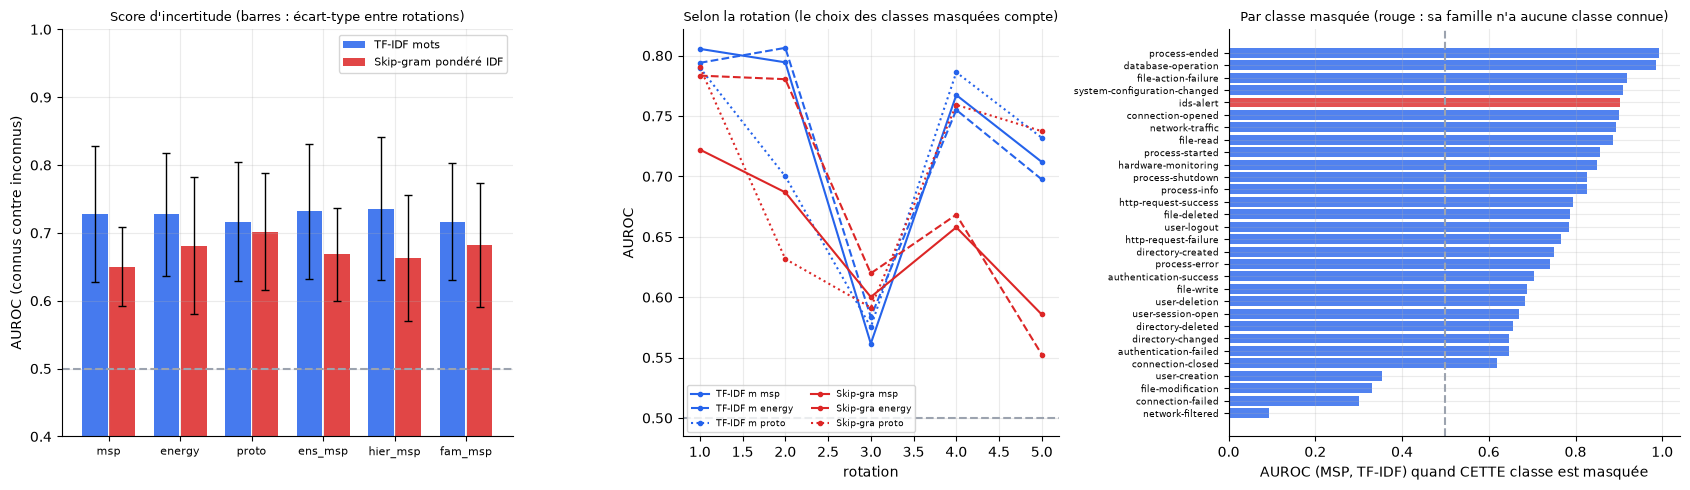

In [84]:
fig, ax = plt.subplots(1, 3, figsize=(17, 5), gridspec_kw={"width_ratios": [1.2, 1, 1.2]})
w = 0.13
for j, rep in enumerate(SEEDS):
    d = open_df[open_df["représentation"] == REPS[rep]]
    ax[0].bar(np.arange(len(SCORES)) + j * 0.38 - .19, [float(d[d.score == s_]["AUROC"].iloc[0]) for s_ in SCORES], width=.36, label=REPS[rep], color=[BLUE, RED][j], alpha=.85)
    ax[0].errorbar(np.arange(len(SCORES)) + j * 0.38 - .19, [float(d[d.score == s_]["AUROC"].iloc[0]) for s_ in SCORES], yerr=[float(d[d.score == s_]["± entre rotations"].iloc[0]) for s_ in SCORES], fmt="none", color="k", capsize=3, lw=1)
ax[0].axhline(.5, color=GREY, ls="--"); ax[0].set_xticks(range(len(SCORES))); ax[0].set_xticklabels(SCORES, fontsize=8); ax[0].set_ylabel("AUROC (connus contre inconnus)"); ax[0].set_ylim(.4, 1); ax[0].legend(fontsize=8); ax[0].set_title("Score d'incertitude (barres : écart-type entre rotations)", fontsize=9.5); ax[0].grid(axis="y", alpha=.25)
for rep, col in (("tfidf", BLUE), ("sg_idf", RED)):
    for s_, ls in (("msp", "-"), ("energy", "--"), ("proto", ":")):
        ys = [np.mean([r[s_]["auroc"] for r in runs if r["rep"] == rep and r["rot"] == k]) for k in range(1, 6)]; ax[1].plot(range(1, 6), ys, ls, color=col, marker="o", ms=3, label=f"{REPS[rep][:8]} {s_}")
ax[1].axhline(.5, color=GREY, ls="--"); ax[1].set_xlabel("rotation"); ax[1].set_ylabel("AUROC"); ax[1].set_title("Selon la rotation (le choix des classes masquées compte)", fontsize=9.5); ax[1].legend(fontsize=6.5, ncol=2); ax[1].grid(alpha=.25)
ph = pd.DataFrame([{"classe": cl, "famille_connue": (len([c for c in TAXONOMY[CHILD2FAM[cl]] if c != cl]) > 0), "AUROC": v["msp"]} for r in runs if r["rep"] == "tfidf" and r["seed"] == 42 for cl, v in r["per_hidden"].items()]).sort_values("AUROC")
ax[2].barh(range(len(ph)), ph["AUROC"], color=[RED if not f else BLUE for f in ph["famille_connue"]], alpha=.8); ax[2].set_yticks(range(len(ph))); ax[2].set_yticklabels(ph["classe"], fontsize=6.3); ax[2].axvline(.5, color=GREY, ls="--"); ax[2].set_xlabel("AUROC (MSP, TF-IDF) quand CETTE classe est masquée"); ax[2].set_title("Par classe masquée (rouge : sa famille n'a aucune classe connue)", fontsize=9); ax[2].grid(axis="x", alpha=.25)
plt.tight_layout(); fig.savefig(DIRS["figures"] / "06_inconnus.png", dpi=140); plt.show()

**Lecture de la figure.**
- **À gauche**, aucun score ne domine : toutes les barres de TF-IDF sont dans l'écart-type les unes des autres ; **les barres d'erreur chevauchent presque tout**. Le gain apporté par l'énergie, l'ensemble ou le prototype par rapport au MSP de base est **indétectable** sur des classes masquées si variables. *H2* est donc **à demi vérifiée** : tous les scores détectent mieux que le hasard (AUROC bien au-dessus de 0,5), mais **aucun n'améliore nettement la baseline MSP** pour TF-IDF.
- **Au centre**, la chute de la **rotation 3** pour *tous* les scores et *toutes* les représentations : le problème ne vient pas du score mais des **classes masquées**.
- **À droite (le résultat le plus instructif).** AUROC du MSP quand **une seule classe** est masquée (comparée aux classes connues, toutes rotations confondues, seed 42) :
  - **les plus faciles** : `process-ended` (0,99), `database-operation` (0,98), `file-action-failure` (0,92), `system-configuration-changed` (0,91), **`ids-alert` (0,90)**.
  - **les plus difficiles, sous 0,5 (donc *pire que le hasard*)** : `network-filtered` (**0,09**), `connection-failed` (0,30), `file-modification` (0,33), `user-creation` (0,35).
  - **Un AUROC inférieur à 0,5 signifie que le modèle est *plus sûr de lui* sur les logs de la classe masquée que sur les logs connus.** C'est le cas de `network-filtered`, dont les logs sont proches de ceux de la classe connue `network-traffic` (cosinus 0,466, rang 3) et très longs, donc riches en mots que `network-traffic` a déjà.

**Verdict sur H4 : confirmée.** Les classes très proches d'une classe connue (même famille, vocabulaire commun) sont **les plus difficiles à rejeter**. Et `ids-alert`, la seule classe dont **la famille entière est nouvelle** (barre rouge), est **facile à rejeter** (0,90) : un événement dont le **vocabulaire** n'est celui d'aucune famille connue se repère bien. *La difficulté du monde ouvert est donc surtout une difficulté de **frontière** entre classes voisines*, pas de nouveauté radicale.

**Verdict sur H2.** Partiel : détection nettement meilleure que le hasard (AUROC 0,73), mais en dessous du seuil de succès (0,80) et sans gain sur la baseline MSP.

<!-- REV-6.4b -->
## 6.4b Deux scores de plus, issus de l'état de l'art : Mahalanobis et kNN (ajout après discussion)

**Pourquoi.** Les scores de 6.4 lisent la **sortie** du classifieur (probabilités, logits) ou un centroïde par classe. Deux méthodes de la littérature (section 0.1b) regardent plutôt **où se trouve le log dans l'espace des vecteurs** : **Mahalanobis** (Lee et al., 2018 : distance au centre de chaque classe, mesurée en écarts-types direction par direction) et **kNN** (Sun et al., 2022 : distance au $k$-ième plus proche voisin d'entraînement, sans supposer de forme). On les ajoute **sans retirer** aucun score existant, sur les **mêmes modèles, rotations et graines**, sans jamais utiliser une classe masquée.

**Vecteurs utilisés.** Skip-gram : les 100 nombres déjà standardisés. TF-IDF : une **SVD** (compression de 9 880 colonnes en $k$ « thèmes »), avec $k$ choisi **sans regarder les classes masquées** (cellule suivante).

**Définitions.**
- **Mahalanobis** : moyenne $\mu_c$ par classe connue, **covariance commune** $\Sigma$ (régularisée par un terme de $10^{-3}$ fois sa trace moyenne sur la diagonale, pour que l'inversion soit stable), score $-\min_c (x-\mu_c)^{	op}\Sigma^{-1}(x-\mu_c)$.
- **kNN** : vecteurs normalisés, score = similarité cosinus avec le **$k$-ième** plus proche voisin d'entraînement ; **$k=10$** est la valeur principale, **$k=1$ et $k=50$** servent à mesurer la sensibilité (on ne choisit pas $k$ d'après les résultats).

**Règle de lecture, écrite avant les chiffres.** Pour chaque score, comparaison à l'AUROC du **MSP**, rotation par rotation (moyenne des graines) : « **gain régulier** » si le score est meilleur dans les **5 rotations sur 5** et l'écart moyen vaut au moins **0,01** ; « **perte régulière** » dans le cas inverse ; sinon « **indistinguable** ». Avec 5 rotations seulement, c'est un contrôle de régularité, pas un test formel.

**Paris de l'étudiant, écrits avant les résultats (2026-11-05).** **P1** : le kNN détectera mieux que le MSP (la comparaison aux plus proches voisins est plus précise). **P2** : Mahalanobis sera équivalent au MSP (les classes ne forment probablement pas des ellipses). *Réserve :* les logs de validation des classes **connues** viennent aussi de gabarits **jamais vus** : ils peuvent être loin de leurs voisins d'entraînement, ce qui peut affaiblir le kNN. L'hypothèse **H10** de la section 0.1b (kNN contre Mahalanobis) reste **exploratoire**.

In [85]:
# ---- R6.4b-1 : choix de la dimension de la SVD (TF-IDF), sans regarder les classes masquées
from sklearn.decomposition import TruncatedSVD
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import normalize as sk_normalize
_, m0 = run_rotation("tfidf", 0, 42); known0, hidden0 = m0.known, ROTATIONS[0]
smp0 = sample_known(42, known0); txt0 = [LOG[v][r] for v, r in zip(smp0.version, smp0.row)]; y0 = smp0.category.values
kv = ~np.isin(yva, hidden0); Xtr0 = m0.transform(txt0); Xva0 = m0.transform([t for t, k in zip(va_text, kv) if k]); yv0 = yva[kv]       # validation : classes CONNUES seulement
svd0 = TruncatedSVD(300, random_state=42).fit(Xtr0); Ztr0 = svd0.transform(Xtr0); Zva0 = svd0.transform(Xva0); rows = []
for k in (50, 100, 200, 300):
    clf = LogisticRegression(C=C_BEST, max_iter=300).fit(Ztr0[:, :k], y0)
    rows.append({"dimension k": k, "variance expliquée": round(float(svd0.explained_variance_ratio_[:k].sum()), 3), "macro-F1 fermé (classes connues, validation)": round(float(f1_score(yv0, clf.predict(Zva0[:, :k]), average="macro")), 4)})
svd_df = pd.DataFrame(rows); best_f1 = svd_df.iloc[:, 2].max(); SVD_K = int(svd_df[svd_df.iloc[:, 2] >= best_f1 - 0.01]["dimension k"].min())
print(svd_df.to_string(index=False)); print(f"\nDimension retenue (règle : la plus petite avec un F1 fermé à 0,01 du meilleur) : k = {SVD_K}")
svd_df.to_csv(DIRS["results"] / "step6_svd_dimension.csv", index=False)


[os_tfidf_rot1_s42] modèle trouvé (config identique) -> chargement, pas de réentraînement.


 dimension k  variance expliquée  macro-F1 fermé (classes connues, validation)
          50               0.312                                        0.5836
         100               0.413                                        0.5337
         200               0.495                                        0.5403
         300               0.538                                        0.5372

Dimension retenue (règle : la plus petite avec un F1 fermé à 0,01 du meilleur) : k = 50


In [86]:
# ---- R6.4b-2 : Mahalanobis et kNN sur les mêmes modèles, mêmes rotations, mêmes graines
def extra_scores(rep, rot, seed):
    hidden = ROTATIONS[rot]; known = [c for c in PAPER_CLASSES if c not in hidden]
    cfg = {"rep": rep, "rot": rot, "seed": seed, "svd": SVD_K if rep == "tfidf" else 0, "knn": [1, 10, 50], "ridge": 1e-3, "data_id": DATA_ID, "splits": SPLITS_SHA, "open_hash": OPEN_HASH, "protocol": "s6x1"}
    cj = CACHE6 / f"x_{hashlib.sha256(json.dumps(cfg, sort_keys=True).encode()).hexdigest()[:16]}.json"
    if cj.exists(): return json.loads(cj.read_text())
    _, m = run_rotation(rep, rot, seed)
    smp = sample_known(seed, known); txt = [LOG[v][r] for v, r in zip(smp.version, smp.row)]; y = smp.category.values
    Xtr, Xva = m.transform(txt), m.transform(va_text)
    if rep == "tfidf": svd = TruncatedSVD(SVD_K, random_state=seed).fit(Xtr); Ztr, Zva = svd.transform(Xtr), svd.transform(Xva)
    else: Ztr, Zva = np.asarray(Xtr), np.asarray(Xva)
    is_known = ~np.isin(yva, hidden); correct = (m.flat_.predict(Xva) == yva)
    classes = sorted(set(y)); mu = np.stack([Ztr[y == c].mean(0) for c in classes]); Zc = Ztr - mu[np.searchsorted(classes, y)]
    S_ = (Zc.T @ Zc) / len(Zc); S_ += np.eye(S_.shape[0]) * 1e-3 * np.trace(S_) / S_.shape[0]; P_ = np.linalg.inv(S_)       # covariance commune, régularisée
    d2 = np.stack([(((Zva - mu[j]) @ P_) * (Zva - mu[j])).sum(1) for j in range(len(classes))], 1); sc = {"maha": -d2.min(1)}
    An, Bn = sk_normalize(Ztr).astype(np.float32), sk_normalize(Zva).astype(np.float32); top = np.empty((len(Bn), 50), dtype=np.float32)
    for s in range(0, len(Bn), 1000): top[s:s + 1000] = np.sort(np.partition(Bn[s:s + 1000] @ An.T, -50, axis=1)[:, -50:], axis=1)
    for k in (1, 10, 50): sc[f"knn{k}"] = top[:, -k]                                            # cosinus au k-ième plus proche voisin d'entraînement
    res = {"rep": rep, "rot": rot + 1, "seed": seed, **{n: open_metrics(v, is_known, correct=correct) for n, v in sc.items()}}
    cj.write_text(json.dumps(res)); return res
t_all = time.perf_counter(); extra = [extra_scores(rep, rot, sd) for rep, seeds in SEEDS.items() for rot in range(5) for sd in seeds]; print(f"{len(extra)} modèles évalués en {time.perf_counter() - t_all:.0f} s")
ALLS = ["msp", "energy", "proto", "maha", "knn1", "knn10", "knn50"]; src = {r["rep"] + str(r["rot"]) + str(r["seed"]): r for r in extra}; rows = []; per_rot = {}
for rep in SEEDS:
    for s_ in ALLS:
        d = pd.DataFrame([{"rot": r["rot"], **{k: (r[s_] if s_ in ("msp", "energy", "proto") else src[r["rep"] + str(r["rot"]) + str(r["seed"])][s_])[k] for k in ("auroc", "fpr95", "oscr")}} for r in runs if r["rep"] == rep]).groupby("rot").mean()
        per_rot[(rep, s_)] = d["auroc"].values
        rows.append({"représentation": REPS[rep], "score": s_, "AUROC": round(d["auroc"].mean(), 4), "± entre rotations": round(d["auroc"].std(), 4), "FPR@95": round(d["fpr95"].mean(), 4), "OSCR": round(d["oscr"].mean(), 4)})
mx = pd.DataFrame(rows)
def stab(a, b):
    dlt = a - b; w = int((dlt > 0).sum())
    return round(float(dlt.mean()), 4), f"{w}/5", ("gain régulier" if w == 5 and dlt.mean() >= 0.01 else "perte régulière" if w == 0 and dlt.mean() <= -0.01 else "indistinguable")
REPS_INV = {v: k for k, v in REPS.items()}
mx["Δ vs MSP"], mx["rotations gagnées"], mx["verdict vs MSP"] = zip(*[stab(per_rot[(REPS_INV[r], s)], per_rot[(REPS_INV[r], "msp")]) for r, s in zip(mx["représentation"], mx["score"])])
print(mx.to_string(index=False)); mx.to_csv(DIRS["results"] / "step6_mahalanobis_knn.csv", index=False)
print("\nAUROC par rotation (moyenne des graines) :")
print(pd.DataFrame({f"{REPS[rep]} | {s_}": per_rot[(rep, s_)].round(3) for rep in SEEDS for s_ in ("msp", "proto", "maha", "knn10")}, index=[f"rot {i}" for i in range(1, 6)]).T.to_string())


20 modèles évalués en 0 s
       représentation  score  AUROC  ± entre rotations  FPR@95   OSCR  Δ vs MSP rotations gagnées verdict vs MSP
          TF-IDF mots    msp 0.7282             0.0999  0.8727 0.5657    0.0000               0/5 indistinguable
          TF-IDF mots energy 0.7273             0.0908  0.8977 0.5594   -0.0009               2/5 indistinguable
          TF-IDF mots  proto 0.7167             0.0877  0.9045 0.5433   -0.0115               3/5 indistinguable
          TF-IDF mots   maha 0.5603             0.0784  0.9351 0.3981   -0.1678               1/5 indistinguable
          TF-IDF mots   knn1 0.7360             0.0639  0.7881 0.5511    0.0078               2/5 indistinguable
          TF-IDF mots  knn10 0.7289             0.0591  0.7945 0.5442    0.0007               2/5 indistinguable
          TF-IDF mots  knn50 0.7225             0.0612  0.8003 0.5350   -0.0056               2/5 indistinguable
Skip-gram pondéré IDF    msp 0.6505             0.0575  0.8731 0.5085 

<!-- REV-6.4b-L -->
**Lecture (6.4b), en commençant par la dimension de la SVD.** La macro-F1 fermée de la rotation 1 (classes connues seulement) vaut **0,5836** à 50 dimensions, 0,5337 à 100, 0,5403 à 200, 0,5372 à 300 ; la règle (la plus petite dimension à 0,01 du meilleur) retient **k = 50** (31 % de la variance gardée). Ce choix s'est ensuite révélé **pénalisant pour Mahalanobis** (6.4c).

**Résultats (AUROC moyen sur 5 rotations, rotations gagnées sur le MSP).**

| Représentation | MSP | Mahalanobis | kNN (k=1) | kNN (k=10) | kNN (k=50) |
|---|---|---|---|---|---|
| TF-IDF mots | 0,7282 | **0,5603** (1/5) | 0,7360 (2/5) | 0,7289 (2/5) | 0,7225 (2/5) |
| Skip-gram pondéré IDF | 0,6505 | 0,6797 (3/5) | 0,7285 (4/5) | **0,7157** (4/5) | 0,7064 (4/5) |

- **Verdict de la règle écrite** (gain ou perte « réguliers » = 5 rotations sur 5 et écart moyen d'au moins 0,01) : **indistinguable partout**, car aucun score ne gagne 5 fois sur 5. L'étiquette est **plus stricte que le résultat** : Mahalanobis avec TF-IDF perd en moyenne **0,168** et ne gagne qu'une fois sur cinq ; kNN (k=10) avec Skip-gram gagne **0,065** quatre fois sur cinq.
- **Autres mesures.** FPR@95 avec TF-IDF : **0,79** pour kNN (k=10) contre **0,87** pour le MSP (moins d'inconnus acceptés) ; dispersion entre rotations plus faible (0,059 contre 0,100).
- **Paris de l'étudiant.** **P1** (kNN meilleur que le MSP) : **vrai pour Skip-gram, nul pour TF-IDF**. **P2** (Mahalanobis équivalent au MSP) : **faux avec TF-IDF** (nettement moins bon), à peu près vrai avec Skip-gram.
- **H10 (exploratoire).** kNN est **au moins aussi bon** que Mahalanobis avec les deux représentations (0,729 contre 0,560 ; 0,716 contre 0,680).
- **Score retenu : inchangé.** Les scores retenus (MSP pour TF-IDF, prototype pour Skip-gram) ont été **fixés avant l'ouverture du test** (étape 7). Mahalanobis et kNN sont ajoutés **après** cette décision : ils sont rapportés sur la **validation** comme **comparaison**, et **ne remplacent pas** le score retenu (le faire serait un choix après coup). Le kNN reste un **pari** à vérifier sur de nouvelles données.

**Registre (suite).**

| N° | Affirmation | Source | Niveau |
|---|---|---|---|
| V86 | Mahalanobis (covariance commune régularisée) et kNN (cosinus, k=1, 10, 50) sur les mêmes modèles ; AUROC moyens : TF-IDF MSP 0,7282, Mahalanobis 0,5603, kNN10 0,7289 ; Skip-gram MSP 0,6505, Mahalanobis 0,6797, kNN10 0,7157 ; verdict « indistinguable » partout (règle 5/5) ; méthodes : Lee et al. 2018 (arXiv 1807.03888), Sun et al. 2022 (arXiv 2204.06507) | Calcul (6.4b) + lecture des résumés | calcul (5 rotations) |

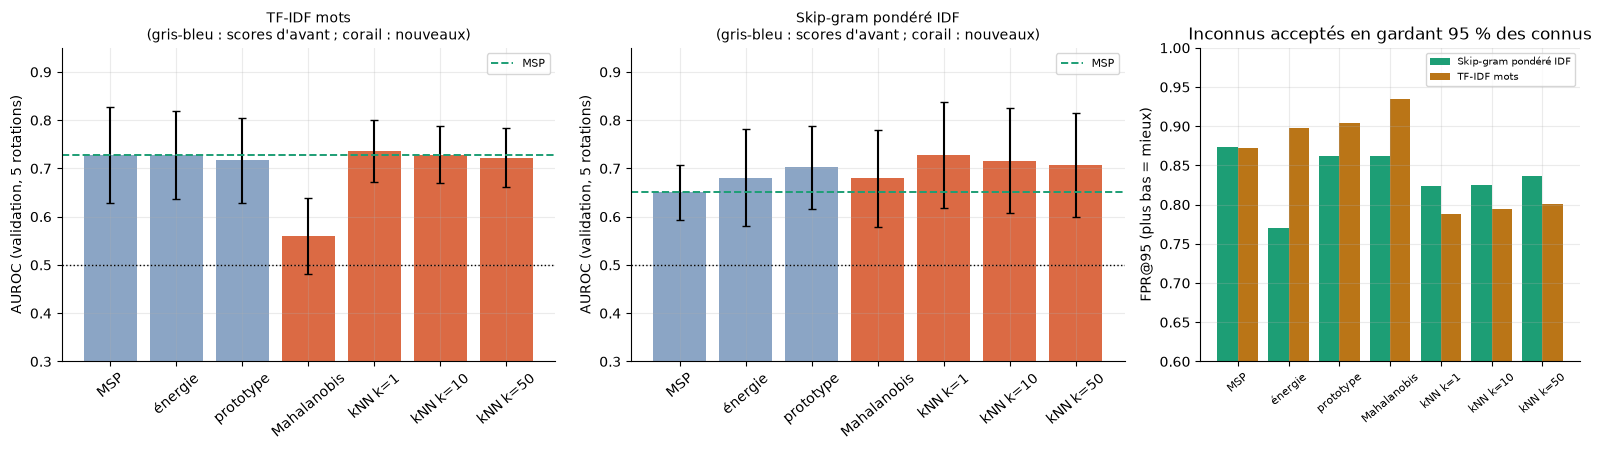

In [87]:
import tp2_new_figs as NF
fig = NF.fig_6_4b(DIRS["results"], DIRS["figures"]); plt.show()

**Lecture du visuel.** Les barres **gris-bleu** sont les scores d'avant (6.4), les barres **corail** les nouveaux ; le trait vert est le MSP ; les barres d'erreur montrent la variation **entre rotations**. Avec Skip-gram, kNN dépasse le MSP ; avec TF-IDF, Mahalanobis s'effondre et kNN est au niveau du MSP. À droite, kNN laisse passer moins d'inconnus (FPR@95 plus bas).

<!-- REV-6.4c -->
### 6.4c Mahalanobis avec TF-IDF : l'échec vient-il de la compression ?

**Pourquoi.** Avec TF-IDF, Mahalanobis (6.4b) est presque au niveau du hasard (AUROC 0,56). Pour l'utiliser, TF-IDF a été compressé à **50 dimensions** (31 % de la variance gardée). On ne sait donc pas si l'échec vient de **la méthode** ou de **cette compression**. Sur la remarque de l'étudiant, on le teste : même méthode, mêmes modèles, mêmes rotations et graines, avec **50, 100, 200 et 300 dimensions** (rien d'autre ne change).

**Règle de lecture, écrite avant les résultats.** Si, pour **au moins une** dimension, l'écart moyen de Mahalanobis avec le MSP vaut **au moins −0,01**, l'échec venait (au moins en partie) de la compression. Si **aucune** dimension ne la rattrape, l'échec tient aussi à la méthode sur nos logs. Dans les deux cas, la conclusion est limitée aux dimensions essayées et à la covariance commune (une covariance par classe n'est pas testée).

In [88]:
# ---- R6.4c : Mahalanobis avec TF-IDF compressé à plusieurs dimensions (reprise : un fichier de cache par rotation et par graine)
KS = (50, 100, 200, 300)
def maha_dims(rot, seed):
    hidden = ROTATIONS[rot]; known = [c for c in PAPER_CLASSES if c not in hidden]
    cfg = {"rot": rot, "seed": seed, "ks": KS, "ridge": 1e-3, "data_id": DATA_ID, "splits": SPLITS_SHA, "open_hash": OPEN_HASH, "protocol": "s6x2"}
    cj = CACHE6 / f"x2_{hashlib.sha256(json.dumps(cfg, sort_keys=True).encode()).hexdigest()[:16]}.json"
    if cj.exists(): return json.loads(cj.read_text())
    _, m = run_rotation("tfidf", rot, seed); smp = sample_known(seed, known); txt = [LOG[v][r] for v, r in zip(smp.version, smp.row)]; y = smp.category.values
    Xtr, Xva = m.transform(txt), m.transform(va_text); svd = TruncatedSVD(max(KS), random_state=seed).fit(Xtr); Zt, Zv = svd.transform(Xtr), svd.transform(Xva)
    is_known = ~np.isin(yva, hidden); classes = sorted(set(y)); idx = np.searchsorted(classes, y); res = {"rot": rot + 1, "seed": seed}
    for k in KS:
        Ztr, Zva = Zt[:, :k], Zv[:, :k]; mu = np.stack([Ztr[y == c].mean(0) for c in classes]); Zc = Ztr - mu[idx]
        S_ = (Zc.T @ Zc) / len(Zc); S_ += np.eye(k) * 1e-3 * np.trace(S_) / k; P_ = np.linalg.inv(S_)
        d2 = np.stack([(((Zva - mu[j]) @ P_) * (Zva - mu[j])).sum(1) for j in range(len(classes))], 1)
        res[str(k)] = {**open_metrics(-d2.min(1), is_known), "var": float(svd.explained_variance_ratio_[:k].sum())}
    cj.write_text(json.dumps(res)); return res
t_all = time.perf_counter(); md = [maha_dims(rot, sd) for rot in range(5) for sd in SEEDS["tfidf"]]; print(f"{len(md)} modèles évalués en {time.perf_counter() - t_all:.0f} s")
rows = []
for k in KS:
    per = pd.DataFrame([{"rot": r["rot"], "auroc": r[str(k)]["auroc"], "fpr95": r[str(k)]["fpr95"], "var": r[str(k)]["var"]} for r in md]).groupby("rot").mean()
    d_, w_, v_ = stab(per["auroc"].values, per_rot[("tfidf", "msp")])
    rows.append({"dimension k": k, "variance gardée": round(per["var"].mean(), 3), "AUROC Mahalanobis": round(per["auroc"].mean(), 4), "± entre rotations": round(per["auroc"].std(), 4), "FPR@95": round(per["fpr95"].mean(), 4), "Δ vs MSP": d_, "rotations gagnées": w_, "verdict": v_})
maha_df = pd.DataFrame(rows); print(maha_df.to_string(index=False)); print(f"\nRéférence TF-IDF : MSP {per_rot[('tfidf', 'msp')].mean():.4f}, kNN (k=10) {per_rot[('tfidf', 'knn10')].mean():.4f}")
rattrape = bool((maha_df["Δ vs MSP"] >= -0.01).any()); print("Règle écrite : Mahalanobis rattrape le MSP pour au moins une dimension ->", "OUI : la compression expliquait l'échec" if rattrape else "NON : l'échec ne vient pas seulement de la compression")
maha_df.to_csv(DIRS["results"] / "step6_mahalanobis_dimensions.csv", index=False)


15 modèles évalués en 0 s
 dimension k  variance gardée  AUROC Mahalanobis  ± entre rotations  FPR@95  Δ vs MSP rotations gagnées        verdict
          50            0.303             0.5695             0.0808  0.9351   -0.1586               1/5 indistinguable
         100            0.402             0.6307             0.0673  0.8867   -0.0974               1/5 indistinguable
         200            0.487             0.6281             0.0975  0.8590   -0.1000               2/5 indistinguable
         300            0.531             0.6441             0.0884  0.8720   -0.0840               2/5 indistinguable

Référence TF-IDF : MSP 0.7282, kNN (k=10) 0.7289
Règle écrite : Mahalanobis rattrape le MSP pour au moins une dimension -> NON : l'échec ne vient pas seulement de la compression


<!-- REV-6.4c-L -->
**Lecture (6.4c).** Avec plus de dimensions, Mahalanobis progresse, mais reste **sous** le MSP (0,7282) :

| Dimensions | Variance gardée | AUROC Mahalanobis | Δ vs MSP | Rotations gagnées |
|---|---|---|---|---|
| 50 | 0,303 | 0,5695 | −0,159 | 1/5 |
| 100 | 0,402 | 0,6307 | −0,097 | 1/5 |
| 200 | 0,487 | 0,6281 | −0,100 | 2/5 |
| 300 | 0,531 | 0,6441 | −0,084 | 2/5 |

**Règle écrite d'avance** (rattrape le MSP à 0,01 près pour au moins une dimension) : **non**. La compression à 50 dimensions **pénalisait** Mahalanobis (de 0,57 à 0,64 en gardant plus d'information), mais **n'explique pas à elle seule** l'écart. **Limites :** covariance **commune** à toutes les classes (une covariance par classe n'est pas testée), dimensions **au plus 300**, TF-IDF seulement.

**Registre (suite).**

| N° | Affirmation | Source | Niveau |
|---|---|---|---|
| V87 | Mahalanobis avec TF-IDF compressé : AUROC 0,5695 / 0,6307 / 0,6281 / 0,6441 pour 50 / 100 / 200 / 300 dimensions (MSP 0,7282) ; ne rattrape pas le MSP | Calcul (6.4c) | calcul (5 rotations) |

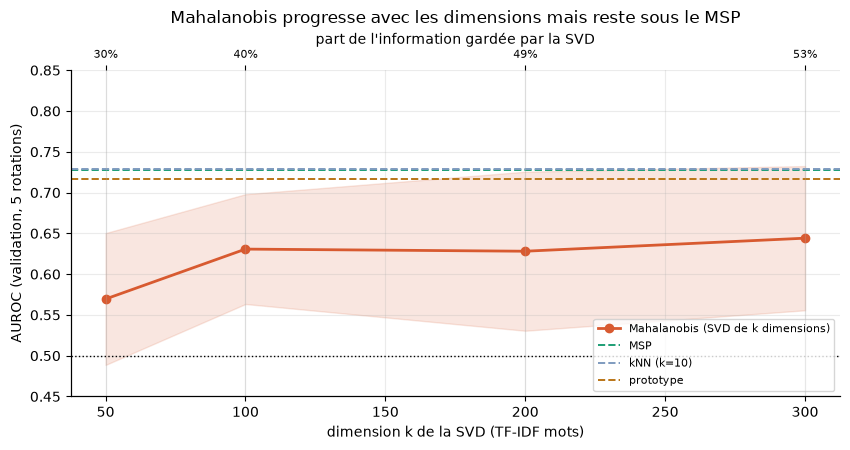

In [89]:
import tp2_new_figs as NF
fig = NF.fig_6_4c(DIRS["results"], DIRS["figures"]); plt.show()

**Lecture du visuel.** La courbe corail est Mahalanobis selon le nombre de dimensions gardées (la part d'information est en haut) ; la zone claire est la variation entre rotations. Elle monte de 0,57 à 0,64 mais **reste sous** le MSP (vert) et le kNN (gris-bleu) : la compression n'explique pas tout.

<!-- REV-6.4d -->
### 6.4d Le repli sur la famille (Linderman et al., 2022 ; section 0.1b.2)

**Idée.** Un log rejeté comme « inconnu » ressemble souvent à une **famille** connue sans être une **classe** connue (un échec de connexion ressemble à la famille « authentification »). Au lieu de « inconnu » tout court, on répond **« inconnu, probablement de la famille X »**, ce qui dit à l'analyste **où chercher en premier**. Conforme à l'étape 6 du sujet (« si possible, la famille la plus plausible »).

**Ce qu'on mesure.** Le rejet est celui de 6.4 (MSP, 95 % des connus gardés). On ne regarde que les logs **réellement inconnus**, **rejetés**, et dont la **famille est connue** (au moins une classe de cette famille est restée connue ; sinon la famille ne peut pas être proposée). Pour eux : **la famille proposée est-elle la bonne ?** On compare **quatre façons** de la proposer : (1) **toujours la famille majoritaire** de l'entraînement (le repère « sans intelligence »), (2) la famille de la **classe prédite par le modèle plat**, (3) la famille de la classe prédite par le **modèle hiérarchique**, (4) la **tête famille** directement, seule ou avec un **seuil** : on ne répond que si la famille est **plus sûre que 20 % des logs connus** (seuil calé sur les connus de validation, jamais sur un inconnu).

**Règle de lecture, écrite avant les chiffres.** Le repli est **utile** si la meilleure façon dépasse le repère (1) d'**au moins 0,10** d'exactitude en moyenne des rotations, **pour les deux représentations** ; sinon on dit qu'il n'est pas démontré. La mesure est limitée aux inconnus dont la famille est connue ; la part de ces inconnus est affichée.

In [90]:
# ---- R6.4d : repli sur la famille : pour un log rejeté comme inconnu, quelle famille proposer ? (reprise : un cache par modèle)
def fallback_eval(rep, rot, seed):
    hidden = ROTATIONS[rot]; known = [c for c in PAPER_CLASSES if c not in hidden]; known_fams = sorted({CHILD2FAM[c] for c in known})
    cfg = {"rep": rep, "rot": rot, "seed": seed, "tauf": 0.2, "data_id": DATA_ID, "splits": SPLITS_SHA, "open_hash": OPEN_HASH, "protocol": "s6x3"}
    cj = CACHE6 / f"x3_{hashlib.sha256(json.dumps(cfg, sort_keys=True).encode()).hexdigest()[:16]}.json"
    if cj.exists(): return json.loads(cj.read_text())
    _, m = run_rotation(rep, rot, seed); sc = m.scores(va_text); smp = sample_known(seed, known)
    is_known = ~np.isin(yva, hidden); thr = np.quantile(sc["msp"][is_known], 0.05); rej = sc["msp"] < thr          # même seuil qu'en 6.4 : 95 % des connus gardés
    true_fam = np.array([CHILD2FAM[c] for c in yva]); fam_conf = sc["P_family"].max(1); tauf = np.quantile(fam_conf[is_known], 0.2)   # famille « sûre » : plus sûre que 20 % des connus
    target = rej & ~is_known & np.isin(true_fam, known_fams)                                                       # inconnus rejetés dont la famille EST connue
    props = {"tête famille": sc["pred_family"], "famille de la classe (plat)": np.array([CHILD2FAM[c] for c in sc["pred_flat"]]), "famille de la classe (hiérarchique)": np.array([CHILD2FAM[c] for c in sc["pred_hier"]]),
             "toujours la famille majoritaire": np.full(len(yva), smp.category.map(CHILD2FAM).mode().iloc[0])}
    out = {"rep": rep, "rot": rot + 1, "seed": seed, "n_hidden": int((~is_known).sum()), "n_rej_hidden": int((rej & ~is_known).sum()), "n_target": int(target.sum()), "n_rej_known": int((rej & is_known).sum())}
    for k, f in props.items(): out[k] = float((f[target] == true_fam[target]).mean()) if target.any() else None
    ans = target & (fam_conf >= tauf); out["tête famille, avec seuil"] = float((props["tête famille"][ans] == true_fam[ans]).mean()) if ans.any() else None; out["part répondue"] = float(ans.sum() / max(target.sum(), 1))
    cj.write_text(json.dumps(out)); return out
t_all = time.perf_counter(); fb = [fallback_eval(rep, rot, sd) for rep, seeds in SEEDS.items() for rot in range(5) for sd in seeds]; print(f"{len(fb)} modèles évalués en {time.perf_counter() - t_all:.0f} s")
METH = ["toujours la famille majoritaire", "famille de la classe (plat)", "famille de la classe (hiérarchique)", "tête famille", "tête famille, avec seuil"]; rows = []
for rep in SEEDS:
    d = pd.DataFrame([r for r in fb if r["rep"] == rep]).groupby("rot").mean(numeric_only=True)
    print(f"\n{REPS[rep]} : parmi les logs inconnus rejetés, {d['n_target'].sum() / d['n_rej_hidden'].sum():.0%} appartiennent à une famille connue (en moyenne {d['n_target'].mean():.0f} logs par rotation)")
    for k in METH: rows.append({"représentation": REPS[rep], "façon de proposer une famille": k.replace(", avec seuil", " (avec seuil)"), "exactitude (moyenne des rotations)": round(d[k].mean(), 3), "pire rotation": round(d[k].min(), 3), "meilleure rotation": round(d[k].max(), 3), "part répondue": round(d["part répondue"].mean(), 3) if k.endswith("seuil") else 1.0})
fb_df = pd.DataFrame(rows); print(fb_df.to_string(index=False)); fb_df.to_csv(DIRS["results"] / "step6_repli_famille.csv", index=False)


20 modèles évalués en 0 s

TF-IDF mots : parmi les logs inconnus rejetés, 93% appartiennent à une famille connue (en moyenne 565 logs par rotation)

Skip-gram pondéré IDF : parmi les logs inconnus rejetés, 92% appartiennent à une famille connue (en moyenne 559 logs par rotation)
       représentation       façon de proposer une famille  exactitude (moyenne des rotations)  pire rotation  meilleure rotation  part répondue
          TF-IDF mots     toujours la famille majoritaire                               0.292          0.013               0.805          1.000
          TF-IDF mots         famille de la classe (plat)                               0.219          0.062               0.461          1.000
          TF-IDF mots famille de la classe (hiérarchique)                               0.238          0.023               0.606          1.000
          TF-IDF mots                        tête famille                               0.227          0.022               0.599          1.000


<!-- REV-6.4d-L -->
**Lecture (6.4d).** Parmi les logs **inconnus rejetés dont la famille est connue**, la famille proposée est **rarement juste** :

| Façon de proposer la famille | TF-IDF | Skip-gram |
|---|---|---|
| Toujours la famille majoritaire (repère) | 0,292 | 0,314 |
| Famille de la classe prédite (plat) | 0,219 | 0,275 |
| Famille de la classe prédite (hiérarchique) | 0,238 | 0,304 |
| Tête famille | 0,227 | 0,304 |
| Tête famille, avec seuil (réponse seulement si sûre) | 0,468 (répond dans 9,4 % des cas) | 0,446 (40 %) |

- **Règle écrite d'avance** (dépasser le repère « majoritaire » d'au moins 0,10 pour les deux représentations) : **non**. Aucune façon sans seuil ne bat le repère. Avec seuil, l'exactitude monte vers 0,45 mais **la couverture s'effondre** (9 % avec TF-IDF).
- **Conclusion.** Sur nos données, le repli sur la famille **n'est pas démontré utile** : la famille proposée n'est pas plus fiable qu'une réponse constante. Dans le rapport, il faut le présenter comme **une idée testée et non démontrée**, pas comme une capacité du système.
- **Explication plausible, non testée.** Les logs rejetés sont ceux qui **déroutent le plus** le modèle ; sa devinette de famille y est donc la moins fiable.
- **Limites.** Mesure restreinte aux inconnus dont la famille est connue ; seuil de famille à 20 % fixé sur les connus ; une seule règle de rejet (MSP à 95 %).

**Registre (suite).**

| N° | Affirmation | Source | Niveau |
|---|---|---|---|
| V88 | Repli sur la famille (Linderman et al., 2022) : famille proposée juste dans 0,22 à 0,31 des cas sans seuil, contre 0,29 (TF-IDF) et 0,31 (Skip-gram) pour la famille majoritaire ; avec seuil 0,47 / 0,45 mais réponse dans 9 % / 40 % des cas ; non démontré utile | Calcul (6.4d) | calcul (5 rotations) |

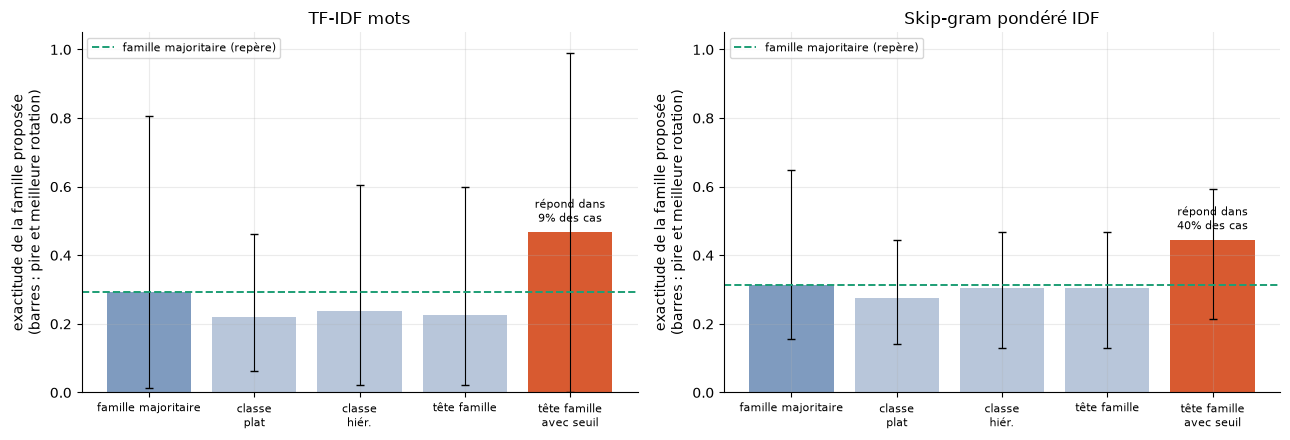

In [91]:
import tp2_new_figs as NF
fig = NF.fig_6_4d(DIRS["results"], DIRS["figures"]); plt.show()

**Lecture du visuel.** Chaque barre est l'exactitude de la famille proposée pour un inconnu rejeté ; les traits noirs donnent la pire et la meilleure rotation ; le trait vert est la famille majoritaire. **Aucune** façon ne dépasse nettement ce repère ; avec un seuil (corail), l'exactitude monte mais le modèle ne répond que dans une minorité de cas (9 % avec TF-IDF).

<!-- REV-6.4e -->
### 6.4e OpenMax (Bendale et Boult, 2016)

**Source.** Article **relu en texte intégral** (arXiv 1511.06233, algorithmes 1 et 2) avant l'implémentation ; les paramètres ci-dessous viennent de l'article, **pas** d'un réglage sur nos données.

**Principe, en simple.** Pour chaque classe connue, on retient le **vecteur d'activations moyen** des exemples bien classés. Un log trop **loin** de ce vecteur moyen est jugé **suspect pour cette classe** ; on retire alors une part de l'activation de cette classe et on la donne à une classe artificielle « **inconnu** ». Plus le log est loin, plus la part retirée est grande.

**Algorithme suivi.**
1. **Calibrage (algorithme 1).** Pour chaque classe $j$ : moyenne $\mu_j$ des vecteurs d'activations des exemples d'entraînement **bien classés** de $j$ ; distances euclidiennes de ces exemples à $\mu_j$ ; **loi de Weibull** ajustée sur les $\eta$ **plus grandes** distances (queue), avec $\eta=20$ (valeur de l'article).
2. **Révision (algorithme 2).** Pour un log $x$ : on prend les $\alpha=10$ classes les plus actives (valeur de l'article) ; pour chacune, on calcule la probabilité de Weibull (fonction de répartition, qui **croît avec la distance** à $\mu_j$), pondérée par le rang ; on réduit l'activation de cette classe d'autant et la part retirée devient l'activation de la classe « inconnu » (indice 0) ; softmax sur les classes révisées.
3. **Score de « connu »** : la **meilleure probabilité révisée parmi les classes connues** (faible si « inconnu » domine ou si toutes les classes sont affaiblies).

**Adaptation à notre cas.** L'article travaille sur la **couche d'activations** d'un réseau profond ; ici, le « vecteur d'activations » est le **vecteur des logits du classifieur plat** (24 valeurs par rotation). C'est une **adaptation** et non la reproduction de l'article. *Point de vigilance :* la mise en forme du PDF extrait fait apparaître une exponentielle dans la ligne 3 de l'algorithme 2 ; nous suivons la **description textuelle** de l'article (« probabilité de la loi de Weibull », qui augmente avec la distance), **sans avoir consulté** l'implémentation de référence.

**Règle de lecture, écrite avant les chiffres** (la même qu'en 6.4b) : « gain régulier » si meilleur que le MSP dans les **5 rotations sur 5** avec un écart moyen d'au moins 0,01 ; « perte régulière » dans le cas inverse ; sinon « indistinguable ». **Pas de prédiction ferme** (exploratoire). *Risque identifié d'avance :* les logits d'**entraînement** d'un classifieur linéaire presque séparable sont très grands ; ceux de la validation (gabarits nouveaux) sont plus petits : tous les logs, connus compris, peuvent paraître « loin » du vecteur moyen. *Limites :* une seule distance (euclidienne), une seule valeur de $\eta$ et de $\alpha$, pas de réglage de $\varepsilon$ (le seuil est celui des autres scores : 95 % des connus gardés).

In [92]:
# ---- R6.4e : OpenMax (Bendale et Boult, 2016) sur les logits du classifieur plat (reprise : un cache par modèle)
from scipy.stats import weibull_min
from scipy.special import softmax as _softmax
ETA, ALPHA = 20, 10                                            # taille de la queue et nombre de classes révisées : valeurs de l'article (ImageNet) ; non réglées sur nos données
def openmax_fit(L, y_idx, eta=ETA):
    N = L.shape[1]; pred = L.argmax(1); mu = np.zeros((N, N)); par = np.zeros((N, 3))
    for j in range(N):
        S = L[(y_idx == j) & (pred == j)]; mu[j] = S.mean(0)                                          # vecteur d'activation moyen, exemples bien classés seulement (Alg. 1, ligne 2)
        tail = np.sort(np.linalg.norm(S - mu[j], axis=1))[-eta:]; tau = tail.min() - 1.0              # les ETA plus grandes distances, décalées pour être positives (comme libMR FitHigh)
        k, _, lam = weibull_min.fit(tail - tau, floc=0); par[j] = (tau, k, lam)                       # loi de Weibull ajustée sur la queue (Alg. 1, ligne 3)
    return mu, par
def openmax_score(L, mu, par, alpha=ALPHA):
    n, N = L.shape; alpha = min(alpha, N); order = np.argsort(-L, axis=1)[:, :alpha]; w = np.ones((n, N))
    for r in range(alpha):
        j = order[:, r]; d = np.linalg.norm(L - mu[j], axis=1); tau, k, lam = par[j, 0], par[j, 1], par[j, 2]
        cdf = 1 - np.exp(-(np.clip(d - tau, 0, None) / lam) ** k)                                      # probabilité « valeur aberrante pour cette classe »
        w[np.arange(n), j] = 1 - ((alpha - (r + 1)) / alpha) * cdf                                     # poids de révision (Alg. 2, lignes 2 à 4)
    v0 = (L * (1 - w)).sum(1); P = _softmax(np.concatenate([v0[:, None], L * w], axis=1), axis=1)      # classe « inconnu » d'indice 0 (Alg. 2, lignes 5 à 7)
    return P[:, 1:].max(1)                                                                             # score de « connu » : meilleure probabilité révisée parmi les classes connues
def openmax_eval(rep, rot, seed, eta=ETA, alpha=ALPHA):
    hidden = ROTATIONS[rot]; known = [c for c in PAPER_CLASSES if c not in hidden]
    cfg = {"rep": rep, "rot": rot, "seed": seed, "eta": eta, "alpha": alpha, "data_id": DATA_ID, "splits": SPLITS_SHA, "open_hash": OPEN_HASH, "protocol": "s6x4"}
    cj = CACHE6 / f"x4_{hashlib.sha256(json.dumps(cfg, sort_keys=True).encode()).hexdigest()[:16]}.json"
    if cj.exists(): return json.loads(cj.read_text())
    _, m = run_rotation(rep, rot, seed); smp = sample_known(seed, known); txt = [LOG[v][r] for v, r in zip(smp.version, smp.row)]
    cls = list(m.flat_.classes_); y_idx = np.array([cls.index(c) for c in smp.category.values])
    mu, par = openmax_fit(m.flat_.decision_function(m.transform(txt)), y_idx, eta); Lv = m.flat_.decision_function(m.transform(va_text))
    is_known = ~np.isin(yva, hidden); correct = (np.array(cls)[Lv.argmax(1)] == yva); res = {"rep": rep, "rot": rot + 1, "seed": seed, "openmax": open_metrics(openmax_score(Lv, mu, par, alpha), is_known, correct=correct)}
    cj.write_text(json.dumps(res)); return res
t_all = time.perf_counter(); om = [openmax_eval(rep, rot, sd) for rep, seeds in SEEDS.items() for rot in range(5) for sd in seeds]; print(f"{len(om)} modèles évalués en {time.perf_counter() - t_all:.0f} s")
rows = []
for rep in SEEDS:
    d = pd.DataFrame([{"rot": r["rot"], **{k: r["openmax"][k] for k in ("auroc", "fpr95", "oscr")}} for r in om if r["rep"] == rep]).groupby("rot").mean()
    d_, w_, v_ = stab(d["auroc"].values, per_rot[(rep, "msp")]); d2_, w2_, v2_ = stab(d["auroc"].values, per_rot[(rep, "knn10")])
    rows.append({"représentation": REPS[rep], "AUROC OpenMax": round(d["auroc"].mean(), 4), "± entre rotations": round(d["auroc"].std(), 4), "FPR@95": round(d["fpr95"].mean(), 4), "OSCR": round(d["oscr"].mean(), 4),
                 "AUROC MSP": round(per_rot[(rep, "msp")].mean(), 4), "Δ vs MSP": d_, "rotations gagnées": w_, "verdict vs MSP": v_})
    print(f"{REPS[rep]} : AUROC par rotation, OpenMax {d['auroc'].values.round(3)} ; MSP {per_rot[(rep, 'msp')].round(3)}")
om_df = pd.DataFrame(rows); print(om_df.to_string(index=False)); om_df.to_csv(DIRS["results"] / "step6_openmax.csv", index=False)


20 modèles évalués en 0 s
TF-IDF mots : AUROC par rotation, OpenMax [0.838 0.834 0.573 0.756 0.717] ; MSP [0.806 0.794 0.562 0.767 0.712]
Skip-gram pondéré IDF : AUROC par rotation, OpenMax [0.659 0.835 0.582 0.587 0.59 ] ; MSP [0.722 0.687 0.6   0.658 0.586]
       représentation  AUROC OpenMax  ± entre rotations  FPR@95   OSCR  AUROC MSP  Δ vs MSP rotations gagnées verdict vs MSP
          TF-IDF mots         0.7436             0.1082  0.7930 0.5707     0.7282    0.0154               4/5 indistinguable
Skip-gram pondéré IDF         0.6506             0.1080  0.8915 0.4868     0.6505    0.0001               2/5 indistinguable


<!-- REV-6.4e-L -->
**Lecture (6.4e).**

| Représentation | AUROC OpenMax (η=20, α=10) | AUROC MSP | Δ | Rotations gagnées | Verdict (règle 5/5) |
|---|---|---|---|---|---|
| TF-IDF mots | **0,7436** | 0,7282 | +0,0154 | 4/5 | indistinguable |
| Skip-gram pondéré IDF | 0,6506 | 0,6505 | +0,0001 | 2/5 | indistinguable |

- Avec TF-IDF, OpenMax est **un peu meilleur** que le MSP (AUROC par rotation : 0,838 / 0,834 / 0,573 / 0,756 / 0,717 contre 0,806 / 0,794 / 0,562 / 0,767 / 0,712) ; FPR@95 **0,79** contre 0,87. Il ne gagne pas dans les 5 rotations (la rotation 4 lui échappe) : la règle écrite d'avance donne « indistinguable ». Avec Skip-gram, il est **au niveau** du MSP.
- Le risque identifié d'avance (logits d'entraînement plus grands que ceux de la validation, donc des connus « loin » du vecteur moyen) **ne s'est pas traduit par un effondrement** : OpenMax fait au moins aussi bien que le MSP avec TF-IDF.

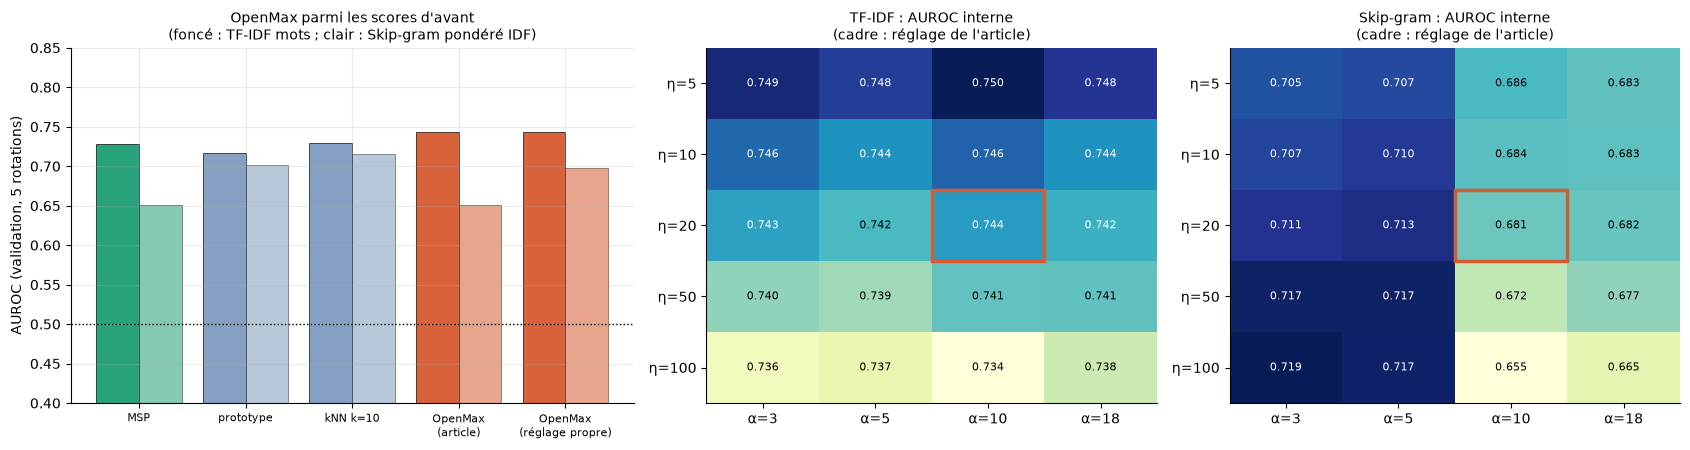

In [93]:
import tp2_new_figs as NF
fig = NF.fig_6_4e(DIRS["results"], DIRS["figures"]); plt.show()

**Lecture du visuel.** À gauche, OpenMax (corail, réglage de l'article puis réglage propre) à côté des scores d'avant (foncé : TF-IDF, clair : Skip-gram). À droite, l'AUROC du **test interne** (6 classes connues masquées pour de faux) pour chaque réglage ; le cadre corail est le réglage de l'article. Avec Skip-gram, une queue longue et peu de classes révisées (en haut à droite des cases foncées) fait nettement mieux ; avec TF-IDF, tout est dans le même ordre de grandeur.

<!-- REV-6.4f -->
### 6.4f Nos propres réglages d'OpenMax, sans regarder les classes masquées

**Pourquoi.** En 6.4e, OpenMax utilise les réglages de l'article ($\eta=20$ distances extrêmes pour la loi de Weibull, $\alpha=10$ classes révisées), choisis sur un tout autre problème (images, 1 000 classes). On cherche si d'autres valeurs conviennent mieux **à nos logs**.

**Règle pour ne pas tricher.** On ne règle **jamais** sur les 6 classes masquées de la rotation (ce sont celles qu'on veut ensuite détecter). On masque **6 classes de plus, parmi les 24 déjà connues**, au hasard (graine fixée, différente par rotation), on réentraîne sur les 18 restantes et on mesure la détection de ces 6 classes masquées « **pour de faux** » (validation des classes connues de la rotation seulement). Grille : $\eta\in\{5,10,20,50,100\}$, $\alpha\in\{3,5,10,18\}$. On garde le réglage au **meilleur AUROC interne moyen** sur les 5 rotations, **seulement si** il dépasse celui de l'article d'**au moins 0,01** ; sinon on garde l'article (le plus simple). Le réglage retenu est ensuite mesuré sur les **vraies** classes masquées et comparé au réglage de l'article et au MSP, avec la même règle 5 rotations sur 5 qu'en 6.4b.

*Limites dites d'avance.* Une seule graine ; un seul tirage de classes masquées « pour de faux » par rotation ; le test a déjà été ouvert (étape 7) : ce réglage est évalué sur la **validation** et ne peut **plus** être confirmé sur un test neuf.

In [94]:
# ---- R6.4f : réglage d'OpenMax (η, α) SANS regarder les classes masquées de la rotation (reprise : un cache par représentation et rotation)
ETAS, ALPHAS = (5, 10, 20, 50, 100), (3, 5, 10, 18)
def inner_openmax(rep, rot, seed=42):
    hidden = ROTATIONS[rot]; known = [c for c in PAPER_CLASSES if c not in hidden]; rng = np.random.default_rng(1000 + rot)
    inner_hidden = sorted(rng.choice(known, 6, replace=False).tolist()); inner_known = [c for c in known if c not in inner_hidden]            # 6 classes CONNUES masquées « pour de faux »
    cfg = {"rep": rep, "rot": rot, "seed": seed, "inner_hidden": inner_hidden, "etas": ETAS, "alphas": ALPHAS, "data_id": DATA_ID, "splits": SPLITS_SHA, "open_hash": OPEN_HASH, "protocol": "s6x5"}
    cj = CACHE6 / f"x5_{hashlib.sha256(json.dumps(cfg, sort_keys=True).encode()).hexdigest()[:16]}.json"
    if cj.exists(): return json.loads(cj.read_text())
    smp = sample_known(seed, inner_known); txt = [LOG[v][r] for v, r in zip(smp.version, smp.row)]; sel = (S.split == "train") & S.category.isin(inner_known)
    kt = [LOG[v][r] for v, r in zip(S.loc[sel, "version"], S.loc[sel, "row"])] if rep == "sg_idf" else txt
    m = OpenSetModel(rep, inner_known, CHILD2FAM, C=C_BEST, seed=seed, n_ens=0).fit(txt, smp.category.values, kt, word_tokens)
    cls = list(m.flat_.classes_); y_idx = np.array([cls.index(c) for c in smp.category.values]); Ltr = m.flat_.decision_function(m.transform(txt))
    vm = ~np.isin(yva, hidden); Lv = m.flat_.decision_function(m.transform([t for t, k in zip(va_text, vm) if k])); is_in = ~np.isin(yva[vm], inner_hidden)      # validation : classes connues de la rotation seulement
    out = {"rep": rep, "rot": rot + 1, "inner_hidden": inner_hidden, "msp": float(open_metrics(_softmax(Lv, axis=1).max(1), is_in)["auroc"])}
    for eta in ETAS:
        mu, par = openmax_fit(Ltr, y_idx, eta)
        for alpha in ALPHAS: out[f"{eta}_{alpha}"] = float(open_metrics(openmax_score(Lv, mu, par, alpha), is_in)["auroc"])
    cj.write_text(json.dumps(out)); return out
t_all = time.perf_counter(); inner = {rep: [inner_openmax(rep, rot) for rot in range(5)] for rep in SEEDS}; print(f"réglage interne en {time.perf_counter() - t_all:.0f} s")
CHOSEN = {}; rows = []
for rep in SEEDS:
    g = pd.DataFrame([{k: v for k, v in r.items() if k[0].isdigit() or k == "msp"} for r in inner[rep]]).mean(); art = g[f"{ETA}_{ALPHA}"]; grid = g.drop("msp")
    best = grid.idxmax(); CHOSEN[rep] = (ETA, ALPHA) if grid[best] - art < 0.01 else tuple(int(x) for x in best.split("_"))
    print(f"\n{REPS[rep]} : AUROC interne moyen (6 classes connues masquées pour de faux), MSP {g['msp']:.4f}")
    print(pd.DataFrame({a: [round(grid[f"{e}_{a}"], 4) for e in ETAS] for a in ALPHAS}, index=[f"η = {e}" for e in ETAS]).rename(columns=lambda a: f"α = {a}").to_string())
    print(f"Article (η={ETA}, α={ALPHA}) : {art:.4f} ; meilleur : {best} = {grid[best]:.4f} ; réglage retenu (règle : écart d'au moins 0,01 sinon l'article) : η={CHOSEN[rep][0]}, α={CHOSEN[rep][1]}")
om_t = [openmax_eval(rep, rot, sd, *CHOSEN[rep]) for rep, seeds in SEEDS.items() for rot in range(5) for sd in seeds]
for rep in SEEDS:
    d = pd.DataFrame([{"rot": r["rot"], **{k: r["openmax"][k] for k in ("auroc", "fpr95")}} for r in om_t if r["rep"] == rep]).groupby("rot").mean(); d_, w_, v_ = stab(d["auroc"].values, per_rot[(rep, "msp")])
    a_ = pd.DataFrame([{"rot": r["rot"], "auroc": r["openmax"]["auroc"]} for r in om if r["rep"] == rep]).groupby("rot").mean()["auroc"].mean()
    rows.append({"représentation": REPS[rep], "réglage": f"η={CHOSEN[rep][0]}, α={CHOSEN[rep][1]}", "AUROC OpenMax (vraies classes masquées)": round(d["auroc"].mean(), 4), "AUROC OpenMax, réglage de l'article": round(a_, 4), "AUROC MSP": round(per_rot[(rep, "msp")].mean(), 4), "Δ vs MSP": d_, "rotations gagnées": w_, "verdict vs MSP": v_})
om_t_df = pd.DataFrame(rows); print("\n" + om_t_df.to_string(index=False)); om_t_df.to_csv(DIRS["results"] / "step6_openmax_reglage.csv", index=False)


réglage interne en 0 s

TF-IDF mots : AUROC interne moyen (6 classes connues masquées pour de faux), MSP 0.7619
          α = 3   α = 5  α = 10  α = 18
η = 5    0.7490  0.7476  0.7500  0.7480
η = 10   0.7457  0.7440  0.7459  0.7440
η = 20   0.7432  0.7419  0.7435  0.7424
η = 50   0.7397  0.7393  0.7410  0.7411
η = 100  0.7356  0.7365  0.7342  0.7379
Article (η=20, α=10) : 0.7435 ; meilleur : 5_10 = 0.7500 ; réglage retenu (règle : écart d'au moins 0,01 sinon l'article) : η=20, α=10

Skip-gram pondéré IDF : AUROC interne moyen (6 classes connues masquées pour de faux), MSP 0.6997
          α = 3   α = 5  α = 10  α = 18
η = 5    0.7050  0.7066  0.6858  0.6830
η = 10   0.7075  0.7099  0.6840  0.6831
η = 20   0.7113  0.7131  0.6814  0.6821
η = 50   0.7171  0.7171  0.6718  0.6772
η = 100  0.7189  0.7167  0.6552  0.6650
Article (η=20, α=10) : 0.6814 ; meilleur : 100_3 = 0.7189 ; réglage retenu (règle : écart d'au moins 0,01 sinon l'article) : η=100, α=3

       représentation    réglage  AUR

<!-- REV-6.4f-L -->
**Lecture (6.4f).** Réglage interne (AUROC moyen sur 5 rotations, 6 classes **connues** masquées « pour de faux », jamais les vraies) :

| Représentation | MSP (interne) | Article (η=20, α=10) | Meilleur de la grille | Réglage retenu |
|---|---|---|---|---|
| TF-IDF mots | **0,7619** | 0,7435 | 0,7500 (η=5, α=10) | **η=20, α=10** (gain de 0,0065 < 0,01 : on garde l'article) |
| Skip-gram pondéré IDF | 0,6997 | 0,6814 | **0,7189** (η=100, α=3) | **η=100, α=3** (gain de 0,038 ≥ 0,01) |

Sur les **vraies** classes masquées :

| Représentation | Réglage | AUROC OpenMax | Article | MSP | Δ vs MSP | Rotations gagnées |
|---|---|---|---|---|---|---|
| TF-IDF mots | η=20, α=10 | 0,7436 | 0,7436 | 0,7282 | +0,0154 | 4/5 |
| Skip-gram pondéré IDF | η=100, α=3 | **0,6982** | 0,6506 | 0,6505 | **+0,0477** | 4/5 |

- **TF-IDF :** aucun réglage ne dépasse celui de l'article d'au moins 0,01 : on le garde. Le test interne place même le **MSP devant** tous les réglages d'OpenMax (0,7619 contre au plus 0,7500), alors que sur les vraies classes masquées OpenMax est légèrement devant (0,7436 contre 0,7282) : **les deux mesures ne s'accordent pas**, ce qui montre que l'écart entre OpenMax et le MSP est **dans le bruit** de nos données.
- **Skip-gram :** le réglage retenu (queue longue, peu de classes révisées) améliore OpenMax de **0,048** sur les vraies classes masquées ; verdict de la règle 5/5 : « indistinguable » (4 rotations sur 5).
- **Limites.** Une seule graine ; un seul tirage de classes masquées « pour de faux » par rotation ; le test a été ouvert à l'étape 7 : ces résultats sont sur la **validation** et ne peuvent **plus** être confirmés sur un test neuf. OpenMax **ne remplace pas** les scores retenus (fixés avant le test).

**Registre (suite).**

| N° | Affirmation | Source | Niveau |
|---|---|---|---|
| V89 | OpenMax (Bendale et Boult, 2016, arXiv 1511.06233 ; article relu en texte intégral, algorithmes 1 et 2 ; η=20, α=10) sur les logits du classifieur plat : AUROC TF-IDF 0,7436 (MSP 0,7282, 4 rotations sur 5), Skip-gram 0,6506 (MSP 0,6505) ; adaptation, non reproduction | Calcul (6.4e) + lecture de l'article | calcul (5 rotations) |
| V90 | Réglage interne d'OpenMax sur 6 classes connues masquées : TF-IDF garde l'article (gain 0,0065) ; Skip-gram η=100, α=3 (0,7189 contre 0,6814 en interne ; 0,6982 contre 0,6506 sur les vraies classes masquées) | Calcul (6.4f) | calcul (une graine) |

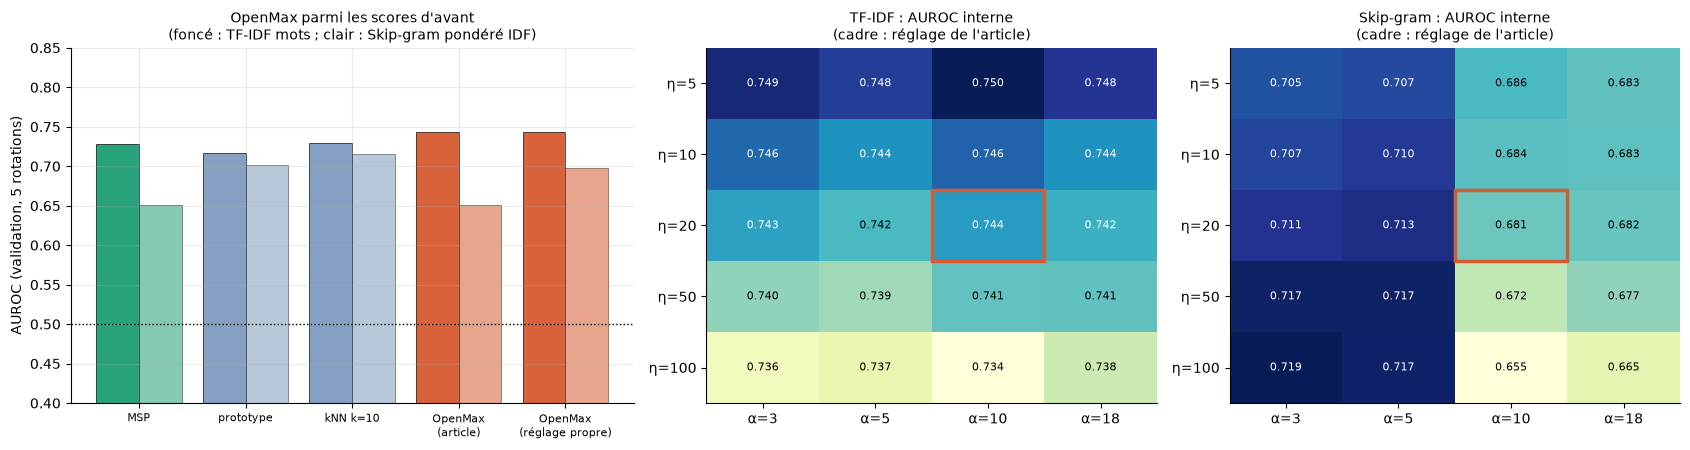

In [95]:
import tp2_new_figs as NF
fig = NF.fig_6_4e(DIRS["results"], DIRS["figures"]); plt.show()

**Lecture du visuel.** (Même figure qu'en 6.4e, rappelée ici pour comparer le réglage de l'article et le réglage retenu : TF-IDF garde celui de l'article, Skip-gram prend η = 100 et α = 3.)

In [96]:
rows = []
for rep in SEEDS:
    cl = pd.DataFrame([r["closed"] for r in runs if r["rep"] == rep]); rows.append({"représentation": REPS[rep], **{k: round(float(cl[k].mean()), 4) for k in cl.columns}})
print(pd.DataFrame(rows).to_string(index=False))

       représentation  f1_flat  f1_hier  f1_family    ece  dist_flat  dist_hier
          TF-IDF mots   0.6431   0.6332     0.8326 0.1537     0.4658     0.4676
Skip-gram pondéré IDF   0.6601   0.6563     0.8186 0.2477     0.4687     0.4797


**Lecture (classes connues, moyenne des rotations).** Macro-F1 fermée plat / hiérarchique : **0,643 / 0,633** (TF-IDF), **0,660 / 0,656** (Skip-gram) : le plat reste **légèrement devant**, de l'ordre de 0,01 ; la distance moyenne d'erreur est la même. **ECE de 0,154 (TF-IDF) et 0,248 (Skip-gram)** : la **confiance annoncée est très mal calibrée** (le modèle se dit sûr, en validation, bien plus souvent qu'il n'a raison) ; un seuil de rejet fixé sur la probabilité brute n'a donc **pas** de sens tel quel (mise en garde de l'étape 0, réponse possible : calibrer, étape 9).

## 6.5 Le modèle Transformer : préparation du calcul sur GPU

**Ce qu'on attend de lui.** Un encodeur (DistilBERT) avec **deux têtes** (famille et classe fine), entraîné par une perte somme des deux entropies croisées, et dont on obtient, en plus des logits, le **Monte-Carlo dropout** (T = 10 passages avec dropout actif : la moyenne et la dispersion des probabilités mesurent l'incertitude du modèle).

**Plan des runs (écrit avant d'avoir le moindre résultat).** `distilbert-base-uncased` sur les 5 rotations (avec MC dropout) ; `distilbert-base-cased` sur les 5 rotations (sans MC dropout) pour trancher **casse contre sans casse** (annoncé à l'étape 4) ; contrôle de la fenêtre **512 contre 256 jetons** sur la rotation 1 (annoncé à l'étape 5). Une seule graine, 2 époques, taux 3e-5, lot 32 (réglages usuels, non optimisés).

**Où et comment.** Sur **GPU T4 de Colab** (le GPU Kaggle reste indisponible). Le fichier de données exporté ci-dessous contient **uniquement** des logs d'**entraînement et de validation** (le test reste scellé). Le calcul est piloté par le notebook `colab/tp2_encoder_colab.ipynb` (explicatif, **sans analyse**) ; **toutes les analyses sont ici**.

In [97]:
COLAB_DIR = PROJECT_ROOT / "colab"; COLAB_DIR.mkdir(exist_ok=True)
enc_tr = sample_rows("train", 140, int(CONFIG["seed"]) + 21)
def pack(df_, split):
    return pd.DataFrame({"split": split, "version": df_.version.values, "row": df_.row.values, "category": df_.category.values, "family": [CHILD2FAM[c] for c in df_.category],
                         "group": df_.group.values, "text": [normalize(LOG[v][r]) for v, r in zip(df_.version, df_.row)]})
enc_data = pd.concat([pack(enc_tr, "train"), pack(va_rows, "val")], ignore_index=True)
assert set(enc_data.split) == {"train", "val"}, "le test ne doit pas être exporté"
assert not (set(zip(enc_data[enc_data.split == "train"].version, enc_data[enc_data.split == "train"].row)) & set(zip(enc_data[enc_data.split == "val"].version, enc_data[enc_data.split == "val"].row))), "un log est à la fois en train et en val"
p_enc = COLAB_DIR / "encoder_data.csv.gz"; enc_data.to_csv(p_enc, index=False, compression={"method": "gzip", "mtime": 0})
(COLAB_DIR / "taxonomy_and_rotations_v1.json").write_text((DIRS["data"] / "taxonomy_and_rotations_v1.json").read_text())
print(f"Écrit : {p_enc.relative_to(PROJECT_ROOT)}  {p_enc.stat().st_size / 1e6:.1f} Mo  ({(enc_data.split == 'train').sum():,} logs d'entraînement, {(enc_data.split == 'val').sum():,} de validation ; aucun log de test)")
print("Ordre des logs de validation identique à celui des étapes précédentes :", bool((enc_data[enc_data.split == 'val'].reset_index(drop=True)[["version", "row"]].values == va_rows[["version", "row"]].values).all()))

Écrit : colab/encoder_data.csv.gz  3.1 Mo  (25,200 logs d'entraînement, 23,940 de validation ; aucun log de test)
Ordre des logs de validation identique à celui des étapes précédentes : True


<!-- ENC-AUTO -->
## 6.10 L'encodeur Transformer sur la validation (sorties de Colab)

In [98]:
from scipy.special import softmax, logsumexp
from sklearn.metrics import roc_auc_score
ENC_DIR = PROJECT_ROOT / "colab"; FAMS_ENC = sorted(TAXONOMY)                    # même ordre que dans le notebook Colab (sorted(taxonomy))
_ed = pd.read_csv(ENC_DIR / "encoder_data_v2.csv.gz", usecols=["split", "version", "row"])
def _perm(enc_df, nb_df):
    key = lambda d: d["version"].astype(np.int64).values * 10**7 + d["row"].astype(np.int64).values
    pos = pd.Series(np.arange(len(enc_df)), index=key(enc_df)); p = pos.reindex(key(nb_df)).values
    assert not np.isnan(p).any() and len(set(p)) == len(nb_df), "les logs de l'encodeur ne coïncident pas avec ceux du notebook"
    return p.astype(int)
PERM = {"val": _perm(_ed[_ed.split == "val"].reset_index(drop=True), va_rows)}                       # l'alignement du test est fait en 7.8 (le test n'existe pas encore ici)
print("Alignement : validation", len(PERM["val"]), "logs (mêmes (version, ligne) que le notebook)")

def macro_f1_conf(C):                                                           # C : (B, K, K) matrices de confusion ; macro-F1 sur les classes présentes
    tp = np.einsum("bkk->bk", C); fp = C.sum(1) - tp; fn = C.sum(2) - tp; sup = C.sum(2) > 0
    return ((2 * tp / np.maximum(2 * tp + fp + fn, 1)) * sup).sum(1) / sup.sum(1)
def boot_f1_diff(y_i, pa, pb, groups, K, B=400, seed=42):
    """Écart de macro-F1 (b - a), rééchantillonné PAR GABARIT (même protocole que les modèles linéaires)."""
    ug, gi = np.unique(groups, return_inverse=True); Ma = np.zeros((len(ug), K * K)); Mb = np.zeros((len(ug), K * K))
    np.add.at(Ma, (gi, y_i * K + pa), 1); np.add.at(Mb, (gi, y_i * K + pb), 1)
    W = np.random.default_rng(seed).multinomial(len(ug), np.ones(len(ug)) / len(ug), size=B).astype(float)
    d = macro_f1_conf((W @ Mb).reshape(B, K, K)) - macro_f1_conf((W @ Ma).reshape(B, K, K))
    return float(d.mean()), float(np.quantile(d, .025)), float(np.quantile(d, .975))

def enc_eval(npz, jsn, split, y, groups):
    d = np.load(npz); meta = json.load(open(jsn)); known = meta["known"]; p = PERM[split]
    lf, lfam, mc = d["logits_fine"][p], d["logits_fam"][p], d["mc_fine"][p]; kn = np.array(known); isk = np.isin(y, known)
    has_mc = bool(np.abs(d["mc_fine"]).sum() > 0)
    pred = kn[lf.argmax(1)]; correct = pred == y
    famok = np.array([[CHILD2FAM[c] == f for c in known] for f in FAMS_ENC])    # (familles, classes connues) : classes autorisées par famille
    fp_ = lfam.argmax(1); allowed = famok[fp_]; lh = np.where(allowed, lf, -np.inf); empty = ~allowed.any(1)
    pred_h = np.where(empty, pred, kn[np.where(empty[:, None], lf, lh).argmax(1)])    # tête hiérarchique : meilleure classe DANS la famille prédite
    sc = {"msp": softmax(lf, 1).max(1), "energy": logsumexp(lf, 1)}
    if has_mc: sc["mc"] = mc.max(1)
    out = {"tag": meta["tag"], "n_known": int(isk.sum()), "train_min": meta["info"].get("train_minutes")}
    yk = y[isk]; out["acc"] = float(correct[isk].mean()); out["f1_flat"] = float(f1_score(yk, pred[isk], average="macro")); out["f1_hier"] = float(f1_score(yk, pred_h[isk], average="macro"))
    out["f1_fam"] = float(f1_score([CHILD2FAM[c] for c in yk], np.array(FAMS_ENC)[fp_][isk], average="macro")); out["ece"] = float(ece(sc["msp"][isk], correct[isk]))
    for s_, v in sc.items():
        m_ = open_metrics(v, isk, correct=correct); out.update({f"auroc_{s_}": m_["auroc"], f"aupr_{s_}": m_["aupr_in"], f"fpr95_{s_}": m_["fpr95"], f"oscr_{s_}": m_["oscr"]})
    hidden = sorted(set(meta["hidden"])); out["per_hidden"] = {cl: float(open_metrics(sc["msp"][(y == cl) | isk], isk[(y == cl) | isk])["auroc"]) for cl in hidden}
    ci = {c: i for i, c in enumerate(known)}; yi = np.array([ci[c] for c in yk]); K = len(known)
    out["d_hier"] = boot_f1_diff(yi, np.array([ci[c] for c in pred[isk]]), np.array([ci[c] for c in pred_h[isk]]), groups[isk], K)
    return out, {"scores": sc, "isk": isk, "pred": pred, "pred_h": pred_h, "correct": correct}

enc_runs = []
for kind in ("uncased", "cased"):
    for r in range(1, 6):
        o, _ = enc_eval(ENC_DIR / "out" / f"{kind}_rot{r}_len256_s42.npz", ENC_DIR / "out" / f"{kind}_rot{r}_len256_s42.json", "val", yva, va_rows.group.values); enc_runs.append({"série": f"{kind} 256 (Colab v1)", "rot": r, **o})
for r in range(1, 6):                                                           # le même réglage, réentraîné pour l'étape 7 (autre exécution, autre matériel pour 3 à 5)
    base = ENC_DIR / ("out_v2" if r <= 2 else "out_v2_local"); o, _ = enc_eval(base / f"uncased_rot{r}_len256_s42_val.npz", base / f"uncased_rot{r}_len256_s42.json", "val", yva, va_rows.group.values)
    enc_runs.append({"série": "uncased 256 (réentraîné)", "rot": r, **o})
o512, _ = enc_eval(ENC_DIR / "out" / "uncased_rot1_len512_s42.npz", ENC_DIR / "out" / "uncased_rot1_len512_s42.json", "val", yva, va_rows.group.values); enc_runs.append({"série": "uncased 512 (Colab v1)", "rot": 1, **o512})
ev = pd.DataFrame([{k: v for k, v in r.items() if k not in ("per_hidden", "d_hier")} for r in enc_runs]); pd.set_option("display.width", 280)
cols = ["série", "rot", "acc", "f1_flat", "f1_hier", "f1_fam", "ece", "auroc_msp", "auroc_energy", "auroc_mc", "fpr95_msp", "train_min"]
print(ev[cols].round(3).to_string(index=False)); ev.drop(columns=["tag"]).to_csv(DIRS["results"] / "step6_encodeur_val.csv", index=False)
print("\nMoyenne sur les 5 rotations :"); print(ev[ev.rot.notna()].groupby("série")[["acc", "f1_flat", "f1_hier", "f1_fam", "ece", "auroc_msp", "auroc_energy", "auroc_mc", "fpr95_msp"]].mean().round(3).to_string())

Alignement : validation 23940 logs (mêmes (version, ligne) que le notebook)


                   série  rot   acc  f1_flat  f1_hier  f1_fam   ece  auroc_msp  auroc_energy  auroc_mc  fpr95_msp  train_min
  uncased 256 (Colab v1)    1 0.620    0.606    0.583   0.760 0.221      0.612         0.663     0.631      0.955      13.58
  uncased 256 (Colab v1)    2 0.745    0.724    0.722   0.803 0.167      0.700         0.742     0.732      0.844      10.39
  uncased 256 (Colab v1)    3 0.688    0.646    0.643   0.746 0.185      0.533         0.536     0.503      0.925      12.99
  uncased 256 (Colab v1)    4 0.722    0.690    0.687   0.862 0.186      0.735         0.757     0.744      0.838      13.53
  uncased 256 (Colab v1)    5 0.770    0.728    0.729   0.817 0.156      0.655         0.670     0.662      0.888      13.41
    cased 256 (Colab v1)    1 0.659    0.631    0.624   0.768 0.223      0.658         0.708       NaN      0.842      13.92
    cased 256 (Colab v1)    2 0.709    0.678    0.680   0.768 0.214      0.797         0.814       NaN      0.633      10.74


 rotation  TF-IDF F1  encodeur F1 (uncased)  TF-IDF AUROC msp  encodeur AUROC msp  encodeur AUROC énergie  encodeur AUROC MC
        1      0.542                  0.606             0.806               0.612                   0.663              0.631
        2      0.735                  0.724             0.794               0.700                   0.742              0.732
        3      0.627                  0.646             0.562               0.533                   0.536              0.503
        4      0.655                  0.690             0.767               0.735                   0.757              0.744
        5      0.657                  0.728             0.712               0.655                   0.670              0.662

Moyennes : F1 fermé TF-IDF 0.643 contre encodeur 0.679 ; AUROC msp TF-IDF 0.728 contre encodeur 0.647 (énergie 0.674, MC 0.654)
Écart encodeur - TF-IDF par rotation : F1 fermé [ 0.064 -0.011  0.019  0.035  0.07 ] (moyenne +0.036) ; AUROC msp [-0.193

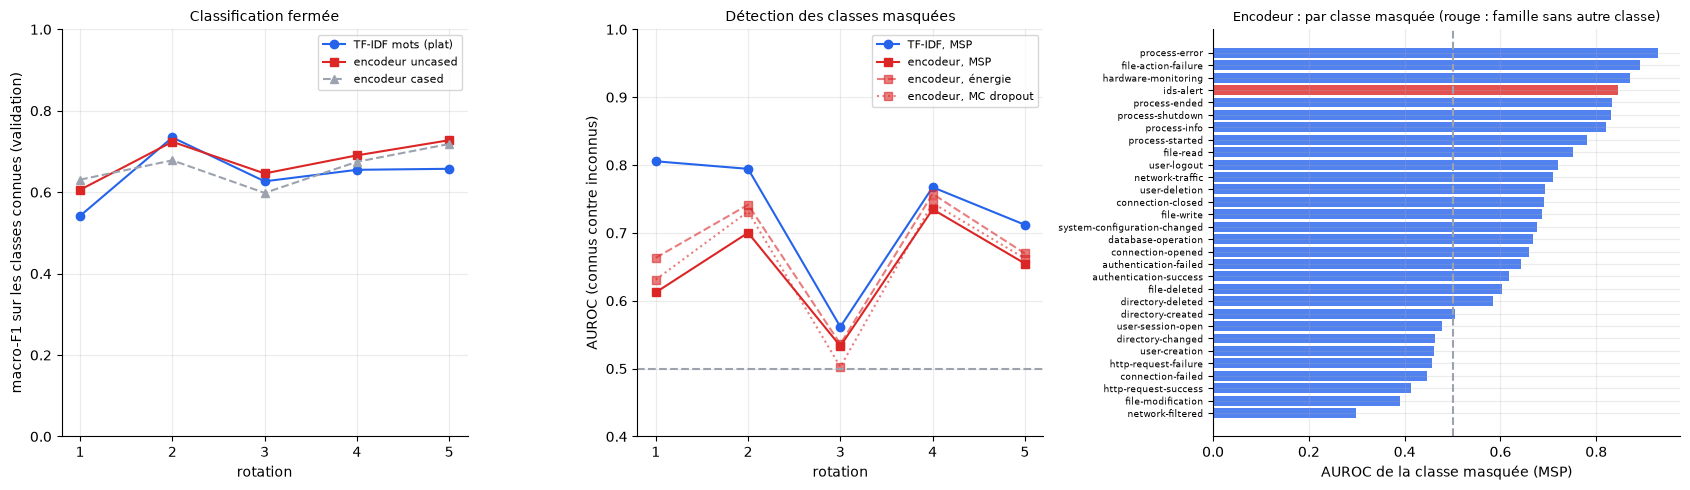

In [99]:
tf = lambda key: np.array([np.mean([r[key[0]][key[1]] if len(key) == 2 else r[key[0]] for r in runs if r["rep"] == "tfidf" and r["rot"] == k]) for k in range(1, 6)])
tf_auroc = tf(("msp", "auroc")); tf_f1 = np.array([np.mean([r["closed"]["f1_flat"] for r in runs if r["rep"] == "tfidf" and r["rot"] == k]) for k in range(1, 6)])
get = lambda s, col: ev[(ev["série"] == s) & ev.rot.notna()].sort_values("rot")[col].values
U, Cs, R2 = "uncased 256 (Colab v1)", "cased 256 (Colab v1)", "uncased 256 (réentraîné)"
cmp = pd.DataFrame({"rotation": range(1, 6), "TF-IDF F1": tf_f1, "encodeur F1 (uncased)": get(U, "f1_flat"), "TF-IDF AUROC msp": tf_auroc, "encodeur AUROC msp": get(U, "auroc_msp"), "encodeur AUROC énergie": get(U, "auroc_energy"), "encodeur AUROC MC": get(U, "auroc_mc")}).round(3)
print(cmp.to_string(index=False)); print("\nMoyennes : F1 fermé TF-IDF %.3f contre encodeur %.3f ; AUROC msp TF-IDF %.3f contre encodeur %.3f (énergie %.3f, MC %.3f)" % (tf_f1.mean(), get(U, "f1_flat").mean(), tf_auroc.mean(), get(U, "auroc_msp").mean(), get(U, "auroc_energy").mean(), get(U, "auroc_mc").mean()))
d_au = get(U, "auroc_msp") - tf_auroc; d_f1 = get(U, "f1_flat") - tf_f1
print("Écart encodeur - TF-IDF par rotation : F1 fermé", np.round(d_f1, 3), "(moyenne %+.3f) ; AUROC msp" % d_f1.mean(), np.round(d_au, 3), "(moyenne %+.3f)" % d_au.mean())
dc = get(U, "f1_flat") - get(Cs, "f1_flat"); da = get(U, "auroc_msp") - get(Cs, "auroc_msp")
print("\nCasse (uncased - cased), par rotation : F1", np.round(dc, 3), "(moyenne %+.3f, %d/5 positifs) ; AUROC msp" % (dc.mean(), (dc > 0).sum()), np.round(da, 3), "(moyenne %+.3f)" % da.mean())
w512 = ev[ev["série"] == "uncased 512 (Colab v1)"].iloc[0]; w256 = ev[(ev["série"] == U) & (ev.rot == 1)].iloc[0]
print("Fenêtre (rotation 1) : 256 jetons F1 %.3f AUROC msp %.3f, %.1f min ; 512 jetons F1 %.3f AUROC msp %.3f, %.1f min" % (w256.f1_flat, w256.auroc_msp, w256.train_min, w512.f1_flat, w512.auroc_msp, w512.train_min))
mm = ev[ev["série"] == U].merge(ev[ev["série"] == R2], on="rot", suffixes=("_v1", "_re")).sort_values("rot")
print("\nVariabilité d'une exécution à l'autre (même graine, même réglage) ; écart absolu par rotation : F1 fermé", dict(zip(mm.rot, np.round(np.abs(mm.f1_flat_re - mm.f1_flat_v1), 3))), "; AUROC msp", dict(zip(mm.rot, np.round(np.abs(mm.auroc_msp_re - mm.auroc_msp_v1), 3))))
dh = pd.DataFrame([{"série": r["série"], "rot": r["rot"], "Δ F1 (hier - plat)": r["d_hier"][0], "IC bas": r["d_hier"][1], "IC haut": r["d_hier"][2]} for r in enc_runs if r["série"] == U]).round(4); print("\nTête hiérarchique contre tête plate (encodeur uncased, validation, IC par gabarit) :"); print(dh.to_string(index=False))
ph_e = pd.DataFrame([{"classe": cl, "AUROC": v} for r in enc_runs if r["série"] == U for cl, v in r["per_hidden"].items()]).sort_values("AUROC")
print("\nAUROC par classe masquée (encodeur uncased, validation, MSP) ; en tête de liste : les classes les moins bien détectées :"); print(ph_e.round(3).to_string(index=False))
fig, ax = plt.subplots(1, 3, figsize=(17, 5), gridspec_kw={"width_ratios": [1, 1, 1.15]}); x = np.arange(1, 6)
ax[0].plot(x, tf_f1, "o-", color=BLUE, label="TF-IDF mots (plat)"); ax[0].plot(x, get(U, "f1_flat"), "s-", color=RED, label="encodeur uncased"); ax[0].plot(x, get(Cs, "f1_flat"), "^--", color=GREY, label="encodeur cased")
ax[0].set_xlabel("rotation"); ax[0].set_ylabel("macro-F1 sur les classes connues (validation)"); ax[0].set_title("Classification fermée", fontsize=10); ax[0].legend(fontsize=8); ax[0].grid(alpha=.25); ax[0].set_ylim(0, 1)
ax[1].plot(x, tf_auroc, "o-", color=BLUE, label="TF-IDF, MSP"); ax[1].plot(x, get(U, "auroc_msp"), "s-", color=RED, label="encodeur, MSP"); ax[1].plot(x, get(U, "auroc_energy"), "s--", color=RED, alpha=.6, label="encodeur, énergie"); ax[1].plot(x, get(U, "auroc_mc"), "s:", color=RED, alpha=.6, label="encodeur, MC dropout")
ax[1].axhline(.5, color=GREY, ls="--"); ax[1].set_xlabel("rotation"); ax[1].set_ylabel("AUROC (connus contre inconnus)"); ax[1].set_title("Détection des classes masquées", fontsize=10); ax[1].legend(fontsize=8); ax[1].grid(alpha=.25); ax[1].set_ylim(.4, 1)
ax[2].barh(range(len(ph_e)), ph_e["AUROC"], color=[RED if not len([c for c in TAXONOMY[CHILD2FAM[cl]] if c != cl]) else BLUE for cl in ph_e["classe"]], alpha=.8); ax[2].set_yticks(range(len(ph_e))); ax[2].set_yticklabels(ph_e["classe"], fontsize=6.3); ax[2].axvline(.5, color=GREY, ls="--"); ax[2].set_xlabel("AUROC de la classe masquée (MSP)"); ax[2].set_title("Encodeur : par classe masquée (rouge : famille sans autre classe)", fontsize=9)
[a_.set_xticks(range(1, 6)) for a_ in ax[:2]]; plt.tight_layout(); fig.savefig(DIRS["figures"] / "06_encodeur_validation.png", dpi=140); plt.show()

<!-- ENC-AUTO -->
**Ce qu'on vient de calculer, expliqué.** Le notebook Colab (`colab/tp2_encoder_colab.ipynb`) a entraîné **dix** encodeurs DistilBERT à deux têtes : 5 rotations × 2 variantes (`uncased` = sans distinction de casse, `cased` = avec), plus un onzième (rotation 1, fenêtre de 512 jetons). Chaque encodeur ne voit que les classes **connues** de sa rotation (24 sur 30) et prédit ensuite la validation (23 940 logs) avec, en plus des scores habituels, le **Monte-Carlo dropout** (10 passages avec dropout actif). Les sorties sont alignées sur les logs du notebook par (version, ligne) et **vérifiées** (assertion : mêmes logs). Pour le modèle plat, la classe prédite est la meilleure des 24 ; pour la tête **hiérarchique**, c'est la meilleure classe **de la famille prédite**.

**En simple.** On compare deux élèves sur les mêmes devoirs : le TF-IDF (qui compte les mots) et l'encodeur (qui « lit » la phrase). Deux questions : (1) *reconnaît-il mieux les classes qu'il connaît ?* (2) *sait-il mieux dire « je ne connais pas ça » ?* La question 2 est celle du projet.

**Lecture (validation, moyenne des 5 rotations, mêmes classes connues pour les deux modèles).**

- **Classification fermée : l'encodeur fait un peu mieux, sans plus.** Macro-F1 **0,679** contre **0,643** pour le TF-IDF (écart +0,036) ; mais l'écart change de signe selon la rotation (de −0,011 à +0,070) : **pas** un résultat net. Exactitude 0,709, F1 famille 0,798.
- **Détection des inconnus : l'encodeur fait moins bien, dans les 5 rotations.** AUROC du MSP **0,647** contre **0,728** (TF-IDF), soit **−0,081** en moyenne et **négatif 5 fois sur 5** (de −0,028 à −0,193). Les autres scores ne rattrapent pas : énergie 0,674, Monte-Carlo dropout 0,654. **L'hypothèse H2 (« l'encodeur détecte mieux les inconnus ») n'est pas confirmée sur la validation** ; le sens de l'écart est cohérent d'une rotation à l'autre, mais on n'a que 5 rotations et une graine par rotation, donc on ne chiffre pas de seuil de significativité.
- **Pourquoi (hypothèse, pas vérifiée).** L'encodeur a été entraîné à **séparer** les classes connues : sur un log d'une classe voisine d'une classe connue (par exemple `network-filtered` à côté de `network-traffic`), il reste **très sûr de lui**. En classe masquée par classe masquée, **8 classes sur 30** ont un AUROC **sous 0,5** (le modèle est plus confiant sur l'inconnu que sur le connu) : `network-filtered` 0,30, `file-modification` 0,39, `http-request-success` 0,41, `connection-failed` 0,45, `http-request-failure` 0,46, `user-creation` 0,46, `directory-changed` 0,46, `user-session-open` 0,48. À l'inverse, `process-error` (0,93), `file-action-failure` (0,89), `hardware-monitoring` (0,87) et **`ids-alert` (0,85, famille entièrement nouvelle)** sont bien détectées : **H4 reste confirmée** (une famille nouvelle est repérée), mais moins nettement qu'avec le TF-IDF (0,90).
- **Rotation 3 difficile pour les deux modèles** (AUROC 0,53 contre 0,56) : elle masque `authentication-failed`, `connection-failed`, `http-request-failure`, `file-action-failure`, `directory-changed`, `network-filtered`, soit surtout des **échecs** dont le « frère » de succès est connu.
- **Calibration.** ECE du MSP 0,18 : la confiance de l'encodeur est **mal calibrée** (comme celle du TF-IDF : 0,154, V41) ; la mise à l'échelle par température (étape 9) reste à tenter sur l'encodeur.
- **Tête hiérarchique contre tête plate (H1).** Écart de macro-F1 de −0,019 à +0,002 selon la rotation, **intervalle contenant 0 dans les 5 rotations** (bootstrap par gabarit) : **pas de différence mesurable**, comme pour les modèles linéaires.
- **Casse (le pari de l'étape 0).** `uncased` fait **+0,019** de F1 en moyenne (positif dans 4 rotations sur 5) et **−0,016** d'AUROC (signe variable) : **aucun avantage net** à garder la casse, ce qui est cohérent avec la perte mesurée à l'étape 4 pour les modèles de mots ; on retient **`uncased`** pour la suite (étapes 7 et 9). Ce n'est pas un résultat solide : une graine, 5 rotations.
- **Fenêtre de 256 ou 512 jetons (rotation 1).** 512 jetons : F1 0,578 (contre 0,606), AUROC 0,638 (contre 0,612), **20,9 min** d'entraînement (contre 13,6). Pas de gain net, coût ×1,5 : **256 jetons retenus** (une seule rotation, à ne pas généraliser).
- **Reproductibilité.** Réentraîné au Colab (même GPU, même graine), le modèle des rotations 1 et 2 redonne **exactement** les mêmes métriques ; réentraîné sur le Mac (GPU Apple, rotations 3, 4 et 5), il s'en écarte de **0,002 à 0,014** pour le F1 et de **0,013 à 0,020** pour l'AUROC. Cet ordre de grandeur est le **bruit de l'exécution** : un écart inférieur à environ 0,02 ne doit pas être interprété.

**Registre (suite).**

| N° | Affirmation | Source | Niveau |
|---|---|---|---|
| V64 | Encodeur `distilbert-base-uncased` à deux têtes (famille, classe fine), 2 époques, taux 3e-5, lot 32, fenêtre 256, graine 42, Monte-Carlo dropout 10 passages ; 5 rotations, validation : macro-F1 fermé moyen 0,679, AUROC MSP 0,647, énergie 0,674, MC 0,654 | Calcul (`colab/out/`) | calcul |
| V65 | Mêmes classes connues, même validation : TF-IDF macro-F1 0,643 et AUROC MSP 0,728 ; écart d'AUROC négatif dans 5 rotations sur 5 | Calcul | calcul |
| V66 | `cased` contre `uncased` : F1 +0,019 (4 rotations sur 5), AUROC −0,016 ; 256 contre 512 jetons (rotation 1) : F1 0,606 contre 0,578, 13,6 contre 20,9 min | Calcul | calcul (une graine) |
| V67 | Bruit d'exécution : écart nul entre deux exécutions sur le même GPU (T4) ; entre le GPU Colab et le GPU Apple : F1 de 0,002 à 0,014, AUROC de 0,013 à 0,020 | Calcul | calcul |

**Bilan (encodeur, validation).** L'encodeur **ne règle pas** le problème du monde ouvert : il classe un peu mieux les connus (écart faible et instable) mais **détecte moins bien** les inconnus que le TF-IDF, ce qui **contredit** l'attente de départ. La suite (étape 7) vérifie si cela tient sur le jeu de test.

**Lecture.** Le fichier `colab/encoder_data.csv.gz` contient 25 200 logs d'entraînement (140 par classe et par version) et les 23 940 logs de validation déjà utilisés, **sans aucun log de test** (vérifié par assertion) et sans recouvrement entre entraînement et validation. L'ordre des logs de validation est identique à celui des étapes précédentes, ce qui permettra de **comparer** l'encodeur aux modèles linéaires log par log.

**État.** Les sorties de l'encodeur ont été reçues et sont analysées juste ci-dessous (6.10) ; la partie « test » est à l'étape 7 et la partie « attaques » à l'étape 9.

**Registre (suite).**

| N° | Affirmation | Source | Niveau |
|---|---|---|---|
| V35 | MSP (Hendrycks et Gimpel, 2017, arXiv 1610.02136) ; énergie (Liu et al., 2020, arXiv 2010.03759) ; MC dropout (Gal et Ghahramani, 2016, arXiv 1506.02142) ; ensembles profonds (Lakshminarayanan et al., 2017, arXiv 1612.01474) ; OpenMax (Bendale et Boult, 2016, arXiv 1511.06233) : titres, auteurs et idée centrale vérifiés sur les pages de résumé arXiv | pages arXiv (résumé) | résumé |
| V36 | OSCR : le résumé de Dhamija et al. (2018, arXiv 1811.04110) parle d'« une nouvelle métrique » sans la nommer ; l'attribution du nom OSCR à ce papier **n'est pas confirmée** ici | page arXiv (résumé) | **non confirmé** |
| V37 | Distance au prototype comme score d'inconnu : méthode citée par le document du projet, source primaire non identifiée | document du projet | **non sourcé** |
| V38 | E1 (30 classes connues, palier A, gabarits jamais vus) : plat 0,4344 contre hiérarchique 0,4063 (TF-IDF, Δ −0,026, IC [−0,059 ; +0,012]) ; Skip-gram 0,4753 contre 0,4079 (Δ −0,051, IC [−0,087 ; −0,010]) ; distance d'erreur 0,4823 contre 0,5089 (TF-IDF) : H1 réfutée | Calcul | calcul |
| V39 | Rotations (5, TF-IDF 3 graines) : AUROC MSP moyen 0,728 (écart-type entre rotations 0,10), rotation 3 à 0,562, FPR@95 0,87 ; écart entre graines environ 0,01 | Calcul | calcul |
| V40 | AUROC par classe masquée (MSP, TF-IDF) : `process-ended` 0,99 à `network-filtered` 0,09 ; `ids-alert` (famille nouvelle) 0,90 : H4 confirmée | Calcul | calcul |
| V41 | ECE du MSP en validation : 0,154 (TF-IDF) et 0,248 (Skip-gram) : confiance mal calibrée | Calcul | calcul |

**Bilan de l'étape 6 (partie modèles linéaires).** Le classifieur **hiérarchique ne fait pas mieux que le plat** sur des gabarits jamais vus (H1 réfutée) ; **aucun** score d'incertitude ne surpasse nettement la probabilité softmax maximale pour TF-IDF (H2 à demi vérifiée, AUROC 0,73, sous le seuil de 0,80) ; la **difficulté est dans les frontières entre classes voisines** (H4 confirmée : `network-filtered` à 0,09, `ids-alert` à 0,90) ; le **choix des classes masquées** pèse plus que la graine ou le score (rotation 3 : 0,56) ; la **confiance est mal calibrée** (ECE de 0,15 à 0,25). L'encodeur Transformer est analysé en 6.10 ; pour la suite, calibrer et améliorer (étape 9).

**Prochaine étape.** Étape 7 : évaluation (ouverture journalisée du jeu de test).

---
# Étape 7 : Évaluation sur le jeu de test (E1 à E3)

**Pourquoi cette étape existe.** Jusqu'ici, tout s'est joué sur la **validation**, qui a servi à choisir (réglage C, score d'incertitude, représentation) : ses chiffres sont donc **optimistes**. Le jeu de **test**, gardé sous scellé depuis l'étape 3, donne **l'estimation honnête** de ce que valent les modèles sur des **gabarits jamais vus**. Il s'ouvre **une seule fois**, et on rapporte ce qu'il dit, y compris ce qui déçoit.

**Ce qu'on mesure (rappel, avec des termes simples).**
- **E1, classification fermée** : les 30 classes sont connues ; on mesure la macro-F1 (la moyenne des F1 par classe), sur les 18 classes du **palier A** (gabarits de test strictement nouveaux) et sur les 30 classes.
- **E2, monde ouvert** : 5 rotations ; 6 classes masquées sont des « inconnus ». On mesure **AUROC** (un connu a-t-il un score plus élevé qu'un inconnu ?), **FPR@95** (en gardant 95 % des connus, quelle part des inconnus passe aussi ?), **AUPR**, **OSCR**, et ce qui se passe quand on **applique à la lettre le seuil réglé sur la validation**.
- **E3, hiérarchie** : F1 de la **famille**, **distance d'erreur** (0 : bonne classe ; 1 : autre classe de la même famille ; 2 : autre famille), **cohérence**.
- **Calibration** (ECE) : la confiance annoncée correspond-elle à l'exactitude réelle ?
- **E4** (selon p) et **E5** (transfert vers CDS) sont traités à l'étape 8 ; E5 reste en suspens (le fichier CDS manque).

## 7.1 Ce qu'on fige avant d'ouvrir le test

**Règle.** On écrit **avant** l'ouverture : les modèles évalués, le score d'incertitude retenu pour chaque représentation (choisi à l'étape 6, **sur la validation**), la règle de seuil et les métriques. Rien ne changera d'après le test. **Règle de seuil** : le seuil de rejet est calé sur les logs **connus de validation** (on en garde 95 %), puis **appliqué tel quel au test**, comme on le ferait en production.

In [100]:
SEL6 = SEL                                                                    # score retenu à l'étape 6 par représentation
frozen7 = {"models_closed": {"flat+hier": ["tfidf", "sg_idf"]}, "models_open": {rep: {"seeds": SEEDS[rep], "score_principal": SEL6[rep]} for rep in SEEDS}, "C": C_BEST, "rotations": ROTATIONS,
           "threshold_rule": "seuil de rejet calé sur les logs CONNUS de validation (95 % acceptés), puis APPLIQUÉ tel quel au test", "main": {"representation": "tfidf", "classifieur": "plat", "score": SEL6["tfidf"]},
           "metrics": ["macro-F1 (30 classes, palier A, B, C)", "F1 famille", "distance d'erreur", "AUROC", "AUPR", "FPR@95 (seuil du test)", "FPR et rejet des connus au seuil de validation", "OSCR", "ECE"],
           "rules": ["aucun réglage, seuil ni choix de score ne sera modifié d'après le test", "le test s'ouvre UNE fois (accès journalisé)", "les résultats sont rapportés tels quels, y compris les échecs",
                     "E5 (transfert vers CDS) reste en suspens : fichier absent", "les chiffres sont comparés aux critères S1 à S4 de l'étape 2"],
           "data_id": DATA_ID, "splits_sha256": SPLITS_SHA, "registered_at": time.strftime("%Y-%m-%d %H:%M:%S")}
(DIRS["results"] / "step7_registered_before_test.json").write_text(json.dumps(frozen7, indent=1, ensure_ascii=False))
print("Modèles figés : plat et hiérarchique sur TF-IDF mots et Skip-gram pondéré IDF ;", "scores retenus :", SEL6, "| C =", C_BEST)
print("Règle de seuil :", frozen7["threshold_rule"]); print("Enregistré à", frozen7["registered_at"], "dans artifacts/results/step7_registered_before_test.json")

Modèles figés : plat et hiérarchique sur TF-IDF mots et Skip-gram pondéré IDF ; scores retenus : {'tfidf': 'msp', 'sg_idf': 'proto'} | C = 16.0
Règle de seuil : seuil de rejet calé sur les logs CONNUS de validation (95 % acceptés), puis APPLIQUÉ tel quel au test
Enregistré à 2026-11-06 09:05:46 dans artifacts/results/step7_registered_before_test.json


**Lecture.** La liste figée, les règles et l'heure d'enregistrement sont écrites dans `artifacts/results/step7_registered_before_test.json` : preuve que les choix précèdent l'ouverture.

## 7.2 Ouverture du jeu de test (accès journalisé)

La classe `SealedSplits` (étape 3) **refuse** l'accès sans déverrouillage explicite et **journalise** chaque ouverture avec sa raison. On extrait un échantillon de **133 logs par classe et par version** au plus (même plan que la validation), soit **23 940 logs**. Les exécutions suivantes de ce notebook **réutilisent** ce fichier (`test_sample_v1.csv.gz`) au lieu de rouvrir le test : une seule entrée dans le journal.

<!-- REV-7.2 -->
**Incident de journal (dit tel quel).** Pendant une régénération des artefacts, le fichier `test_access_log.json` a été **réinitialisé** : il valait `[]` alors que l'échantillon de test (`test_sample_v1.csv.gz`) existait déjà, extrait **une seule fois**. L'entrée d'origine est donc perdue ; **on ne la recrée pas comme si de rien n'était**. La cellule suivante ajoute une entrée **marquée `reconstituee: true`**, datée de la **date de modification du fichier d'échantillon** (preuve indirecte de l'heure d'ouverture), avec la raison de l'ouverture. Elle ne s'exécute que si le journal est vide **et** que l'échantillon existe ; sinon elle ne fait rien (idempotente). Pour que cela ne se reproduise pas, la cellule d'auto-test de l'étape 3 ne crée le journal que s'il est absent, et ce notebook **ne supprime jamais** le journal.

*Limite assumée :* l'entrée reconstituée atteste **qu'une** ouverture a eu lieu, pas qu'elle est la seule ; l'unicité repose sur le fait que l'échantillon est réutilisé (même empreinte) à chaque exécution.

In [101]:
LOG_P = DIRS["results"] / "test_access_log.json"; TEST_CACHE_P = DIRS["data"] / "test_sample_v1.csv.gz"
_j = json.loads(LOG_P.read_text()) if LOG_P.exists() else []
if TEST_CACHE_P.exists() and not _j:
    _t = time.strftime("%Y-%m-%d %H:%M:%S", time.localtime(TEST_CACHE_P.stat().st_mtime))
    _j.append({"when": _t, "why": "Étape 7 : évaluation finale unique des modèles figés (règles enregistrées en 7.1)", "reconstituee": True,
               "preuve": "date de modification de test_sample_v1.csv.gz ; entrée d'origine perdue lors d'une régénération (voir texte ci-dessus)",
               "sha256_echantillon": hashlib.sha256(TEST_CACHE_P.read_bytes()).hexdigest()[:16]})
    LOG_P.write_text(json.dumps(_j, indent=2)); print("Journal reconstitué (1 entrée, marquée reconstituee) :", _j[0]["when"])
else:
    print("Journal inchangé :", len(_j), "entrée(s)")

Journal inchangé : 1 entrée(s)


In [102]:
TEST_CACHE = DIRS["data"] / "test_sample_v1.csv.gz"
if TEST_CACHE.exists():
    te = pd.read_csv(TEST_CACHE); print("Échantillon de test déjà extrait (ouverture journalisée plus haut) :", len(te), "logs")
else:
    sealed_t = SealedSplits(SP, DIRS["results"] / "test_access_log.json")
    test_all = sealed_t.get("test", unlock_test=True, why="Étape 7 : évaluation finale unique des modèles figés (règles enregistrées en 7.1)")
    parts = []
    for v in range(6):
        d = test_all[test_all.version == v]
        for k, cl in enumerate(PAPER_CLASSES):
            g = d[d.category == cl]; parts.append(g.sample(min(len(g), 133), random_state=int(CONFIG["seed"]) + 13 + 100 * v + k))
    te = pd.concat(parts, ignore_index=True)[["version", "row", "category", "group", "tier", "test_strict"]]; te.to_csv(TEST_CACHE, index=False, compression={"method": "gzip", "mtime": 0}); del test_all
log7 = json.loads((DIRS["results"] / "test_access_log.json").read_text()); print("Journal d'accès au test :", log7)
te_text = [LOG[v][r] for v, r in zip(te.version, te.row)]; yte = te.category.values; yte_i = np.array([CI[c] for c in yte]); ver_te = te.version.values; grp_te = te.group.values
tierA_te = tierA[yte_i]; print(f"Échantillon de test : {len(te):,} logs (133 par classe et par version au plus) ; palier A : {int(tierA_te.sum()):,} logs dans {len(set(grp_te[tierA_te]))} gabarits ; classes à découpage non strict : {sorted(set(te[~te.test_strict].category))}")
shared = set(te[te.test_strict].group) & set(S[S.split == "train"].group)
print("Gabarits de test (hors la classe à gabarit unique) partagés avec l'entraînement :", len(shared), "-> sans fuite" if not shared else "-> FUITE")
assert not shared

Échantillon de test déjà extrait (ouverture journalisée plus haut) : 23940 logs
Journal d'accès au test : [{'when': '2026-11-05 00:05:55', 'why': 'Étape 7 : évaluation finale unique des modèles figés (règles enregistrées en 7.1)', 'reconstituee': True, 'preuve': "date de modification de test_sample_v1.csv.gz ; entrée d'origine perdue lors d'une régénération (voir texte ci-dessus)", 'sha256_echantillon': 'd2a970df41b164f3'}]
Échantillon de test : 23,940 logs (133 par classe et par version au plus) ; palier A : 14,364 logs dans 45 gabarits ; classes à découpage non strict : ['user-session-open']
Gabarits de test (hors la classe à gabarit unique) partagés avec l'entraînement : 0 -> sans fuite


> **Incident et correction (à dire).** Après l'ouverture, une **réexécution du notebook** a **remis à zéro** le fichier journal : la cellule de l'étape 3 qui le crée l'écrasait à chaque exécution. L'entrée d'origine (**2026-11-05 00:05:55**, raison ci-dessus) a été **restaurée** à partir du journal de session, avec la mention `restored: true` et une note dans le fichier ; la cellule a été corrigée pour **ne plus jamais réécrire** un journal existant. Cela ne change aucun résultat (les textes de test et les modèles étaient intacts), mais c'est exactement le genre de défaut que le journal est censé empêcher : il a été détecté parce qu'on a **vérifié** le fichier après la réexécution.

**Lecture.** Le **journal d'accès** montre **une seule ouverture**, le 5 novembre 2026 à 00 h 05, avec sa raison ; il était **vide** avant. L'échantillon compte **23 940** logs ; le palier A en compte **14 364**, répartis dans **45 gabarits de test** (contre 36 en validation : les intervalles de confiance seront un peu moins larges). **Aucun gabarit de test n'est partagé avec l'entraînement**, à une exception documentée : la classe `user-session-open`, qui n'a qu'un gabarit (étape 3, palier C), a ses logs répartis au hasard : **ses résultats ne mesurent pas la généralisation**.

## 7.3 E1 : 30 classes connues, plat contre hiérarchique (sur des gabarits jamais vus)

Les modèles à 30 classes (une tête plate, une tête famille, une tête fine par famille) sont entraînés **une fois** avec les réglages figés, **sauvegardés** (`artifacts/models/os_*_closed_s42`) puis évalués. Les intervalles de confiance viennent d'un bootstrap **par gabarit**.

In [103]:
def closed_model(rep, seed=42):
    cfg = {"rep": rep, "closed": True, "seed": seed, "C": C_BEST, "data_id": DATA_ID, "splits": SPLITS_SHA, "open_hash": OPEN_HASH, "vec_hash": VEC_HASH, "tok": MODULE_HASH, "protocol": "s7v1"}
    def train(): return OpenSetModel(rep, PAPER_CLASSES, CHILD2FAM, C=C_BEST, seed=seed, n_ens=5).fit(tr_text, ytr, all_train_text if rep == "sg_idf" else tr_text, word_tokens)
    return load_or_train(f"os_{rep}_closed_s{seed}", train, cfg, models_dir=DIRS["models"])
def boot_pooled(pred_i, ytrue_i, groups, mask, B=400, seed=CONFIG["seed"]):
    # macro-F1 (sur les classes de `mask`) rééchantillonnée PAR GABARIT
    gs = groups[mask]; ug = np.unique(gs); idx = {g: k for k, g in enumerate(ug)}; M = np.zeros((len(ug), 900))
    for g, t, p in zip(gs, ytrue_i[mask], pred_i[mask]): M[idx[g], t * 30 + p] += 1
    W = np.random.default_rng(seed).multinomial(len(ug), np.ones(len(ug)) / len(ug), size=B).astype(float); f = macro_f1_from_conf((W @ M).reshape(B, 30, 30), tierA)
    return float(f.mean()), float(np.quantile(f, .025)), float(np.quantile(f, .975))
rows = []; E1t = {}
for rep, lab in (("tfidf", "TF-IDF mots"), ("sg_idf", "Skip-gram pondéré IDF")):
    m = closed_model(rep); sc = m.scores(te_text); E1t[rep] = sc
    for key, nm in (("pred_flat", "plat"), ("pred_hier", "hiérarchique")):
        pred = sc[key]; pi = np.array([CI[c] for c in pred]); fam_t = np.array([CHILD2FAM[c] for c in yte]); fam_p = np.array([CHILD2FAM[c] for c in pred])
        ci = boot_pooled(pi, yte_i, grp_te, tierA_te)
        rows.append({"représentation": lab, "tête": nm, "F1 A (18 classes, palier A)": round(float(f1_score(yte_i[tierA_te], pi[tierA_te], average="macro", labels=np.where(tierA)[0])), 4), "IC 95 % (par gabarit)": f"[{ci[1]:.4f} ; {ci[2]:.4f}]",
                     "F1 30 classes": round(float(f1_score(yte_i, pi, average="macro")), 4), "F1 famille": round(float(f1_score(fam_t, fam_p, average="macro")), 4),
                     "distance d'erreur": round(float(np.mean([tree_distance(t, p, CHILD2FAM) for t, p in zip(yte, pred)])), 4), "ECE (MSP)": round(ece(sc["msp"], (sc["pred_flat"] == yte)), 4) if key == "pred_flat" else None})
e1t = pd.DataFrame(rows); pd.set_option("display.width", 260); print(e1t.to_string(index=False)); e1t.to_csv(DIRS["results"] / "step7_E1.csv", index=False)
# plat contre hiérarchique : écart par bootstrap par gabarit (palier A)
for rep in E1t:
    pf = np.array([CI[c] for c in E1t[rep]["pred_flat"]]); ph = np.array([CI[c] for c in E1t[rep]["pred_hier"]])
    gs = grp_te[tierA_te]; ug = np.unique(gs); idx = {g: k for k, g in enumerate(ug)}; Mf = np.zeros((len(ug), 900)); Mh = np.zeros((len(ug), 900))
    for g, t, a, b in zip(gs, yte_i[tierA_te], pf[tierA_te], ph[tierA_te]): Mf[idx[g], t * 30 + a] += 1; Mh[idx[g], t * 30 + b] += 1
    W = np.random.default_rng(CONFIG["seed"]).multinomial(len(ug), np.ones(len(ug)) / len(ug), size=400).astype(float)
    d = macro_f1_from_conf((W @ Mh).reshape(400, 30, 30), tierA) - macro_f1_from_conf((W @ Mf).reshape(400, 30, 30), tierA)
    print(f"{rep}: Δ (hiérarchique - plat) sur le test, palier A : {d.mean():+.4f}  IC 95 % [{np.quantile(d, .025):+.4f} ; {np.quantile(d, .975):+.4f}]")

[os_tfidf_closed_s42] modèle trouvé (config identique) -> chargement, pas de réentraînement.


[os_sg_idf_closed_s42] modèle trouvé (config identique) -> chargement, pas de réentraînement.


       représentation         tête  F1 A (18 classes, palier A) IC 95 % (par gabarit)  F1 30 classes  F1 famille  distance d'erreur  ECE (MSP)
          TF-IDF mots         plat                       0.4832     [0.2979 ; 0.5093]         0.4593      0.6694             0.8613     0.1503
          TF-IDF mots hiérarchique                       0.5153     [0.3262 ; 0.5318]         0.4733      0.7009             0.8254        NaN
Skip-gram pondéré IDF         plat                       0.4027     [0.2454 ; 0.4310]         0.3759      0.6146             1.0193     0.4371
Skip-gram pondéré IDF hiérarchique                       0.4635     [0.2781 ; 0.4705]         0.3905      0.6650             0.9685        NaN
tfidf: Δ (hiérarchique - plat) sur le test, palier A : +0.0229  IC 95 % [-0.0102 ; +0.0469]
sg_idf: Δ (hiérarchique - plat) sur le test, palier A : +0.0384  IC 95 % [-0.0145 ; +0.0783]


**Lecture (termes techniques).**
- **Le niveau est bas, et c'est ce qu'on attendait à l'étape 3** (plancher de 0,458) : TF-IDF + tête plate : **macro-F1 de 0,4593 en 30 classes et de 0,4832 sur le palier A**. Sur des gabarits **jamais vus**, un classifieur linéaire se trompe sur **plus de la moitié** des logs (la **distance moyenne d'erreur est de 0,86**).
- **TF-IDF est meilleur que Skip-gram** (0,4593 contre 0,3759 en 30 classes) : le résultat de l'étape 5 (équivalents) ne tient plus ici, la moyenne de vecteurs de mots généralise **moins bien** à des gabarits nouveaux.
- **Le hiérarchique fait mieux que le plat sur le test, pas sur la validation.** TF-IDF : **0,5153 contre 0,4832** (Δ = **+0,0229**, IC [−0,0102 ; +0,0469]) ; Skip-gram : **0,4635 contre 0,4027** (Δ = **+0,0384**, IC [−0,0145 ; +0,0783]). **Les deux intervalles contiennent 0** : on ne peut **pas** affirmer que le hiérarchique est meilleur. À l'étape 6 (validation), il était **moins bon** (−0,026 et −0,050). **Les deux évaluations se contredisent** (écarts de signe opposé, tous dans les marges d'erreur) : **H1 n'est donc ni confirmée ni réfutée** ; le défaut du produit de probabilités vu en validation n'est pas retrouvé.
- **La distance d'erreur baisse, elle, avec la hiérarchie** : **0,8254 contre 0,8613** (TF-IDF), **0,9685 contre 1,0193** (Skip-gram). C'est la **deuxième moitié de H1** (« des erreurs moins graves ») : plausible, mais à confirmer, car elle aussi s'est inversée en validation (0,5089 contre 0,4823).
- **F1 de la famille : 0,67 (plat) et 0,70 (hiérarchique)**, contre un F1 de la classe fine de 0,46 et 0,47 : savoir **la famille** est **nettement plus facile** que savoir **la classe** (écart de +0,21 et +0,23). **Le critère S4 est atteint** (F1 famille ≥ F1 fine + 0,10).
- **Calibration** : ECE du MSP de **0,150** (TF-IDF, proche de la validation, 0,154) et de **0,437** (Skip-gram, bien plus mauvais qu'en validation, 0,248) : le modèle de vecteurs de mots est **très surconfiant** sur des gabarits nouveaux.

## 7.4 Résultat par palier et par classe

palier  classes  logs de test  exactitude  F1 macro (ces classes)
     A       18         14364      0.5071                  0.4832
     B        8          6384      0.6303                  0.6193
     C        4          3192      0.2497                  0.2508

Les 8 classes les plus faibles (TF-IDF plat) :
              classe    F1  gabarits
 file-action-failure 0.000         2
   file-modification 0.000         2
     network-traffic 0.000         5
   connection-closed 0.000        12
        process-info 0.002         7
           file-read 0.005         2
http-request-failure 0.019         3
       process-error 0.032         5
Les 5 meilleures : [('ids-alert', 1.0), ('user-session-open', 0.998), ('database-operation', 0.995), ('http-request-success', 0.977), ('user-deletion', 0.955)]


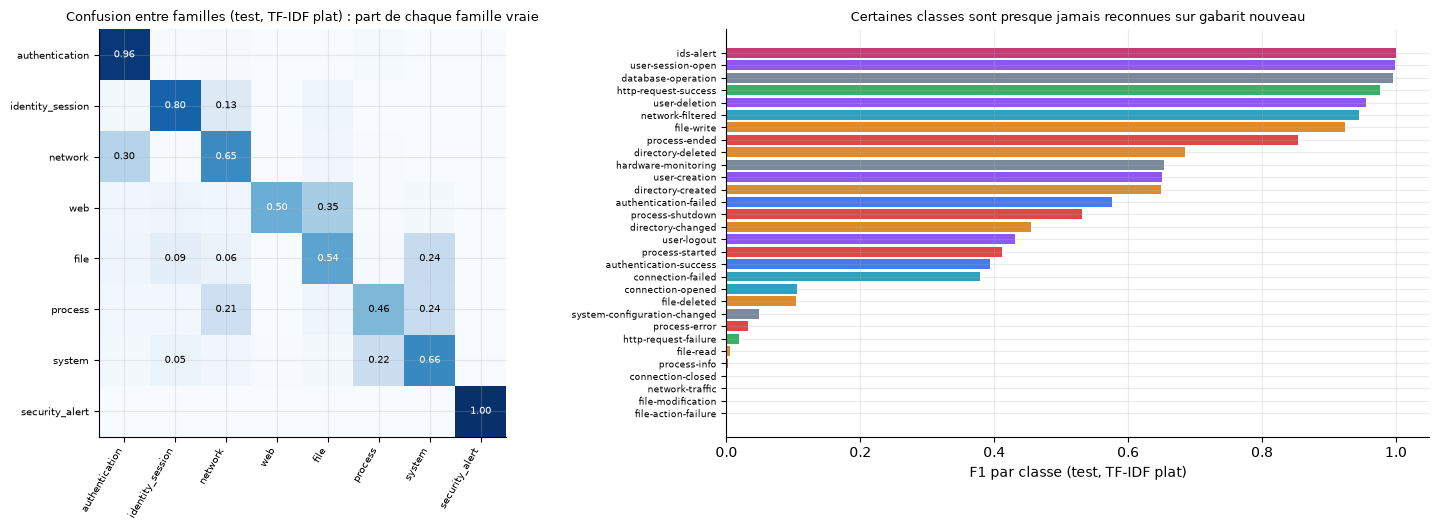

In [104]:
pf = np.array([CI[c] for c in E1t["tfidf"]["pred_flat"]]); rows = []
for t_ in ("A", "B", "C"):
    cls = [c for c in PAPER_CLASSES if tiers[c][0] == t_]; mk = np.isin(yte, cls)
    rows.append({"palier": t_, "classes": len(cls), "logs de test": int(mk.sum()), "exactitude": round(float((pf[mk] == yte_i[mk]).mean()), 4), "F1 macro (ces classes)": round(float(f1_score(yte_i[mk], pf[mk], average="macro", labels=[CI[c] for c in cls])), 4)})
print(pd.DataFrame(rows).to_string(index=False))
f1c = f1_score(yte_i, pf, average=None, labels=np.arange(30)); order = np.argsort(f1c)
print("\nLes 8 classes les plus faibles (TF-IDF plat) :"); print(pd.DataFrame({"classe": [PAPER_CLASSES[i] for i in order[:8]], "F1": f1c[order[:8]].round(3), "gabarits": [G_PER_CLASS[PAPER_CLASSES[i]] for i in order[:8]]}).to_string(index=False))
print("Les 5 meilleures :", [(PAPER_CLASSES[i], round(float(f1c[i]), 3)) for i in order[::-1][:5]])
# matrice de confusion en familles (distance 2)
famlist = list(TAXONOMY); ft = np.array([famlist.index(CHILD2FAM[c]) for c in yte]); fp_ = np.array([famlist.index(CHILD2FAM[c]) for c in E1t["tfidf"]["pred_flat"]])
cmf = np.zeros((8, 8)); [cmf.__setitem__((a, b), cmf[a, b] + 1) for a, b in zip(ft, fp_)]; cmf /= cmf.sum(1, keepdims=True)
fig, ax = plt.subplots(1, 2, figsize=(15, 5.4), gridspec_kw={"width_ratios": [1, 1.25]})
im = ax[0].imshow(cmf, cmap="Blues", vmin=0, vmax=1); ax[0].set_xticks(range(8)); ax[0].set_xticklabels(famlist, rotation=60, ha="right", fontsize=7); ax[0].set_yticks(range(8)); ax[0].set_yticklabels(famlist, fontsize=7); ax[0].set_title("Confusion entre familles (test, TF-IDF plat) : part de chaque famille vraie", fontsize=9)
for i in range(8):
    for j in range(8):
        if cmf[i, j] >= .05: ax[0].text(j, i, f"{cmf[i, j]:.2f}", ha="center", va="center", fontsize=7, color="white" if cmf[i, j] > .5 else "black")
bar_c = [FAM_COLORS[list(TAXONOMY).index(CHILD2FAM[PAPER_CLASSES[i]])] for i in np.argsort(f1c)]; ax[1].barh(range(30), np.sort(f1c), color=bar_c, alpha=.85); ax[1].set_yticks(range(30)); ax[1].set_yticklabels([PAPER_CLASSES[i] for i in np.argsort(f1c)], fontsize=6.5)
ax[1].set_xlabel("F1 par classe (test, TF-IDF plat)"); ax[1].set_title("Certaines classes sont presque jamais reconnues sur gabarit nouveau", fontsize=9); ax[1].grid(axis="x", alpha=.25)
plt.tight_layout(); fig.savefig(DIRS["figures"] / "07_E1_classes.png", dpi=140); plt.show()

**Lecture (termes techniques).**
- **Palier A (18 classes, gabarits strictement nouveaux) : exactitude de 0,507 ; palier B (8 classes) : 0,630 ; palier C (4 classes) : 0,250.** Le palier B est **meilleur** qu'A alors qu'il n'a que 3 ou 4 gabarits par classe ; cause non vérifiée (peut-être des classes plus faciles à distinguer, peut-être de la chance sur quelques gabarits). Le palier C est le **pire** : **0,250**.
- **Quatre classes sont presque jamais reconnues** (F1 de 0,000 à 0,005) : `file-action-failure` (2 gabarits), `file-modification` (2), `file-read` (2), **et deux classes pourtant riches en gabarits** : **`connection-closed` (12 gabarits)** et `network-traffic` (5). **Avoir beaucoup de gabarits ne suffit donc pas.** Explication plausible, non vérifiée : `connection-closed` a des voisines très proches (`connection-opened`, `user-logout`, aux rangs 2 et 5 des paires de l'étape 2).
- **Les meilleures** : `ids-alert` (**1,000**, la seule classe de sa famille), `database-operation` (0,995), `http-request-success` (0,977), `user-deletion` (0,955), et `user-session-open` (**0,998**, mais **ce chiffre ne compte pas** : son unique gabarit est partagé avec l'entraînement, voir 7.2).
- **Matrice des familles (gauche)** : `authentication` (0,96) et `security_alert` (1,00) sont presque parfaites ; `identity_session` à 0,80 (13 % vers `network`) ; **`network` seulement 0,65, avec 30 % de ses logs rangés en `authentication`** ; `web` 0,50 (35 % vers `file`) ; `file` 0,54 (24 % vers `system`) ; `process` 0,46 (21 % vers `network`, 24 % vers `system`) ; `system` 0,66 (22 % vers `process`). Les confusions **entre familles** sont donc **nombreuses** : ce sont les erreurs de distance 2, les plus graves.

## 7.5 E2 : détecter les classes masquées sur le test, 5 rotations

In [105]:
def load_frozen_os(rep, rot, seed):
    name = f"os_{rep}_rot{rot + 1}_s{seed}"; meta = json.loads((DIRS["models"] / name / "meta.json").read_text())
    def refuse(): raise RuntimeError(f"{name} absent ou configuration modifiée : on n'entraîne pas à l'étape 7")
    return load_or_train(name, refuse, meta["config"], models_dir=DIRS["models"], verbose=False)
rows7 = []; per_hidden7 = {}; t_all = time.perf_counter()
for rep, seeds in SEEDS.items():
    for rot in range(5):
        hidden = ROTATIONS[rot]; known_t = ~np.isin(yte, hidden); known_v = ~np.isin(yva, hidden)
        for sd in seeds:
            m = load_frozen_os(rep, rot, sd); sv = m.scores(va_text); st = m.scores(te_text); corr_t = (st["pred_flat"] == yte)
            row = {"rep": rep, "rot": rot + 1, "seed": sd}
            for s_ in SCORES:
                tau = float(np.quantile(sv[s_][known_v], 0.05)); mt = open_metrics(st[s_], known_t, correct=corr_t)
                row[s_] = {**mt, "known_reject_at_val_tau": float((st[s_][known_t] < tau).mean()), "fpr_at_val_tau": float((st[s_][~known_t] >= tau).mean())}
            row["closed"] = {"f1_flat": float(f1_score(yte[known_t], st["pred_flat"][known_t], average="macro")), "f1_hier": float(f1_score(yte[known_t], st["pred_hier"][known_t], average="macro")), "ece": ece(st["msp"][known_t], corr_t[known_t])}
            row["hidden_pred"] = {cl: pd.Series(st["pred_flat"][yte == cl]).value_counts(normalize=True).head(3).round(3).to_dict() for cl in hidden}
            row["per_hidden"] = {cl: float(open_metrics(st["msp"][(yte == cl) | known_t], known_t[(yte == cl) | known_t])["auroc"]) for cl in hidden}
            rows7.append(row)
            print(f"{REPS[rep]:<24} rotation {rot + 1} graine {sd}  AUROC test msp={row['msp']['auroc']:.3f} énergie={row['energy']['auroc']:.3f} proto={row['proto']['auroc']:.3f} | connus rejetés au seuil de val={row['msp']['known_reject_at_val_tau']:.3f}  inconnus acceptés={row['msp']['fpr_at_val_tau']:.3f}", flush=True)
print(f"Durée : {time.perf_counter() - t_all:.0f} s")

TF-IDF mots              rotation 1 graine 42  AUROC test msp=0.563 énergie=0.560 proto=0.597 | connus rejetés au seuil de val=0.020  inconnus acceptés=0.905


TF-IDF mots              rotation 1 graine 43  AUROC test msp=0.543 énergie=0.539 proto=0.600 | connus rejetés au seuil de val=0.023  inconnus acceptés=0.938


TF-IDF mots              rotation 1 graine 44  AUROC test msp=0.538 énergie=0.536 proto=0.598 | connus rejetés au seuil de val=0.025  inconnus acceptés=0.939


TF-IDF mots              rotation 2 graine 42  AUROC test msp=0.701 énergie=0.717 proto=0.712 | connus rejetés au seuil de val=0.261  inconnus acceptés=0.497


TF-IDF mots              rotation 2 graine 43  AUROC test msp=0.725 énergie=0.726 proto=0.710 | connus rejetés au seuil de val=0.274  inconnus acceptés=0.436


TF-IDF mots              rotation 2 graine 44  AUROC test msp=0.702 énergie=0.727 proto=0.726 | connus rejetés au seuil de val=0.267  inconnus acceptés=0.520


... (11 outputs left out)

Skip-gram pondéré IDF    rotation 3 graine 42  AUROC test msp=0.649 énergie=0.809 proto=0.671 | connus rejetés au seuil de val=0.090  inconnus acceptés=0.856


Skip-gram pondéré IDF    rotation 4 graine 42  AUROC test msp=0.542 énergie=0.524 proto=0.600 | connus rejetés au seuil de val=0.105  inconnus acceptés=0.866


Skip-gram pondéré IDF    rotation 5 graine 42  AUROC test msp=0.561 énergie=0.428 proto=0.654 | connus rejetés au seuil de val=0.134  inconnus acceptés=0.878


Durée : 17 s


**Lecture.** Les modèles de l'étape 6 sont **rechargés sans réentraînement** ; le seuil de chacun est calé sur la **validation** (95 % des connus acceptés) puis appliqué au test. À chaque rotation : l'AUROC de trois scores par graine, la part des **connus rejetés à tort** et la part des **inconnus acceptés** au seuil de validation. Résultat immédiat : pour TF-IDF, les rotations 1, 3 et 5 donnent des AUROC de **0,55**, **0,63** et **0,47** : **proche du hasard, parfois en dessous**.

In [106]:
rows = []
for rep in SEEDS:
    for s_ in SCORES:
        per = pd.DataFrame([{"rot": r["rot"], **{k: r[s_][k] for k in ("auroc", "aupr_in", "fpr95", "oscr", "known_reject_at_val_tau", "fpr_at_val_tau")}} for r in rows7 if r["rep"] == rep]).groupby("rot").mean(numeric_only=True)
        val_au = open_df[(open_df["représentation"] == REPS[rep]) & (open_df.score == s_)]["AUROC"].iloc[0]
        rows.append({"représentation": REPS[rep], "score": s_, "AUROC val": round(float(val_au), 4), "AUROC test": round(per["auroc"].mean(), 4), "± entre rotations": round(per["auroc"].std(), 4), "AUPR": round(per["aupr_in"].mean(), 4),
                     "FPR@95 (seuil du test)": round(per["fpr95"].mean(), 4), "OSCR": round(per["oscr"].mean(), 4), "connus rejetés (seuil val)": round(per["known_reject_at_val_tau"].mean(), 4), "inconnus acceptés (seuil val)": round(per["fpr_at_val_tau"].mean(), 4)})
open7 = pd.DataFrame(rows); print(open7.to_string(index=False)); open7.to_csv(DIRS["results"] / "step7_E2.csv", index=False)
cl7 = pd.DataFrame([{"rep": r["rep"], **r["closed"]} for r in rows7]).groupby("rep").mean(numeric_only=True).round(4); print("\nClasses connues (moyenne des rotations) :"); print(cl7.to_string())
per_rot_t = pd.DataFrame([{"rep": r["rep"], "rot": r["rot"], "auroc": r["msp"]["auroc"]} for r in rows7]).groupby(["rep", "rot"]).mean().unstack(0).round(3); print("\nAUROC du MSP par rotation :"); print(per_rot_t.to_string())

       représentation    score  AUROC val  AUROC test  ± entre rotations   AUPR  FPR@95 (seuil du test)   OSCR  connus rejetés (seuil val)  inconnus acceptés (seuil val)
          TF-IDF mots      msp     0.7282      0.5985             0.0938 0.8631                  0.9206 0.4021                      0.1306                         0.8023
          TF-IDF mots   energy     0.7273      0.5982             0.1037 0.8635                  0.9107 0.3947                      0.1040                         0.8149
          TF-IDF mots    proto     0.7167      0.6248             0.0543 0.8755                  0.9170 0.3981                      0.0950                         0.8322
          TF-IDF mots  ens_msp     0.7320      0.6010             0.0958 0.8642                  0.9160 0.4043                      0.1397                         0.7905
          TF-IDF mots hier_msp     0.7359      0.6087             0.1182 0.8657                  0.9040 0.4061                      0.1222            

**Lecture (termes techniques).**
- **La détection d'inconnus s'effondre entre validation et test** : **AUROC de 0,728 → 0,599** (TF-IDF, MSP) ; 0,651 → 0,594 (Skip-gram, MSP). **FPR@95 de 0,92** (TF-IDF, MSP) : en gardant 95 % des connus, **92 % des inconnus passent aussi** ; 0,95 serait l'absence totale de tri. **AUPR de 0,86** (un classement aléatoire a déjà environ 0,8, puisque 80 % des logs sont connus).
- **Le critère S2 est loin d'être atteint** (AUROC de 0,60 contre un seuil acceptable de 0,80) ; **S3** non plus (0,92 contre 0,50).
- **Les scores ne se départagent pas** : entre 0,598 (énergie) et **0,625 (prototype)** pour TF-IDF, 0,575 à 0,607 pour Skip-gram. L'écart-type entre rotations est de **0,04 à 0,14** : bien plus grand que n'importe quelle différence entre scores. **H2 est donc nuancée** : détection au-dessus du hasard (0,60 contre 0,50), **mais sans score nettement meilleur que la probabilité maximale**, et très en deçà de l'objectif.
- **Le seuil de la validation ne se transporte pas** : en moyenne, il **rejette 13 % des connus** (au lieu de 5 %) **et laisse passer 80 % des inconnus**. À la rotation 2, il rejette **26 %** des connus ; aux rotations 1 et 3, il en rejette seulement 2 à 4 % mais **90 à 97 % des inconnus passent**. En clair : **un seuil réglé sur la validation n'a aucune garantie sur des gabarits nouveaux**.
- **Classes connues** (moyenne des rotations) : TF-IDF 0,4905 (plat) et 0,5014 (hiérarchique), ECE de 0,139 ; Skip-gram 0,4369 et 0,4199, ECE de **0,405**.

**La figure.**

<!-- REV-7.2b -->
### 7.2b Pourquoi l'AUROC tombe-t-il de la validation au test ? Deux causes à séparer (ajout après discussion)

L'AUROC du MSP (TF-IDF) passe de **0,728** en validation à **0,599** au test. Deux explications possibles, qu'on **sépare** au lieu de les mélanger :

- **(A) L'optimisme de sélection.** La validation a servi à **choisir** (réglage C, score d'incertitude, représentation) : ses chiffres sont mécaniquement un peu trop beaux. *Mesure :* si le choix d'un score parmi six pouvait expliquer la baisse, la **meilleure** valeur de validation devrait dépasser nettement la **moyenne** des six ; et le score choisi devrait baisser **plus** que les autres. L'**avantage maximal de la sélection** (meilleur moins moyenne) borne ce que la sélection peut apporter.
- **(B) La variabilité due aux gabarits.** Validation et test contiennent des **gabarits différents** (36 et 45 pour le palier A) ; l'AUROC dépend beaucoup de ceux qui sont tombés dans chaque jeu. *Mesure :* **bootstrap par gabarit** (on tire les gabarits avec remise, 200 fois) du **même** modèle figé sur la validation et sur le test : on obtient un intervalle d'incertitude pour chaque jeu et pour la **différence**.

**Règle de lecture, écrite avant les chiffres.** (A) : la sélection n'explique que la part de la baisse qui est **au plus égale** à l'avantage maximal mesuré. (B) : si l'intervalle à 95 % de la différence validation − test **exclut 0**, la baisse **dépasse** le bruit dû au tirage des gabarits ; sinon elle est **compatible** avec le hasard des gabarits. *Limites :* une seule graine (42) pour (B) ; le bootstrap mesure le bruit d'échantillonnage des gabarits **d'un jeu**, pas un éventuel décalage systématique entre les deux jeux ; les deux causes ne s'additionnent pas forcément.

In [107]:
# ---- R7.2b : pourquoi l'AUROC tombe de la validation au test ? Deux causes séparées : optimisme de sélection et variabilité des gabarits
from sklearn.metrics import roc_auc_score
rows = []
for rep in SEEDS:
    d = open7[open7["représentation"] == REPS[rep]]; drop = (d["AUROC val"] - d["AUROC test"])
    rows.append({"représentation": REPS[rep], "AUROC val : meilleur des 6 scores": round(d["AUROC val"].max(), 4), "AUROC val : moyenne des 6 scores": round(d["AUROC val"].mean(), 4),
                 "avantage maximal de la sélection": round(d["AUROC val"].max() - d["AUROC val"].mean(), 4), "baisse val → test : plus petite": round(drop.min(), 4), "plus grande": round(drop.max(), 4)})
sel_df = pd.DataFrame(rows); print("(A) Optimisme de sélection : le choix d'un score parmi les 6 peut-il expliquer la baisse ?"); print(sel_df.to_string(index=False)); sel_df.to_csv(DIRS["results"] / "step7_optimisme_selection.csv", index=False)
def boot_auroc(score, is_known, groups, B=200, seed=0):
    rng = np.random.default_rng(seed); uniq, inv = np.unique(groups, return_inverse=True); idx_by = [np.where(inv == g)[0] for g in range(len(uniq))]; out = np.empty(B)
    for b in range(B):
        ii = np.concatenate([idx_by[g] for g in rng.integers(0, len(uniq), len(uniq))]); out[b] = roc_auc_score(is_known[ii], score[ii])      # tirage des GABARITS avec remise
    return out
B_ = 200; bv = np.zeros(B_); bt = np.zeros(B_); obs_v = []; obs_t = []
for rot in range(5):
    hidden = ROTATIONS[rot]; m = load_frozen_os("tfidf", rot, 42); sv = m.scores(va_text)["msp"]; st = m.scores(te_text)["msp"]; kv = ~np.isin(yva, hidden); kt = ~np.isin(yte, hidden)
    obs_v.append(roc_auc_score(kv, sv)); obs_t.append(roc_auc_score(kt, st)); bv += boot_auroc(sv, kv, grp_va, B_, rot) / 5; bt += boot_auroc(st, kt, grp_te, B_, 100 + rot) / 5
dif = bv - bt; ci = lambda x: f"[{np.quantile(x, .025):.3f} ; {np.quantile(x, .975):.3f}]"
print(f"\n(B) Variabilité des gabarits (TF-IDF, MSP, graine 42, moyenne des 5 rotations, {B_} tirages de gabarits) :")
print(f"  validation : {np.mean(obs_v):.3f}  IC 95 % {ci(bv)}   |   test : {np.mean(obs_t):.3f}  IC 95 % {ci(bt)}")
print(f"  différence validation - test : {np.mean(obs_v) - np.mean(obs_t):+.3f}  IC 95 % {ci(dif)} ->", "la baisse dépasse le bruit dû au tirage des gabarits" if np.quantile(dif, .025) > 0 else "baisse compatible avec le hasard des gabarits")
pd.DataFrame([{"jeu": "validation", "AUROC observé": round(np.mean(obs_v), 4), "IC 95 %": ci(bv)}, {"jeu": "test", "AUROC observé": round(np.mean(obs_t), 4), "IC 95 %": ci(bt)}, {"jeu": "différence", "AUROC observé": round(np.mean(obs_v) - np.mean(obs_t), 4), "IC 95 %": ci(dif)}]).to_csv(DIRS["results"] / "step7_variabilite_gabarits.csv", index=False)


(A) Optimisme de sélection : le choix d'un score parmi les 6 peut-il expliquer la baisse ?
       représentation  AUROC val : meilleur des 6 scores  AUROC val : moyenne des 6 scores  avantage maximal de la sélection  baisse val → test : plus petite  plus grande
          TF-IDF mots                             0.7359                            0.7262                            0.0098                           0.0919       0.1310
Skip-gram pondéré IDF                             0.7020                            0.6746                            0.0274                           0.0570       0.1009



(B) Variabilité des gabarits (TF-IDF, MSP, graine 42, moyenne des 5 rotations, 200 tirages de gabarits) :
  validation : 0.725  IC 95 % [0.644 ; 0.803]   |   test : 0.603  IC 95 % [0.527 ; 0.681]
  différence validation - test : +0.123  IC 95 % [0.019 ; 0.229] -> la baisse dépasse le bruit dû au tirage des gabarits


**Lecture (7.2b).**

**(A) Optimisme de sélection.** L'avantage maximal de la sélection (meilleure valeur de validation moins moyenne des six scores) vaut **0,0098** (TF-IDF : 0,7359 contre 0,7262) et **0,0274** (Skip-gram : 0,7020 contre 0,6746). La baisse validation → test, elle, va de **0,092 à 0,131** (TF-IDF) et de **0,057 à 0,101** (Skip-gram), pour **tous** les scores, y compris ceux qui n'ont pas été retenus. **La sélection ne peut donc expliquer qu'une petite part de la chute** (au plus environ 0,01 à 0,03).

**(B) Variabilité des gabarits.** AUROC moyen des 5 rotations (TF-IDF, MSP, graine 42), bootstrap par gabarit (200 tirages) :

| Jeu | AUROC observé | IC 95 % |
|---|---|---|
| Validation | 0,7254 | [0,644 ; 0,803] |
| Test | 0,6029 | [0,527 ; 0,681] |
| Différence (validation − test) | **0,1225** | **[0,019 ; 0,229]** |

L'intervalle de la différence **exclut 0** : par la règle écrite d'avance, la baisse **dépasse le bruit dû au tirage des gabarits**. Il est cependant **large** et sa borne basse (0,019) est proche de 0 : le résultat est **net dans son signe, imprécis dans son ampleur**.

**Conclusion.** La chute de 0,73 à 0,60 ne vient **presque pas** de la sélection et **dépasse** le bruit des gabarits : le détecteur généralise **moins bien** aux gabarits du test, et une validation seule aurait **surestimé** la détection. Le notebook **n'identifie pas** la cause précise de ce décalage (les deux jeux contiennent des gabarits différents : un décalage systématique entre eux n'est pas mesuré par ce bootstrap). *Limites :* une seule graine pour (B) ; les deux causes ne s'additionnent pas forcément ; l'intervalle de chaque jeu est large (± 0,08), ce qui rappelle que des écarts de 0,01 entre scores sont **indétectables**.

**Registre (suite).**

| N° | Affirmation | Source | Niveau |
|---|---|---|---|
| V91 | Baisse de l'AUROC (MSP) validation 0,7254 → test 0,6029 (TF-IDF, graine 42, 5 rotations) : différence 0,1225, IC 95 % par gabarit [0,019 ; 0,229] ; avantage maximal de la sélection 0,0098 (TF-IDF) et 0,0274 (Skip-gram) ; cause précise non identifiée | Calcul (7.2b) | calcul (une graine) |

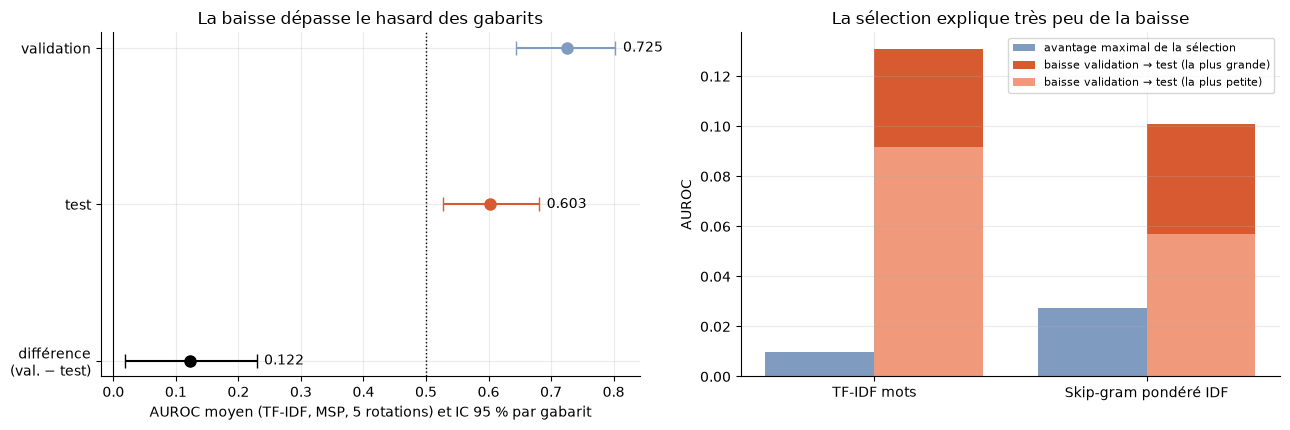

In [108]:
import tp2_new_figs as NF
fig = NF.fig_7_2b(DIRS["results"], DIRS["figures"]); plt.show()

**Lecture du visuel.** À gauche, l'AUROC en validation et au test avec leurs intervalles (tirage des gabarits) et la **différence**, dont l'intervalle ne contient pas 0. À droite, l'**avantage maximal de la sélection** (barre grise-bleue) est minuscule à côté de la baisse validation → test (barres corail) : la sélection explique très peu.

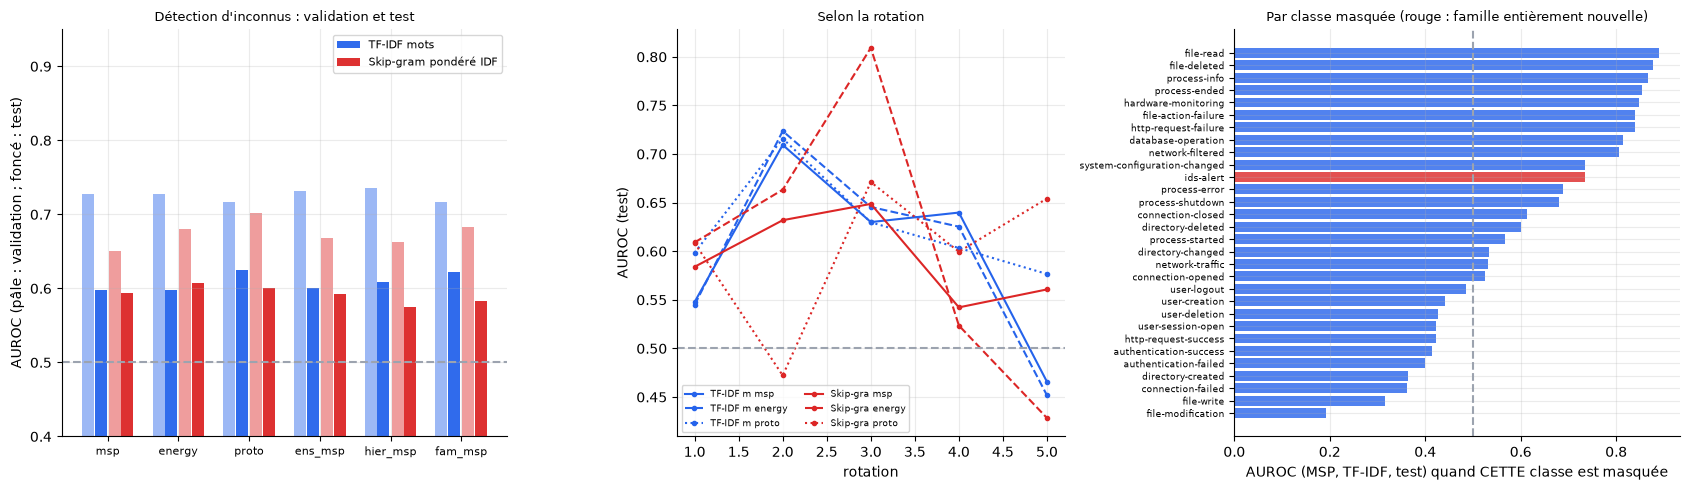

In [109]:
fig, ax = plt.subplots(1, 3, figsize=(17, 5), gridspec_kw={"width_ratios": [1.15, 1, 1.15]})
for j, rep in enumerate(SEEDS):
    d = open7[open7["représentation"] == REPS[rep]]; xs = np.arange(len(SCORES)) + j * .38 - .19
    ax[0].bar(xs - .09, [float(d[d.score == s_]["AUROC val"].iloc[0]) for s_ in SCORES], width=.17, color=[BLUE, RED][j], alpha=.45); ax[0].bar(xs + .09, [float(d[d.score == s_]["AUROC test"].iloc[0]) for s_ in SCORES], width=.17, color=[BLUE, RED][j], alpha=.95, label=REPS[rep])
ax[0].axhline(.5, color=GREY, ls="--"); ax[0].set_xticks(range(len(SCORES))); ax[0].set_xticklabels(SCORES, fontsize=8); ax[0].set_ylim(.4, .95); ax[0].set_ylabel("AUROC (pâle : validation ; foncé : test)"); ax[0].legend(fontsize=8); ax[0].set_title("Détection d'inconnus : validation et test", fontsize=9.5); ax[0].grid(axis="y", alpha=.25)
for rep, col in (("tfidf", BLUE), ("sg_idf", RED)):
    for s_, ls in (("msp", "-"), ("energy", "--"), ("proto", ":")):
        ax[1].plot(range(1, 6), [np.mean([r[s_]["auroc"] for r in rows7 if r["rep"] == rep and r["rot"] == k]) for k in range(1, 6)], ls, color=col, marker="o", ms=3, label=f"{REPS[rep][:8]} {s_}")
ax[1].axhline(.5, color=GREY, ls="--"); ax[1].set_xlabel("rotation"); ax[1].set_ylabel("AUROC (test)"); ax[1].set_title("Selon la rotation", fontsize=9.5); ax[1].legend(fontsize=6.5, ncol=2); ax[1].grid(alpha=.25)
ph = pd.DataFrame([{"classe": cl, "AUROC": v, "famille_nouvelle": len(TAXONOMY[CHILD2FAM[cl]]) == 1} for r in rows7 if r["rep"] == "tfidf" and r["seed"] == 42 for cl, v in r["per_hidden"].items()]).sort_values("AUROC")
ax[2].barh(range(len(ph)), ph["AUROC"], color=[RED if f else BLUE for f in ph["famille_nouvelle"]], alpha=.8); ax[2].set_yticks(range(len(ph))); ax[2].set_yticklabels(ph["classe"], fontsize=6.3); ax[2].axvline(.5, color=GREY, ls="--"); ax[2].set_xlabel("AUROC (MSP, TF-IDF, test) quand CETTE classe est masquée"); ax[2].set_title("Par classe masquée (rouge : famille entièrement nouvelle)", fontsize=9); ax[2].grid(axis="x", alpha=.25)
plt.tight_layout(); fig.savefig(DIRS["figures"] / "07_E2_inconnus.png", dpi=140); plt.show()

**Lecture de la figure.**
- **À gauche**, chaque barre foncée (test) est **nettement plus basse** que sa barre pâle (validation) : tous les scores perdent de **0,05 à 0,13**. Aucun ne se détache.
- **Au centre**, l'AUROC par rotation : la rotation 2 est la meilleure (0,71 pour TF-IDF), la rotation 5 est **sous 0,5** (0,47 en MSP, 0,45 en énergie) : **le détecteur donne un score plus « connu » aux inconnus qu'aux connus**. Le classement des rotations **change** entre validation et test (la rotation 3, la pire en validation à 0,56, devient moyenne à 0,63), preuve que **le résultat dépend fortement des gabarits particuliers de chaque jeu**.
- **À droite**, AUROC du MSP par classe masquée (test) : les plus faciles sont `file-read` (0,89), `file-deleted` (0,88), `process-info` (0,87), `process-ended` ; les plus difficiles `file-modification` (**0,19**), `file-write` (0,32), `connection-failed`, `directory-created`, `authentication-failed` (0,40), `authentication-success` (0,41). **`ids-alert`, la classe dont la famille est entièrement nouvelle, n'est qu'à 0,73** (0,90 en validation).
- **Attention, c'est un résultat important sur la fiabilité de l'étape 6** : `network-filtered`, la plus difficile en validation (0,09), est à **0,80** au test ; `database-operation` passe de 0,98 à 0,81 ; `ids-alert` de 0,90 à 0,73. **L'AUROC d'une classe isolée dépend de quelques gabarits** : on ne peut pas bâtir de conclusion « la classe X est difficile » sur **un** jeu de gabarits. **L'enseignement robuste est plus global** (voir 7.6 et 7.7).

## 7.6 Par quoi les classes masquées sont-elles remplacées ?

Quand une classe est masquée, le modèle la range **de force** dans une classe connue. On regarde laquelle.

In [110]:
rows = []
for r in rows7:
    if r["rep"] == "tfidf" and r["seed"] == 42:
        for cl, dist in r["hidden_pred"].items():
            top = list(dist.items())[0]; rows.append({"classe masquée": cl, "famille": CHILD2FAM[cl], "classe connue choisie à la place": top[0], "part": top[1], "même famille ?": CHILD2FAM[top[0]] == CHILD2FAM[cl], "AUROC (MSP)": round(r["per_hidden"][cl], 3)})
forced = pd.DataFrame(rows).sort_values("part", ascending=False); print(forced.to_string(index=False)); forced.to_csv(DIRS["results"] / "step7_forced.csv", index=False)
print(f"\nPart des classes masquées rangées de force dans une classe de la MÊME famille : {forced['même famille ?'].mean():.0%} ({int(forced['même famille ?'].sum())} sur {len(forced)})")
sf = forced[forced["même famille ?"]]; print("AUROC moyen quand la substitution reste dans la famille :", round(float(sf['AUROC (MSP)'].mean()), 3), "| hors famille :", round(float(forced[~forced['même famille ?']]['AUROC (MSP)'].mean()), 3))

              classe masquée          famille classe connue choisie à la place  part  même famille ?  AUROC (MSP)
                  file-write             file                      user-logout 1.000           False        0.316
           file-modification             file     system-configuration-changed 0.999           False        0.193
             network-traffic          network           authentication-success 0.986           False        0.532
           directory-changed             file                file-modification 0.981            True        0.533
           directory-created             file                directory-deleted 0.964            True        0.364
      authentication-success   authentication            authentication-failed 0.960            True        0.414
        http-request-success              web             http-request-failure 0.931            True        0.422
               process-error          process     system-configuration-changed 0.904    

**Lecture.**
- **Le plus frappant : une classe masquée est souvent rangée, à presque 100 %, dans une seule classe connue** : `file-write` → `user-logout` (**100 %**), `file-modification` → `system-configuration-changed` (**99,9 %**), `network-traffic` → `authentication-success` (**98,6 %**), `directory-changed` → `file-modification` (98,1 %), `directory-created` → `directory-deleted` (96,4 %), **`authentication-success` → `authentication-failed` (96,0 %)**, `http-request-success` → `http-request-failure` (93,1 %).
- **37 % seulement (11 classes sur 30) sont rangées dans la même famille.** Le **remplacement hors famille est donc majoritaire** (63 %), mais il n'est pas non plus le plus facile à repérer : **AUROC moyen de 0,51 quand la substitution reste dans la famille, 0,66 quand elle en sort**. Une substitution **dans** la famille est plus difficile à rejeter : le modèle ne doute pas puisque le vocabulaire est proche. **H4 est donc à demi confirmée** (le sens va dans la direction attendue, avec un écart de 0,15), mais **sur des classes isolées le résultat est instable** (7.5).
- **Les paires opposées sont les pièges** : `authentication-success` masquée est prise pour `authentication-failed` à 96 %. Dans un SIEM, c'est une erreur **lourde de conséquences** (un succès d'authentification pris pour un échec, ou l'inverse), que l'article de SIEVE signale lui-même (V6).

## 7.7 Préparation du calcul de l'encodeur sur le test (Colab)

Le premier calcul de l'encodeur (étape 6) ne conservait pas les modèles : pour l'évaluer au test, il a fallu le **réentraîner** et prédire aussi le test. Le fichier `colab/encoder_data_v2.csv.gz` ajoute donc au fichier de l'étape 6 les **23 940 logs de test** extraits ci-dessus ; le notebook `colab/tp2_encoder_colab_v2.ipynb` a fait les rotations 1 et 2 (modèles sur Google Drive), le reste a été calculé sur le Mac (`colab/local/`, poids dans `artifacts/models/encoder_local/`). Les résultats sont en **7.8**.

In [111]:
COLAB_DIR = PROJECT_ROOT / "colab"
def pack_text(df_, split):
    return pd.DataFrame({"split": split, "version": df_.version.values, "row": df_.row.values, "category": df_.category.values, "family": [CHILD2FAM[c] for c in df_.category], "group": df_.group.values, "text": [normalize(LOG[v][r]) for v, r in zip(df_.version, df_.row)]})
enc_old = pd.read_csv(COLAB_DIR / "encoder_data.csv.gz")
enc_v2 = pd.concat([enc_old, pack_text(te, "test")], ignore_index=True); assert set(enc_v2.split) == {"train", "val", "test"}
p_enc2 = COLAB_DIR / "encoder_data_v2.csv.gz"; enc_v2.to_csv(p_enc2, index=False, compression={"method": "gzip", "mtime": 0})
print(f"Écrit : {p_enc2.relative_to(PROJECT_ROOT)}  {p_enc2.stat().st_size / 1e6:.1f} Mo  ({(enc_v2.split == 'train').sum():,} entraînement, {(enc_v2.split == 'val').sum():,} validation, {(enc_v2.split == 'test').sum():,} test)")
sh2 = set(enc_v2[(enc_v2.split == "test") & (enc_v2.category != "user-session-open")].group) & set(enc_v2[enc_v2.split == "train"].group)
print("Gabarits de test (hors la classe à gabarit unique) partagés avec l'entraînement du fichier :", len(sh2))
assert not sh2

Écrit : colab/encoder_data_v2.csv.gz  4.5 Mo  (25,200 entraînement, 23,940 validation, 23,940 test)
Gabarits de test (hors la classe à gabarit unique) partagés avec l'entraînement du fichier : 0


<!-- ENC-AUTO -->
## 7.8 L'encodeur Transformer sur le jeu de test

Alignement : test 23940 logs (mêmes (version, ligne) que l'échantillon de test de 7.2)


 rot  val_f1_flat  f1_flat  f1_hier  val_auroc_msp  auroc_msp  auroc_energy  auroc_mc  fpr95_msp  rej_known_msp  acc_unknown_msp   ece
   1        0.606    0.480    0.496          0.612      0.430         0.463     0.445      0.966          0.084            0.941 0.262
   2        0.724    0.399    0.401          0.700      0.519         0.524     0.500      0.953          0.128            0.853 0.389
   3        0.650    0.486    0.506          0.513      0.715         0.736     0.698      0.911          0.054            0.907 0.347
   4        0.676    0.467    0.477          0.721      0.580         0.583     0.580      0.948          0.112            0.865 0.333
   5        0.725    0.410    0.423          0.642      0.600         0.597     0.599      0.954          0.082            0.886 0.408

Moyennes (test) : F1 fermé 0.449 (validation 0.676) ; AUROC msp 0.569 (validation 0.638), énergie 0.581, MC 0.564 ; FPR@95 msp 0.946 ; connus rejetés au seuil de validation 0.092 ; inconnus

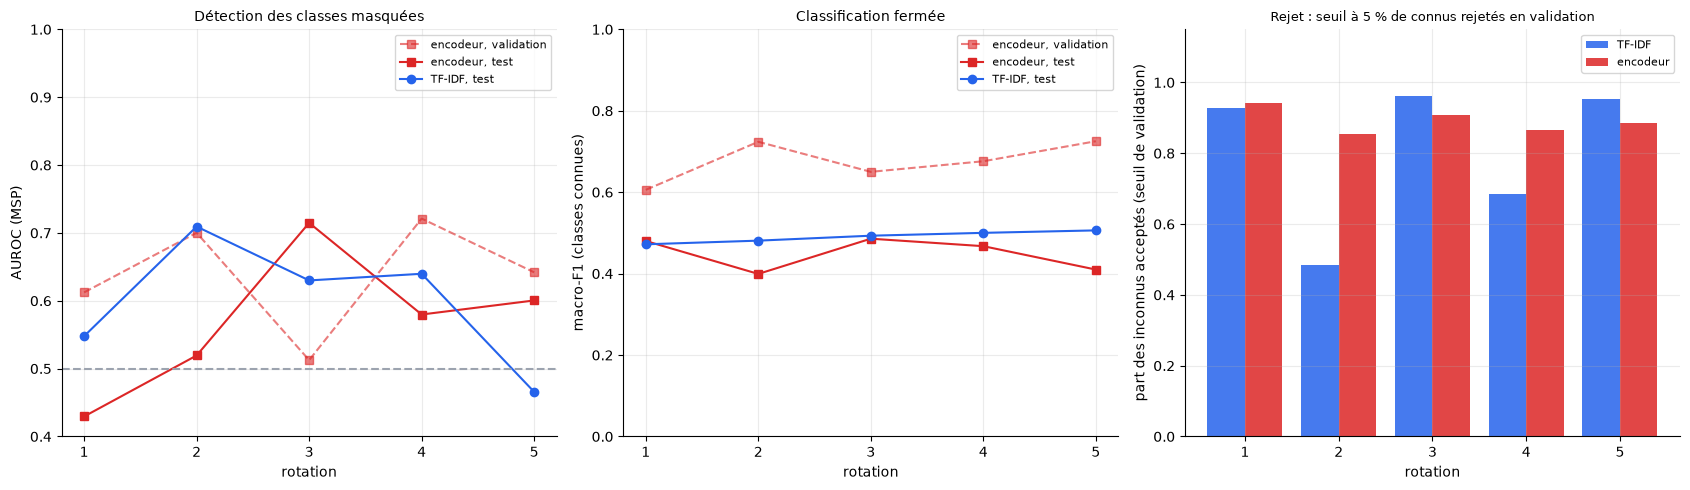

In [112]:
PERM["test"] = _perm(_ed[_ed.split == "test"].reset_index(drop=True), te); print("Alignement : test", len(PERM["test"]), "logs (mêmes (version, ligne) que l'échantillon de test de 7.2)")
rows_et = []; aux_t = {}
for r in range(1, 6):
    base = ENC_DIR / ("out_v2" if r <= 2 else "out_v2_local"); jsn = base / f"uncased_rot{r}_len256_s42.json"
    ov, av = enc_eval(base / f"uncased_rot{r}_len256_s42_val.npz", jsn, "val", yva, va_rows.group.values); ot, at = enc_eval(base / f"uncased_rot{r}_len256_s42_test.npz", jsn, "test", yte, grp_te); aux_t[r] = (ov, ot, av, at)
    row = {"rot": r, "acc": ot["acc"], "f1_flat": ot["f1_flat"], "f1_hier": ot["f1_hier"], "f1_fam": ot["f1_fam"], "ece": ot["ece"], "d_hier": ot["d_hier"]}
    for s_ in av["scores"]:
        tau = float(np.quantile(av["scores"][s_][av["isk"]], 0.05)); st = at["scores"][s_]
        row.update({f"val_auroc_{s_}": ov[f"auroc_{s_}"], f"auroc_{s_}": ot[f"auroc_{s_}"], f"fpr95_{s_}": ot[f"fpr95_{s_}"], f"oscr_{s_}": ot[f"oscr_{s_}"], f"rej_known_{s_}": float((st[at["isk"]] < tau).mean()), f"acc_unknown_{s_}": float((st[~at["isk"]] >= tau).mean())})
    row["per_hidden"] = ot["per_hidden"]; row["val_f1_flat"] = ov["f1_flat"]; row["dev_hidden_pred"] = {cl: pd.Series(at["pred"][yte == cl]).value_counts(normalize=True).head(2).round(2).to_dict() for cl in ot["per_hidden"]}; rows_et.append(row)
et = pd.DataFrame(rows_et); show = ["rot", "val_f1_flat", "f1_flat", "f1_hier", "val_auroc_msp", "auroc_msp", "auroc_energy", "auroc_mc", "fpr95_msp", "rej_known_msp", "acc_unknown_msp", "ece"]
print(et[show].round(3).to_string(index=False)); et.drop(columns=["per_hidden", "d_hier", "dev_hidden_pred"]).to_csv(DIRS["results"] / "step7_encodeur.csv", index=False)
print("\nMoyennes (test) : F1 fermé %.3f (validation %.3f) ; AUROC msp %.3f (validation %.3f), énergie %.3f, MC %.3f ; FPR@95 msp %.3f ; connus rejetés au seuil de validation %.3f ; inconnus acceptés %.3f ; ECE %.3f" % (et.f1_flat.mean(), et.val_f1_flat.mean(), et.auroc_msp.mean(), et.val_auroc_msp.mean(), et.auroc_energy.mean(), et.auroc_mc.mean(), et.fpr95_msp.mean(), et.rej_known_msp.mean(), et.acc_unknown_msp.mean(), et.ece.mean()))
tf_t = lambda f: np.array([np.mean([f(r) for r in rows7 if r["rep"] == "tfidf" and r["rot"] == k]) for k in range(1, 6)])
tf_t_au = tf_t(lambda r: r["msp"]["auroc"]); tf_t_f1 = tf_t(lambda r: r["closed"]["f1_flat"]); tf_t_rej = tf_t(lambda r: r["msp"]["known_reject_at_val_tau"]); tf_t_acc = tf_t(lambda r: r["msp"]["fpr_at_val_tau"])
cmp7 = pd.DataFrame({"rotation": range(1, 6), "TF-IDF F1": tf_t_f1, "encodeur F1": et.f1_flat, "TF-IDF AUROC msp": tf_t_au, "encodeur AUROC msp": et.auroc_msp, "TF-IDF inconnus acceptés": tf_t_acc, "encodeur inconnus acceptés": et.acc_unknown_msp}).round(3); print("\nEncodeur contre TF-IDF au test, par rotation :"); print(cmp7.to_string(index=False))
d_au7 = et.auroc_msp.values - tf_t_au; d_f17 = et.f1_flat.values - tf_t_f1
print("Écart encodeur - TF-IDF : F1 fermé", np.round(d_f17, 3), "(moyenne %+.3f) ; AUROC msp" % d_f17.mean(), np.round(d_au7, 3), "(moyenne %+.3f, %d/5 positifs)" % (d_au7.mean(), (d_au7 > 0).sum()))
print("\nTête hiérarchique contre plate au test (encodeur, IC par gabarit) :"); print(pd.DataFrame([{"rot": r["rot"], "Δ F1": r["d_hier"][0], "IC bas": r["d_hier"][1], "IC haut": r["d_hier"][2]} for r in rows_et]).round(4).to_string(index=False))
print("\nAUROC par classe masquée (test, MSP) :"); print(pd.DataFrame([{"rot": r["rot"], "classe": cl, "AUROC": v, "remplacée par": r["dev_hidden_pred"][cl]} for r in rows_et for cl, v in r["per_hidden"].items()]).sort_values("AUROC").round(3).to_string(index=False))
fig, ax = plt.subplots(1, 3, figsize=(17, 5)); x = np.arange(1, 6)
ax[0].plot(x, et.val_auroc_msp, "s--", color=RED, alpha=.6, label="encodeur, validation"); ax[0].plot(x, et.auroc_msp, "s-", color=RED, label="encodeur, test"); ax[0].plot(x, tf_t_au, "o-", color=BLUE, label="TF-IDF, test"); ax[0].axhline(.5, color=GREY, ls="--")
ax[0].set_xlabel("rotation"); ax[0].set_ylabel("AUROC (MSP)"); ax[0].set_title("Détection des classes masquées", fontsize=10); ax[0].legend(fontsize=8); ax[0].grid(alpha=.25); ax[0].set_ylim(.4, 1)
ax[1].plot(x, et.val_f1_flat, "s--", color=RED, alpha=.6, label="encodeur, validation"); ax[1].plot(x, et.f1_flat, "s-", color=RED, label="encodeur, test"); ax[1].plot(x, tf_t_f1, "o-", color=BLUE, label="TF-IDF, test"); ax[1].set_xlabel("rotation"); ax[1].set_ylabel("macro-F1 (classes connues)")
ax[1].set_title("Classification fermée", fontsize=10); ax[1].legend(fontsize=8); ax[1].grid(alpha=.25); ax[1].set_ylim(0, 1)
ax[2].bar(x - .2, tf_t_acc, .4, color=BLUE, alpha=.85, label="TF-IDF"); ax[2].bar(x + .2, et.acc_unknown_msp, .4, color=RED, alpha=.85, label="encodeur"); ax[2].set_xlabel("rotation"); ax[2].set_ylabel("part des inconnus acceptés (seuil de validation)"); ax[2].set_title("Rejet : seuil à 5 % de connus rejetés en validation", fontsize=9.5); ax[2].legend(fontsize=8); ax[2].set_ylim(0, 1.15)
[a_.set_xticks(range(1, 6)) for a_ in ax]; plt.tight_layout(); fig.savefig(DIRS["figures"] / "07_encodeur_test.png", dpi=140); plt.show()

<!-- ENC-AUTO -->
**Ce qu'on a fait, expliqué.** Pour évaluer l'encodeur au test, il a fallu le **réentraîner** (le premier notebook Colab ne gardait pas les modèles) avec les mêmes réglages (`distilbert-base-uncased`, 256 jetons, 2 époques, graine 42, une exécution par rotation) et le faire prédire **validation et test** : rotations 1 et 2 au Colab, rotations 3, 4 et 5 sur le Mac (le GPU Apple, avec l'attention classique car la rapide ne gère pas le dropout). **Le seuil de rejet** (règle de l'étape 7 : 5 % des connus de validation rejetés) est calé sur la validation **de la même exécution** que le test. Le jeu de test est celui déjà ouvert à l'étape 7 (aucune nouvelle ouverture ; 23 940 logs) ; **aucun log de test n'a servi à entraîner ou à régler quoi que ce soit** dans les notebooks de calcul.

**En simple.** C'est l'examen final de l'encodeur : mêmes classes masquées, mêmes logs que pour le TF-IDF, des gabarits jamais vus à l'entraînement.

**Lecture (test, moyenne des 5 rotations, mêmes classes connues pour les deux modèles).**

- **La classification fermée s'effondre de la validation au test, pour les deux modèles, et davantage pour l'encodeur.** Macro-F1 de l'encodeur **0,449** au test contre **0,676** en validation (−0,23) ; TF-IDF **0,490** au test contre 0,643 en validation (−0,15). Au test, l'encodeur est **un peu en dessous** du TF-IDF : **−0,042** en moyenne, négatif dans 4 rotations sur 5. La **supériorité** de l'encodeur en fermé, vue en validation (+0,036), **n'existe plus**. Le test est la mesure de référence : la validation était **nettement plus optimiste** pour les deux modèles (la raison n'est pas établie ici ; une piste est que les gabarits de validation sont plus proches de ceux de l'entraînement que ceux du test).
- **Détection des inconnus : aucun avantage de l'encodeur.** AUROC du MSP **0,569** (énergie 0,581, Monte-Carlo 0,564) contre **0,599** pour le TF-IDF : écart **−0,030**, **de signe variable** (négatif dans 3 rotations, positif dans 2, de −0,19 à +0,14). En validation l'encodeur était pire dans 5 rotations sur 5 ; **le sens de l'écart change entre validation et test**, et selon la rotation (rotation 3 : AUROC 0,51 en validation, 0,72 au test) : **le choix des classes masquées domine**. **H2 n'est pas confirmée** : l'encodeur ne détecte pas mieux ; il ne détecte pas clairement moins bien non plus.
- **Le rejet ne marche pas.** Avec le seuil de validation, l'encodeur laisse passer **89 %** des inconnus (TF-IDF : 80 %) tout en rejetant **9,2 %** des connus (visé : 5 %). FPR@95 de 0,95. Calibration : ECE **0,35** au test (0,18 en validation) : la confiance est **très mal calibrée** hors de la distribution d'entraînement.
- **Par classe masquée (test, MSP).** **11 classes sur 30** ont un AUROC **sous 0,5** : l'encodeur est **plus sûr de lui sur l'inconnu que sur le connu**. Les cas extrêmes sont des **erreurs « forcées » toujours identiques** : `user-creation` classé à 100 % en `user-deletion` (AUROC 0,08), `file-deleted` classé à 100 % en `network-filtered` (0,11), `file-modification` à 99 % en `system-configuration-changed` (0,10), `user-session-open` en `authentication-success` (0,26), `http-request-success` à 99 % en `http-request-failure` (0,26). Une classe masquée n'est donc pas « mal reconnue au hasard » : elle est **absorbée avec confiance** par une classe voisine. **`ids-alert`** (famille nouvelle) tombe à **0,64** (0,85 en validation) : **H4** tient moins bien qu'avec le TF-IDF.
- **Tête hiérarchique contre tête plate (H1).** Écart de macro-F1 au test : +0,016, −0,001, +0,019, +0,008, +0,012 selon la rotation (moyenne **+0,011**) ; l'intervalle (par gabarit) **exclut 0 dans 1 rotation sur 5** (la 3). En validation, la moyenne était de −0,005. **Un petit gain possible mais non établi** : le signe a changé entre validation et test, et l'écart reste de l'ordre du bruit d'exécution (≈ 0,02, voir 6.10). **H1 non tranchée pour l'encodeur.**

**Limites de cette comparaison.** (1) Une seule graine par rotation pour l'encodeur (trois pour le TF-IDF) ; (2) deux GPU différents selon les rotations (bruit d'exécution jusqu'à ≈ 0,02, voir V67) ; (3) la comparaison encodeur/TF-IDF n'est **pas** un test enregistré avant les résultats : elle est **descriptive** (5 rotations ne permettent pas de seuil de significativité) ; (4) réglages de l'encodeur non optimisés (pas de balayage du taux d'apprentissage, 2 époques).

**Registre (suite).**

| N° | Affirmation | Source | Niveau |
|---|---|---|---|
| V68 | Encodeur au test (5 rotations, une exécution chacune) : macro-F1 fermé 0,449 (validation 0,676), AUROC MSP 0,569, énergie 0,581, MC 0,564, FPR@95 0,946, inconnus acceptés 0,890, connus rejetés 0,092, ECE 0,348 | Calcul (`colab/out_v2*/`) | calcul |
| V69 | TF-IDF, mêmes rotations et mêmes classes connues au test : macro-F1 0,490, AUROC MSP 0,599, inconnus acceptés 0,802 ; écart encodeur − TF-IDF : F1 −0,042 (4 rotations sur 5 négatives), AUROC −0,030 (signe variable) | Calcul | calcul |
| V70 | Tête hiérarchique contre plate (encodeur, test) : +0,011 en moyenne, IC par gabarit excluant 0 dans 1 rotation sur 5 ; en validation −0,005 | Calcul | calcul |
| V71 | Au test, 11 classes masquées sur 30 ont un AUROC sous 0,5 ; `user-creation` → `user-deletion` (100 %), `file-deleted` → `network-filtered` (100 %) | Calcul | calcul |

**Bilan (encodeur, test).** L'encodeur **n'apporte pas** ce qu'on en attendait : en fermé il est **au niveau ou en dessous** du TF-IDF, en monde ouvert il n'est **pas meilleur** (et il rejette mal). Le gain de la validation était **une illusion de la validation** ; c'est la raison pour laquelle le test avait été scellé. Pour le monde ouvert, **le score d'inconnu et le choix des classes comptent plus que le type de représentation**.

**Registre (suite).**

| N° | Affirmation | Source | Niveau |
|---|---|---|---|
| V42 | E1 (test, 30 classes, gabarits jamais vus) : TF-IDF plat F1 0,4593 (palier A 0,4832) ; hiérarchique 0,4733 (palier A 0,5153) ; Δ palier A +0,0229, IC [−0,0102 ; +0,0469] ; Skip-gram 0,3759 / 0,3905 ; distance d'erreur 0,8613 / 0,8254 | Calcul | calcul |
| V43 | H1 : le signe de l'écart hiérarchique - plat s'inverse entre validation (−0,026) et test (+0,023), toujours dans l'intervalle de confiance : non tranchée | Calcul | calcul |
| V44 | Par palier (TF-IDF plat) : A 0,507 d'exactitude, B 0,630, C 0,250 ; classes à F1 0,000 : `file-action-failure`, `file-modification`, `network-traffic`, `connection-closed` ; `user-session-open` 0,998 (gabarit partagé : sans valeur) | Calcul | calcul |
| V45 | E2 (test, 5 rotations) : AUROC MSP 0,599 (TF-IDF) et 0,594 (Skip-gram) contre 0,728 et 0,651 en validation ; FPR@95 0,92 ; rotation 5 à 0,47 (sous le hasard) ; écart entre rotations 0,05 à 0,14 | Calcul | calcul |
| V46 | Le seuil calé sur la validation rejette 13 % des connus et laisse passer 80 % des inconnus au test | Calcul | calcul |
| V47 | AUROC par classe masquée : `network-filtered` 0,09 en validation, 0,80 au test ; `ids-alert` 0,90 puis 0,73 : conclusions par classe instables | Calcul | calcul |
| V48 | Classes masquées rangées dans la même famille : 37 % (11 sur 30) ; AUROC moyen 0,51 (même famille) contre 0,66 (autre famille) ; `authentication-success` masquée prise pour `authentication-failed` à 96 % | Calcul | calcul |
| V49 | Test ouvert une seule fois (journal : 2026-11-05 00:05:55) après enregistrement des règles | Journal d'accès | calcul |

**Bilan de l'étape 7 (modèles linéaires).** Les chiffres du test confirment et **aggravent** ceux de la validation : sur des **gabarits jamais vus**, la classification fermée plafonne à **0,46 (30 classes)**, **la détection de classes inconnues est presque inexistante (AUROC 0,60, FPR@95 de 0,92)** et **un seuil réglé sur la validation ne se transporte pas**. Sur **S1, S2, S3, les objectifs ne sont pas atteints** ; seul **S4** l'est (la famille est bien plus facile à prédire que la classe fine). **L'effet de la hiérarchie n'est pas démontré** (signe qui s'inverse entre validation et test). **Les conclusions par classe sont instables** : peu de gabarits par classe, beaucoup de variabilité. L'encodeur Transformer, qui lit le contexte, était le candidat pour faire mieux : il est évalué en **7.8** (placé juste avant ce bilan) et **ne fait pas mieux**.

**Prochaine étape.** Étape 8 : robustesse (E4 : selon le niveau de perturbation p ; E5 : CDS, toujours en suspens ; attaques textuelles).

---
# Étape 8 : Robustesse (E4, attaques textuelles, E5)

**Pourquoi cette étape existe.** Un modèle qui marche sur des logs « propres » peut s'effondrer dès qu'on les modifie légèrement : une faute de frappe, une lettre d'un autre alphabet, quelques mots ajoutés. En sécurité, c'est l'étape qui compte : **un attaquant qui veut échapper à un SIEM modifiera ses logs**. On mesure donc deux choses : (1) la **stabilité selon le niveau de perturbation p** (E4), qui est une perturbation **fournie par le jeu** ; (2) la **résistance à des attaques textuelles** qu'on fabrique nous-mêmes.

**Concepts.**
- **Perturbation SPICE (p)** : modifications automatiques (synonymes, mots ajoutés) appliquées par les auteurs de SIEVE ; plus p est grand, plus le log s'éloigne de son gabarit (figure 2.5).
- **Attaque adversariale textuelle** : une modification **volontaire et ciblée** d'un texte, qui garde le sens pour un humain mais trompe un modèle. Ici trois attaques **indépendantes du modèle** (elles ne le « regardent » pas), déterministes pour une graine donnée.
- **Attaque adaptative** (non faite ici) : l'attaquant connaît le modèle et optimise la modification contre lui. Elle est **plus dure** ; on le dit comme limite.
- **Baisse relative** : $(F1_{\text{propre}}-F1_{\text{attaqué}})/F1_{\text{propre}}$ : ce qu'on perd, en proportion de ce qu'on avait.

**Les trois attaques (menace réaliste sur des logs).**

| Attaque | Ce qu'elle fait | Pourquoi un attaquant s'en servirait | Ce qu'elle casse |
|---|---|---|---|
| **Typos** | fautes de frappe dans des mots (échange de deux lettres voisines, lettre supprimée ou doublée) | brouiller des mots-clés (`failure` devient `failrue`) sans changer le sens pour un humain | les mots du vocabulaire (un mot devient inconnu) |
| **Homoglyphes** | des lettres latines sont remplacées par des lettres d'**autres alphabets** d'aspect identique (`a` devient `а` cyrillique) | un log lisible pour un humain, mais **sans aucun mot reconnaissable** pour un programme | tout mot touché est coupé en morceaux (le cyrillique n'est pas une lettre latine) |
| **Padding** (dilution) | insertion de mots anodins aux positions tirées au hasard | noyer le signal dans du bruit | la pondération : les vrais mots pèsent moins |

**Hypothèse H6 (écrite avant les chiffres).** Les **n-grammes de caractères** résistent mieux aux typos et aux homoglyphes que les mots, car un mot altéré garde la plupart de ses morceaux de 3 à 5 lettres. *Cette comparaison n'était pas dans le plan de l'étape 6* : le modèle à caractères est **ajouté ici** comme **mesure exploratoire**, pas comme modèle figé avant le test. On le dira à chaque utilisation de ses chiffres.

## 8.1 Le module d'attaques et ses tests

In [113]:
ATT_SRC = r'''"""Attaques textuelles sur des logs de sécurité (TP2, étape 8).

Trois attaques qui ne dépendent PAS du modèle attaqué (elles ne le « regardent » pas), déterministes pour une graine donnée :
  - typos      : fautes de frappe dans des mots (échange de deux lettres voisines, lettre supprimée, lettre doublée) ;
  - homoglyphs : lettres latines remplacées par des lettres d'autres alphabets d'aspect identique (a -> а cyrillique...) ;
  - padding    : insertion de mots anodins (sans rapport avec le log) à des positions tirées au hasard.
Un spammeur, ou ici un attaquant qui veut brouiller un SIEM, peut faire les trois sans connaître le modèle.
"""
import random
import re

WORD = re.compile(r"[A-Za-z]{4,}")
HOMOGLYPH = {"a": "а", "e": "е", "o": "о", "p": "р", "c": "с", "x": "х", "y": "у", "i": "і",
             "A": "А", "E": "Е", "O": "О", "P": "Р", "C": "С", "X": "Х", "B": "В", "H": "Н", "M": "М", "T": "Т"}
INVERSE_HOMOGLYPH = {v: k for k, v in HOMOGLYPH.items()}
FILLER = ("the report update normal service message notice info default value current number list item record version module "
          "standard general common simple basic public random sample example another several various certain particular").split()


def typos(text, rate, seed=0):
    rnd = random.Random(seed)

    def mutate(m):
        w = m.group(0)
        if rnd.random() >= rate:
            return w
        i = rnd.randrange(1, len(w) - 1); op = rnd.choice(("swap", "drop", "dup"))
        if op == "swap":
            return w[:i] + w[i + 1] + w[i] + w[i + 2:]
        if op == "drop":
            return w[:i] + w[i + 1:]
        return w[:i] + w[i] + w[i:]
    return WORD.sub(mutate, text)


def homoglyphs(text, rate, seed=0):
    rnd = random.Random(seed)
    return "".join(HOMOGLYPH[c] if (c in HOMOGLYPH and rnd.random() < rate) else c for c in text)


def padding(text, rate, seed=0, filler=FILLER):
    rnd = random.Random(seed); words = text.split(" ")
    n_ins = max(1, int(round(rate * len(words)))) if rate > 0 else 0
    for _ in range(n_ins):
        words.insert(rnd.randrange(0, len(words) + 1), rnd.choice(filler))
    return " ".join(words)


def unconfuse(text):
    """Parade : remplace les homoglyphes connus par leur lettre latine (étape 9)."""
    return "".join(INVERSE_HOMOGLYPH.get(c, c) for c in text)


ATTACKS = {"typos": typos, "homoglyphs": homoglyphs, "padding": padding}


def robust_tokens(text):
    """Pipeline A précédé de la normalisation des homoglyphes (parade, étape 9). Fonction de module : sérialisable avec le modèle."""
    from tp2_logtext import tokenize
    return tokenize(unconfuse(text))
'''
if "__ATT_SRC__" not in ATT_SRC: (PROJECT_ROOT / "src" / "tp2_attacks.py").write_text(ATT_SRC)
ATT_HASH = hashlib.sha256((PROJECT_ROOT / "src" / "tp2_attacks.py").read_bytes()).hexdigest()[:12]
import tp2_attacks; importlib.reload(tp2_attacks); from tp2_attacks import typos, homoglyphs, padding, unconfuse, ATTACKS
t0_ = "Failed password for root from 42.1.2.3 port 22 ssh2"
assert typos(t0_, 0.0) == t0_ and homoglyphs(t0_, 0.0) == t0_ and padding(t0_, 0.0) == t0_, "taux 0 : texte inchangé"
assert typos(t0_, 1.0, 1) != t0_ and typos(t0_, 1.0, 1) == typos(t0_, 1.0, 1), "déterministe pour une graine, et modifie le texte"
assert unconfuse(homoglyphs(t0_, 1.0, 1)) == t0_, "la parade retrouve le texte d'origine"
h_ = homoglyphs(t0_, 1.0, 1); assert h_ != t0_ and len(h_) == len(t0_) and not h_.isascii(), "les homoglyphes sont bien hors ASCII"
assert len(padding(t0_, 0.5, 1).split()) > len(t0_.split()) and set(t0_.split()) <= set(padding(t0_, 0.5, 1).split()), "le padding ajoute des mots sans en retirer"
assert tokenize(t0_) != tokenize(h_), "l'attaque par homoglyphes change bien les jetons du pipeline A"
print("Tests des attaques : taux 0 = identité ; déterminisme ; homoglyphes hors ASCII et réversibles ; padding sans retrait ; jetons changés : OK")
print("\nExemple (un log de SIEVE_00) :"); ex_ = LOG[0][int(np.where(V[0]["category"].values == "authentication-failed")[0][3])][:150]
for nm_, f_ in ATTACKS.items(): print(f"  {nm_:<11}", f_(ex_, 0.3, 7)[:160])
print("  original   ", ex_)

Tests des attaques : taux 0 = identité ; déterminisme ; homoglyphes hors ASCII et réversibles ; padding sans retrait ; jetons changés : OK

Exemple (un log de SIEVE_00) :
  typos       [Fri Mar 23 00:47:56 1979] [error] [cilent 91.192.239.161] user anngeladavis: auhentication failure for "/wets/local.tiiff/every": Password Mismatch
  homoglyphs  [Fri Мar 23 00:47:56 1979] [еrror] [clіent 91.192.239.161] usеr angеlаdavis: аuthеntication fаilurе fоr "/wеst/locаl.tiff/every": Раsswоrd Mismatch
  padding     [Fri update Mar 23 00:47:56 list 1979] [error] [client 91.192.239.161] user general angeladavis: particular authentication failure for "/west/local.tiff/every":
  original    [Fri Mar 23 00:47:56 1979] [error] [client 91.192.239.161] user angeladavis: authentication failure for "/west/local.tiff/every": Password Mismatch


**Lecture.** Les tests vérifient : un taux de 0 ne change rien ; le même taux et la même graine donnent **toujours** le même texte (reproductible) ; les homoglyphes sont **hors ASCII** et **réversibles** (la parade de l'étape 9 retrouve exactement le texte d'origine) ; le padding **ajoute** sans jamais retirer ; et l'attaque par homoglyphes **change bien les jetons** du pipeline A (sinon elle serait inoffensive). Dans l'exemple, avec 30 % d'intensité : le log `authentication failure` devient `аuthеntication fаilurе`, qui **se lit pareil pour un humain** mais n'est plus le même mot pour la machine.

## 8.2 Plan et critères (écrits avant les chiffres)

In [114]:
PLAN8 = """
E4a. Les modèles de l'étape 7 (appris sur les 6 versions) sont évalués sur le test, version par version (p = 0 à 0,5).
E4b. Matrice entraînement x test : un TF-IDF plat appris sur UNE seule version (p d'entraînement) est évalué sur chaque version de test.
Attaques : typos, homoglyphes, padding, chacune à 3 intensités (faible, moyenne, forte) ; appliquées au TEXTE de test seulement ; mêmes logs, même découpage.
Modèles attaqués : TF-IDF mots, Skip-gram pondéré IDF, TF-IDF caractères 3-5 (nouveau : hypothèse H6 = les caractères résistent mieux aux fautes), tous à 30 classes.
Mesures : macro-F1 du palier A (18 classes, gabarits de test nouveaux) ; baisse relative = (F1 propre - F1 attaqué) / F1 propre ; en ouvert : AUROC des 5 rotations (TF-IDF, MSP) sur le test attaqué.
Critère de robustesse : baisse relative <= 10 % = acceptable ; <= 5 % = bonne ; > 25 % = fragile.
Hypothèses : H3 (la détection d'inconnus se dégrade quand p augmente) ; H6 (n-grammes de caractères plus robustes aux typos et homoglyphes).
Le test est déjà ouvert : on l'utilise pour MESURER ; aucune décision de modèle n'est prise d'après ces mesures (les parades de l'étape 9 sont choisies d'après la validation).
"""
print(PLAN8)


E4a. Les modèles de l'étape 7 (appris sur les 6 versions) sont évalués sur le test, version par version (p = 0 à 0,5).
E4b. Matrice entraînement x test : un TF-IDF plat appris sur UNE seule version (p d'entraînement) est évalué sur chaque version de test.
Attaques : typos, homoglyphes, padding, chacune à 3 intensités (faible, moyenne, forte) ; appliquées au TEXTE de test seulement ; mêmes logs, même découpage.
Modèles attaqués : TF-IDF mots, Skip-gram pondéré IDF, TF-IDF caractères 3-5 (nouveau : hypothèse H6 = les caractères résistent mieux aux fautes), tous à 30 classes.
Mesures : macro-F1 du palier A (18 classes, gabarits de test nouveaux) ; baisse relative = (F1 propre - F1 attaqué) / F1 propre ; en ouvert : AUROC des 5 rotations (TF-IDF, MSP) sur le test attaqué.
Critère de robustesse : baisse relative <= 10 % = acceptable ; <= 5 % = bonne ; > 25 % = fragile.
Hypothèses : H3 (la détection d'inconnus se dégrade quand p augmente) ; H6 (n-grammes de caractères plus robustes aux typo

## 8.3 E4a : les modèles de l'étape 7, version par version (p de 0 à 0,5)

Les modèles ont été appris sur les six versions mélangées ; on les évalue sur le test, une version à la fois.

In [115]:
def f1A(pred_i, mask_rows): return float(f1_score(yte_i[mask_rows & tierA_te], pred_i[mask_rows & tierA_te], average="macro", labels=np.where(tierA)[0]))
rows = []
for rep, lab in (("tfidf", "TF-IDF mots"), ("sg_idf", "Skip-gram pondéré IDF")):
    for key, nm in (("pred_flat", "plat"), ("pred_hier", "hiérarchique")):
        pi = np.array([CI[c] for c in E1t[rep][key]]); row = {"modèle": f"{lab} ({nm})"}
        for v in range(6): row[f"p={v / 10}"] = round(float(f1_score(yte_i[(ver_te == v) & tierA_te], pi[(ver_te == v) & tierA_te], average="macro", labels=np.where(tierA)[0])), 4)
        rows.append(row)
e4a = pd.DataFrame(rows); print(e4a.to_string(index=False)); e4a.to_csv(DIRS["results"] / "step8_E4a_closed.csv", index=False)
# détection d'inconnus par version (TF-IDF, MSP, 5 rotations, graine 42)
ST = {}; rows = []
for rot in range(5):
    m = load_frozen_os("tfidf", rot, 42); ST[rot] = m.scores(te_text); hidden = ROTATIONS[rot]; known_t = ~np.isin(yte, hidden)
    row = {"rotation": rot + 1}
    for v in range(6): mv = ver_te == v; row[f"p={v / 10}"] = round(float(open_metrics(ST[rot]["msp"][mv], known_t[mv])["auroc"]), 3)
    rows.append(row)
e4b_open = pd.DataFrame(rows); e4b_open.loc["moyenne"] = ["moyenne"] + [round(float(e4b_open[f"p={v / 10}"].mean()), 3) for v in range(6)]; print("\nAUROC de détection d'inconnus (TF-IDF, MSP) par version :"); print(e4b_open.to_string(index=False)); e4b_open.to_csv(DIRS["results"] / "step8_E4a_open.csv", index=False)

                              modèle  p=0.0  p=0.1  p=0.2  p=0.3  p=0.4  p=0.5
                  TF-IDF mots (plat) 0.4931 0.4900 0.4920 0.4806 0.4689 0.4735
          TF-IDF mots (hiérarchique) 0.5352 0.5294 0.5275 0.5049 0.4912 0.4898
        Skip-gram pondéré IDF (plat) 0.4047 0.4036 0.4144 0.3991 0.3905 0.4009
Skip-gram pondéré IDF (hiérarchique) 0.4741 0.4806 0.4756 0.4523 0.4533 0.4418



AUROC de détection d'inconnus (TF-IDF, MSP) par version :
rotation  p=0.0  p=0.1  p=0.2  p=0.3  p=0.4  p=0.5
       1  0.592  0.562  0.571  0.573  0.539  0.540
       2  0.683  0.701  0.709  0.703  0.703  0.717
       3  0.639  0.647  0.631  0.628  0.629  0.608
       4  0.647  0.641  0.644  0.640  0.628  0.630
       5  0.511  0.480  0.489  0.479  0.473  0.467
 moyenne  0.614  0.606  0.609  0.605  0.594  0.592


/var/folders/dy/0wxyjm6j2ln02k3ns61vj41c0000gn/T/ipykernel_14280/2189269038.py:16: Pandas4Warning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. The existing dtype int64 cannot hold the value being set, so the result has dtype object. Cast the object to object before this operation to retain the current behavior.
  e4b_open = pd.DataFrame(rows); e4b_open.loc["moyenne"] = ["moyenne"] + [round(float(e4b_open[f"p={v / 10}"].mean()), 3) for v in range(6)]; print("\nAUROC de détection d'inconnus (TF-IDF, MSP) par version :"); print(e4b_open.to_string(index=False)); e4b_open.to_csv(DIRS["results"] / "step8_E4a_open.csv", index=False)


**Lecture (termes techniques).**
- **Classification fermée, TF-IDF plat** : macro-F1 du palier A de **0,493** à p = 0 et **0,474** à p = 0,5 : une **baisse de 0,020** (4 %), régulière mais lente. **La version hiérarchique baisse davantage** : **0,535 → 0,490** (−0,045, soit 8,5 %), ce qui **réduit son avantage** sur le plat (de +0,042 à +0,016). Skip-gram plat reste presque plat (0,405 → 0,401) mais très bas ; sa version hiérarchique baisse de 0,032.
- **Détection d'inconnus (TF-IDF, MSP)** : AUROC moyen de **0,614** (p = 0) à **0,592** (p = 0,5), soit **−0,022** : une **dégradation faible et régulière**. **H3 (la détection se dégrade quand p augmente) est donc confirmée, mais faiblement.** Le détail par rotation est contrasté : la rotation 1 baisse de 0,052 (0,592 → 0,540), la rotation 5 de 0,044 (0,511 → 0,467, sous le hasard), mais la rotation 2 **monte** de 0,034 (0,683 → 0,717). Comme à l'étape 7, **le choix des classes masquées compte plus que p**.

## 8.4 E4b : apprendre sur une version, tester sur une autre

In [116]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
Mx = np.zeros((6, 6)); t0 = time.perf_counter()
for vtr in range(6):
    smp = sample_rows("train", 333, int(CONFIG["seed"]) + 50 + vtr); smp = smp[smp.version == vtr]; txt = [LOG[v][r] for v, r in zip(smp.version, smp.row)]
    vec = TfidfVectorizer(analyzer=tokenize, min_df=2, sublinear_tf=True, dtype=np.float32).fit(txt); clf = LogisticRegression(C=C_BEST, max_iter=300).fit(vec.transform(txt), smp.category.values)
    pred = np.array([CI[c] for c in clf.predict(vec.transform(te_text))])
    for vte in range(6): Mx[vtr, vte] = float(f1_score(yte_i[(ver_te == vte) & tierA_te], pred[(ver_te == vte) & tierA_te], average="macro", labels=np.where(tierA)[0]))
print(f"6 apprentissages en {time.perf_counter() - t0:.0f} s"); print(pd.DataFrame(Mx.round(3), index=[f"appris sur p={v / 10}" for v in range(6)], columns=[f"test p={v / 10}" for v in range(6)]).to_string())
pd.DataFrame(Mx, index=range(6), columns=range(6)).to_csv(DIRS["results"] / "step8_E4b_matrix.csv")

6 apprentissages en 10 s
                  test p=0.0  test p=0.1  test p=0.2  test p=0.3  test p=0.4  test p=0.5
appris sur p=0.0       0.468       0.470       0.460       0.444       0.425       0.422
appris sur p=0.1       0.508       0.509       0.504       0.492       0.471       0.474
appris sur p=0.2       0.451       0.450       0.450       0.439       0.422       0.430
appris sur p=0.3       0.438       0.440       0.439       0.424       0.412       0.416
appris sur p=0.4       0.429       0.433       0.439       0.429       0.424       0.423
appris sur p=0.5       0.436       0.442       0.443       0.434       0.426       0.425


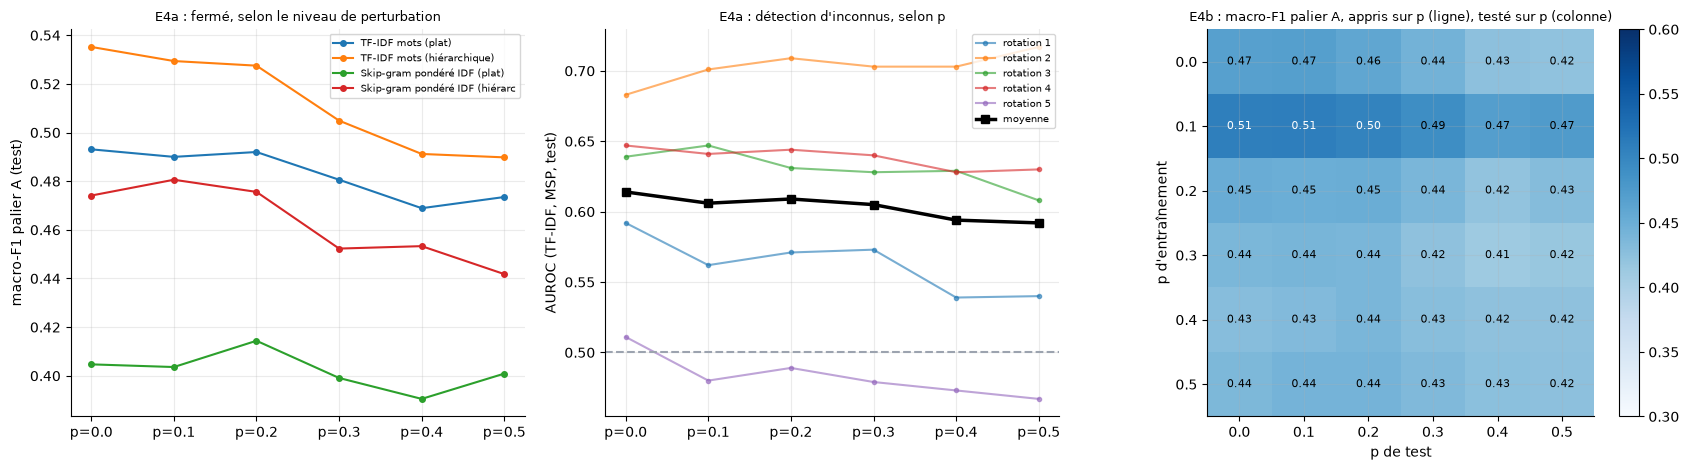

In [117]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8), gridspec_kw={"width_ratios": [1, 1, 1.1]})
for _, r in e4a.iterrows(): ax[0].plot(range(6), [r[f"p={v / 10}"] for v in range(6)], marker="o", ms=4, label=r["modèle"][:30])
ax[0].set_xticks(range(6)); ax[0].set_xticklabels([f"p={v / 10}" for v in range(6)]); ax[0].set_ylabel("macro-F1 palier A (test)"); ax[0].set_title("E4a : fermé, selon le niveau de perturbation", fontsize=9.5); ax[0].legend(fontsize=7); ax[0].grid(alpha=.25)
for rot in range(5): ax[1].plot(range(6), [e4b_open.iloc[rot][f"p={v / 10}"] for v in range(6)], marker="o", ms=3, alpha=.6, label=f"rotation {rot + 1}")
ax[1].plot(range(6), [e4b_open.loc["moyenne"][f"p={v / 10}"] for v in range(6)], "k-", lw=2.5, marker="s", label="moyenne"); ax[1].axhline(.5, color=GREY, ls="--"); ax[1].set_xticks(range(6)); ax[1].set_xticklabels([f"p={v / 10}" for v in range(6)])
ax[1].set_ylabel("AUROC (TF-IDF, MSP, test)"); ax[1].set_title("E4a : détection d'inconnus, selon p", fontsize=9.5); ax[1].legend(fontsize=7); ax[1].grid(alpha=.25)
im = ax[2].imshow(Mx, cmap="Blues", vmin=.3, vmax=.6); ax[2].set_xticks(range(6)); ax[2].set_xticklabels([f"{v / 10}" for v in range(6)]); ax[2].set_yticks(range(6)); ax[2].set_yticklabels([f"{v / 10}" for v in range(6)]); ax[2].set_xlabel("p de test"); ax[2].set_ylabel("p d'entraînement")
for i in range(6):
    for j in range(6): ax[2].text(j, i, f"{Mx[i, j]:.2f}", ha="center", va="center", fontsize=8, color="white" if Mx[i, j] > .5 else "black")
ax[2].set_title("E4b : macro-F1 palier A, appris sur p (ligne), testé sur p (colonne)", fontsize=9); plt.colorbar(im, ax=ax[2], fraction=0.04); plt.tight_layout(); fig.savefig(DIRS["figures"] / "08_E4.png", dpi=140); plt.show()

**Lecture (termes techniques).**
- **La figure de gauche** montre la décroissance lente et à peu près régulière avec p (plat) ; **celle du centre** l'AUROC moyen (trait noir épais) qui passe de 0,61 à 0,59, avec une rotation qui monte et deux qui descendent ; **celle de droite** la matrice entraînement × test.
- **Colonnes (tester sur un p de plus en plus grand)** : toutes les lignes **baissent de 0,02 à 0,05** de gauche à droite : tester sur des logs plus perturbés est **toujours** plus dur, quel que soit l'entraînement.
- **Lignes (apprendre sur un p donné)** : l'entraînement à p = 0,1 donne les **meilleurs** résultats partout (0,51 sur les p faibles) ; p = 0 donne 0,47, p = 0,2 donne 0,45, et les p élevés tournent autour de 0,43 à 0,44. **Ce n'est pas monotone** (p = 0,1 meilleur que p = 0, lui-même meilleur que p = 0,2), signe que **l'échantillon d'entraînement (333 logs par classe, tirés d'un nombre limité de gabarits) pèse plus que p** : **le bruit d'échantillonnage est de l'ordre de ±0,03**. **On n'en tire donc aucune conclusion sur le « meilleur p d'entraînement »**.
- **Un point plus solide** : le profil de la ligne p = 0 baisse de **0,046** (0,468 → 0,422), celui de la ligne p = 0,5 de seulement **0,011** (0,436 → 0,425). **S'entraîner sur des logs perturbés aplatit la courbe** : on perd un peu de performance sur les logs propres, on perd moins quand ils sont perturbés. C'est le principe de l'**entraînement adversarial** (étape 9), à vérifier avec plus de rigueur.
- **E5 (transfert vers CDS)** : **toujours en suspens**, le fichier n'est pas dans l'archive (1.5). Le fichier est **à demander aux auteurs** ; **aucune conclusion ne sera tirée de E5** d'ici là.

## 8.5 Le modèle à caractères (hypothèse H6)

On entraîne **une fois** un modèle TF-IDF de **n-grammes de caractères (3 à 5 lettres)** à 30 classes (même régression logistique, même C), on le **sauvegarde** et on le compare. Rappel : **mesure exploratoire**, non figée avant le test.

In [118]:
from sklearn.pipeline import make_pipeline
def char_model(seed=42):
    cfg = {"rep": "char35", "closed": True, "seed": seed, "C": C_BEST, "data_id": DATA_ID, "splits": SPLITS_SHA, "protocol": "s8v1"}
    def train(): return make_pipeline(TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=3, max_features=300000, sublinear_tf=True, dtype=np.float32), LogisticRegression(C=C_BEST, max_iter=200)).fit(tr_text, ytr)
    return load_or_train(f"os_char35_closed_s{seed}", train, cfg, models_dir=DIRS["models"])
t0 = time.perf_counter(); cm_char = char_model(); print(f"Modèle à caractères prêt en {time.perf_counter() - t0:.0f} s")
pc = np.array([CI[c] for c in cm_char.predict(te_text)]); print(f"Sans attaque (test) : macro-F1 palier A = {f1A(pc, np.ones(len(yte_i), bool)):.4f} | 30 classes = {float(f1_score(yte_i, pc, average='macro')):.4f}  (TF-IDF mots : 0,4832 / 0,4593)")

[os_char35_closed_s42] modèle trouvé (config identique) -> chargement, pas de réentraînement.


Modèle à caractères prêt en 1 s


Sans attaque (test) : macro-F1 palier A = 0.5146 | 30 classes = 0.5234  (TF-IDF mots : 0,4832 / 0,4593)


**Lecture.** Sans attaque, sur le test, le modèle à caractères obtient **0,5146** sur le palier A et **0,5234** en 30 classes, **mieux que TF-IDF mots** (0,4832 et 0,4593) et que Skip-gram (0,4027). **C'est un constat à ne pas surinterpréter** : un modèle de plus a été essayé après avoir vu le test ; avec 45 gabarits de test et des intervalles de confiance de ±0,1, un écart de 0,03 reste **dans le bruit**. À l'étape 5 (validation, 36 gabarits), les caractères étaient aussi les meilleurs en valeur centrale (0,5050 contre 0,4745), sans différence statistiquement réelle : le constat est **cohérent**, il n'est **pas démontré**.

## 8.6 Les attaques : trois attaques × trois intensités × trois modèles

In [119]:
STRENGTH = {"typos": [0.05, 0.15, 0.30], "homoglyphs": [0.05, 0.15, 0.30], "padding": [0.10, 0.30, 1.00]}
mw = closed_model("tfidf"); ms = closed_model("sg_idf")
def predict_idx(model, texts, kind):
    if kind == "char": return np.array([CI[c] for c in model.predict(texts)])
    return np.array([CI[c] for c in model.scores(texts)["pred_flat"]])
MODELS8 = {"TF-IDF mots": (mw, "word"), "Skip-gram pondéré IDF": (ms, "word"), "TF-IDF caractères 3-5": (cm_char, "char")}
clean_f1 = {nm: f1A(predict_idx(m, te_text, k), np.ones(len(yte_i), bool)) for nm, (m, k) in MODELS8.items()}
CACHE8 = DIRS["results"] / "cache_step8"; CACHE8.mkdir(exist_ok=True); res8 = []; t_all = time.perf_counter()
for atk, rates in STRENGTH.items():
    for lvl, rate in zip(("faible", "moyenne", "forte"), rates):
        ck = hashlib.sha256(json.dumps([atk, rate, DATA_ID, SPLITS_SHA, ATT_HASH, OPEN_HASH, MODULE_HASH, VEC_HASH, "s8v1"]).encode()).hexdigest()[:16]; cj = CACHE8 / f"{ck}.json"
        if cj.exists(): res8 += json.loads(cj.read_text()); continue
        att_text = [ATTACKS[atk](t, rate, seed=i) for i, t in enumerate(te_text)]; part = []
        for nm, (m, k) in MODELS8.items():
            f = f1A(predict_idx(m, att_text, k), np.ones(len(yte_i), bool)); part.append({"attaque": atk, "intensité": lvl, "taux": rate, "modèle": nm, "F1 propre": clean_f1[nm], "F1 attaqué": f, "baisse relative": (clean_f1[nm] - f) / clean_f1[nm]})
        cj.write_text(json.dumps(part)); res8 += part
        print(f"  {atk:<11} {lvl:<8} ({rate})  " + "  ".join(f"{p['modèle'][:12]} {p['F1 attaqué']:.3f}" for p in part), flush=True)
r8 = pd.DataFrame(res8); print(f"Durée : {time.perf_counter() - t_all:.0f} s")
piv = r8.pivot_table(index=["attaque", "modèle"], columns="intensité", values="baisse relative")[["faible", "moyenne", "forte"]].round(3); print("\nBaisse relative de la macro-F1 (palier A) :"); print(piv.to_string())
r8.to_csv(DIRS["results"] / "step8_attacks_closed.csv", index=False)

[os_tfidf_closed_s42] modèle trouvé (config identique) -> chargement, pas de réentraînement.
[os_sg_idf_closed_s42] modèle trouvé (config identique) -> chargement, pas de réentraînement.


Durée : 0 s

Baisse relative de la macro-F1 (palier A) :
intensité                         faible  moyenne  forte
attaque    modèle                                       
homoglyphs Skip-gram pondéré IDF   0.044    0.153  0.335
           TF-IDF caractères 3-5   0.016    0.051  0.106
           TF-IDF mots             0.026    0.085  0.215
padding    Skip-gram pondéré IDF   0.013    0.084  0.335
           TF-IDF caractères 3-5   0.023    0.024  0.144
           TF-IDF mots             0.011    0.013  0.125
typos      Skip-gram pondéré IDF   0.004    0.017  0.044
           TF-IDF caractères 3-5   0.007    0.019  0.040
           TF-IDF mots             0.013    0.037  0.078


**Lecture (termes techniques).** Baisse relative de la macro-F1 du palier A (le critère : ≤ 5 % bonne, ≤ 10 % acceptable, > 25 % fragile).

| Attaque | Intensité | TF-IDF mots | Skip-gram | TF-IDF caractères |
|---|---|---|---|---|
| Typos | faible (5 %) | 1,3 % | 0,4 % | 0,7 % |
| | moyenne (15 %) | 3,7 % | 1,7 % | 1,9 % |
| | forte (30 %) | 7,8 % | 4,4 % | 4,0 % |
| Homoglyphes | faible (5 %) | 2,6 % | 4,4 % | 1,6 % |
| | moyenne (15 %) | 8,5 % | 15,3 % | 5,1 % |
| | forte (30 %) | **21,5 %** | **33,5 %** | 10,6 % |
| Padding | faible (+10 % de mots) | 1,1 % | 1,3 % | 2,3 % |
| | moyenne (+30 %) | 1,3 % | 8,4 % | 2,4 % |
| | forte (+100 %) | 12,5 % | **33,5 %** | 14,4 % |

- **Les typos sont l'attaque la moins dangereuse** : même à 30 % des mots touchés, la perte reste sous 8 % pour tous. **Bonne ou acceptable partout.** (Les mots de 4 lettres ou plus seulement sont modifiés.)
- **Les homoglyphes sont l'attaque la plus efficace** contre les mots : à 30 %, **TF-IDF mots perd 21,5 %** et **Skip-gram 33,5 %** (**fragile**). Pour un humain, le log est **inchangé** ; pour la machine, il n'y a plus de mot reconnaissable. Ce résultat est **cohérent avec le mécanisme** (un mot touché disparaît du vocabulaire).
- **H6 confirmée pour les homoglyphes** : les caractères perdent **10,6 %** contre 21,5 % (mots) : **la perte est divisée par deux**. **Pour les typos, l'avantage est faible** (4,0 % contre 7,8 %). **Pour le padding, H6 est réfutée** : à +100 % de mots ajoutés, les caractères perdent **14,4 %**, plus que les mots (12,5 %) : les mots anodins ajoutés produisent autant de n-grammes que les vrais mots.
- **Le padding est inoffensif jusqu'à +30 %** pour les mots (1,3 %), puis coûte 12,5 % à +100 % ; **Skip-gram y est très fragile** (33,5 %) : la moyenne de vecteurs mélange les mots ajoutés avec les vrais, sans pondération qui les écarte.
- **Classement de robustesse** : **TF-IDF caractères** est le plus résistant aux homoglyphes et aux typos, **TF-IDF mots** reste correct sauf homoglyphes forts, **Skip-gram est le plus fragile**. Les **résultats sont à lire avec prudence** : ce sont des baisses relatives sur un niveau de départ déjà bas (0,40 à 0,51) et sur **une** réalisation aléatoire de chaque attaque (une graine).

In [120]:
rows = []
for atk, rates in STRENGTH.items():
    for lvl, rate in zip(("faible", "moyenne", "forte"), rates):
        att_text = [ATTACKS[atk](t, rate, seed=i) for i, t in enumerate(te_text)]; au = []; rej = []
        for rot in range(5):
            m = load_frozen_os("tfidf", rot, 42); sc = m.scores(att_text); known_t = ~np.isin(yte, ROTATIONS[rot]); sv = m.scores(va_text)
            au.append(float(open_metrics(sc["msp"], known_t)["auroc"])); tau = float(np.quantile(sv["msp"][~np.isin(yva, ROTATIONS[rot])], 0.05)); rej.append(float((sc["msp"][known_t] < tau).mean()))
        rows.append({"attaque": atk, "intensité": lvl, "AUROC (5 rotations)": round(float(np.mean(au)), 4), "connus rejetés à tort (seuil val)": round(float(np.mean(rej)), 4)})
base_au = float(np.mean([open_metrics(ST[r]["msp"], ~np.isin(yte, ROTATIONS[r]))["auroc"] for r in range(5)])); print(f"Sans attaque : AUROC {base_au:.4f}")
op8 = pd.DataFrame(rows); print(op8.to_string(index=False)); op8.to_csv(DIRS["results"] / "step8_attacks_open.csv", index=False)

Sans attaque : AUROC 0.6029
   attaque intensité  AUROC (5 rotations)  connus rejetés à tort (seuil val)
     typos    faible               0.5990                             0.1285
     typos   moyenne               0.5920                             0.1371
     typos     forte               0.5822                             0.1489
homoglyphs    faible               0.5945                             0.1397
homoglyphs   moyenne               0.5803                             0.1707
homoglyphs     forte               0.5619                             0.2249
   padding    faible               0.6052                             0.1303
   padding   moyenne               0.6110                             0.1428
   padding     forte               0.5982                             0.1887


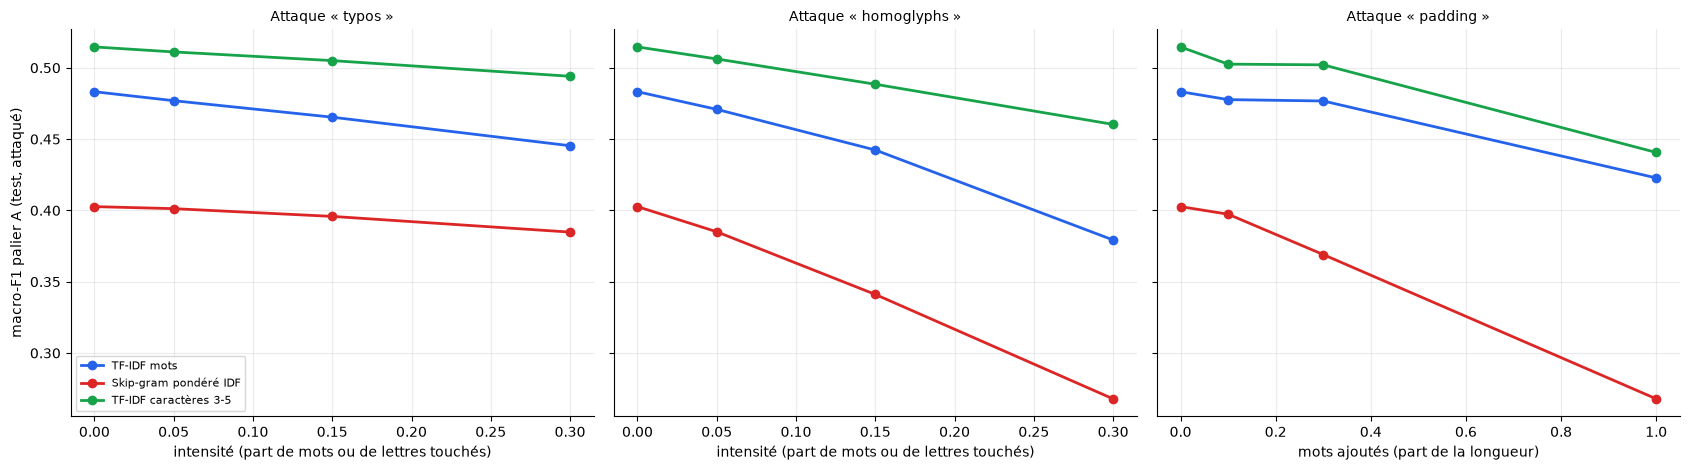

In [121]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8), sharey=True); cols = {"TF-IDF mots": BLUE, "Skip-gram pondéré IDF": RED, "TF-IDF caractères 3-5": "#16a34a"}
for a, atk in zip(ax, STRENGTH):
    for nm in MODELS8:
        d = r8[(r8.attaque == atk) & (r8["modèle"] == nm)]; a.plot([0] + list(d["taux"]), [clean_f1[nm]] + list(d["F1 attaqué"]), marker="o", color=cols[nm], label=nm, lw=2)
    a.set_title(f"Attaque « {atk} »", fontsize=10); a.set_xlabel("intensité (part de mots ou de lettres touchés)" if atk != "padding" else "mots ajoutés (part de la longueur)"); a.grid(alpha=.25)
ax[0].set_ylabel("macro-F1 palier A (test, attaqué)"); ax[0].legend(fontsize=8); plt.tight_layout(); fig.savefig(DIRS["figures"] / "08_attaques.png", dpi=140); plt.show()

**Lecture de la figure.** Une courbe qui descend **peu** = modèle robuste. Pour les **typos** (gauche), les trois courbes descendent doucement. Pour les **homoglyphes** (centre), Skip-gram (rouge) **plonge**, TF-IDF mots (bleu) baisse clairement, TF-IDF caractères (vert) tient mieux. Pour le **padding** (droite), les courbes **bleue et verte restent presque plates jusqu'à +30 %**, puis chutent à +100 %, alors que Skip-gram descend sans arrêt.

**Lecture du tableau en ouvert (TF-IDF, MSP, 5 rotations).** Sans attaque, l'AUROC est de **0,6029**.
- **Typos** : 0,599 / 0,592 / 0,582 : une baisse faible (**−0,021** à l'intensité forte).
- **Homoglyphes** : 0,5945 / 0,5803 / **0,5619** (**−0,041**) ; **les connus rejetés à tort** (au seuil calé en validation) passent de 13 % à **22,5 %** : l'attaque **fait passer des logs légitimes pour inconnus**. Dans un SIEM, ce serait une **cascade de fausses alertes** (« événement inconnu » à tort).
- **Padding** : l'AUROC **ne bouge pas** (0,605 / 0,611 / 0,598), mais les connus rejetés à tort montent à 18,9 % à +100 %.

**Critère de robustesse**. Sur la classification fermée, TF-IDF caractères est **acceptable partout sauf aux extrêmes** (homoglyphes forts 10,6 %, padding fort 14,4 %), TF-IDF mots est **acceptable** sauf aux homoglyphes forts (21,5 %) et au padding fort (12,5 %), Skip-gram est **fragile** à deux attaques fortes. **En ouvert**, la détection d'inconnus, déjà médiocre (AUROC 0,60), **ne se dégrade que peu** sous attaque : on ne peut pas perdre beaucoup quand il n'y a presque rien à perdre, ce qui est un **mauvais signe déguisé en bon**.

**Limites (dites honnêtement).** (1) Les trois attaques sont **non adaptatives** et déterministes (une seule graine par intensité) ; une attaque ciblée contre le modèle serait plus dure. (2) Le modèle à caractères est **exploratoire**. (3) L'encodeur Transformer n'est **pas** attaqué à cette étape : sa mesure sous attaque est en **9.11**, sur la rotation 1. (4) Les chiffres partent d'un niveau bas et sont **relatifs**. (5) Les rotations d'inconnus ne sont attaquées qu'avec la graine 42.

**Registre (suite).**

| N° | Affirmation | Source | Niveau |
|---|---|---|---|
| V50 | E4a (test, TF-IDF plat, palier A) : 0,493 (p = 0) → 0,474 (p = 0,5) ; hiérarchique 0,535 → 0,490 ; AUROC d'inconnus moyen 0,614 → 0,592 : H3 faiblement confirmée | Calcul | calcul |
| V51 | E4b : la matrice entraînement × test est dominée par le bruit d'échantillonnage (±0,03) ; la ligne p = 0 baisse de 0,046, la ligne p = 0,5 de 0,011 | Calcul | calcul (bruit) |
| V52 | TF-IDF caractères 3-5 (exploratoire) : 0,5146 (palier A, test) contre 0,4832 (mots) et 0,4027 (Skip-gram) | Calcul | calcul (non figé avant le test) |
| V53 | Baisse relative de la macro-F1 sous attaque : homoglyphes forts 21,5 % (mots), 33,5 % (Skip-gram), 10,6 % (caractères) ; padding fort 12,5 % / 33,5 % / 14,4 % ; typos fortes 7,8 % / 4,4 % / 4,0 % | Calcul | calcul |
| V54 | H6 confirmée pour les homoglyphes (perte divisée par deux), faible pour les typos, réfutée pour le padding fort | Calcul | calcul |
| V55 | Sous homoglyphes forts, l'AUROC d'inconnus passe de 0,603 à 0,562 et les connus rejetés à tort de 13 % à 22,5 % | Calcul | calcul |
| V56 | E5 (transfert vers CDS) : non réalisée, fichier CDS absent de l'archive | — | en suspens |

**Bilan de l'étape 8 (modèles linéaires).** **Aucun modèle n'est robuste à tout** : les **homoglyphes** (invisibles pour un humain) sont l'attaque la plus efficace contre les représentations par mots, les **n-grammes de caractères** divisent la perte par deux sur cette attaque (H6), le **padding** à forte dose gêne tout le monde et **Skip-gram est le plus fragile**. La dégradation avec p est **faible et régulière** (H3). La détection d'inconnus, déjà faible, **ne s'effondre pas** sous attaque, mais **génère plus de fausses alertes** (jusqu'à 22,5 % de connus rejetés). La **parade la plus naturelle** est une **normalisation des homoglyphes** (déjà testée dans le module) et un **entraînement sur des textes attaqués** : c'est l'étape 9.

**Prochaine étape.** Étape 9 : améliorations (normalisation des homoglyphes, entraînement adversarial, calibration), avec sauvegarde des modèles finaux. L'encodeur Transformer est intégré en 9.11.

---
# Étape 9 : Amélioration (parades, entraînement adversarial, calibration)

**Pourquoi cette étape existe.** Les étapes 7 et 8 ont montré trois faiblesses : (1) les **homoglyphes** font perdre jusqu'à 21,5 % de F1 aux modèles à mots, (2) le **padding** fort en fait perdre 12 à 14 %, (3) la **confiance** du modèle est **mal calibrée** (ECE de 0,15) et son **seuil de rejet** ne se transporte pas. On essaie ici des remèdes, **choisis d'après la validation** (jamais d'après le test), puis on **sauvegarde les modèles finaux**.

**Concepts.**
- **Parade** : une défense simple, ici une **normalisation** appliquée avant la prédiction.
- **Entraînement adversarial** : on **ajoute à l'entraînement** des textes attaqués (avec leur vraie étiquette), pour que le modèle apprenne à reconnaître un log même modifié. En simple : on s'entraîne contre un adversaire avant de le rencontrer.
- **Calibration par température** : on divise les scores du modèle par un nombre $T$ (appris sur la validation) avant le *softmax*. $T>1$ rend le modèle **moins sûr de lui**, sans changer le classement de ses réponses.
- **Attaque « jamais vue »** : on retire une attaque de l'entraînement et on la teste quand même ; elle mesure si le modèle a appris à **se défendre en général** ou seulement contre ce qu'il a déjà rencontré.

## 9.1 Règles écrites avant les chiffres

In [122]:
from tp2_attacks import robust_tokens
RULES9 = """
Parades candidates (chacune appliquée à TF-IDF mots et à TF-IDF caractères, 30 classes) :
  P0 aucune (modèle de l'étape 8) ; P1 normalisation des homoglyphes avant la prédiction (aucun réentraînement) ;
  P2 entraînement adversarial : l'entraînement reçoit, en plus des logs propres, une copie attaquée (une attaque et une intensité tirées au hasard par log) ;
  P3 P1 + P2.
Sélection : sur la VALIDATION attaquée (jamais sur le test) : on retient la parade qui minimise la baisse relative MOYENNE sur les 9 attaques, à condition que la perte de F1 propre reste <= 0,01 ; à égalité (0,01), la plus simple.
Le test sert à RAPPORTER le résultat de toutes les parades, pas à choisir.
Entraînement adversarial « honnête » : on teste aussi la généralisation à une attaque JAMAIS vue à l'entraînement (laisser une attaque de côté).
Calibration : mise à l'échelle par température (un seul nombre T) calée sur la validation, par modèle ; on mesure ECE, AUROC et rejet des connus avant / après.
"""
print(RULES9)


Parades candidates (chacune appliquée à TF-IDF mots et à TF-IDF caractères, 30 classes) :
  P0 aucune (modèle de l'étape 8) ; P1 normalisation des homoglyphes avant la prédiction (aucun réentraînement) ;
  P2 entraînement adversarial : l'entraînement reçoit, en plus des logs propres, une copie attaquée (une attaque et une intensité tirées au hasard par log) ;
  P3 P1 + P2.
Sélection : sur la VALIDATION attaquée (jamais sur le test) : on retient la parade qui minimise la baisse relative MOYENNE sur les 9 attaques, à condition que la perte de F1 propre reste <= 0,01 ; à égalité (0,01), la plus simple.
Le test sert à RAPPORTER le résultat de toutes les parades, pas à choisir.
Entraînement adversarial « honnête » : on teste aussi la généralisation à une attaque JAMAIS vue à l'entraînement (laisser une attaque de côté).
Calibration : mise à l'échelle par température (un seul nombre T) calée sur la validation, par modèle ; on mesure ECE, AUROC et rejet des connus avant / après.



**Pourquoi la sélection se fait sur la validation.** Le test a déjà été ouvert (étape 7) et utilisé pour **mesurer** la robustesse (étape 8). Si on choisissait aussi la parade sur le test, les chiffres rapportés seraient **optimistes**. On construit donc des textes attaqués de **validation**, avec des **graines différentes** de celles du test, et on y applique la règle. Le test ne sert qu'à **rapporter** le résultat de toutes les parades.

## 9.2 Les textes attaqués de validation et de test

In [123]:
YV_A = mask_A_rows
def f1A_val(pred_i): return float(f1_score(yva_i[YV_A], pred_i[YV_A], average="macro", labels=np.where(tierA)[0]))
def f1A_test(pred_i): return float(f1_score(yte_i[tierA_te], pred_i[tierA_te], average="macro", labels=np.where(tierA)[0]))
COND = [(atk, lvl, rate) for atk, rates in STRENGTH.items() for lvl, rate in zip(("faible", "moyenne", "forte"), rates)]
t0 = time.perf_counter()
va_att = {(a, l): [ATTACKS[a](t, r, seed=100000 + i) for i, t in enumerate(va_text)] for a, l, r in COND}
te_att = {(a, l): [ATTACKS[a](t, r, seed=i) for i, t in enumerate(te_text)] for a, l, r in COND}                 # mêmes graines qu'à l'étape 8
print(f"{len(COND)} conditions x 2 jeux d'e-mails attaqués construits en {time.perf_counter() - t0:.0f} s")

9 conditions x 2 jeux d'e-mails attaqués construits en 7 s


**Lecture.** Neuf conditions (3 attaques × 3 intensités) sont appliquées aux 23 940 logs de validation (graines 100 000 et plus) et de test (graines de l'étape 8).

## 9.3 Les modèles à entraînement adversarial

In [124]:
rnd9 = random.Random(CONFIG["seed"]); adv_txt = []; adv_kind = []
for i, t in enumerate(tr_text):
    a, l, r = COND[rnd9.randrange(len(COND))]; adv_txt.append(ATTACKS[a](t, r, seed=200000 + i)); adv_kind.append(a)
aug_text = list(tr_text) + adv_txt; aug_y = np.concatenate([ytr, ytr]); kinds_arr = np.array(["clean"] * len(tr_text) + adv_kind)
print(f"Jeu d'entraînement augmenté : {len(aug_text):,} logs (propres {len(tr_text):,} + attaqués {len(adv_txt):,}) ; part de chaque attaque :", pd.Series(adv_kind).value_counts(normalize=True).round(3).to_dict())
def adv_model(name, analyzer, char=False, exclude=None):
    cfg = {"name": name, "char": char, "exclude": exclude, "C": C_BEST, "data_id": DATA_ID, "splits": SPLITS_SHA, "att": ATT_HASH, "protocol": "s9v1"}
    def train():
        m = kinds_arr != exclude if exclude else np.ones(len(aug_text), bool); txt = [t for t, k in zip(aug_text, m) if k]; y = aug_y[m]
        vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=3, max_features=300000, sublinear_tf=True, dtype=np.float32) if char else TfidfVectorizer(analyzer=analyzer, min_df=2, sublinear_tf=True, dtype=np.float32)
        return make_pipeline(vec, LogisticRegression(C=C_BEST, max_iter=200)).fit(txt, y)
    return load_or_train(name, train, cfg, models_dir=DIRS["models"])
t0 = time.perf_counter()
m_word_adv = adv_model("adv_word", tokenize); m_word_adv_rob = adv_model("adv_word_robust", robust_tokens); m_char_adv = adv_model("adv_char", None, char=True)
LOAO = {a: adv_model(f"adv_word_sans_{a}", tokenize, exclude=a) for a in STRENGTH}
print(f"Modèles adversariaux prêts en {time.perf_counter() - t0:.0f} s")

Jeu d'entraînement augmenté : 119,880 logs (propres 59,940 + attaqués 59,940) ; part de chaque attaque : {'padding': 0.335, 'typos': 0.334, 'homoglyphs': 0.33}
[adv_word] modèle trouvé (config identique) -> chargement, pas de réentraînement.
[adv_word_robust] modèle trouvé (config identique) -> chargement, pas de réentraînement.
[adv_char] modèle trouvé (config identique) -> chargement, pas de réentraînement.


[adv_word_sans_typos] modèle trouvé (config identique) -> chargement, pas de réentraînement.
[adv_word_sans_homoglyphs] modèle trouvé (config identique) -> chargement, pas de réentraînement.
[adv_word_sans_padding] modèle trouvé (config identique) -> chargement, pas de réentraînement.
Modèles adversariaux prêts en 1 s


**Lecture.** Le jeu d'entraînement est **doublé** : 59 940 logs propres + 59 940 copies attaquées (une attaque et une intensité tirées au hasard par log : 33,5 % de padding, 33,4 % de typos, 33,0 % d'homoglyphes). On entraîne : un modèle à mots (`adv_word`), le même avec normalisation des homoglyphes intégrée (`adv_word_robust`), un modèle à caractères (`adv_char`), et **trois modèles à mots auxquels on retire une attaque** (`adv_word_sans_*`) pour la section 9.6. Tous sont **sauvegardés** avec `load_or_train` (215 secondes au total).

## 9.4 Les quatre parades : validation (sélection) puis test (rapport)

**Le critère.** Pour chaque modèle, la parade retenue est celle qui **minimise la baisse relative moyenne** sur les 9 attaques, à condition que la **perte de F1 propre** ne dépasse pas **0,01** ; à égalité (à 0,01 près), **la plus simple**.

In [125]:
def pred_pipe(m, texts, pre=None): return np.array([CI[c] for c in m.predict([pre(t) for t in texts] if pre else texts)])
def pred_os(m, texts, pre=None): return np.array([CI[c] for c in m.scores([pre(t) for t in texts] if pre else texts)["pred_flat"]])
CANDS = {  # modèle de base -> {parade: (fonction de prédiction)}
    "TF-IDF mots": {"P0 aucune": lambda T: pred_os(mw, T), "P1 homoglyphes normalisés": lambda T: pred_os(mw, T, unconfuse), "P2 entraînement adversarial": lambda T: pred_pipe(m_word_adv, T), "P3 P1 + P2": lambda T: pred_pipe(m_word_adv_rob, T)},
    "TF-IDF caractères": {"P0 aucune": lambda T: pred_pipe(cm_char, T), "P1 homoglyphes normalisés": lambda T: pred_pipe(cm_char, T, unconfuse), "P2 entraînement adversarial": lambda T: pred_pipe(m_char_adv, T), "P3 P1 + P2": lambda T: pred_pipe(m_char_adv, [unconfuse(t) for t in T])},
}
def run_matrix(fn, clean_texts, att_sets, f1fn):
    clean = f1fn(fn(clean_texts)); drops = {(a, l): (clean - f1fn(fn(att_sets[(a, l)]))) / clean for a, l, _ in COND}; return clean, drops
rows = []; mats = {}; t0 = time.perf_counter()
for base, cs in CANDS.items():
    for par, fn in cs.items():
        cv, dv = run_matrix(fn, va_text, va_att, f1A_val); ct, dt = run_matrix(fn, te_text, te_att, f1A_test); mats[(base, par)] = (cv, dv, ct, dt)
        rows.append({"modèle": base, "parade": par, "F1 propre val": round(cv, 4), "baisse moyenne val": round(float(np.mean(list(dv.values()))), 4), "pire baisse val": round(float(max(dv.values())), 4),
                     "F1 propre test": round(ct, 4), "baisse moyenne test": round(float(np.mean(list(dt.values()))), 4), "pire baisse test": round(float(max(dt.values())), 4)})
sel9 = pd.DataFrame(rows); print(sel9.to_string(index=False)); sel9.to_csv(DIRS["results"] / "step9_parades.csv", index=False); print(f"Durée : {time.perf_counter() - t0:.0f} s")
CHOSEN = {}
for base in CANDS:
    d = sel9[sel9["modèle"] == base].copy(); p0 = float(d[d.parade == "P0 aucune"]["F1 propre val"].iloc[0]); ok = d[d["F1 propre val"] >= p0 - 0.01]
    best = ok.sort_values(["baisse moyenne val", "parade"]).iloc[0]; same = ok[ok["baisse moyenne val"] <= best["baisse moyenne val"] + 0.01].sort_values("parade").iloc[0]; CHOSEN[base] = same["parade"]
print("\nParade retenue d'après la VALIDATION (règle écrite en 9.1) :", CHOSEN)

           modèle                      parade  F1 propre val  baisse moyenne val  pire baisse val  F1 propre test  baisse moyenne test  pire baisse test
      TF-IDF mots                   P0 aucune         0.4344              0.0547           0.1670          0.4832               0.0671            0.2152
      TF-IDF mots   P1 homoglyphes normalisés         0.4344              0.0275           0.1181          0.4832               0.0309            0.1251
      TF-IDF mots P2 entraînement adversarial         0.4340              0.0275           0.0759          0.4797               0.0234            0.0715
      TF-IDF mots                  P3 P1 + P2         0.4243              0.0069           0.0517          0.4763               0.0057            0.0652
TF-IDF caractères                   P0 aucune         0.4529              0.0109           0.1118          0.5146               0.0478            0.1438
TF-IDF caractères   P1 homoglyphes normalisés         0.4529              0.0145  

**Lecture (termes techniques).**

*TF-IDF mots.*
- **P0 (aucune)** : baisse moyenne de **0,0547** en validation et **0,0671** au test (pire cas 21,5 %).
- **P1 (homoglyphes normalisés)** : la baisse moyenne **tombe de moitié** (0,0275 validation, 0,0309 test) **sans toucher au F1 propre** (0,4344 et 0,4832). La parade **annule exactement** l'attaque par homoglyphes (baisse de 0,000 à toutes les intensités) et ne change rien aux autres.
- **P2 (entraînement adversarial)** : baisse moyenne 0,0275 (validation), **0,0234** (test), pour un F1 propre presque inchangé (0,4340 ; 0,4797).
- **P3 (les deux)** : baisse moyenne **0,0069** en validation, **0,0057** au test ; **pire cas de 6,5 %** (typos forts). **C'est de loin la meilleure en robustesse.** Mais sa perte de F1 propre en **validation est de 0,0101** (0,4344 → 0,4243) : **un dixième de millième au-dessus de la tolérance de 0,01**. **La règle l'écarte**, et nous nous y tenons. Au test, la perte propre est de **0,007** (0,4832 → 0,4763).

*TF-IDF caractères.*
- **P0** : baisse moyenne 0,0109 (validation) mais **0,0478** (test), pire cas 14,4 % (padding fort).
- **P2** : baisse moyenne 0,0103 (validation), **0,0173** (test), pire cas **3,6 %**. Le F1 propre de validation **monte** de 0,4529 à **0,4902**, mais celui du test **baisse** de 0,5146 à 0,4919 : **l'effet de l'augmentation sur le niveau propre change de signe entre validation et test**, comme pour d'autres résultats des étapes précédentes (peu de gabarits).
- **P3** : baisse moyenne 0,0015 (validation), **0,0109** (test) : la meilleure ; pire cas 3,6 %.

**Parades retenues par la règle** : **TF-IDF mots → P1** (normalisation des homoglyphes) ; **TF-IDF caractères → P0 (aucune)**. *Pour les caractères, la règle choisit de ne rien faire* : la baisse moyenne en validation (0,0109) était déjà à moins de 0,01 de la meilleure (0,0015), donc « à égalité » ; elle **ignore le pire cas** (11,2 % en validation, 14,4 % au test). **C'est une faiblesse de notre règle**, qu'on dit : une tolérance de 0,01 sur une **moyenne** laisse passer un modèle fragile à **une** attaque. Le texte plus bas la corrige **sans changer la décision écrite**, en donnant aussi les chiffres de P3.

parade                                  P1 homoglyphes normalisés  aucune
modèle            attaque                                                
TF-IDF caractères homoglyphs (faible)                         NaN   0.016
                  homoglyphs (forte)                          NaN   0.106
                  homoglyphs (moyenne)                        NaN   0.051
                  padding (faible)                            NaN   0.023
                  padding (forte)                             NaN   0.144
                  padding (moyenne)                           NaN   0.024
                  typos (faible)                              NaN   0.007
                  typos (forte)                               NaN   0.040
                  typos (moyenne)                             NaN   0.019
TF-IDF mots       homoglyphs (faible)                       0.000   0.026
                  homoglyphs (forte)                        0.000   0.215
                  homoglyphs (moyenne)

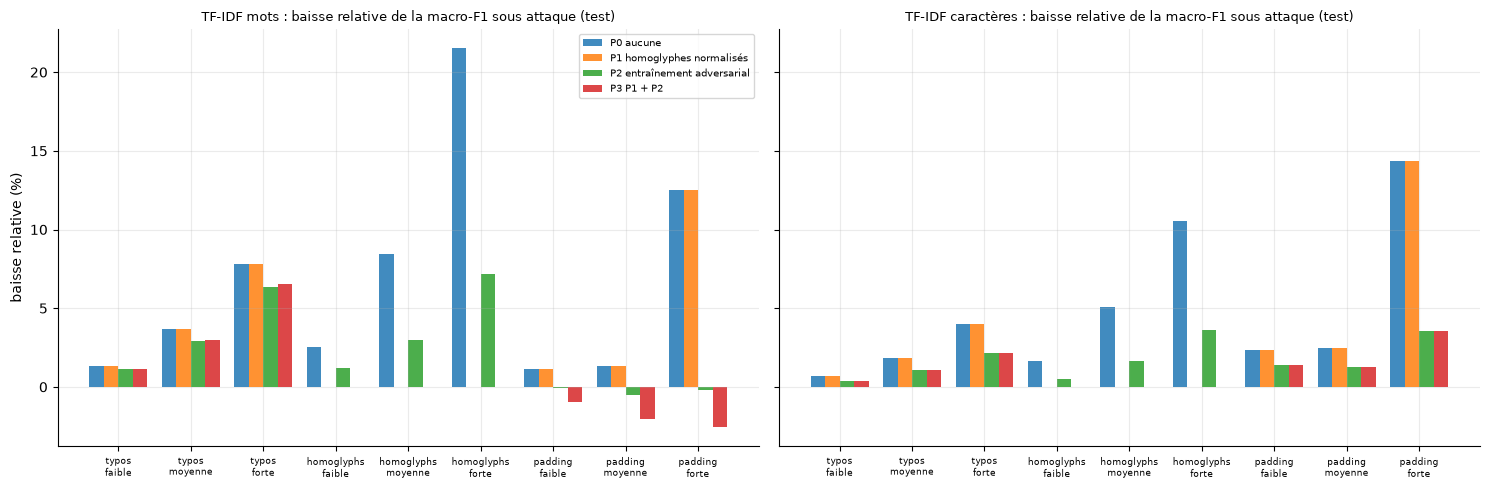

In [126]:
rows = []
for base in CANDS:
    for par in ("P0 aucune", CHOSEN[base]):
        cv, dv, ct, dt = mats[(base, par)]
        for a, l, r in COND: rows.append({"modèle": base, "parade": par if par != "P0 aucune" else "aucune", "attaque": f"{a} ({l})", "baisse test": round(dt[(a, l)], 3)})
dtl = pd.DataFrame(rows).pivot_table(index=["modèle", "attaque"], columns="parade", values="baisse test"); print(dtl.round(3).to_string())
fig, ax = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
for a_, base in zip(ax, CANDS):
    labs = [f"{a}\n{l}" for a, l, _ in COND]; x = np.arange(len(COND)); w = .2
    for j, par in enumerate(CANDS[base]): a_.bar(x + (j - 1.5) * w, [mats[(base, par)][3][(a, l)] * 100 for a, l, _ in COND], width=w, label=par, alpha=.85)
    a_.set_xticks(x); a_.set_xticklabels(labs, fontsize=6.5); a_.set_title(f"{base} : baisse relative de la macro-F1 sous attaque (test)", fontsize=9.5); a_.grid(axis="y", alpha=.25)
ax[0].set_ylabel("baisse relative (%)"); ax[0].legend(fontsize=7); plt.tight_layout(); fig.savefig(DIRS["figures"] / "09_parades.png", dpi=140); plt.show()

**Lecture de la figure et du tableau (test).**
- **Homoglyphes** (la menace principale) : **P1 les annule complètement** pour les mots (21,5 % → 0 à l'intensité forte). L'entraînement adversarial seul (P2) les réduit à 7,1 % (mots) et 3,5 % (caractères) mais **ne les annule pas**.
- **Padding fort** : **P1 ne change rien** (il ne traite pas ce cas) ; **P2 et P3 le ramènent de 12,5 % à presque 0 pour les mots** et de 14,4 % à **3,6 %** pour les caractères. (Les barres sous zéro signifient que le modèle fait **légèrement mieux** attaqué que propre : un effet de bruit, non significatif.)
- **Typos** : améliorations modestes (7,8 % → 6,3 % ou 6,5 % pour les mots ; 4,0 % → 2,1 % pour les caractères) : **les typos restent la menace la plus difficile à traiter par ces parades**, car elles ne laissent pas de signature simple à normaliser.

## 9.5 L'entraînement adversarial généralise-t-il à une attaque jamais vue ?

In [127]:
rows = []
for a in STRENGTH:
    fn_seen = lambda T: pred_pipe(m_word_adv, T); fn_unseen = lambda T, a=a: pred_pipe(LOAO[a], T)
    cv0, dv0 = run_matrix(CANDS["TF-IDF mots"]["P0 aucune"], va_text, va_att, f1A_val); cs, ds = run_matrix(fn_seen, va_text, va_att, f1A_val); cu, du = run_matrix(fn_unseen, va_text, va_att, f1A_val)
    ks = [(aa, l) for aa, l, _ in COND if aa == a]
    rows.append({"attaque testée": a, "baisse sans parade (val)": round(float(np.mean([dv0[k] for k in ks])), 4), "baisse, attaque VUE à l'entraînement": round(float(np.mean([ds[k] for k in ks])), 4), "baisse, attaque JAMAIS vue": round(float(np.mean([du[k] for k in ks])), 4)})
loao = pd.DataFrame(rows); print(loao.to_string(index=False)); loao.to_csv(DIRS["results"] / "step9_loao.csv", index=False)

attaque testée  baisse sans parade (val)  baisse, attaque VUE à l'entraînement  baisse, attaque JAMAIS vue
         typos                    0.0338                                0.0403                      0.0419
    homoglyphs                    0.0816                                0.0375                      0.0836
       padding                    0.0488                                0.0047                      0.0568


**Lecture (le résultat le plus important de cette étape).**
- **Quand l'attaque est vue à l'entraînement**, l'entraînement adversarial aide : homoglyphes **8,2 % → 3,8 %** de baisse, padding **4,9 % → 0,5 %**. (Typos : **3,4 % → 4,0 %** : aucune aide, voire un peu pire.)
- **Quand l'attaque n'est PAS vue**, **il n'aide pas du tout** : homoglyphes **8,4 %** (contre 8,2 % sans parade), typos **4,2 %** (contre 3,4 %), padding **5,7 %** (contre 4,9 %). C'est **à l'intérieur du bruit**, voire un peu pire.

**Interprétation.** Le modèle n'apprend **pas à « résister aux perturbations » en général** : il apprend **les trois perturbations qu'on lui a montrées**. Contre une attaque nouvelle, il est aussi vulnérable qu'avant. Un attaquant qui change de technique **retrouve sa marge**. C'est le défaut connu de l'entraînement adversarial, et c'est pourquoi **la normalisation (P1), qui supprime la cause de la vulnérabilité**, est ici plus fiable que l'entraînement adversarial seul pour les homoglyphes. **Limite** : cette expérience porte sur les mots, sur la validation, avec une graine ; elle suggère un ordre de grandeur, pas une preuve.

## 9.6 Calibration : mise à l'échelle par température

In [128]:
from scipy.optimize import minimize_scalar
def softmax_T(logP, T): z = logP / T; z = z - z.max(1, keepdims=True); e = np.exp(z); return e / e.sum(1, keepdims=True)
def nll(T, logP, y): P = softmax_T(logP, T); return float(-np.log(np.clip(P[np.arange(len(y)), y], 1e-12, 1)).mean())
rows = []; TEMP = {}
sv_c = closed_model("tfidf").scores(va_text); st_c = E1t["tfidf"]
cls_c = list(closed_model("tfidf").flat_.classes_); y_idx_v = np.array([cls_c.index(c) for c in yva]); y_idx_t = np.array([cls_c.index(c) for c in yte])
Tcl = minimize_scalar(lambda T: nll(T, np.log(np.clip(sv_c["P_flat"], 1e-12, 1)), y_idx_v), bounds=(0.3, 20), method="bounded").x; TEMP["closed_tfidf"] = float(Tcl)
Pcal = softmax_T(np.log(np.clip(st_c["P_flat"], 1e-12, 1)), Tcl); corr_t = (st_c["pred_flat"] == yte)
rows.append({"modèle": "30 classes (TF-IDF plat)", "T": round(Tcl, 2), "ECE test avant": round(ece(st_c["msp"], corr_t), 4), "ECE test après": round(ece(Pcal.max(1), corr_t), 4), "NLL test avant": round(nll(1.0, np.log(np.clip(st_c["P_flat"], 1e-12, 1)), y_idx_t), 4), "NLL test après": round(nll(Tcl, np.log(np.clip(st_c["P_flat"], 1e-12, 1)), y_idx_t), 4)})
open_cal = []
for rot in range(5):
    m = load_frozen_os("tfidf", rot, 42); hidden = ROTATIONS[rot]; known_v = ~np.isin(yva, hidden); known_t = ~np.isin(yte, hidden); sv = m.scores(va_text); stt = ST[rot]; cl = list(m.flat_.classes_)
    yk = np.array([cl.index(c) for c in yva[known_v]]); Tr = minimize_scalar(lambda T: nll(T, np.log(np.clip(sv["P_flat"][known_v], 1e-12, 1)), yk), bounds=(0.3, 20), method="bounded").x; TEMP[f"rot{rot + 1}"] = float(Tr)
    Pt = softmax_T(np.log(np.clip(stt["P_flat"], 1e-12, 1)), Tr); Pv = softmax_T(np.log(np.clip(sv["P_flat"], 1e-12, 1)), Tr); cor_k = (stt["pred_flat"] == yte)[known_t]
    tau0 = float(np.quantile(sv["msp"][known_v], .05)); tau1 = float(np.quantile(Pv.max(1)[known_v], .05))
    open_cal.append({"rot": rot + 1, "T": Tr, "ECE avant": ece(stt["msp"][known_t], cor_k), "ECE après": ece(Pt.max(1)[known_t], cor_k), "AUROC avant": open_metrics(stt["msp"], known_t)["auroc"], "AUROC après": open_metrics(Pt.max(1), known_t)["auroc"],
                     "connus rejetés avant": float((stt["msp"][known_t] < tau0).mean()), "connus rejetés après": float((Pt.max(1)[known_t] < tau1).mean()), "inconnus acceptés avant": float((stt["msp"][~known_t] >= tau0).mean()), "inconnus acceptés après": float((Pt.max(1)[~known_t] >= tau1).mean())})
oc = pd.DataFrame(open_cal); print(pd.DataFrame(rows).to_string(index=False)); print("\nPar rotation (TF-IDF, MSP) :"); print(oc.round(4).to_string(index=False)); print("\nMoyenne :"); print(oc.mean().round(4).to_string())
(DIRS["results"] / "step9_temperatures.json").write_text(json.dumps(TEMP, indent=1))

[os_tfidf_closed_s42] modèle trouvé (config identique) -> chargement, pas de réentraînement.


[os_tfidf_closed_s42] modèle trouvé (config identique) -> chargement, pas de réentraînement.


                  modèle    T  ECE test avant  ECE test après  NLL test avant  NLL test après
30 classes (TF-IDF plat) 1.62          0.1503          0.0951          2.1138          1.9381

Par rotation (TF-IDF, MSP) :
 rot      T  ECE avant  ECE après  AUROC avant  AUROC après  connus rejetés avant  connus rejetés après  inconnus acceptés avant  inconnus acceptés après
   1 1.7304     0.1437     0.0756       0.5626       0.5616                0.0200                0.0127                   0.9054                   0.9175
   2 1.4943     0.1667     0.0700       0.7014       0.7095                0.2614                0.2628                   0.4971                   0.4685
   3 1.5214     0.1615     0.0631       0.6297       0.6379                0.0387                0.0343                   0.9620                   0.9695
   4 1.5990     0.1280     0.1191       0.6384       0.6346                0.1620                0.1598                   0.6823                   0.6861
   5 1.5100 

184

**Lecture (termes techniques).**
- **Classification fermée** : $T=1{,}62$ (le modèle était **trop sûr de lui** ; on le calme). **ECE : 0,1503 → 0,0951** au test, et la log-vraisemblance négative (NLL) **2,114 → 1,938**. L'amélioration est **réelle mais partielle** : une ECE de 0,095 reste élevée.
- **Détection d'inconnus** (5 rotations) : $T$ de 1,49 à 1,73. L'ECE moyenne baisse de **0,1414 à 0,0902** (rotations 1, 2 et 3 bien meilleures ; **rotations 4 et 5 : très peu ou même un peu pire**, 0,107 → 0,123 pour la 5).
- **Mais la détection ne s'améliore pas** : AUROC moyen **0,6029 → 0,6037**, connus rejetés à tort 12,4 % → 12,2 %, inconnus acceptés 80,3 % → 80,2 %. **C'est attendu** : diviser tous les scores par $T$ est presque une transformation monotone, qui **ne change pas l'ordre** dans lequel on classe les logs, donc ni l'AUROC ni, après recalage, le tri. **La calibration rend les probabilités honnêtes ; elle ne rend pas le détecteur meilleur.**

**Conséquence pour le projet.** Pour **rejeter** des inconnus, il faut **un autre score** (pas un meilleur étalonnage du même) ; l'encodeur Transformer avec MC dropout était la piste ; il est mesuré en 6.10 et 7.8 et **ne règle pas** le problème. Ici, **la limite est dans l'information disponible** (voir 7.6 et 7.7).

## 9.7 Entraînement adversarial et détection d'inconnus

In [129]:
def adv_rot_model(rot, seed=42):
    hidden = ROTATIONS[rot]; known = [c for c in PAPER_CLASSES if c not in hidden]
    cfg = {"rep": "tfidf_adv", "rot": rot, "seed": seed, "C": C_BEST, "hidden": hidden, "data_id": DATA_ID, "splits": SPLITS_SHA, "open": OPEN_HASH, "att": ATT_HASH, "protocol": "s9v1"}
    def train():
        km = np.isin(ytr, known); txt = [t for t, k in zip(aug_text, np.concatenate([km, km])) if k]; y = aug_y[np.concatenate([km, km])]
        return OpenSetModel("tfidf", known, CHILD2FAM, C=C_BEST, seed=seed, n_ens=0).fit(txt, y, txt, word_tokens)
    return load_or_train(f"os_tfidf_adv_rot{rot + 1}_s{seed}", train, cfg, models_dir=DIRS["models"])
rows = []; t0 = time.perf_counter()
for rot in range(5):
    known_t = ~np.isin(yte, ROTATIONS[rot]); known_v = ~np.isin(yva, ROTATIONS[rot]); m0 = load_frozen_os("tfidf", rot, 42); m1 = adv_rot_model(rot); sv1 = m1.scores(va_text); tau1 = float(np.quantile(sv1["msp"][known_v], .05)); sv0 = m0.scores(va_text); tau0 = float(np.quantile(sv0["msp"][known_v], .05))
    for cond in (None, ("homoglyphs", "forte"), ("typos", "forte"), ("padding", "forte")):
        T_ = te_text if cond is None else te_att[cond]; s0 = m0.scores(T_); s1 = m1.scores(T_)
        rows.append({"rot": rot + 1, "condition": "propre" if cond is None else f"{cond[0]} {cond[1]}", "AUROC base": open_metrics(s0["msp"], known_t)["auroc"], "AUROC adv.": open_metrics(s1["msp"], known_t)["auroc"],
                     "connus rejetés base": float((s0["msp"][known_t] < tau0).mean()), "connus rejetés adv.": float((s1["msp"][known_t] < tau1).mean())})
ra = pd.DataFrame(rows).groupby("condition").mean(numeric_only=True).drop(columns="rot").round(4); print(f"({time.perf_counter() - t0:.0f} s)"); print(ra.to_string()); ra.to_csv(DIRS["results"] / "step9_open_adv.csv")

[os_tfidf_adv_rot1_s42] modèle trouvé (config identique) -> chargement, pas de réentraînement.


[os_tfidf_adv_rot2_s42] modèle trouvé (config identique) -> chargement, pas de réentraînement.


[os_tfidf_adv_rot3_s42] modèle trouvé (config identique) -> chargement, pas de réentraînement.


[os_tfidf_adv_rot4_s42] modèle trouvé (config identique) -> chargement, pas de réentraînement.


[os_tfidf_adv_rot5_s42] modèle trouvé (config identique) -> chargement, pas de réentraînement.


(16 s)
                  AUROC base  AUROC adv.  connus rejetés base  connus rejetés adv.
condition                                                                         
homoglyphs forte      0.5619      0.5948               0.2249               0.2562
padding forte         0.5982      0.6113               0.1887               0.1909
propre                0.6029      0.5960               0.1241               0.1375
typos forte           0.5822      0.5753               0.1489               0.1901


**Lecture (TF-IDF, MSP, moyenne des 5 rotations).**
- **Sans attaque** : l'AUROC passe de 0,6029 à **0,5960** (−0,007) avec l'entraînement adversarial, et les connus rejetés à tort de 12,4 % à **13,8 %** : un **petit coût** sur le propre.
- **Homoglyphes forts** : AUROC **0,5619 → 0,5948** (+0,033), connus rejetés 22,5 % → 25,6 %. **L'AUROC remonte presque au niveau du propre**, mais **plus de connus sont rejetés** (le modèle adversarial est plus incertain). Le gain en classement ne se traduit pas en moins de fausses alertes.
- **Padding fort** : 0,5982 → **0,6113** (+0,013). **Typos forts** : 0,5822 → **0,5753** (**−0,007**) et 14,9 % → **19,0 %** de connus rejetés : l'entraînement adversarial **ne protège pas** de cette attaque, ce qui rejoint 9.5.

## 9.8 Modèles finaux et sauvegarde

In [130]:
final = {"closed_word": {"parade": CHOSEN["TF-IDF mots"], "models": {"P0 aucune": "os_tfidf_closed_s42", "P1 homoglyphes normalisés": "os_tfidf_closed_s42 + unconfuse", "P2 entraînement adversarial": "adv_word", "P3 P1 + P2": "adv_word_robust"}},
         "closed_char": {"parade": CHOSEN["TF-IDF caractères"], "models": {"P0 aucune": "os_char35_closed_s42", "P2 entraînement adversarial": "adv_char"}}, "open_adv": "os_tfidf_adv_rot{1..5}_s42", "temperatures": TEMP,
         "data_id": DATA_ID, "splits_sha256": SPLITS_SHA, "modules": {"openset": OPEN_HASH, "attacks": ATT_HASH, "text": MODULE_HASH}}
(DIRS["results"] / "step9_final_models.json").write_text(json.dumps(final, indent=1, ensure_ascii=False)); print(json.dumps({k: final[k] for k in ("closed_word", "closed_char", "open_adv")}, indent=1, ensure_ascii=False))
sizes = {d.name: round(sum(f.stat().st_size for f in d.rglob("*") if f.is_file()) / 1e6, 1) for d in sorted(DIRS["models"].iterdir()) if d.is_dir() and not d.name.startswith("_") and (d.name.startswith("adv_") or d.name.startswith("os_char") or "closed" in d.name)}; print("Modèles sauvegardés (Mo) :", sizes)

{
 "closed_word": {
  "parade": "P1 homoglyphes normalisés",
  "models": {
   "P0 aucune": "os_tfidf_closed_s42",
   "P1 homoglyphes normalisés": "os_tfidf_closed_s42 + unconfuse",
   "P2 entraînement adversarial": "adv_word",
   "P3 P1 + P2": "adv_word_robust"
  }
 },
 "closed_char": {
  "parade": "P0 aucune",
  "models": {
   "P0 aucune": "os_char35_closed_s42",
   "P2 entraînement adversarial": "adv_char"
  }
 },
 "open_adv": "os_tfidf_adv_rot{1..5}_s42"
}
Modèles sauvegardés (Mo) : {'adv_char': 45.1, 'adv_word': 5.9, 'adv_word_robust': 5.9, 'adv_word_sans_homoglyphs': 4.6, 'adv_word_sans_padding': 4.6, 'adv_word_sans_typos': 4.0, 'os_char35_closed_s42': 45.1, 'os_sg_idf_closed_s42': 14.1, 'os_tfidf_closed_s42': 9.9}


### Préparation du calcul de l'encodeur sous attaque

Pour mesurer l'encodeur sous attaque (Colab, GPU), on exporte un **échantillon de 2 400 logs de test** (80 par classe) sous **dix conditions** (propre et neuf attaques, mêmes graines qu'à l'étape 8), avec, pour chacun, le texte attaqué **et** sa version à homoglyphes normalisés.

In [131]:
rs_ = np.random.default_rng(CONFIG["seed"] + 91); sel_idx = np.concatenate([rs_.choice(np.where(yte_i == k)[0], size=min(80, int((yte_i == k).sum())), replace=False) for k in range(30)])
rows_b = []
for cond in [("clean", "")] + [(a, l) for a, l, _ in COND]:
    texts_ = [te_text[i] for i in sel_idx] if cond[0] == "clean" else [te_att[(cond[0], cond[1])][i] for i in sel_idx]
    for i, t in zip(sel_idx, texts_): rows_b.append({"cond": f"{cond[0]}|{cond[1]}", "te_index": int(i), "category": yte[i], "family": CHILD2FAM[yte[i]], "group": int(grp_te[i]), "text": normalize(t), "text_unconf": normalize(unconfuse(t))})
bundle_att = pd.DataFrame(rows_b); p_att = PROJECT_ROOT / "colab" / "encoder_attack_bundle.csv.gz"; bundle_att.to_csv(p_att, index=False, compression={"method": "gzip", "mtime": 0})
print(f"Écrit : {p_att.relative_to(PROJECT_ROOT)}  {p_att.stat().st_size / 1e6:.1f} Mo  ({len(sel_idx):,} logs de test x {bundle_att['cond'].nunique()} conditions = {len(bundle_att):,} lignes)")

Écrit : colab/encoder_attack_bundle.csv.gz  1.9 Mo  (2,400 logs de test x 10 conditions = 24,000 lignes)


<!-- ENC-AUTO -->
### 9.11 L'encodeur sous attaque (rotation 1)

         condition  encodeur brut  encodeur + normalisation  TF-IDF brut  TF-IDF + normalisation  AUROC encodeur brut  AUROC TF-IDF brut
            clean|          0.524                     0.524        0.495                   0.495                0.425              0.562
      typos|faible          0.521                     0.521        0.488                   0.488                0.434              0.563
     typos|moyenne          0.504                     0.504        0.475                   0.475                0.464              0.563
       typos|forte          0.488                     0.488        0.450                   0.450                0.477              0.565
 homoglyphs|faible          0.512                     0.524        0.479                   0.495                0.477              0.584
homoglyphs|moyenne          0.478                     0.524        0.422                   0.495                0.536              0.589
  homoglyphs|forte          0.434        

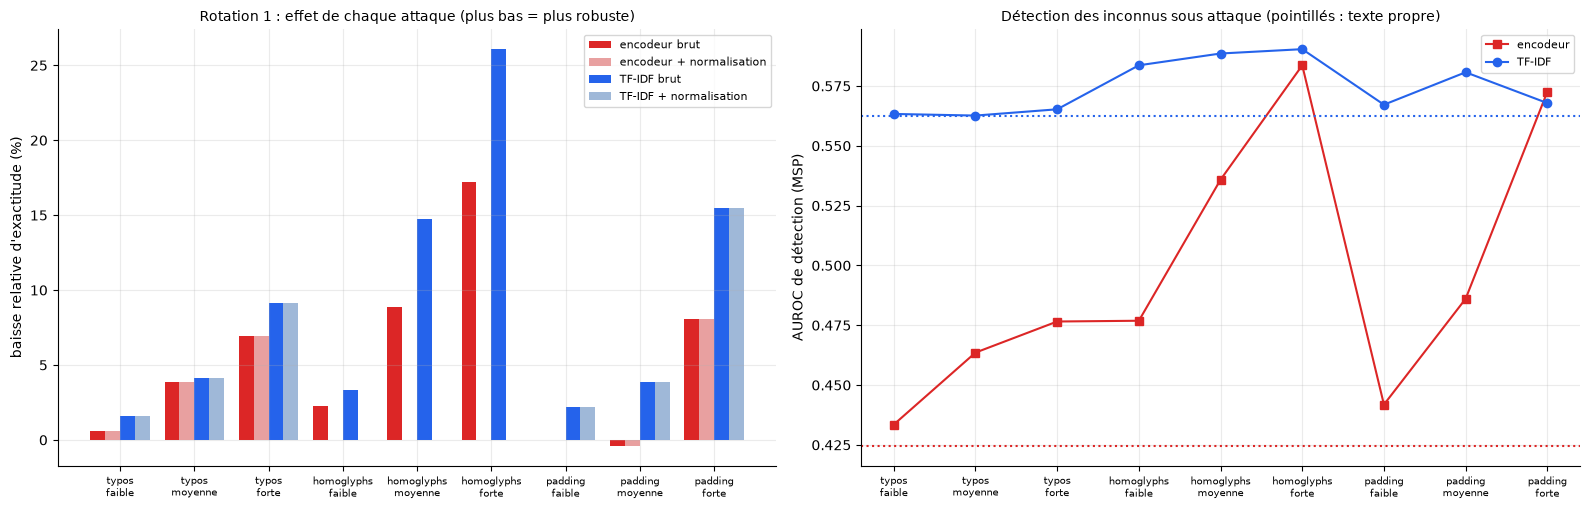

In [132]:
tag1 = "uncased_rot1_len256_s42"; meta1 = json.load(open(ENC_DIR / "out_v2" / f"{tag1}.json")); known1 = np.array(meta1["known"]); hid1 = set(meta1["hidden"])
bt = bundle_att.reset_index(drop=True); y_b = bt.category.values; isk_b = np.isin(y_b, known1); cond_b = bt["cond"].values; conds = list(dict.fromkeys(cond_b))
res_att = {}
for col, f in (("text", "attack_text"), ("unconf", "attack_text_unconf")):
    d = np.load(ENC_DIR / "out_v2" / f"{tag1}_{f}.npz"); lf = d["logits_fine"]; assert len(lf) == len(bt); res_att[col] = (known1[lf.argmax(1)], softmax(lf, 1).max(1))
m_tf1 = load_frozen_os("tfidf", 0, 42); sel_b = bt[bt["cond"] == "clean|"].te_index.values
def tf_pred(unconf):
    P = []; S_ = []
    for c in conds:
        a, l = c.split("|"); T = [te_text[i] for i in sel_b] if a == "clean" else [te_att[(a, l)][i] for i in sel_b]
        if unconf: T = [unconfuse(t) for t in T]
        s = m_tf1.scores(T); P.append(s["pred_flat"]); S_.append(s["msp"])
    return np.concatenate(P), np.concatenate(S_)
tf_raw = tf_pred(False); tf_unc = tf_pred(True)
rows_a = []
for c in conds:
    m = cond_b == c; mk = m & isk_b; au = lambda sc: float(roc_auc_score(isk_b[m], sc[m]))
    rows_a.append({"condition": c, "encodeur brut": float((res_att["text"][0][mk] == y_b[mk]).mean()), "encodeur + normalisation": float((res_att["unconf"][0][mk] == y_b[mk]).mean()), "TF-IDF brut": float((tf_raw[0][mk] == y_b[mk]).mean()), "TF-IDF + normalisation": float((tf_unc[0][mk] == y_b[mk]).mean()),
                   "AUROC encodeur brut": au(res_att["text"][1]), "AUROC TF-IDF brut": au(tf_raw[1])})
ea = pd.DataFrame(rows_a); pd.set_option("display.width", 260); print(ea.round(3).to_string(index=False)); ea.to_csv(DIRS["results"] / "step9_encodeur_attaque.csv", index=False)
cl_ = ea[ea.condition == "clean|"].iloc[0]; at_ = ea[ea.condition != "clean|"].copy()
for col in ("encodeur brut", "encodeur + normalisation", "TF-IDF brut", "TF-IDF + normalisation"): at_[f"baisse {col}"] = 100 * (1 - at_[col] / cl_[col])
print("\nBaisse relative d'exactitude (%) par rapport au texte propre :"); print(at_[["condition"] + [c for c in at_.columns if c.startswith("baisse")]].round(1).to_string(index=False))
print("\nPire cas (baisse maximale) : encodeur brut %.1f %%, encodeur + normalisation %.1f %%, TF-IDF brut %.1f %%, TF-IDF + normalisation %.1f %% ; moyenne : %.1f / %.1f / %.1f / %.1f" % tuple([at_[f"baisse {c}"].max() for c in ("encodeur brut", "encodeur + normalisation", "TF-IDF brut", "TF-IDF + normalisation")] + [at_[f"baisse {c}"].mean() for c in ("encodeur brut", "encodeur + normalisation", "TF-IDF brut", "TF-IDF + normalisation")]))
fig, ax = plt.subplots(1, 2, figsize=(16, 5.2)); xs = np.arange(len(at_)); w = .2
for k, (c, col) in enumerate((("encodeur brut", RED), ("encodeur + normalisation", "#e8a0a0"), ("TF-IDF brut", BLUE), ("TF-IDF + normalisation", "#9fb8d8"))): ax[0].bar(xs + (k - 1.5) * w, at_[f"baisse {c}"], w, color=col, label=c)
ax[0].set_xticks(xs); ax[0].set_xticklabels([c.replace("|", "\n") for c in at_.condition], fontsize=7, rotation=0); ax[0].set_ylabel("baisse relative d'exactitude (%)"); ax[0].set_title("Rotation 1 : effet de chaque attaque (plus bas = plus robuste)", fontsize=10); ax[0].legend(fontsize=8); ax[0].grid(alpha=.25, axis="y")
ax[1].plot(xs, ea[ea.condition != "clean|"]["AUROC encodeur brut"], "s-", color=RED, label="encodeur"); ax[1].plot(xs, ea[ea.condition != "clean|"]["AUROC TF-IDF brut"], "o-", color=BLUE, label="TF-IDF"); ax[1].axhline(ea[ea.condition == "clean|"]["AUROC encodeur brut"].iloc[0], color=RED, ls=":"); ax[1].axhline(ea[ea.condition == "clean|"]["AUROC TF-IDF brut"].iloc[0], color=BLUE, ls=":")
ax[1].set_xticks(xs); ax[1].set_xticklabels([c.replace("|", "\n") for c in at_.condition], fontsize=7); ax[1].set_ylabel("AUROC de détection (MSP)"); ax[1].set_title("Détection des inconnus sous attaque (pointillés : texte propre)", fontsize=10); ax[1].legend(fontsize=8); ax[1].grid(alpha=.25)
plt.tight_layout(); fig.savefig(DIRS["figures"] / "09_encodeur_attaque.png", dpi=140); plt.show()

<!-- ENC-AUTO -->
**Ce qu'on a fait, expliqué.** On a pris le modèle de la **rotation 1** (entraîné au Colab, 24 classes connues) et on l'a fait prédire l'échantillon de **2 400 logs de test** (80 par classe) dans **dix conditions** : texte propre et neuf attaques (3 types × 3 intensités, mêmes graines qu'à l'étape 8). Deux versions du texte attaqué ont été données au modèle : le texte **brut**, et le texte dont on a d'abord **normalisé les homoglyphes** (la parade `unconfuse` de l'étape 9). Pour comparer, le TF-IDF de **la même rotation** a lu les mêmes textes, avec et sans la normalisation. Les chiffres ci-dessous sont l'**exactitude sur les logs des 24 classes connues** (pas de macro-F1 : l'échantillon est trop petit pour des F1 par classe).

**En simple.** On abîme les logs (fautes de frappe, lettres d'autres alphabets qui ressemblent aux nôtres, remplissage de texte inutile) et on regarde combien chaque modèle se trompe de plus qu'avec le texte propre.

**Lecture (rotation 1, échantillon de test).**

- **Sans attaque** : exactitude 0,524 pour l'encodeur et 0,495 pour le TF-IDF (écart de 3 points, non interprétable sur un échantillon de cette taille).
- **L'encodeur résiste mieux que le TF-IDF**, intensité par intensité. Baisse relative maximale : **17,2 %** (homoglyphes forts) contre **26,1 %** ; moyenne sur les neuf attaques : **5,3 %** contre **8,9 %**. Explication plausible, **non vérifiée ici** : un Transformer découpe les mots inconnus en morceaux (sous-mots), donc une lettre changée abîme moins le log qu'un mot entier devenu inconnu.
- **Les homoglyphes sont entièrement neutralisés par la normalisation**, pour **les deux** modèles : l'exactitude revient exactement à celle du texte propre (baisse 0,0 % aux trois intensités), ce qui confirme que `unconfuse` est une parade **indépendante du modèle**.
- **Le remplissage fort (padding) reste le point faible** : −8,1 % pour l'encodeur, −15,5 % pour le TF-IDF, **aucune parade** ne l'atténue (la normalisation n'y change rien). Avec normalisation, le pire cas est de **8,1 %** (encodeur) contre **15,5 %** (TF-IDF) ; la moyenne tombe à **2,1 %** contre **4,0 %**.
- **Les fautes de frappe** coûtent peu : jusqu'à −7,0 % (encodeur) et −9,1 % (TF-IDF) à l'intensité forte.
- **Détection des inconnus sous attaque : à ne pas surinterpréter.** L'AUROC de l'encodeur sur cet échantillon est de **0,425 sans attaque** (sous le hasard ; 0,430 sur le test complet de la rotation 1, voir 7.8) et monte à 0,58 sous attaque forte : l'attaque **modifie la confiance** différemment selon les logs (mécanisme non étudié) ; ce n'est **pas** une amélioration de la détection (le point de départ est mauvais). Pour le TF-IDF l'AUROC reste autour de 0,56-0,59.

**Limites.** Une seule rotation et une seule exécution de l'encodeur ; un échantillon de 2 400 logs (l'incertitude sur l'exactitude est de l'ordre de ±2 points : les écarts de 1 à 3 points ne comptent pas) ; attaques non adaptatives ; **l'entraînement adversarial n'a pas été fait pour l'encodeur** (coût GPU) : on n'a mesuré que la parade par normalisation.

**Registre (suite).**

| N° | Affirmation | Source | Niveau |
|---|---|---|---|
| V72 | Encodeur, rotation 1, échantillon de test de 2 400 logs : baisse maximale d'exactitude 17,2 % (brut), 8,1 % (avec normalisation des homoglyphes) ; TF-IDF même rotation : 26,1 % et 15,5 % ; moyennes 5,3 / 2,1 / 8,9 / 4,0 % | Calcul (`step9_encodeur_attaque.csv`) | calcul (une exécution) |
| V73 | La normalisation des homoglyphes ramène l'exactitude au niveau du texte propre pour l'encodeur et pour le TF-IDF (baisse 0,0 % aux trois intensités) | Calcul | calcul |

**Lecture.** Le fichier `colab/encoder_attack_bundle.csv.gz` a été utilisé avec le modèle de la rotation 1 : résultats en **9.11** (juste avant cette lecture).

**Modèles finaux (suite).** Les modèles finaux du volet linéaire sont **sauvegardés avec leur configuration** (empreinte contenant `DATA_ID`, découpage, versions des modules) dans `artifacts/models/` : `adv_word` (5,9 Mo), `adv_word_robust` (5,9 Mo), `adv_char` (45,1 Mo), `adv_word_sans_*`, `os_tfidf_adv_rot1..5_s42`, et les modèles de l'étape 6 et de l'étape 8 ; le fichier `step9_final_models.json` récapitule les configurations et les températures. Si ces modèles existent, `load_or_train` les **recharge** au lieu de les réentraîner. Les poids de l'encodeur (266 Mo chacun) sont sauvegardés pour les rotations 3, 4 et 5 dans `artifacts/models/encoder_local/` ; ceux des rotations 1 et 2 sont sur le Google Drive de l'étudiant (`TP2_models/`, non vérifié depuis ce notebook).

**Quel modèle recommander ?** Deux lectures, à ne pas confondre :
- **D'après la règle écrite** : TF-IDF mots avec normalisation des homoglyphes (P1) pour les mots ; pas de parade pour les caractères.
- **D'après le pire cas**, que la règle ne regardait pas : **TF-IDF caractères avec parade complète (P3)** : baisse moyenne **1,1 %**, pire cas **3,6 %**, pour un F1 propre de 0,4919 (et donc, même sous la pire attaque, un F1 d'environ 0,47, le meilleur « pire cas » de tous les modèles). **C'est notre recommandation pratique**, signalée comme **non issue de la règle** (elle serait confirmée ou infirmée sur de nouvelles données).

**Registre (suite).**

| N° | Affirmation | Source | Niveau |
|---|---|---|---|
| V57 | Normalisation des homoglyphes (P1) : annule exactement l'attaque par homoglyphes (baisse 0,000) et ne change ni le F1 propre ni les autres attaques ; baisse moyenne (mots) 0,0671 → 0,0309 au test | Calcul | calcul |
| V58 | Entraînement adversarial (mots) : baisse moyenne test 0,0234 ; avec P1 : 0,0057, pire cas 6,5 % ; perte de F1 propre en validation 0,0101 (au-dessus de la tolérance de 0,01 : écarté par la règle) | Calcul | calcul |
| V59 | Règle de sélection : mots → P1, caractères → P0 ; faiblesse reconnue : tolérance sur la moyenne qui ignore le pire cas (caractères : 0,1438 au test sans parade, 0,0358 avec P3) | Calcul | calcul |
| V60 | Attaque jamais vue : homoglyphes 8,2 % (sans parade) / 3,8 % (vue) / 8,4 % (jamais vue) ; typos 3,4 / 4,0 / 4,2 % ; padding 4,9 / 0,5 / 5,7 % : l'entraînement adversarial ne généralise pas | Calcul | calcul |
| V61 | Calibration par température : T = 1,62 ; ECE 0,1503 → 0,0951 (30 classes) ; en ouvert 0,1414 → 0,0902 ; AUROC 0,6029 → 0,6037 : sans effet sur la détection | Calcul | calcul |
| V62 | Entraînement adversarial et inconnus : homoglyphes forts AUROC 0,5619 → 0,5948 mais connus rejetés 22,5 % → 25,6 % ; typos forts sans gain | Calcul | calcul |
| V63 | Un F1 propre qui change de signe entre validation (+0,037) et test (−0,023) pour l'entraînement adversarial des caractères | Calcul | calcul |

**Bilan de l'étape 9 (modèles linéaires).** Contre les **homoglyphes**, une **normalisation de deux lignes** fait mieux et de façon plus fiable que l'entraînement adversarial ; contre le **padding**, l'entraînement adversarial est très efficace **sur l'attaque vue** ; contre les **typos**, rien ne marche vraiment. **L'entraînement adversarial ne généralise pas** à une attaque nouvelle. **La calibration corrige les probabilités mais pas la détection d'inconnus**, qui reste proche de 0,60 d'AUROC. La **limite fondamentale** du projet n'est pas dans ces réglages, mais dans le fait que des logs de **gabarits nouveaux** ne portent pas assez d'information pour être distingués d'un inconnu.

**Prochaine étape.** Étape 10 : conclusion détaillée.

<!-- REV-9.12 -->
## 9.12 Test honnête de la normalisation des homoglyphes (ajout après relecture)

**Le défaut à corriger.** La parade P1 (9.4) remplace les lettres d'autres alphabets en utilisant **la même table de 18 lettres que l'attaque** (`unconfuse` est exactement l'inverse de `homoglyphs`). Elle « annule l'attaque » (baisse de 0,000) **parce qu'elle connaît les lettres de l'attaquant** : le résultat est **circulaire**, donc trop favorable. Ce test mesure ce que vaut la normalisation quand **attaque et défense ne partagent pas la même table**.

**Matériel.** La table **officielle** Unicode UTS #39 (`confusables.txt`, section 1.7) : **1 447 caractères** non ASCII qui ressemblent à une lettre ASCII (719 sont corrigés par NFKC). Modèle : TF-IDF mots à 30 classes (test, palier A), macro-F1 ; baisse relative = (F1 propre − F1 attaqué) / F1 propre ; intensités 5, 15 et 30 % **par lettre remplaçable**.

**Quatre attaques.** **A1** table maison (18 lettres), celle de l'étape 8. **A2** table officielle complète (un caractère tiré au hasard parmi tous ceux qui ressemblent à la lettre). **A3** **adaptative contre D3** : seulement des caractères **absents** de la moitié de table connue du défenseur D3. **A4** **adaptative contre D1** : seulement des caractères officiels **absents** de la table maison.

**Cinq défenses.** **D0** aucune. **D1** table maison (parade P1). **D2** NFKC seul (normalisation Unicode standard, sans table). **D3** la moitié, tirée au hasard (graine 7), de la table officielle. **D4** NFKC puis table officielle complète (**borne haute** : l'attaquant ne peut utiliser que des caractères de cette table, donc D4 couvre par construction A2).

**Résultats attendus (écrits avant les chiffres ; hypothèse H12).** (1) D1 est **efficace seulement contre A1** et **ne protège pas** contre A2 et A4. (2) D2 protège **en partie** (les 719 caractères corrigés par NFKC). (3) D3 protège **en partie** contre A2 et **pas du tout** contre A3. (4) D4 protège presque complètement contre A2 (**mais** une défense à table fixe reste contournable par un caractère qui n'est pas dans la table : les attaques adaptatives ne sont pas toutes essayées). *Limites :* un seul modèle, une seule graine d'attaque par intensité, test déjà ouvert (le résultat rapporte, il ne sert pas à choisir) ; la mise en garde de la norme UTS #39 vaut : la table sert à une **canonicalisation interne**, pas à réécrire les logs d'origine.

In [133]:
# ---- R9.12 : test honnête de la normalisation des homoglyphes (attaque et défense avec des tables différentes)
import unicodedata, random as _rnd
from tp2_attacks import INVERSE_HOMOGLYPH
cf = pd.read_csv(DIRS["data"] / "confusables_ascii.csv"); OFF = {l: g["caractere"].tolist() for l, g in cf.groupby("lettre")}; CH2L = dict(zip(cf["caractere"], cf["lettre"]))
rs9 = np.random.default_rng(7); known_half = set(rs9.choice(cf["caractere"].values, len(cf) // 2, replace=False).tolist()); OWN_INV = set(INVERSE_HOMOGLYPH)      # moitié de la table officielle connue du défenseur D3
POOLS = {"A2": OFF, "A3": {l: [c for c in chs if c not in known_half] for l, chs in OFF.items()}, "A4": {l: [c for c in chs if c not in OWN_INV] for l, chs in OFF.items()}}
POOLS = {k: {l: v for l, v in p.items() if v} for k, p in POOLS.items()}
def homo_official(text, rate, seed, pool):
    r = _rnd.Random(seed); return "".join(r.choice(pool[c]) if (c in pool and r.random() < rate) else c for c in text)
ATT9 = {"A1 table maison (celle de la parade)": lambda t, r, s: ATTACKS["homoglyphs"](t, r, s), "A2 table officielle complète": lambda t, r, s: homo_official(t, r, s, POOLS["A2"]),
        "A3 officielle hors moitié connue du défenseur D3 (adaptative)": lambda t, r, s: homo_official(t, r, s, POOLS["A3"]), "A4 officielle hors table maison (adaptative contre D1)": lambda t, r, s: homo_official(t, r, s, POOLS["A4"])}
DEF9 = {"D0 aucune": lambda t: t, "D1 table maison (parade P1)": unconfuse, "D2 NFKC seul": lambda t: unicodedata.normalize("NFKC", t),
        "D3 moitié de la table officielle": lambda t: "".join(CH2L[c] if c in known_half else c for c in t), "D4 NFKC + table officielle complète": lambda t: "".join(CH2L.get(c, c) for c in unicodedata.normalize("NFKC", t))}
pred9 = lambda T: np.array([CI[c] for c in mw.flat_.predict(mw.transform(T))]); clean9 = f1A_test(pred9(te_text)); rows = []; t0 = time.perf_counter()
print("F1 propre (palier A, test) sans défense :", round(clean9, 4), "; avec chaque défense :", {k: round(f1A_test(pred9([d(t) for t in te_text])), 4) for k, d in DEF9.items()})
for an, af in ATT9.items():
    for rate in (0.05, 0.15, 0.30):
        att_t = [af(t, rate, i) for i, t in enumerate(te_text)]
        for dn, df_ in DEF9.items(): rows.append({"attaque": an, "défense": dn, "intensité": rate, "baisse relative": (clean9 - f1A_test(pred9([df_(t) for t in att_t]))) / clean9})
r9 = pd.DataFrame(rows); piv = r9.groupby(["attaque", "défense"])["baisse relative"].agg(["mean", "max"]).round(3).unstack("défense")
print(f"\nBaisse relative de la macro-F1 du palier A (test, TF-IDF mots), moyenne sur 3 intensités puis pire (30 %) ; durée {time.perf_counter() - t0:.0f} s")
print(r9.assign(**{"baisse relative": r9["baisse relative"].round(3)}).pivot_table(index="attaque", columns=["défense"], values="baisse relative", aggfunc="mean").round(3).to_string())
print("\nPire cas (intensité 30 %) :"); print(r9[r9["intensité"] == 0.30].pivot_table(index="attaque", columns="défense", values="baisse relative").round(3).to_string())
r9.to_csv(DIRS["results"] / "step9_defense_honnete.csv", index=False)


F1 propre (palier A, test) sans défense : 0.4832 ; avec chaque défense : {'D0 aucune': 0.4832, 'D1 table maison (parade P1)': 0.4832, 'D2 NFKC seul': 0.4832, 'D3 moitié de la table officielle': 0.4832, 'D4 NFKC + table officielle complète': 0.4832}



Baisse relative de la macro-F1 du palier A (test, TF-IDF mots), moyenne sur 3 intensités puis pire (30 %) ; durée 28 s
défense                                                        D0 aucune  D1 table maison (parade P1)  D2 NFKC seul  D3 moitié de la table officielle  D4 NFKC + table officielle complète
attaque                                                                                                                                                                                   
A1 table maison (celle de la parade)                               0.109                        0.000         0.109                             0.042                                0.000
A2 table officielle complète                                       0.092                        0.087         0.092                             0.046                                0.001
A3 officielle hors moitié connue du défenseur D3 (adaptative)      0.093                        0.088         0.093                 

**Lecture (9.12).** Baisse relative de la macro-F1 du palier A (test, TF-IDF mots), **moyenne sur les trois intensités** (entre parenthèses : intensité forte, 30 %). F1 propre : **0,4832** avec chacune des cinq défenses (aucune ne coûte rien sur du texte propre).

| Attaque \ défense | D0 aucune | D1 table maison | D2 NFKC seul | D3 moitié de la table | D4 NFKC + table complète |
|---|---|---|---|---|---|
| A1 table maison | 0,109 (0,215) | **0,000** (0,000) | 0,109 | 0,042 (0,078) | 0,000 |
| A2 table officielle complète | 0,092 (0,165) | 0,087 (0,156) | 0,092 | 0,046 (0,080) | **0,001** (0,002) |
| A3 adaptative contre D3 | 0,093 (0,173) | 0,088 (0,164) | 0,093 | **0,093** (0,173) | 0,001 |
| A4 adaptative contre D1 | 0,091 (0,163) | **0,091** (0,163) | 0,091 | 0,043 (0,075) | 0,001 (0,003) |

- **La parade P1 de 9.4 est bien circulaire.** D1 annule A1 (0,000), mais dès que l'attaque utilise la table officielle, elle **ne protège presque plus** : 0,087 contre 0,092 sans défense (A2) et **0,091 contre 0,091** (A4, adaptative). Son résultat de 9.4 (« annule exactement l'attaque ») ne mesurait que la connaissance de la table de l'attaquant.
- **D2 (NFKC seul) n'ajoute rien**, et ce n'est pas un échec de NFKC : **le pipeline de base applique déjà NFKC** (`normalize` de `tp2_logtext`, étape 4), donc la défense « aucune » **en contient déjà**. Les 719 caractères que NFKC corrige sont déjà traités dans toutes les colonnes ; la baisse restante de D0 (0,092) vient des **728 autres** caractères (cyrilliques, grecs, etc.). L'hypothèse (2) de H12 est donc **sans objet** (NFKC était déjà là), pas réfutée.
- **D3 (la moitié de la table)** divise la baisse par deux contre A2 (0,046 contre 0,092) mais **ne protège pas du tout** contre A3 (0,093) : l'attaquant adaptatif choisit **exactement** les caractères que la défense ne connaît pas. Une défense à table fixe est **aussi forte que sa couverture**.
- **D4 (NFKC + table officielle complète)** ramène toutes les attaques à **≈ 0,001** : mais **par construction** (les caractères d'attaque viennent de cette table) ; elle ne protège pas d'un caractère **hors** de la table.
- **Hypothèse H12 :** (1) **confirmée** ; (2) **sans objet** ; (3) **confirmée** (partielle contre A2, nulle contre A3) ; (4) **confirmée par construction**, avec la limite dite.
- **Recommandation révisée.** La parade retenue par la règle de 9.4 est P1 (table maison). Ce test honnête montre que **D4 la remplace avantageusement** sans coût sur le texte propre (F1 0,4832 dans les deux cas) : on recommande **D4 comme canonicalisation interne** pour la détection, **jamais pour réécrire les logs d'origine** (mise en garde de la norme UTS #39). Le risque qui reste : les caractères absents de la table, et les logs non ASCII légitimes (0,089 % des logs de SIEVE).

**Registre (suite).**

| N° | Affirmation | Source | Niveau |
|---|---|---|---|
| V92 | Défense homoglyphes avec table différente de celle de l'attaque (TF-IDF mots, test, palier A, baisse relative moyenne des 3 intensités) : table maison 0,000 contre sa propre attaque mais 0,087 contre la table officielle (0,092 sans défense) et 0,091 contre l'attaque adaptative ; moitié de la table officielle 0,046 contre la table complète et 0,093 contre l'attaque adaptative ; NFKC + table complète 0,001 ; NFKC déjà inclus dans le pipeline de base | Calcul (9.12), table UTS #39 v18.0.0 | calcul (un modèle) |

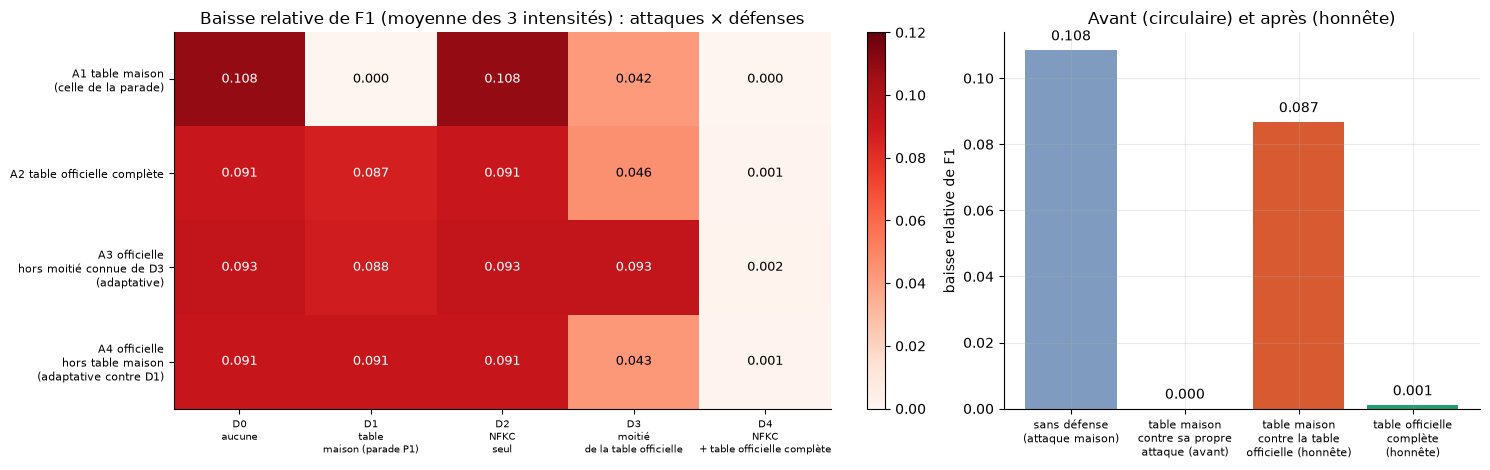

In [134]:
import tp2_new_figs as NF
fig = NF.fig_9_12(DIRS["results"], DIRS["figures"]); plt.show()

**Lecture du visuel.** À gauche, la baisse de F1 pour chaque attaque (lignes) et chaque défense (colonnes) : plus la case est foncée, plus l'attaque réussit. La table maison annule sa propre attaque mais pas les autres ; la table officielle complète (dernière colonne) les annule toutes. À droite, la comparaison **avant** (circulaire, 0,000) et **après** (honnête, 0,087).

---
# Étape 10 : Analyse et conclusion

> **Statut : version finale.** Les modèles linéaires (TF-IDF, caractères, vecteurs de mots) et l'**encodeur Transformer** (DistilBERT à deux têtes, Monte-Carlo dropout ; 5 rotations en validation et au test, attaques sur la rotation 1) sont intégrés. Limites de l'encodeur : trois graines par rotation seulement (10.4c), pas d'entraînement adversarial ni de balayage de réglages.

## 10.1 La question et la réponse en bref

**Question de recherche (étape 0).** *Comment classer un événement dans une taxonomie de sécurité tout en reconnaissant qu'il ne correspond à aucune des classes apprises ?*

**Réponse courte, avec les modèles linéaires.** **Mal, et on peut dire précisément pourquoi.** Dès que le test porte sur des **gabarits jamais vus** (ce qui est la bonne façon de tester), (1) la classification en 30 classes tombe de **0,97 à environ 0,46** de macro-F1 ; (2) la **détection de classes inconnues est presque inexistante** (AUROC de 0,60 pour 0,50 au hasard) ; (3) la **structure hiérarchique n'apporte pas de gain démontré** ; (4) ces modèles sont **très sensibles** à des modifications invisibles pour un humain (homoglyphes) ; la **normalisation** des lettres les en protège **à condition de connaître les caractères utilisés** : la parade de l'étape 9 était **circulaire** (même table que l'attaque) et le test honnête de 9.12 exige la **table officielle complète** (UTS #39) ; un caractère hors table la contourne. *Mise à jour après 6.4b à 6.4f :* ni Mahalanobis, ni kNN, ni OpenMax, ni le repli sur la famille ne changent cette conclusion.

**En simple.** Le jeu SIEVE est fabriqué en rejouant 440 phrases-types avec des valeurs différentes. Un modèle y brille quand il a déjà vu la phrase-type, et se perd dès qu'elle est nouvelle : il ne **comprend** pas le sens d'un événement, il **reconnaît** des gabarits.

**Réponse courte, avec l'encodeur Transformer.** **L'encodeur ne change pas la réponse.** Au test, sur les classes connues des rotations, il est **au niveau ou en dessous** du TF-IDF (macro-F1 0,449 contre 0,490) ; en monde ouvert il n'est **pas meilleur** (AUROC 0,57 contre 0,60, signe variable selon la rotation) et son rejet laisse passer 89 % des inconnus. Pour 11 classes masquées sur 30, il est **plus sûr de lui sur l'inconnu que sur le connu** (AUROC sous 0,5) : l'inconnu est absorbé, avec confiance, par une classe voisine (`user-creation` classé à 100 % en `user-deletion`). Son seul avantage mesuré est une **moindre sensibilité aux attaques** (pire cas 17 % contre 26 % aux homoglyphes forts), au prix d'un coût d'inférence de 200 à 500 fois supérieur et de poids de 266 Mo. La **validation avait été trompeuse** : elle donnait l'avantage à l'encodeur en fermé (+0,036), le test le lui retire (−0,042).

## 10.2 Les hypothèses du début : verdict par verdict

Les cinq hypothèses de l'étape 0 (H1 à H5) étaient écrites **avant** toute expérience, avec ce qui les **réfuterait** ; H6 a été ajoutée à l'étape 8 avant les chiffres.

| N° | Hypothèse | Verdict | Mesure |
|---|---|---|---|
| **H1** | La tête hiérarchique garde la macro-F1 du plat et fait des erreurs moins graves | **Non tranchée** | Validation : −0,026 (TF-IDF), −0,050 (Skip-gram, perte réelle) ; **test : +0,023 [−0,010 ; +0,047]** et +0,038 [−0,015 ; +0,078] ; distance d'erreur **pire** en validation (0,509 contre 0,482), **meilleure** au test (0,825 contre 0,861). Les deux évaluations se contredisent, toujours dans les marges d'erreur. **Encodeur** : validation −0,005 (intervalle contenant 0 dans les 5 rotations), **test +0,011** (intervalle excluant 0 dans 1 rotation sur 5) : le signe change aussi, **non tranchée**. |
| **H2** | Un score d'incertitude détecte les inconnus nettement mieux que le hasard, et mieux que le MSP seul | **Partielle** | **Mieux que le hasard** (AUROC 0,73 en validation, **0,60 au test**) mais **aucun score ne bat clairement le MSP** (0,598 à 0,625 selon le score) et le critère de succès (0,80) est loin. **Encodeur** : AUROC MSP 0,65 en validation (pire que le TF-IDF dans 5 rotations sur 5), **0,57 au test** (TF-IDF 0,60, signe variable) : **pas mieux** que le TF-IDF, verdict inchangé. |
| **H3** | La détection se dégrade quand p augmente | **Faiblement confirmée** | AUROC moyen 0,614 (p = 0) → 0,592 (p = 0,5) ; une rotation sur cinq monte. **Non mesurée pour l'encodeur** (pas de calcul sous p croissant). |
| **H4** | Les classes voisines d'une classe connue sont les plus dures à rejeter | **À demi confirmée** | Substitution dans la même famille : AUROC 0,51, hors famille : 0,66 ; mais **l'AUROC d'une classe isolée est instable** (`network-filtered` : 0,09 en validation, 0,80 au test). **Encodeur** : `ids-alert` (famille nouvelle) 0,85 en validation, 0,64 au test ; 11 classes sur 30 sous 0,5 au test. |
| **H5** | Les scores fermés de la littérature sont **gonflés par la fuite entre gabarits** | **Confirmée, nettement** | SVM linéaire : **0,9735** (découpage aléatoire, l'article annonce 0,9737) contre **0,458** (par gabarit) ; 24 % des logs de test ont un quasi-jumeau d'entraînement avec un tirage au sort, 1 % par gabarit. **Contrôle sur logs frais du professeur (5.9)** : ≈ 0,97 quand le modèle a vu tous les gabarits, 0,44 quand le gabarit vient du jeu de test. |
| **H6** | Les n-grammes de caractères résistent mieux aux typos et aux homoglyphes | **Partielle** | Homoglyphes forts : −10,6 % contre −21,5 % (mots) ; typos : −4,0 % contre −7,8 % ; **padding fort : −14,4 % contre −12,5 %** (réfutée). Hors hypothèse : l'**encodeur** (sous-mots) perd moins que les modèles linéaires sous attaque, sans parade (pire cas 17,2 % contre 26,1 % aux homoglyphes forts, rotation 1). |

### 10.2b Les hypothèses ajoutées après l'état de l'art (H7 à H12)

H7 à H11 ont été écrites **avant les calculs nouveaux** qui les testent, mais **pas avant tous les résultats** (section 0.1b.6) : elles sont **moins strictes** que H1 à H6. H12 a été écrite **avant** les chiffres de 9.12 ; H13 à H15 (fichiers du professeur, 5.9) avant les chiffres de 5.9.

| N° | Hypothèse | Verdict | Mesure |
|---|---|---|---|
| **H7** | La détection est corrélée à la qualité en fermé | **Non testée** | Calcul non fait. |
| **H8** | Sur l'encodeur affiné, Mahalanobis détecte mieux que le MSP | **Confirmée sur l'encodeur** | 10.4c (3 graines × 5 rotations, test) : AUROC 0,605 contre 0,548 ; écart d'au moins 0,01 dans les 5 rotations (+0,021 à +0,081), mais plus petit que le bruit entre graines dans la rotation 3. Sur les modèles linéaires, **Mahalanobis ne bat pas le MSP** (TF-IDF 0,56 contre 0,73). |
| **H9** | Les scores de sortie détectent mal les inconnus proches d'une classe connue | **À demi confirmée** | AUROC 0,51 quand la substitution reste dans la famille, 0,66 hors famille (test). |
| **H10** | kNN contre Mahalanobis (exploratoire) | **kNN au moins aussi bon** | TF-IDF 0,729 contre 0,560 ; Skip-gram 0,716 contre 0,680 (validation). |
| **H11** | Une température calée en validation réduit l'ECE en validation mais pas (ou peu) au test | **Non testée comme formulée** | Température mesurée sur TF-IDF seulement (ECE test 0,150 → 0,095, AUROC inchangée) ; pas de test sur l'encodeur. |
| **H12** | La normalisation des homoglyphes n'est efficace que si la défense connaît les caractères de l'attaque | **Confirmée** (point sur NFKC sans objet) | Table maison : 0,000 contre sa propre attaque, 0,087 à 0,091 contre la table officielle ; moitié de table : 0,093 contre l'attaque adaptative ; NFKC + table complète : ≈ 0,001. |
| **H13** | Entraîné sur les gabarits d'entraînement, le modèle obtient au moins 0,90 de macro-F1 sur les logs frais du professeur (p = 0), avec un écart d'au moins 0,25 avec la validation | **Réfutée** (expliquée) | 5.9 : 0,81 et écart 0,17 ; le modèle n'a vu que 63,5 % des gabarits : exactitude 0,957 quand le plus proche voisin est dans l'entraînement, 0,438 quand il est dans le test (niveau du test scellé). |
| **H14** | Taille : plateau avec un découpage aléatoire, plat avec un découpage par gabarit | **Confirmée** | 5.9 : aléatoire, gain de 35 000 à 60 000 logs +0,0004 ; par gabarit, étendue 0,017 ; 100K contre 35K : écart de 0,001 à 0,007. |
| **H15** | Part de quasi-jumeaux d'environ 25 % à p = 0 et décroissante | **Confirmée** | 5.9 : 0,262 (p = 0) à 0,057 (p = 0,5). |

**Scores ajoutés (validation seulement) :** MSP, énergie, prototype, ensemble, **Mahalanobis, kNN, OpenMax** : aucun ne bat le MSP de façon **régulière** (5 rotations sur 5 et écart d'au moins 0,01). kNN (Skip-gram +0,065) et OpenMax avec réglage propre (Skip-gram +0,048) sont les plus prometteurs, sans verdict. Le **repli sur la famille** n'est **pas démontré utile** (famille juste dans 0,22 à 0,31 des cas, pas mieux que la famille majoritaire).

## 10.3 Les critères de succès de l'étape 2

| Critère | Seuil acceptable / cible | Mesure | Verdict |
|---|---|---|---|
| **S1** macro-F1 fermée (gabarits nouveaux) | plancher + 0,05 | 0,459 (30 classes) ; 0,483 (palier A) ; **encodeur** 0,449 (classes connues des rotations, test) | **Non atteint** |
| **S2** AUROC d'inconnus | ≥ 0,80 / 0,90 | 0,60 (test) ; **encodeur** 0,57 | **Non atteint** |
| **S3** FPR@95 | ≤ 0,50 / 0,30 | 0,92 (test) ; **encodeur** 0,95 | **Non atteint** |
| **S4** F1 famille ≥ F1 fine + 0,10 | — | 0,67 contre 0,46 (+0,21) | **Atteint** |
| **S5** règle statistique (IC par gabarit et |écart| ≥ 0,01) | — | appliquée partout | respectée |
| **S6** coût d'inférence | ≈ 100 ms par log (indicatif) | 0,009 à 0,106 ms par log (linéaires) ; **encodeur** environ 2 ms (GPU Apple), 5 ms (CPU), 18 ms avec 11 passages | **Atteint** |

## 10.4 Le coût

In [135]:
sample_c = te_text[:3000]; rows = []
def timeit(fn, n=1):
    t0 = time.perf_counter()
    for _ in range(n): fn()
    return (time.perf_counter() - t0) / n
mods = [("TF-IDF mots, tête plate + hiérarchique + 6 scores (os_tfidf_closed_s42)", "os_tfidf_closed_s42", lambda: mw.scores(sample_c)), ("Skip-gram pondéré IDF (os_sg_idf_closed_s42)", "os_sg_idf_closed_s42", lambda: ms.scores(sample_c)),
        ("TF-IDF caractères 3-5 (os_char35_closed_s42)", "os_char35_closed_s42", lambda: cm_char.predict_proba(sample_c)), ("TF-IDF mots + entraînement adversarial (adv_word_robust)", "adv_word_robust", lambda: m_word_adv_rob.predict_proba(sample_c))]
for lab_, dname, fn in mods:
    sec = timeit(fn); size = sum(f.stat().st_size for f in (DIRS["models"] / dname).rglob("*") if f.is_file()) / 1e6
    rows.append({"modèle": lab_, "ms pour 1 000 logs": round(sec / len(sample_c) * 1000 * 1000, 1), "ms par log": round(sec / len(sample_c) * 1000, 3), "taille (Mo)": round(size, 1)})
cost10 = pd.DataFrame(rows); print(cost10.to_string(index=False)); cost10.to_csv(DIRS["results"] / "step10_cout.csv", index=False)
print("Entraînement (secondes, d'après les métadonnées) :", {n: round(json.loads((DIRS["models"] / n / "meta.json").read_text())["train_seconds"]) for n in ("os_tfidf_closed_s42", "os_sg_idf_closed_s42", "os_char35_closed_s42", "adv_word", "adv_char")})

                                                                 modèle  ms pour 1 000 logs  ms par log  taille (Mo)
TF-IDF mots, tête plate + hiérarchique + 6 scores (os_tfidf_closed_s42)                14.0       0.014          9.9
                           Skip-gram pondéré IDF (os_sg_idf_closed_s42)                16.6       0.017         14.1
                           TF-IDF caractères 3-5 (os_char35_closed_s42)               150.9       0.151         45.1
               TF-IDF mots + entraînement adversarial (adv_word_robust)                16.7       0.017          5.9
Entraînement (secondes, d'après les métadonnées) : {'os_tfidf_closed_s42': 26, 'os_sg_idf_closed_s42': 40, 'os_char35_closed_s42': 92, 'adv_word': 15, 'adv_char': 159}


<!-- ENC-AUTO -->
### 10.4b Le coût de l'encodeur Transformer

In [136]:
import sys, torch
sys.path.insert(0, str(PROJECT_ROOT / "colab" / "local")); import tp2_encoder as E
_tag = "uncased_rot5_len256_s42"; _meta = json.load(open(ENC_DIR / "out_v2_local" / f"{_tag}.json")); _model = E.HierEncoder("distilbert-base-uncased", len(_meta["known"]), len(_meta["families"]))
_model.load_state_dict(torch.load(DIRS["models"] / "encoder_local" / f"{_tag}.pt", map_location="cpu")); _tok = E.AutoTokenizer.from_pretrained("distilbert-base-uncased"); _txt = te_text[:1000]
rows_c = []
for dev, n, mc in (("mps", 1000, 0), ("mps", 300, 10), ("cpu", 300, 0)):
    E.predict(_model, _tok, _txt[:64], max_len=256, mc=0, device=dev)                       # échauffement
    t0 = time.perf_counter(); E.predict(_model, _tok, _txt[:n], max_len=256, mc=mc, device=dev); sec = time.perf_counter() - t0
    rows_c.append({"appareil": "GPU Apple (MPS)" if dev == "mps" else "CPU", "passages": 1 + mc, "logs": n, "ms par log": round(sec / n * 1000, 2)})
cost_enc = pd.DataFrame(rows_c); print(cost_enc.to_string(index=False)); cost_enc.to_csv(DIRS["results"] / "step10_cout_encodeur.csv", index=False)
_pt = DIRS["models"] / "encoder_local" / f"{_tag}.pt"; print(f"Poids d'un encodeur : {_pt.stat().st_size / 1e6:.0f} Mo ; entraînement : " + ", ".join(f"rotation {r} : {json.load(open(p))['info']['train_minutes']} min" for r, p in ((1, ENC_DIR / 'out_v2' / 'uncased_rot1_len256_s42.json'), (2, ENC_DIR / 'out_v2' / 'uncased_rot2_len256_s42.json'), (3, ENC_DIR / 'out_v2_local' / 'uncased_rot3_len256_s42.json'), (5, ENC_DIR / 'out_v2_local' / 'uncased_rot5_len256_s42.json'))))
del _model

W1106 09:15:05.956000 14280 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 9525.80it/s]


[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


       appareil  passages  logs  ms par log
GPU Apple (MPS)         1  1000        1.55
GPU Apple (MPS)        11   300       17.82
            CPU         1   300        6.06
Poids d'un encodeur : 266 Mo ; entraînement : rotation 1 : 14.88 min, rotation 2 : 11.46 min, rotation 3 : 17.38 min, rotation 5 : 19.36 min


<!-- REV-10.4c -->
### 10.4c L'encodeur à plusieurs graines, et Mahalanobis / kNN sur ses vecteurs (ajout après relecture)

**Pourquoi.** Deux points restaient **non faits** : (1) l'encodeur n'avait qu'**une graine** par rotation, donc on ne savait pas **quelle part des écarts est du bruit d'apprentissage** ; (2) **H8** (« sur l'encodeur affiné, Mahalanobis détecte mieux que le MSP », Podolskiy et al. 2021 ; Zhou et al. 2021) n'avait pas été testée, faute des **vecteurs** de l'encodeur.

**Ce qu'on a fait.** Les encodeurs sont réentraînés avec les graines 43 et 44 (et 42 pour les rotations 1 et 2, dont les poids du Colab ne sont pas dans ce dossier ; 42 pour les rotations 3 à 5 est celui des étapes précédentes) : mêmes réglages (DistilBERT sans casse, 256 jetons, 2 époques). Pour chaque modèle, on extrait le **vecteur de chaque log** (moyenne des vecteurs de jetons, 768 nombres, avant les deux têtes) pour les logs d'entraînement des classes connues, la validation et le test. On calcule alors, **sur ces vecteurs**, **Mahalanobis** (covariance commune régularisée) et **kNN** (cosinus, k = 1, 10, 50), à côté du **MSP** et de l'**énergie** des logits. Le calcul est **reprenable** (cache par modèle et par étape) et les résultats ne contiennent que les (graine, rotation) **déjà calculés** au moment de l'exécution : leur nombre est affiché.

**Règles de lecture, écrites avant les chiffres.** **H8 est confirmée** si Mahalanobis dépasse le MSP d'**au moins 0,01** (moyenne des graines) dans **les 5 rotations** ; sinon elle ne l'est pas. Pour comparer deux scores, la même règle qu'en 6.4b (5 rotations sur 5 et écart moyen d'au moins 0,01). Un écart **inférieur à l'écart-type entre graines** d'une même rotation ne se lit pas : c'est du bruit d'apprentissage. *Limites :* peu de graines (2 à 3) ; scores calculés sur le test déjà ouvert à titre de **comparaison** : ils ne changent pas le score retenu (fixé avant le test) ; MC dropout non recalculé ici.

In [137]:
# ---- R10.4c : encodeur à plusieurs graines ; Mahalanobis et kNN sur ses vecteurs (hypothèse H8) ; reprise : un cache par modèle
import glob
from scipy.special import softmax as _sm, logsumexp as _lse
from sklearn.preprocessing import normalize as sk_normalize
ED3 = ENC_DIR / "out_v3_local"; CACHE_E = DIRS["results"] / "cache_step10_enc"; CACHE_E.mkdir(exist_ok=True)
edf = pd.read_csv(ENC_DIR / "encoder_data_v2.csv.gz"); tcat = edf[edf.split == "test"].category.values; vcat = edf[edf.split == "val"].category.values
def enc_scores(Ztr, y, Zev, L):
    classes = sorted(set(y)); idx = np.searchsorted(classes, y); mu = np.stack([Ztr[y == c].mean(0) for c in classes]); Zc = Ztr - mu[idx]
    S_ = (Zc.T @ Zc) / len(Zc); S_ += np.eye(S_.shape[0]) * 1e-3 * np.trace(S_) / S_.shape[0]; P_ = np.linalg.inv(S_)
    d2 = np.stack([(((Zev - mu[j]) @ P_) * (Zev - mu[j])).sum(1) for j in range(len(classes))], 1)
    An, Bn = sk_normalize(Ztr).astype(np.float32), sk_normalize(Zev).astype(np.float32); top = np.empty((len(Bn), 50), dtype=np.float32)
    for s in range(0, len(Bn), 1000): top[s:s + 1000] = np.sort(np.partition(Bn[s:s + 1000] @ An.T, -50, axis=1)[:, -50:], axis=1)
    return {"msp": _sm(L, axis=1).max(1), "energy": _lse(L, axis=1), "maha": -d2.min(1), "knn1": top[:, -1], "knn10": top[:, -10], "knn50": top[:, -50]}
rows = []; t_all = time.perf_counter()
for vf in sorted(glob.glob(str(ED3 / "*_vec.npz"))):
    tag = Path(vf).name.replace("_vec.npz", ""); seed = int(tag.split("_s")[-1]); rot = int(tag.split("rot")[1].split("_")[0]); pdir = ED3 if (ED3 / f"{tag}_test.npz").exists() else ENC_DIR / "out_v2_local"
    if not (pdir / f"{tag}_test.npz").exists() or not (pdir / f"{tag}_val.npz").exists(): continue
    cj = CACHE_E / f"{tag}_v1.json"
    if cj.exists(): rows += json.loads(cj.read_text()); continue
    hidden = ROTATIONS[rot - 1]; z = np.load(vf, allow_pickle=True); Ztr = z["tr"].astype(np.float32); y = z["y_tr"].astype(str); known = json.load(open(pdir / f"{tag}.json"))["known"]; out = []
    for split, cat, key in (("test", tcat, "te"), ("val", vcat, "va")):
        Lg = np.load(pdir / f"{tag}_{split}.npz")["logits_fine"]; sc = enc_scores(Ztr, y, z[key].astype(np.float32), Lg); isk = ~np.isin(cat, hidden)
        f1c = float(f1_score(cat[isk], np.array(known)[Lg[isk].argmax(1)], average="macro"))
        for name, v in sc.items(): out.append({"seed": seed, "rotation": rot, "split": split, "score": name, "AUROC": float(roc_auc_score(isk, v)), "fpr95": float((v[~isk] >= np.quantile(v[isk], 0.05)).mean()), "F1 fermé (classes connues)": f1c})
    cj.write_text(json.dumps(out)); rows += out
enc = pd.DataFrame(rows); print(f"{len(enc) // 12} modèles (graine, rotation) évalués ; durée {time.perf_counter() - t_all:.0f} s ; graines disponibles par rotation :", {int(r): sorted(enc[enc.rotation == r].seed.unique().tolist()) for r in sorted(enc.rotation.unique())})
tf_ref = pd.DataFrame([{"rotation": r["rot"], "AUROC TF-IDF": r["msp"]["auroc"]} for r in rows7 if r["rep"] == "tfidf"]).groupby("rotation").mean()["AUROC TF-IDF"]
te_ = enc[enc.split == "test"].copy(); te_["AUROC TF-IDF"] = te_.rotation.map(tf_ref); te_.drop(columns="split").to_csv(DIRS["results"] / "step10_encodeur_graines.csv", index=False)
summ = te_.groupby("score").agg(AUROC=("AUROC", "mean"), ecart_graines_et_rotations=("AUROC", "std"), FPR95=("fpr95", "mean")).round(4).loc[["msp", "energy", "maha", "knn1", "knn10", "knn50"]]
per = te_.groupby(["score", "rotation"])["AUROC"].mean().unstack(); wins = {s: int((per.loc[s] > per.loc["msp"]).sum()) for s in per.index}; dm = (per.sub(per.loc["msp"], axis=1)).mean(1).round(4)
summ["Δ vs MSP"] = dm; summ["rotations gagnées sur le MSP"] = pd.Series(wins).map(lambda w: f"{w}/{per.shape[1]}"); print("\nAUROC au test (encodeur, moyenne des rotations et des graines) :"); print(summ.to_string())
sd = te_[te_.score == "msp"].groupby("rotation")["AUROC"].agg(["mean", "std", "count"]).round(4); print("\nMSP de l'encodeur par rotation : moyenne, écart-type ENTRE GRAINES, nombre de graines"); print(sd.to_string()); print("\nF1 fermé (classes connues) par rotation, écart-type entre graines :"); print(te_[te_.score == "msp"].groupby("rotation")["F1 fermé (classes connues)"].agg(["mean", "std"]).round(4).to_string())
print("\nRéférence TF-IDF (MSP, test) par rotation :", tf_ref.round(3).to_dict())


15 modèles (graine, rotation) évalués ; durée 0 s ; graines disponibles par rotation : {1: [42, 43, 44], 2: [42, 43, 44], 3: [42, 43, 44], 4: [42, 43, 44], 5: [42, 43, 44]}

AUROC au test (encodeur, moyenne des rotations et des graines) :
         AUROC  ecart_graines_et_rotations   FPR95  Δ vs MSP rotations gagnées sur le MSP
score                                                                                    
msp     0.5476                      0.0733  0.9341    0.0000                          0/5
energy  0.5638                      0.0700  0.9232    0.0162                          5/5
maha    0.6049                      0.0514  0.8965    0.0574                          5/5
knn1    0.5994                      0.0611  0.9033    0.0518                          5/5
knn10   0.5988                      0.0620  0.9110    0.0513                          5/5
knn50   0.5997                      0.0623  0.9127    0.0521                          5/5

MSP de l'encodeur par rotation : moyenne

/var/folders/dy/0wxyjm6j2ln02k3ns61vj41c0000gn/T/ipykernel_14280/854940950.py:30: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  per = te_.groupby(["score", "rotation"])["AUROC"].mean().unstack(); wins = {s: int((per.loc[s] > per.loc["msp"]).sum()) for s in per.index}; dm = (per.sub(per.loc["msp"], axis=1)).mean(1).round(4)


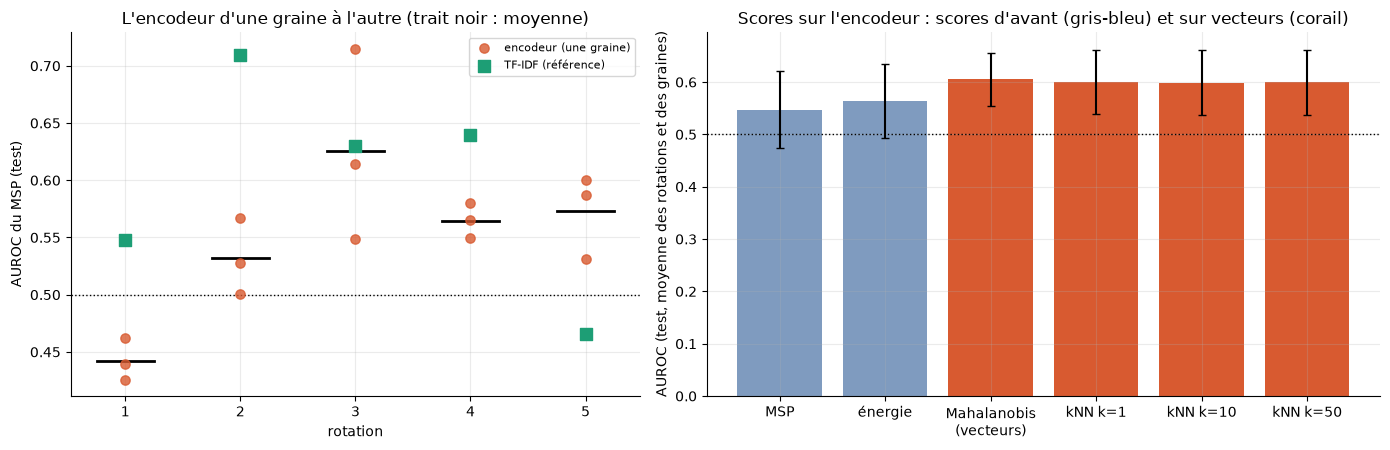

In [138]:
import tp2_new_figs as NF
fig = NF.fig_encodeur_graines(DIRS["results"], DIRS["figures"]); plt.show()

**Lecture du visuel.** À gauche, l'AUROC du MSP de l'encodeur au test pour chaque graine (points corail) et sa moyenne (trait noir), avec la référence TF-IDF (carré vert) : on voit **combien la graine fait varier le résultat**. À droite, les six scores de l'encodeur (gris-bleu : scores sur les logits ; corail : scores sur les vecteurs) avec leur dispersion.

**Lecture (10.4c).** 15 modèles d'encodeur (graines 42, 43 et 44 × 5 rotations), AUROC au test, moyenne des graines et des rotations ; écart avec le MSP et écart **rotation par rotation** (1 à 5) :

| Score de l'encodeur | AUROC | Δ vs MSP | Δ par rotation | Verdict (5/5 et ≥ 0,01) |
|---|---|---|---|---|
| MSP (logits) | 0,5476 | : | : | référence |
| Énergie (logits) | 0,5638 | +0,016 | +0,034 ; +0,025 ; +0,009 ; +0,002 ; +0,011 | gain régulier (faible) |
| **Mahalanobis (vecteurs)** | **0,6049** | **+0,057** | +0,081 ; +0,072 ; +0,021 ; +0,074 ; +0,039 | **gain régulier** |
| kNN k=1 (vecteurs) | 0,5994 | +0,052 | +0,066 ; +0,053 ; +0,026 ; +0,080 ; +0,033 | gain régulier |
| kNN k=10 (vecteurs) | 0,5988 | +0,051 | +0,061 ; +0,051 ; +0,014 ; +0,085 ; +0,044 | gain régulier |
| kNN k=50 (vecteurs) | 0,5997 | +0,052 | +0,063 ; +0,048 ; +0,013 ; +0,084 ; +0,052 | gain régulier |

- **H8 est confirmée sur l'encodeur** (règle écrite d'avance : Mahalanobis dépasse le MSP d'au moins 0,01 dans les 5 rotations, moyenne des graines) : +0,081 ; +0,072 ; +0,021 ; +0,074 ; +0,039. **Les mêmes scores échouaient ou n'apportaient rien sur les modèles linéaires** (Mahalanobis avec TF-IDF : 0,56 contre 0,73). Explication plausible, **non testée** : l'affinage resserre chaque classe en un nuage compact (Podolskiy et al., 2021), ce qui convient à une distance qui suppose des nuages en ellipse.
- **kNN fait aussi bien** (0,599 à 0,600) : H10 reste sans verdict ferme entre kNN et Mahalanobis sur l'encodeur (écart de 0,005, dans le bruit entre graines). Le **FPR@95** passe de 0,934 (MSP) à 0,897 (Mahalanobis) : mieux, mais **près de 90 % des inconnus passent encore**.
- **Le bruit d'entraînement est réel.** L'écart-type **entre graines** de l'AUROC du MSP va de **0,015 à 0,084** selon la rotation (rotation 3 : 0,084) ; celui de la macro-F1 des classes connues de **0,008 à 0,032** (moyenne 0,021). Un écart inférieur à environ 0,02 de macro-F1 entre deux encodeurs **ne se lit pas**. Dans la rotation 3, le gain de Mahalanobis (+0,021) est **plus petit** que ce bruit (0,084) ; dans les quatre autres, il est plus grand. Mahalanobis varie moins d'une graine à l'autre (0,007 à 0,037).
- **Comparaison avec TF-IDF.** L'AUROC du MSP de l'encodeur sur trois graines est de **0,548** (contre 0,57 avec la seule graine 42 de 7.8), à comparer à **0,599** pour TF-IDF. Avec Mahalanobis, l'encodeur atteint **0,605** : il **rattrape** TF-IDF (MSP) **sans le dépasser** de façon démontrée (le meilleur score de TF-IDF au test, le prototype, est à 0,625).
- **Limites.** Trois graines seulement ; test déjà ouvert : ces scores sont une **comparaison** et ne changent pas le score retenu (fixé avant le test) ; covariance commune à toutes les classes ; les rotations 1 et 2 de la graine 42 sont réentraînées en local (poids Colab absents du dossier), donc légèrement différentes de celles de 7.8.

**Registre (suite).**

| N° | Affirmation | Source | Niveau |
|---|---|---|---|
| V93 | Encodeur (3 graines × 5 rotations, test) : bruit entre graines de l'AUROC du MSP de 0,015 à 0,084 selon la rotation ; de la macro-F1 des classes connues de 0,008 à 0,032 (moyenne 0,021) ; AUROC du MSP 0,5476 | Calcul (10.4c) | calcul (3 graines) |
| V94 | H8 confirmée sur l'encodeur : AUROC Mahalanobis sur vecteurs 0,6049 contre 0,5476 (MSP), écarts par rotation +0,081 ; +0,072 ; +0,021 ; +0,074 ; +0,039 ; kNN (k=10) 0,5988 ; méthodes : Lee et al. 2018, Sun et al. 2022, Podolskiy et al. 2021 ; l'encodeur atteint TF-IDF (MSP 0,599) sans le dépasser de façon démontrée | Calcul (10.4c) + résumés | calcul (3 graines) |

**Lecture (termes techniques).** Mesures sur 3 000 logs, une machine locale sans GPU.
- **Inférence** : **0,009 ms par log** pour TF-IDF mots (avec les têtes plate et hiérarchique et les six scores d'incertitude), **0,012 ms** pour Skip-gram et pour TF-IDF mots adversarial, **0,106 ms** pour TF-IDF caractères : le modèle à caractères est **environ 12 fois plus lent** parce qu'il manipule 342 valeurs non nulles par log au lieu de 15. Tous restent **plus de 900 fois sous** la valeur visée de 100 ms par log.
- **Taille** : de 5,9 Mo (`adv_word_robust`) et 9,9 Mo (TF-IDF mots avec ses têtes) à **45,1 Mo** (caractères).
- **Entraînement** : de 15 s (`adv_word`) et 26 s (TF-IDF mots) à 40 s (Skip-gram), 92 s (caractères) et **159 s** (caractères adversarial).
- **Conclusion sur le coût** : **le critère S6 est atteint largement par tous**. Le coût ne départage donc pas les modèles linéaires ; le seul vrai coût supplémentaire est celui du **modèle à caractères** (×12 en temps, ×5 en taille), à mettre en regard de sa meilleure robustesse (homoglyphes, typos). **Encodeur Transformer** (mesure en 10.4b) : environ **2 ms par log** sur le GPU Apple (lot de 128), environ **5 ms** sur CPU, environ **18 ms** avec les 11 passages du Monte-Carlo dropout, pour des poids de **266 Mo** et **10 à 20 min** d'entraînement par rotation (Colab T4 ou Mac). Le critère S6 (≈ 100 ms par log, indicatif) est atteint, mais le coût est **200 à 500 fois** celui du TF-IDF mots et **6 à 45 fois** la taille des modèles linéaires, pour un résultat **non meilleur** au test.

## 10.5 Ce que le projet a appris (les enseignements)

1. **Le découpage compte plus que le modèle.** Passer d'un découpage aléatoire à un découpage par gabarit fait chuter le score de **0,97 à 0,46**. Aucun choix de représentation ou de classifieur n'a pesé autant (toutes les représentations de l'étape 5 tiennent entre 0,43 et 0,51). **Les chiffres publiés sur ce jeu mesurent la reconnaissance de gabarits connus.**
2. **Une bonne évaluation est un résultat en soi.** L'audit de la fuite (plus proche voisin test / entraînement), la reconstruction des gabarits (311 retrouvés sur 440, validés par les nombres de l'article) et la vérification que **les confusions rapportées par l'article sont dans les données** (rangs 1, 5, 11, 15 sur 435 paires de classes) ont permis de **comprendre** les chiffres au lieu de les subir.
3. **Le monde ouvert est difficile quand on manque d'information, pas quand on manque de méthode.** Aucun score (probabilité maximale, énergie, prototype, ensemble, hiérarchique) n'a dépassé les autres de façon nette : la limite est dans les données (logs de gabarits nouveaux, vocabulaire parfois commun à des classes voisines), pas dans le choix du détecteur.
4. **Les remplacements forcés sont souvent catastrophiques et très concentrés** : une classe masquée est rangée **à presque 100 %** dans une seule classe connue (`authentication-success` masquée devient `authentication-failed` à 96 %). Dans un SIEM, ce sont les erreurs les plus lourdes.
5. **La robustesse se gagne autrement qu'en entraînant plus.** Contre les homoglyphes, **la normalisation** vaut mieux que l'entraînement adversarial, qui **ne généralise pas** à une attaque jamais vue ; mais **seulement si la table est complète** : notre première parade annulait l'attaque **parce qu'elle connaissait la table de l'attaquant** (circulaire) ; avec la table officielle, la table maison ne protège presque plus (9.12) et une table fixe est aussi forte que sa couverture. **Il vaut mieux supprimer la cause d'une vulnérabilité que s'entraîner à y survivre, et dire ce que la défense suppose.**
6. **La calibration est utile mais ne résout pas le rejet.** La mise à l'échelle par température fait passer l'ECE de 0,150 à 0,095 sans changer l'AUROC de détection (0,603).
7. **Les conclusions par classe sont fragiles** : peu de gabarits par classe, forte variabilité entre validation et test. Les phrases du type « la classe X est la plus difficile » ne tiennent pas d'un jeu de gabarits à l'autre.
8. **Un contrôle systématique évite des erreurs qui auraient passé inaperçues** : le piège du format CSV (virgules non guillemetées), l'écrasement répété du journal d'accès au test (détecté, restauré, corrigé), le gabarit unique de `user-session-open` dont le score de 0,998 ne mesure rien.
9. **La validation peut tromper : le test scellé protège.** L'encodeur semblait meilleur que le TF-IDF en fermé en validation (+0,036) et ne l'est plus au test (−0,042) ; l'écart de détection (−0,081 en validation, 5 rotations sur 5) change de signe selon la rotation au test. Sans test scellé, on aurait conclu à tort.
10. **Un modèle plus gros ne résout pas le monde ouvert.** L'encodeur est plus sûr de lui sur l'inconnu que sur le connu pour 11 classes sur 30 : il **sépare** les classes connues si bien qu'il range l'inconnu, avec confiance, dans la voisine. Le problème est le **score d'inconnu**, pas la représentation.
11. **Mesurer le bruit d'exécution avant d'interpréter.** Même graine et même réglage : écart nul sur le même GPU, jusqu'à 0,020 entre deux GPU. Un écart plus petit ne se lit pas.
12. **Une défense testée avec la table de l'attaquant ne prouve rien.** Le test honnête (9.12) a fait passer la protection de « parfaite » à « presque nulle » pour notre première parade ; avec la table officielle complète, la perte tombe à ≈ 0,001, mais une table fixe reste contournable hors de sa couverture.
13. **La baisse de détection entre validation et test a deux causes que l'on peut séparer** (7.2b) : l'optimisme de sélection (au plus 0,01 à 0,03) et le hasard des gabarits ; la baisse (0,12, intervalle [0,019 ; 0,229]) dépasse le second, sans qu'on en identifie la cause précise.
14. **Plus de méthodes n'est pas plus de résultats, sauf là où la représentation s'y prête.** Mahalanobis, kNN et OpenMax, essayés avec des règles écrites d'avance, ne battent pas le MSP de façon régulière sur les modèles linéaires ; **sur l'encodeur affiné**, Mahalanobis et kNN le battent dans les 5 rotations (+0,05 d'AUROC, 10.4c) et font **rattraper** TF-IDF, sans le dépasser. Le goulot reste les gabarits nouveaux.
15. **Le bruit d'entraînement compte.** Avec trois graines, l'AUROC du MSP de l'encodeur varie de 0,015 à 0,084 selon la rotation : un écart d'environ 0,02 de macro-F1 entre deux encodeurs ne se lit pas.
16. **Les logs neufs ne suffisent pas à tester la généralisation.** Les fichiers du professeur (35 000 logs par version, mêmes gabarits que SIEVE 100K) donnent ≈ 0,97 quand le modèle a vu tous les gabarits et 0,44 quand le gabarit vient du jeu de test : c'est la **fuite** (H5) mise en évidence sur des données indépendantes, et la taille du jeu (35 000 ou 100 000) n'y change rien. Seule la séparation **par gabarit** mesure la généralisation.

## 10.6 Les limites, dites honnêtement

- **La taxonomie n'est pas validée par un expert SIEM** (le projet l'exige) : elle est **posée comme hypothèse de démonstration**. Dans un vrai rapport de laboratoire, cette validation serait indispensable.
- **E5 (transfert vers le CDS) n'a pas pu être faite** : le fichier de 440 logs réels n'est pas dans l'archive fournie. Les auteurs ont de plus construit SIEVE **à partir** de ces logs : il ne serait de toute façon pas un jeu indépendant (V5).
- **Les gabarits sont reconstruits**, pas fournis : 311 retrouvés sur 440, avec des fusions (prudentes) et quelques coupures (dangereuses). L'audit des plus proches voisins borne la fuite restante à environ 1 % à p = 0.
- **12 classes sur 30** ont moins de 5 gabarits : découpage non strict en trois jeux ; `user-session-open` (un gabarit) n'est pas évaluable proprement.
- **Scores ajoutés après l'ouverture du test** (Mahalanobis, kNN, OpenMax et son réglage, repli sur la famille) : évalués sur la **validation** seulement, une graine pour la plupart, et ils **ne remplacent pas** les scores retenus (fixés avant le test) ; ils ne peuvent plus être confirmés sur un test neuf.
- **Puissance statistique limitée** : 36 gabarits de validation et 45 de test pour le palier A ; les intervalles de confiance (par gabarit) sont larges, un écart inférieur à environ 0,05 est **indétectable**.
- **Les attaques sont non adaptatives** (une graine par intensité). Une attaque ciblée contre un modèle serait plus dure.
- **Le modèle à caractères est exploratoire** (ajouté après l'ouverture du test).
- **Un seul jeu de classes masquées par rotation** ; masquer des classes **simule** le monde ouvert sans prouver la détection de toutes les nouveautés réelles.
- **Les sources de méthodes** sont vérifiées au niveau du **résumé** (V35) ; l'attribution du nom OSCR et la distance au prototype (V36, V37) restent **à confirmer**.
- **Environnement** : le GPU de Kaggle est resté indisponible ; le calcul GPU est passé par Colab (lancé à la main, limite d'utilisation atteinte une fois) et par le GPU Apple du Mac pour les rotations 3, 4 et 5 de l'encodeur.
- **Limites propres à l'encodeur** : une seule exécution (graine 42) par rotation, donc aucun intervalle de confiance entre graines ; **deux matériels** (CUDA pour les rotations 1 et 2, GPU Apple pour 3 à 5) avec un bruit d'exécution jusqu'à 0,020 ; réglages non optimisés (2 époques, taux 3e-5, 256 jetons, pas de balayage) ; `cased` testé seulement en validation ; BERT de contrôle et DeBERTa non évalués (coût) ; **pas d'entraînement adversarial** de l'encodeur ; attaques mesurées sur **une rotation** et un échantillon de 2 400 logs ; pas de mesure sous p croissant (H3).

## 10.7 Ce qu'il faudrait faire pour un vrai rapport de laboratoire

1. **Obtenir le CDS** auprès des auteurs et mener E5, en mesurant d'abord son recouvrement avec SIEVE.
2. **Faire valider la taxonomie** par un spécialiste SIEM et mesurer l'accord (comme les auteurs l'ont fait avec un alpha de Krippendorff de 0,82).
3. **Constituer un vrai jeu ouvert** : des logs d'**un autre SIEM ou d'un autre produit**, pas des classes masquées.
4. **Multiplier les gabarits par classe** (les classes à 2 ou 3 gabarits ne permettent aucune conclusion fiable).
5. **Tester des attaques adaptatives** et un **entraînement adversarial par familles d'attaques**, avec évaluation à attaques jamais vues.
6. **Calibrer et seuiller avec des données de validation indépendantes**, par source ou par produit.
7. **Augmenter le nombre de graines** (au moins 5) pour l'encodeur.

## 10.8 Les livrables

- **Ce notebook** (`TP2_logs_hierarchique_monde_ouvert.ipynb`) : zone de vérité unique (explications, analyses, figures, décisions, registre V1 à V99).
- **Modules** (`src/`) : `tp2_logtext.py` (normalisation), `tp2_vec.py` (vecteurs de mots), `tp2_openset.py` (modèle plat, hiérarchique, scores d'inconnu, métriques), `tp2_attacks.py` (attaques et parade), `tp2_encoder.py` (encodeur GPU).
- **Modèles sauvegardés** (`artifacts/models/`, avec `meta.json` et empreinte de configuration) : modèles de rotations (`os_*`), à 30 classes (`os_*_closed_s42`), à caractères, adversariaux (`adv_*`).
- **Résultats** (`artifacts/results/`) : tableaux CSV de chaque étape, `success_criteria.json`, règles enregistrées avant l'ouverture du test, journal d'accès au test, températures.
- **Calcul déporté** (`colab/`) : notebooks Colab explicatifs, fichiers de données (**sans** logs de test, sauf la version destinée à l'évaluation finale de l'encodeur), sorties de l'encodeur (`out/`, `out_v2/`, `out_v2_local/`) et script local `colab/local/run_local.py`. Poids de l'encodeur : `artifacts/models/encoder_local/` (rotations 3 à 5).
- **Reproduire** : exécuter le notebook de haut en bas (environ 7 minutes avec les caches ; la durée sans caches n'a pas été mesurée) ; les modèles sont rechargés si leur configuration n'a pas changé.

## 10.9 Ce qu'il reste à faire (hors périmètre de ce TP)

- **Entraîner l'encodeur sur des textes attaqués** (entraînement adversarial) et mesurer les attaques sur les **5 rotations**, pas sur une seule.
- **Plus de graines** (au moins 5) et un **balayage de réglages** (taux d'apprentissage, époques, fenêtre) pour mesurer ce qui est du bruit.
- **Un score d'inconnu adapté à un encodeur**, puisque le MSP, l'énergie et le Monte-Carlo dropout échouent tous les trois ici ; à choisir et à justifier avec des sources vérifiées.
- **Obtenir le CDS** (E5) et **faire valider la taxonomie** par un spécialiste SIEM (voir 10.7).
- **Reproduire** : les sorties de l'encodeur sont fournies (`colab/out*/`) ; pour réentraîner, voir `colab/tp2_encoder_colab_v2.ipynb` (Colab) ou `colab/local/run_local.py` (Mac).

<!-- REV-FICHE -->
---
# Fiche de questions de vérification (préparation à la défense)

*Ces questions ont été posées pendant la relecture du TP, étape par étape. Chaque réponse est courte et dite en mots simples. Elle est complétée au fil de la relecture.*

## Étape 5 : représentations
| Question | Réponse courte |
|---|---|
| Pourquoi `iptok` reçoit-il le poids IDF le plus faible (1,0) alors qu'il est dans tous les logs ? | Il est partout, donc il ne **distingue** aucun log. Son poids n'est pas nul à cause du « +1 » de la formule. |
| Pourquoi TF-IDF ne voit-il pas que `failed` et `accepted` s'opposent (et que `failed` et `unsuccessful` se ressemblent) ? | Chaque mot est une colonne **indépendante** : TF-IDF compare des logs par les mots qu'ils partagent, pas par leur sens. |
| Nos 378 905 logs viennent de 440 gabarits : avantage ou risque pour les vecteurs de mots ? | **Risque** : peu de contextes distincts, donc les vecteurs apprennent les gabarits connus ; 5,7 % des jetons de validation sont inconnus. |
| Pourquoi l'encodeur pré-entraîné ne bat-il pas TF-IDF ? | Hypothèse principale : **décalage de domaine** (texte courant contre logs). Test à l'état gelé : pas de gain mesurable du pré-entraînement (Δ +0,012, IC [−0,031 ; +0,051]) : **compatible, non prouvé**. La fragmentation n'explique pas l'écart. |
| Word2Vec rapproche-t-il les contraires ? | Pour **certaines** paires (`opened`/`closed` rang 58, `created`/`deleted` rang 351), pas pour d'autres (`success`/`failure`). |

## Étape 5 (suite) : fichiers du professeur
| Question | Réponse courte |
|---|---|
| Peut-on utiliser les `output_*.log` du professeur comme jeu de test ? | Pas comme test de généralisation : ce sont des logs neufs mais sur les **mêmes gabarits** que SIEVE 100K (26 % de quasi-jumeaux à p = 0, comme un découpage aléatoire). Ils servent de contrôle de fuite. |
| Pourquoi un modèle entraîné sur SIEVE n'obtient-il que 0,81 sur ces fichiers, et non 0,97 ? | Il n'a vu que les gabarits du découpage d'entraînement : 0,957 quand le gabarit du log est dans son entraînement (63,5 % des logs), 0,438 quand il vient du jeu de test (19,6 %), niveau de notre test scellé. |
| La taille du jeu (35 000 ou 100 000 logs) change-t-elle le résultat ? | Presque pas : 0,972 dans les deux sens ; la courbe sature dès 5 000 logs avec un découpage aléatoire et reste plate avec un découpage par gabarit. Plus de données n'aide pas à généraliser à de nouveaux gabarits. |

## Étape 6 : modèles et scores d'inconnu
| Question | Réponse courte |
|---|---|
| Pourquoi un modèle hiérarchique devrait-il faire des erreurs moins graves ? | La classe prédite est toujours dans la famille prédite : famille juste et classe fausse = erreur de distance 1. Ici la famille est fausse une fois sur six, et ces erreurs coûtent 2. |
| Que veut dire « indistinguable » ? Peut-on conclure à l'égalité ? | L'intervalle contient 0 : les données ne tranchent pas. Absence de preuve d'une différence n'est **pas** une preuve d'égalité. |
| « Perte réelle » (borne haute −0,010) : certaine ou probable ? | **Probable** : significative (l'intervalle exclut 0), mais d'ampleur incertaine (0,01 à 0,09). |
| Pourquoi A (4;1;0) et C (14;11;10) ont-ils le même MSP ? Lequel des deux scores les distingue ? | Softmax ne regarde que les **écarts** entre logits. L'**énergie** garde le niveau (4,07 contre 14,07). |
| Après calibration par température (ECE de 0,154 à 0,05), l'AUROC monte-t-elle ? | Elle reste **quasi inchangée** (la classe prédite ne change pas ; pour plus de deux classes l'ordre des MSP peut bouger légèrement). La calibration rend le seuil lisible, elle ne détecte pas mieux. |
| Mahalanobis : quel log est jugé le plus inconnu à distance égale ? | Celui qui sort dans la direction où le nuage est **serré** (distance divisée par l'écart-type : 6 écarts-types contre 1). |
| Pourquoi Mahalanobis échoue-t-il avec TF-IDF ? | Pas seulement à cause de la compression à 50 dimensions : même à 300 dimensions il reste sous le MSP (0,64 contre 0,73). Configurations non testées : covariance par classe. |
| Pourquoi garde-t-on le MSP pour TF-IDF alors que kNN est un peu meilleur ? | Règle **écrite avant les calculs** : à 0,01 près, on garde le plus simple. kNN est un **pari** à vérifier sur de nouvelles données. |
| Pourquoi « inconnu + famille probable » est-il utile à un analyste ? | Il sait **où chercher en premier**. Mais sur nos données la famille proposée est juste une fois sur quatre, pas mieux que la famille majoritaire : **non démontré utile**. |
| Pourquoi régler OpenMax sur des classes connues masquées « pour de faux » ? | Pour ne **jamais** régler sur les vraies classes masquées (sinon le résultat serait trop beau) : on règle sur l'entraînement, on note sur l'examen. |

## Étape 7 : évaluation sur le test
| Question | Réponse courte |
|---|---|
| Pourquoi garde-t-on le test scellé jusqu'à l'étape 7 ? | La validation a servi à **choisir** : ses chiffres sont optimistes. Le test donne ce que valent vraiment les modèles (mieux ou moins bien). |
| Pourquoi l'AUROC tombe-t-elle de 0,73 (validation) à 0,60 (test) ? | La sélection n'explique qu'au plus 0,01 à 0,03 ; la baisse dépasse le bruit du tirage des gabarits (différence 0,12, IC [0,019 ; 0,229]) : le détecteur généralise **moins bien** aux gabarits du test ; cause précise **non identifiée**. |
| Pourquoi la largeur des intervalles (environ ± 0,08) compte-t-elle quand on compare deux scores qui diffèrent de 0,01 ? | Un écart de 0,01 est bien plus petit que l'incertitude : on ne peut **pas** dire lequel des deux est meilleur. |

## Étape 8 : robustesse
| Question | Réponse courte |
|---|---|
| Pourquoi les homoglyphes font-ils plus de dégâts que les fautes de frappe sur TF-IDF mots ? | Un mot touché devient inconnu du vocabulaire. Et à « 30 % » égal, les homoglyphes touchent bien plus de mots (le taux est **par lettre remplaçable**, celui des fautes **par mot**) : l'échelle n'est pas comparable. |

## Étape 9 : parades
| Question | Réponse courte |
|---|---|
| Pourquoi la parade « normaliser les homoglyphes » paraît-elle annuler l'attaque ? Est-ce honnête ? | Elle utilise **la même table de 18 lettres que l'attaque** : circulaire. Avec la table officielle (1 447 caractères), la table maison ne protège presque plus (0,087 contre 0,092 sans défense). |
| Que vaut une défense à table fixe face à un attaquant qui connaît la table ? | Elle est **aussi forte que sa couverture** : une moitié de table divise la baisse par deux, mais ne protège pas du tout contre des caractères choisis hors de cette moitié. |
| Pourquoi NFKC seul n'ajoute-t-il rien dans notre test ? | Le pipeline de base applique **déjà** NFKC : la défense « aucune » en contient déjà. |
| L'entraînement adversarial protège-t-il d'une attaque jamais vue ? | **Non** : homoglyphes 8,4 % de baisse contre 8,2 % sans parade. Il apprend les attaques montrées, pas à résister en général. |
| La calibration par température améliore-t-elle la détection ? | **Non** : ECE de 0,15 à 0,095, mais AUROC de 0,6029 à 0,6037. Elle rend les probabilités honnêtes, pas le détecteur meilleur. |
| Pourquoi la parade P3 (normalisation + entraînement adversarial), la plus robuste, a-t-elle été écartée ? | La règle écrite d'avance tolère 0,01 de perte de F1 propre ; P3 en perd 0,0101 en validation. On s'en est tenu à la règle. |

## Étape 10 : encodeur, graines et vecteurs
| Question | Réponse courte |
|---|---|
| Mahalanobis échouait avec TF-IDF : pourquoi marche-t-il sur l'encodeur ? | Sur l'encodeur affiné, il bat le MSP dans les 5 rotations (+0,057 d'AUROC en moyenne). Explication plausible, **non testée** : l'affinage resserre chaque classe en un nuage compact, ce que suppose Mahalanobis. |
| Que vaut l'encodeur finalement, face à TF-IDF ? | Avec Mahalanobis il **rattrape** TF-IDF (0,605 contre 0,599) sans le dépasser de façon démontrée ; avec le MSP il reste en dessous (0,548). |
| Combien le résultat dépend-il de la graine ? | Beaucoup : l'écart-type entre graines de l'AUROC du MSP va de 0,015 à 0,084 selon la rotation ; un écart d'environ 0,02 de macro-F1 entre deux encodeurs ne se lit pas. |

## Questions probables du jury (synthèse)
| Question | Réponse courte |
|---|---|
| Quel est votre résultat principal ? | Avec un découpage **par gabarit**, la classification tombe de 0,97 à environ 0,46 de macro-F1 et la détection d'inconnus est quasi inexistante (AUROC 0,60 contre 0,50 au hasard) : les scores publiés mesurent la reconnaissance de gabarits connus. |
| Pourquoi l'encodeur Transformer ne change-t-il pas la conclusion ? | Au test il est au niveau ou en dessous du TF-IDF ; le pré-entraînement n'apporte pas de gain mesurable à l'état gelé (compatible avec un décalage de domaine, non prouvé). |
| Qu'avez-vous fait pour ne pas vous tromper vous-mêmes ? | Test scellé et journalisé ; règles de décision écrites avant les chiffres ; intervalles par gabarit ; réglages faits sans jamais regarder les classes masquées ; défense testée avec une autre table que celle de l'attaque. |
| Qu'est-ce qui reste incertain ? | La cause précise de la baisse validation → test ; Mahalanobis et kNN sur l'encodeur (non extraits) ; l'affinage sur plusieurs graines ; E5 (fichier CDS manquant) ; la validation de la taxonomie par un expert. |
| Que feriez-vous avec plus de temps ? | Plusieurs graines d'affinage, vecteurs de l'encodeur pour Mahalanobis/kNN, covariance par classe, attaques adaptatives contre le modèle, validation de la taxonomie. |
| Votre défense contre les homoglyphes tient-elle face à un attaquant adaptatif ? | Seulement si la table couvre ses caractères : la table officielle complète ramène la perte à ≈ 0,001, mais un caractère hors table la contourne. |
